# Tamweel Lite: Loan-Default Review Model

An end-to-end tabular machine-learning project that ranks synthetic loan applications by 90-day default risk, compares single models with ensembles using leakage-safe forward validation, freezes a cost- and capacity-aware review policy, calibrates the final model, explains it, and exports reproducible challenge predictions.

**Project type:** Individual project, built in five gates (Gate 1 to Gate 5)
**Data:** Synthetic (`tamweel-lite-1.0`). For training use only, not for real financing decisions.


**Contents:** [Overview](#project-overview) · [Key results](#key-results) · [Technical pipeline](#technical-pipeline) · [Figures and explanations](#figures-and-explanations) · [Repository structure](#repository-structure) · [Quick start](#quick-start) · [Limitations](#interpretation-and-limitations) · [Daily answers](#daily-answers--الإجابات-اليومية)

**Full project notebook:** [`Tamweel_Lite_Final_Project.ipynb`](Tamweel_Lite_Final_Project.ipynb) compiles this README and the executed notebooks for every gate into one file.

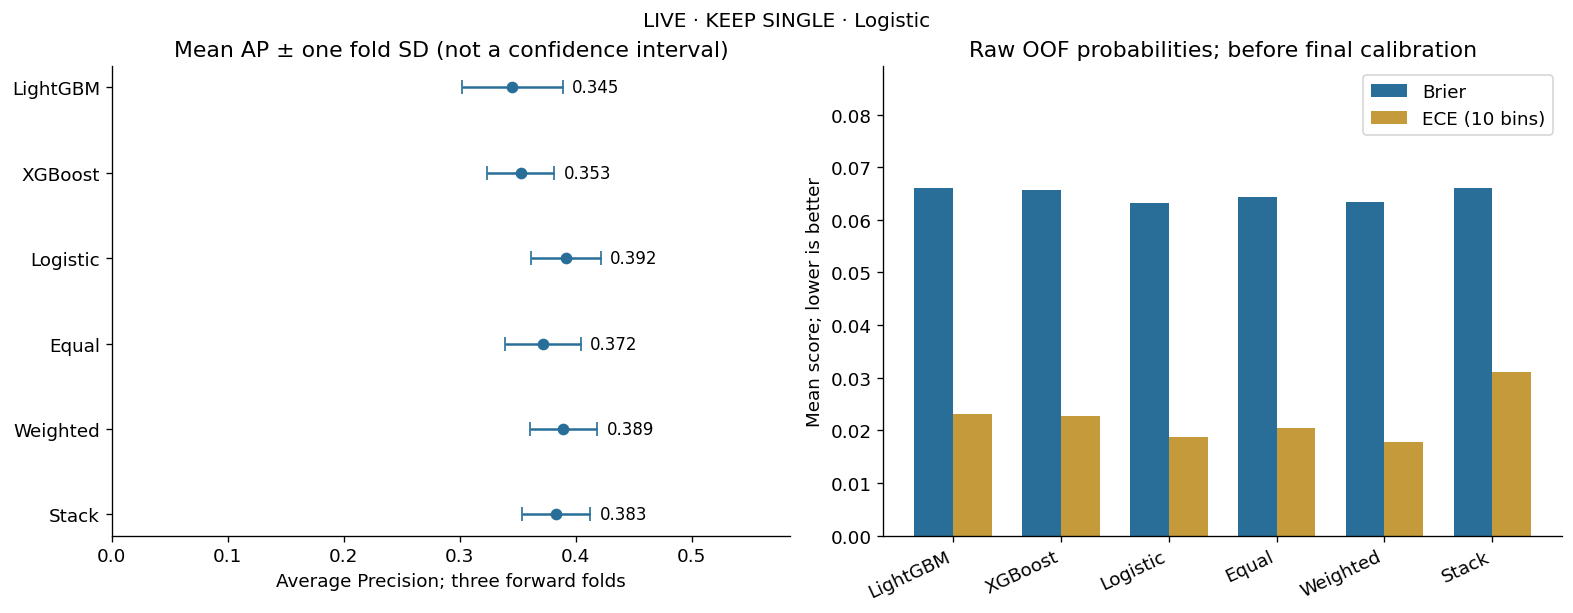

> **How to read this notebook.** This single file compiles the whole Tamweel Lite project: the project README first, then the executed notebook for each gate in order (setup check, Gate 1 to Gate 5) with their saved outputs. It is a record of completed runs. To re-run a lab, use the individual notebook in `notebooks/`.

## Project overview

Tamweel Lite predicts `default_within_90d`, a simulated default event within 90 days of an application, from 22 features available at application time. Identifiers, dates and the target are never model inputs, and the leaky field `days_past_due_60` is removed.

The five gates build the complete workflow: baseline boosting models, honest time- and customer-aware validation, a cost-sensitive threshold under a 12% review capacity, interpretation and calibration, and a final single-model-versus-ensemble decision with an exported model and challenge predictions.

Models compared: LightGBM, XGBoost and Logistic Regression, plus three ensembles (equal average, weighted average and logistic stacking).

## Key results

### Final decision: KEEP SINGLE (Logistic Regression)

Nested forward out-of-fold (OOF) results on three comparison periods (2023Q1, 2023Q3 and 2024Q1):

| Candidate | Mean AP | Fold SD | Brier | ECE | Passes gate |
|---|---:|---:|---:|---:|:---:|
| LightGBM | 0.3455 | 0.0435 | 0.0661 | 0.0231 | No |
| XGBoost | 0.3526 | 0.0290 | 0.0657 | 0.0228 | No |
| **Logistic** | **0.3917** | 0.0298 | 0.0633 | 0.0188 | **Chosen (best single)** |
| Equal average | 0.3717 | 0.0326 | 0.0643 | 0.0204 | No |
| Weighted average | 0.3894 | 0.0291 | 0.0633 | 0.0177 | No |
| Stacking | 0.3831 | 0.0295 | 0.0660 | 0.0311 | No |

The worth-it gate accepts an ensemble only if its AP gain exceeds the best single model's fold standard deviation (0.0298), Brier worsens by no more than 0.005 and ECE by no more than 0.01. No ensemble passed, so the simpler model was kept. The fold SD describes three overlapping periods and is not a confidence interval.

### Frozen review policy

| Item | Result |
|---|---:|
| Loss function | 10 x false negatives + 1 x false positives (educational units) |
| Capacity ceiling | 12% in every period and overall |
| Raw OOF threshold | 0.1689 |
| OOF flags | 245 of 2,155 (11.4%) |
| OOF recall / precision | 46.9% / 34.3% |
| OOF loss | 1,111 units |

### Challenge predictions

| Item | Result |
|---|---:|
| Requests scored | 2,500 |
| Above the transported threshold | 330 |
| Final review flags after the 12% cap | 300 |
| Removed by the cap | 30 |

`decision = 1` is a simulated review flag. `decision = 0` is not a safety guarantee or an approval. Challenge labels are unavailable, so no challenge AP, loss or false-positive rate is claimed.

### Results by gate

| Gate | Focus | Main result |
|---|---|---|
| 1 | Baseline boosting | XGBoost had the highest AP of the three baselines (0.3338; Logistic 0.3258, LightGBM 0.3248) |
| 2 | Honest validation | A leaky control scored AP 0.999. Clean time- and customer-aware validation scored about 0.31 |
| 3 | Cost-sensitive threshold | Threshold 0.658 stayed within the 12% cap (10.4% flagged); 0.5 flagged 19.9% |
| 4 | Explain and calibrate | `bureau_score` was the most important feature (permutation AP drop 0.127). Calibration cut Brier from 0.113 to 0.067 |
| 5 | Final model | Single Logistic Regression kept; calibrated model and 2,500 predictions exported |

The Gate 4 explanations belong to the Gate 4 LightGBM model. They are not automatically attributed to the final Logistic model. Every figure from every gate, with an explanation, is in [Figures and explanations](#figures-and-explanations).

## Technical pipeline

1. Validate the data against the contract (22 features, no leakage fields).
2. Reserve July to September 2024 for calibration only and remove those customers from the fitting pool.
3. Build nested forward OOF predictions: training is earlier than validation with a 90-day label-maturity gap, and validation customers are excluded from training.
4. Compare three single models with equal averaging, weighted averaging and stacking. Weights and the stacker learn from inner OOF only.
5. Apply the worth-it gate and keep the simplest passing option, otherwise the best single model.
6. Search every distinct OOF score for the minimum 10 x FN + FP loss under the 12% capacity ceiling.
7. Refit the chosen procedure, learn one sigmoid mapping on the calibration period, and transport the threshold.
8. Score the 2,500 challenge requests, then apply the capacity cap once to the full batch.
9. Export the model in JSON/native format (no pickle), a model card, and a hash-verified project bundle.

See the [Technical Report](docs/TECHNICAL_REPORT.md) and the [Requirements Checklist](docs/REQUIREMENTS_CHECKLIST.md) for the detailed evidence map.

## Figures and explanations

All 19 figures produced across the five gates, in order. Each one is followed by what it shows and what to take from it. All data are synthetic.

### Gate 1: Baseline boosting

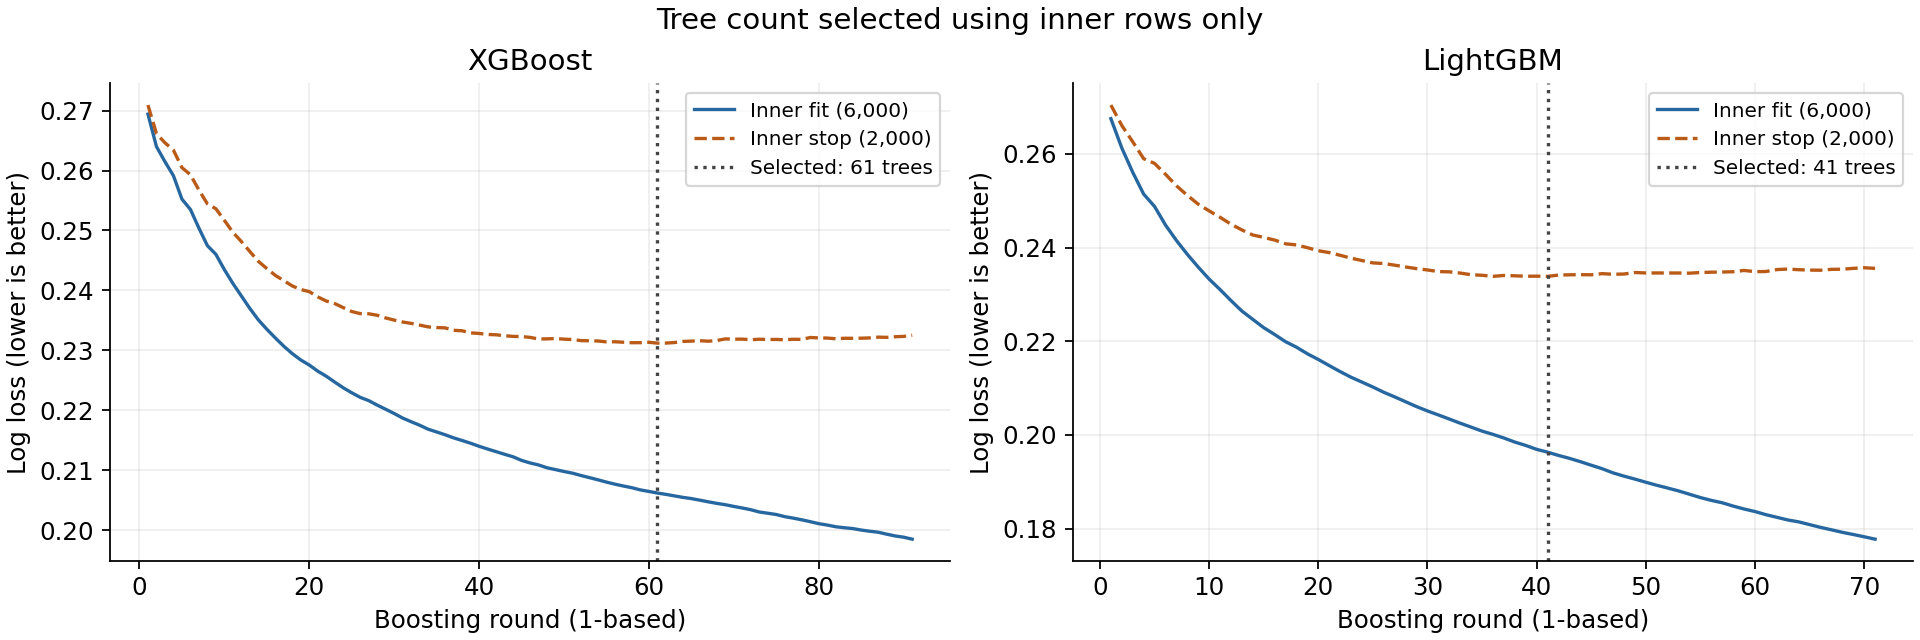

**Learning curves (XGBoost and LightGBM).** Each panel plots log loss (lower is better) against the number of boosting rounds. The solid line is the fit on 6,000 inner rows and the dashed line is a separate 2,000-row stopping set. The fit line keeps falling, but the stopping line flattens, which means extra trees start memorising instead of learning. The dotted vertical line marks the tree count chosen from the stopping set only: 61 trees for XGBoost and 41 for LightGBM. Choosing the tree count on rows the model was not fitted on keeps the later comparison honest.

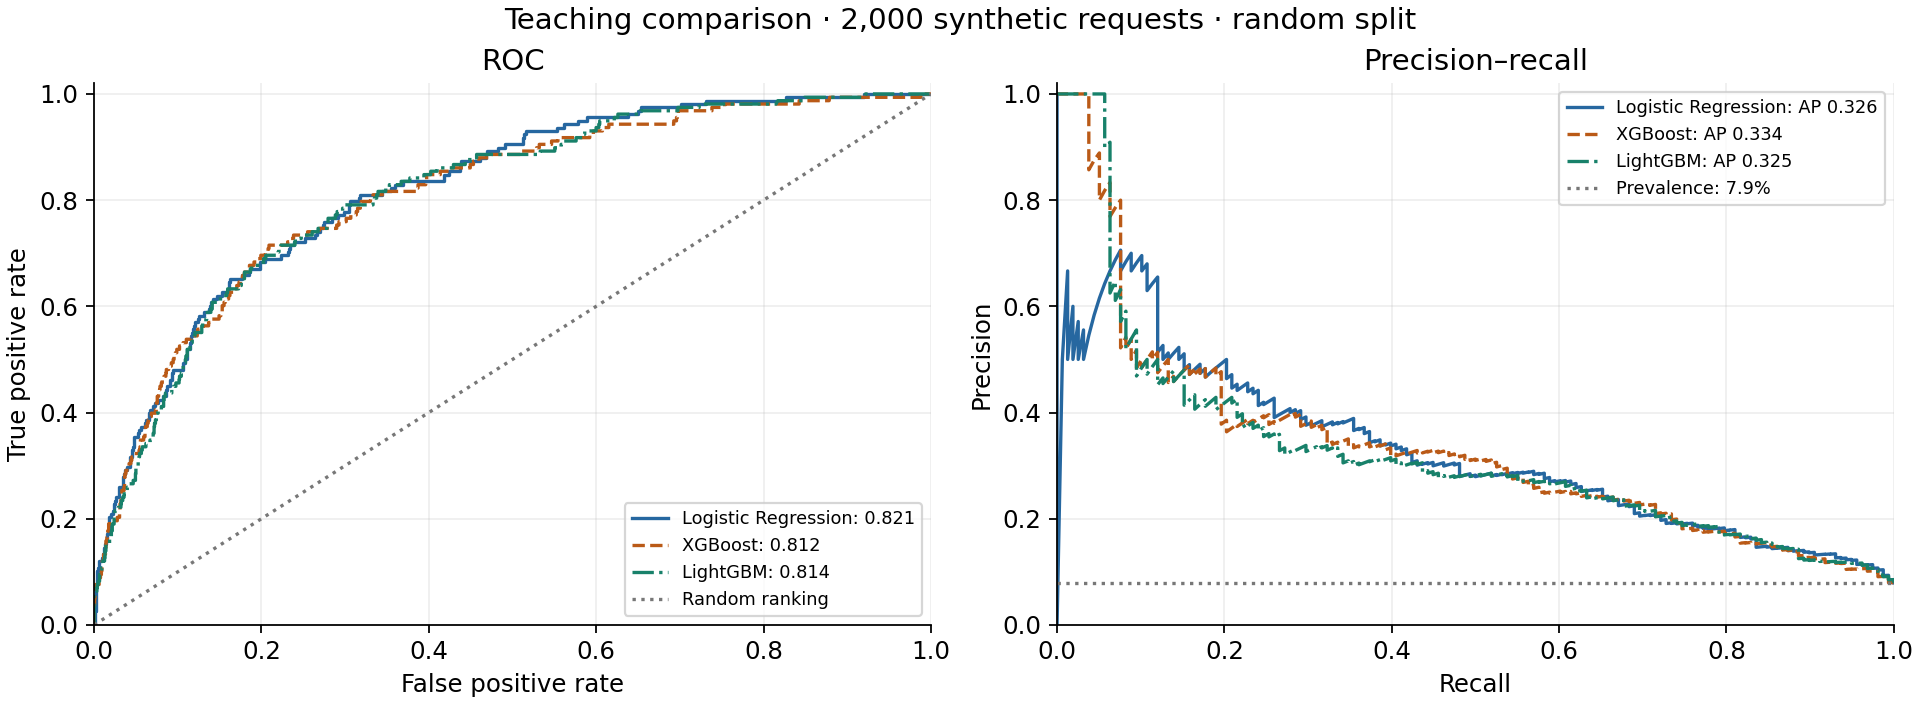

**ROC and precision-recall curves (three baselines).** On a random split of 2,000 synthetic requests, the three models are almost indistinguishable on ROC (AUC: Logistic 0.821, XGBoost 0.812, LightGBM 0.814). Because defaults are rare (7.9% prevalence, the dotted line on the right), average precision is the more informative metric: XGBoost 0.334, Logistic 0.326, LightGBM 0.325. XGBoost was picked first because it had the highest AP, but the gaps are small. This is a teaching comparison on a random split, not an honest time-based test.

### Gate 2: Honest validation

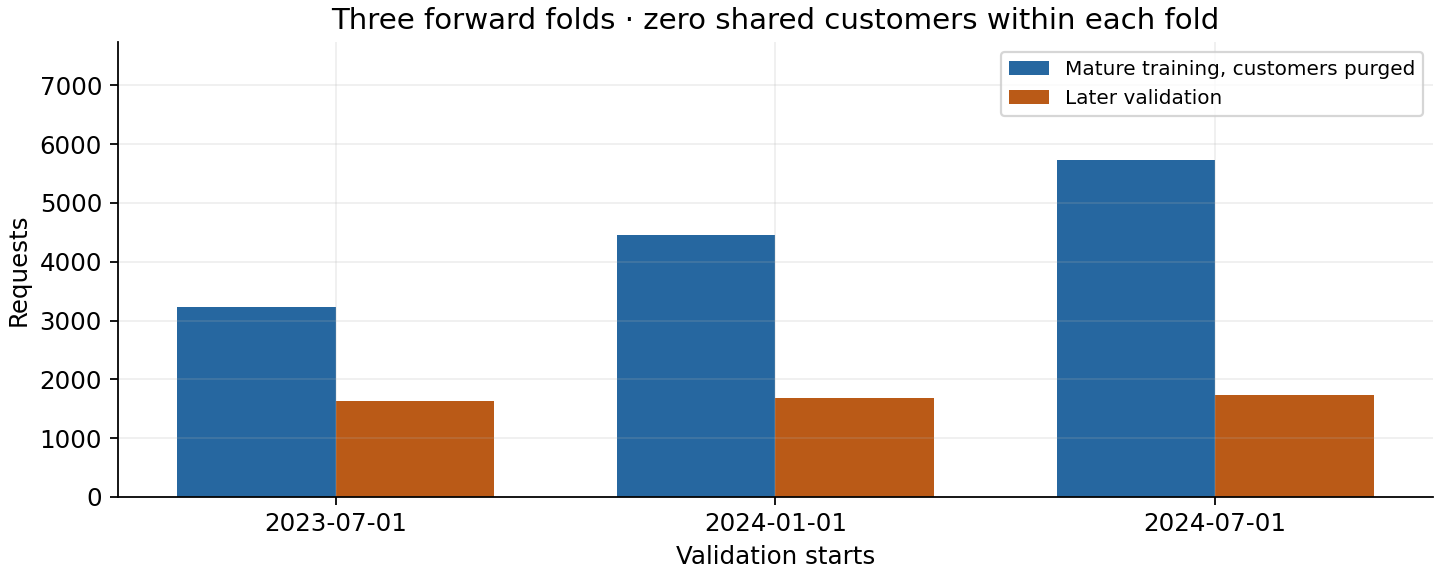

**Forward fold sizes.** Three folds validate on later periods (starting 2023-07-01, 2024-01-01 and 2024-07-01). Blue bars are the training rows, which only include applications whose 90-day outcome had already matured and from which validation customers were purged (about 3,200, 4,450 and 5,700 rows). Orange bars are the later validation rows (about 1,600 to 1,700 each). No customer appears on both sides of any fold. Training data grows over time, as it would in real use.

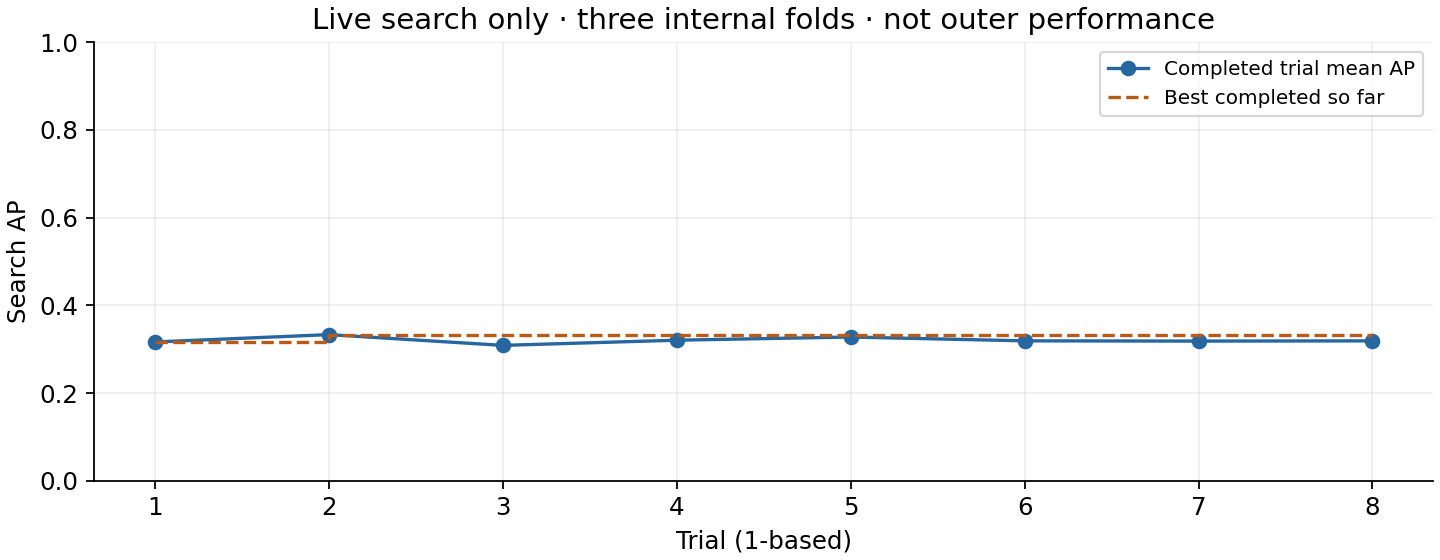

**Hyperparameter search.** Eight Optuna trials, each scored by mean average precision on three internal folds. The score barely moves (about 0.31 to 0.33), and the best trial (trial 2, about 0.333) stays the best. Tuning found almost nothing, so the search space was flat for this data. These are internal search scores, not outer performance.

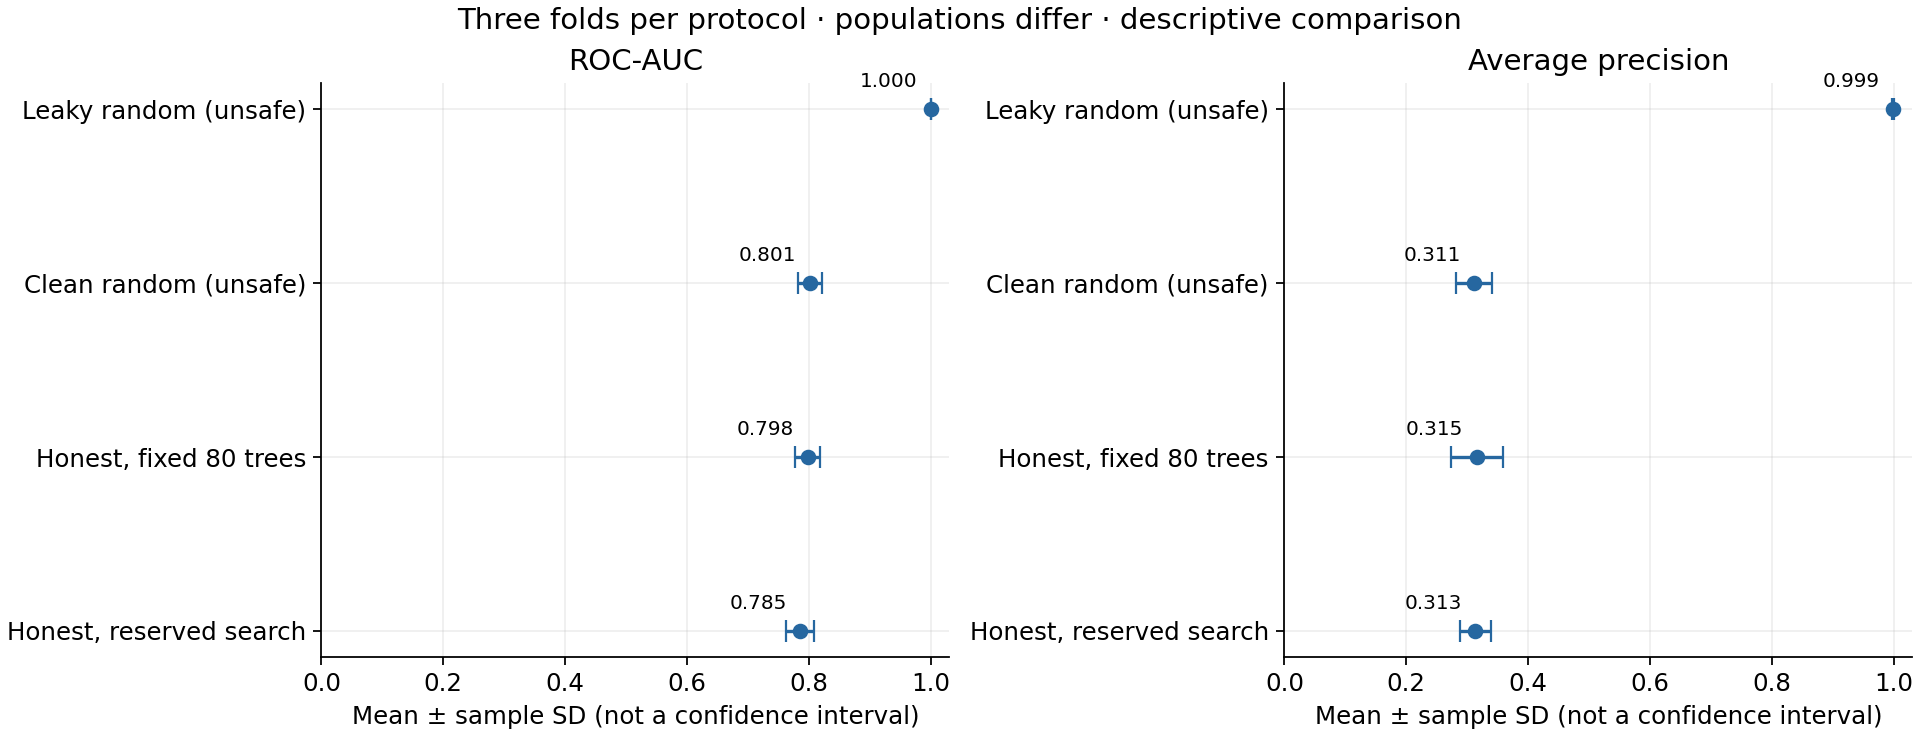

**Leaky versus honest validation.** Four protocols, with mean and sample standard deviation over three folds. The leaky random protocol, which sees post-application information, scores ROC-AUC 1.000 and AP 0.999, which is far too good to be real. Once the future fields are removed and time and customers are respected, AP falls to about 0.31 (clean random 0.311, honest fixed 0.315, honest tuned 0.313). The gap is what leakage looks like. The error bars are not confidence intervals, and the populations differ between protocols.

### Gate 3: Cost-sensitive decision

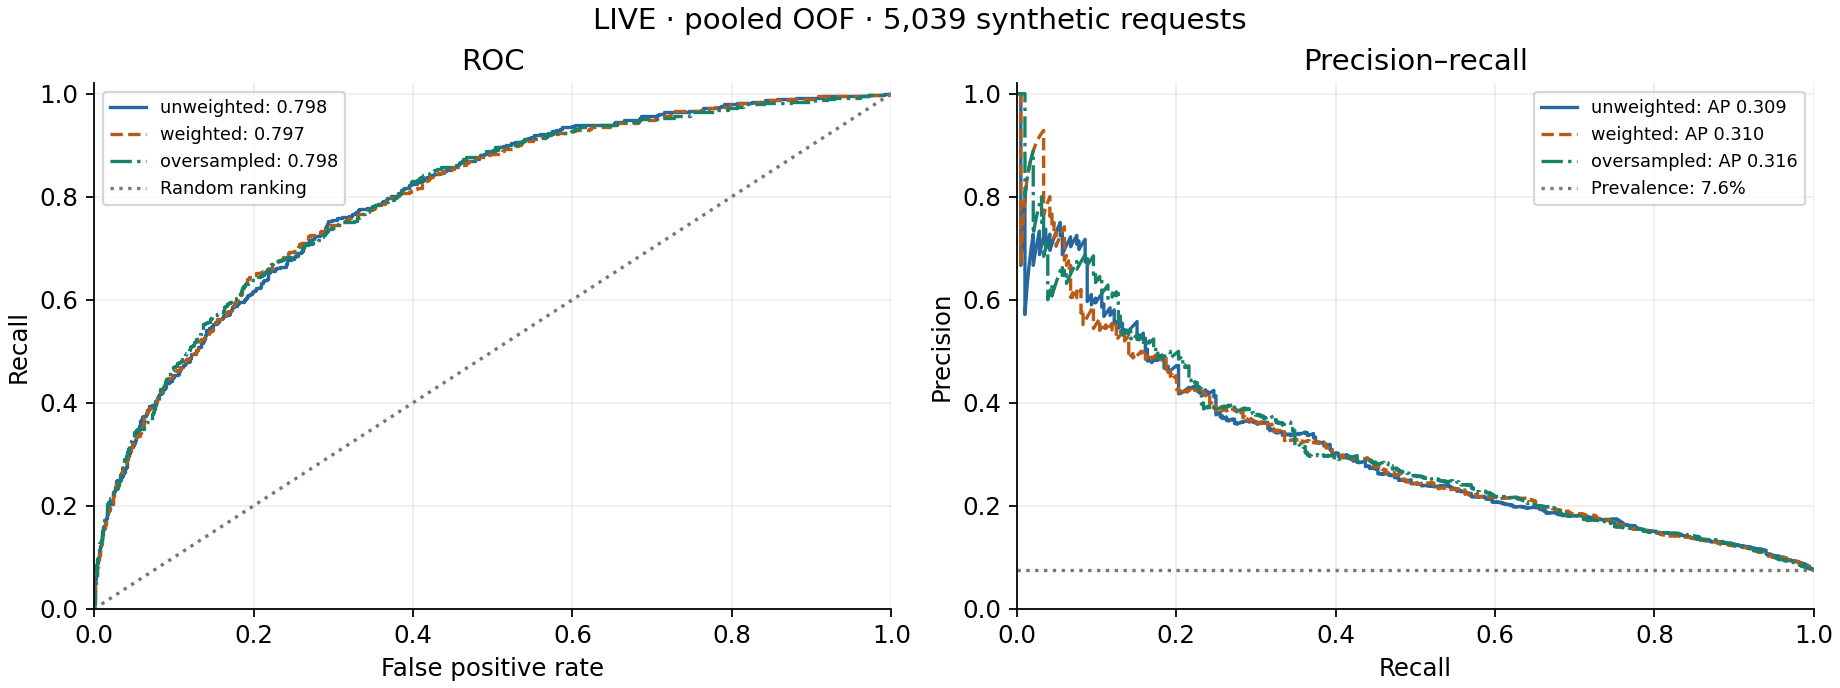

**Imbalance strategies (pooled OOF).** Unweighted, class-weighted and oversampled models on 5,039 out-of-fold requests. ROC-AUC is 0.798, 0.797 and 0.798, and AP is 0.309, 0.310 and 0.316 against a 7.6% base rate. Handling imbalance this way barely changes how well requests are ranked. The real lever is where the decision threshold is placed.

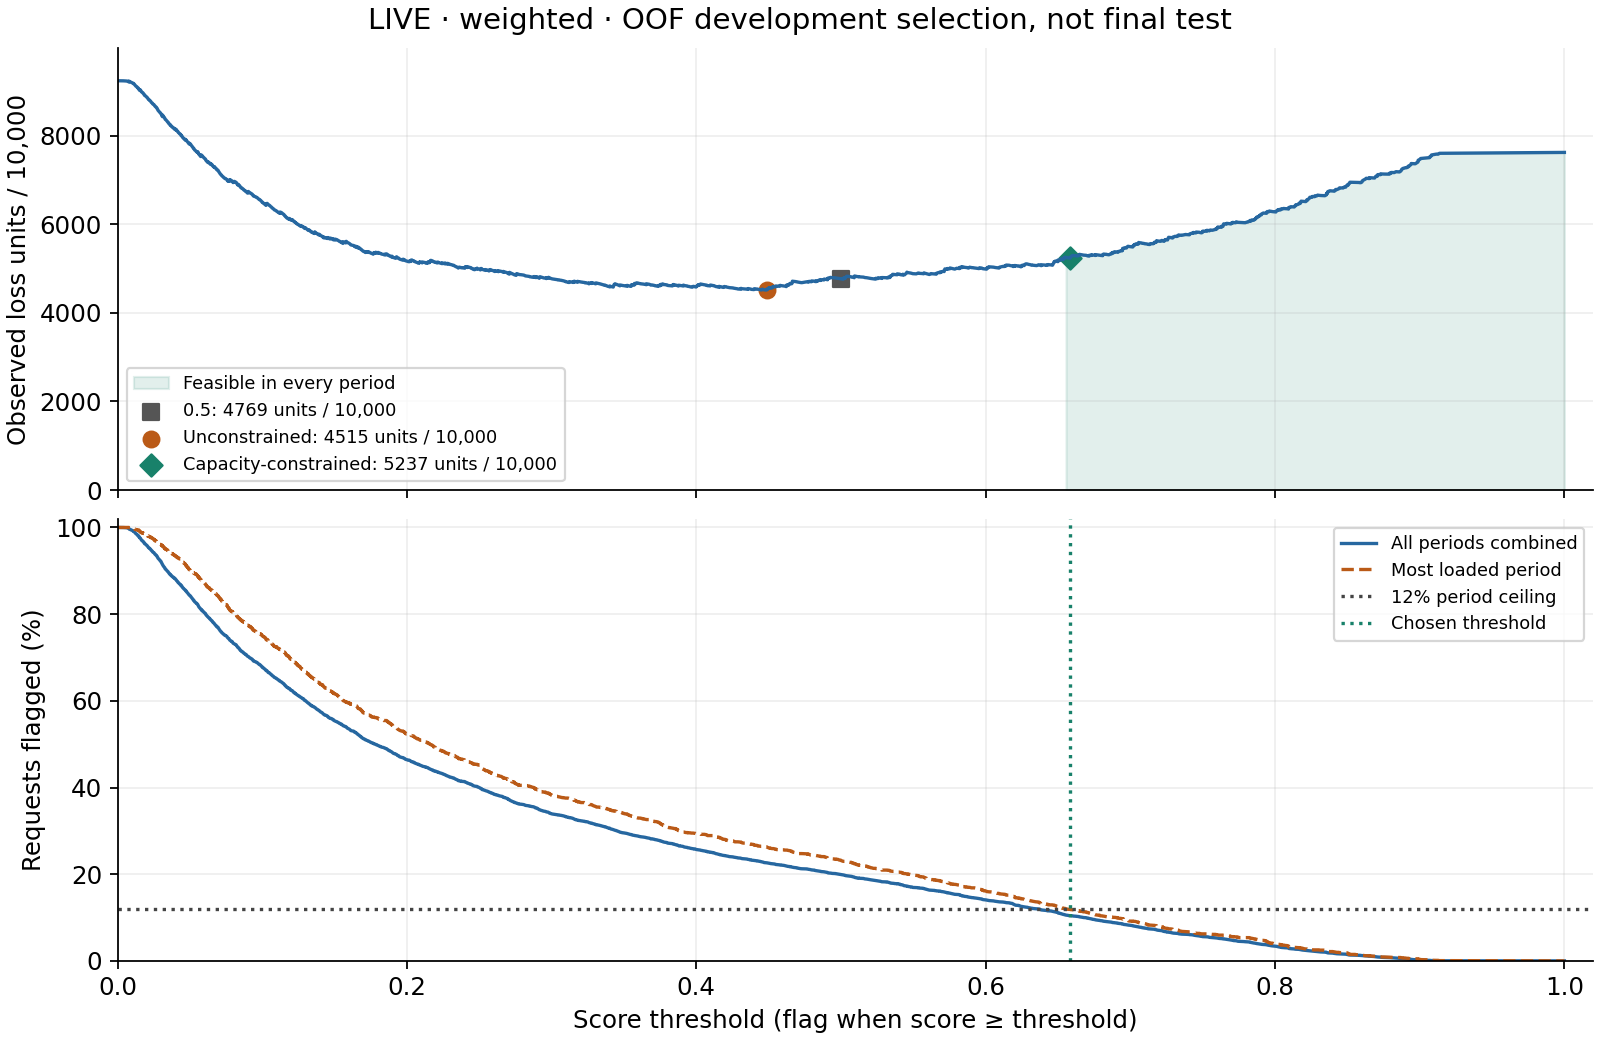

**Cost curve and review capacity.** The top panel shows observed loss per 10,000 requests (10 x missed defaults + 1 x false alarms) for every threshold. The lowest loss with no limit is 4,515 units (threshold about 0.449). The default 0.5 costs 4,769. The shaded region is where every period stays within the 12% review capacity, and the best threshold there is 0.658 at 5,237 units. The bottom panel shows why: the percentage flagged only falls below the 12% ceiling (dotted line) at about that threshold. The extra loss is the price of respecting capacity.

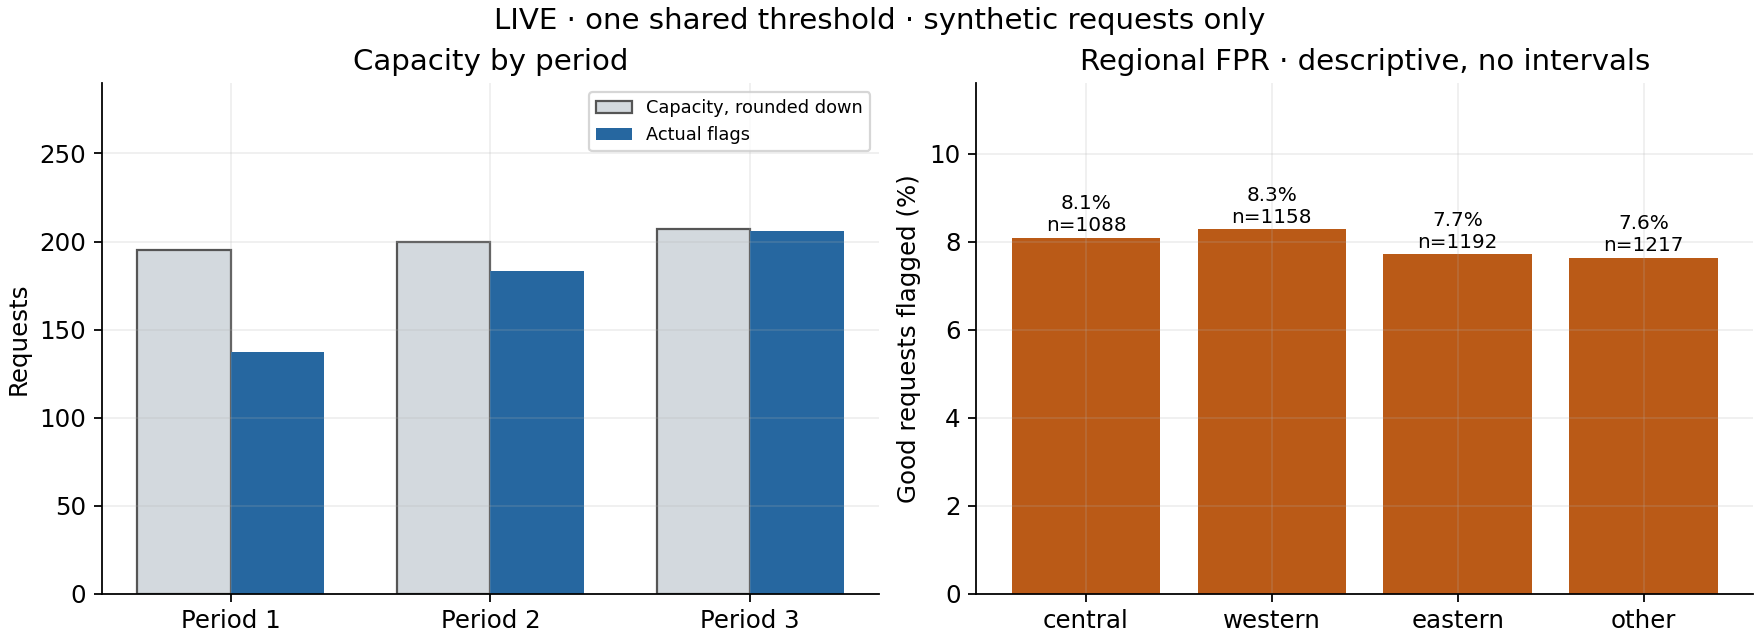

**Capacity by period and regional diagnostic.** On the left, actual flags (blue) against the rounded-down capacity (grey) for each validation period: about 137 of 195, 183 of 200 and 206 of 207, so every period is within its limit. On the right, the false-positive rate for each region is similar (central 8.1%, western 8.3%, eastern 7.7%, other 7.6%), with the number of non-default requests labelled. The roughly 0.65-point gap is descriptive. It has no confidence interval and is not a fairness certification.

### Gate 4: Explain and calibrate

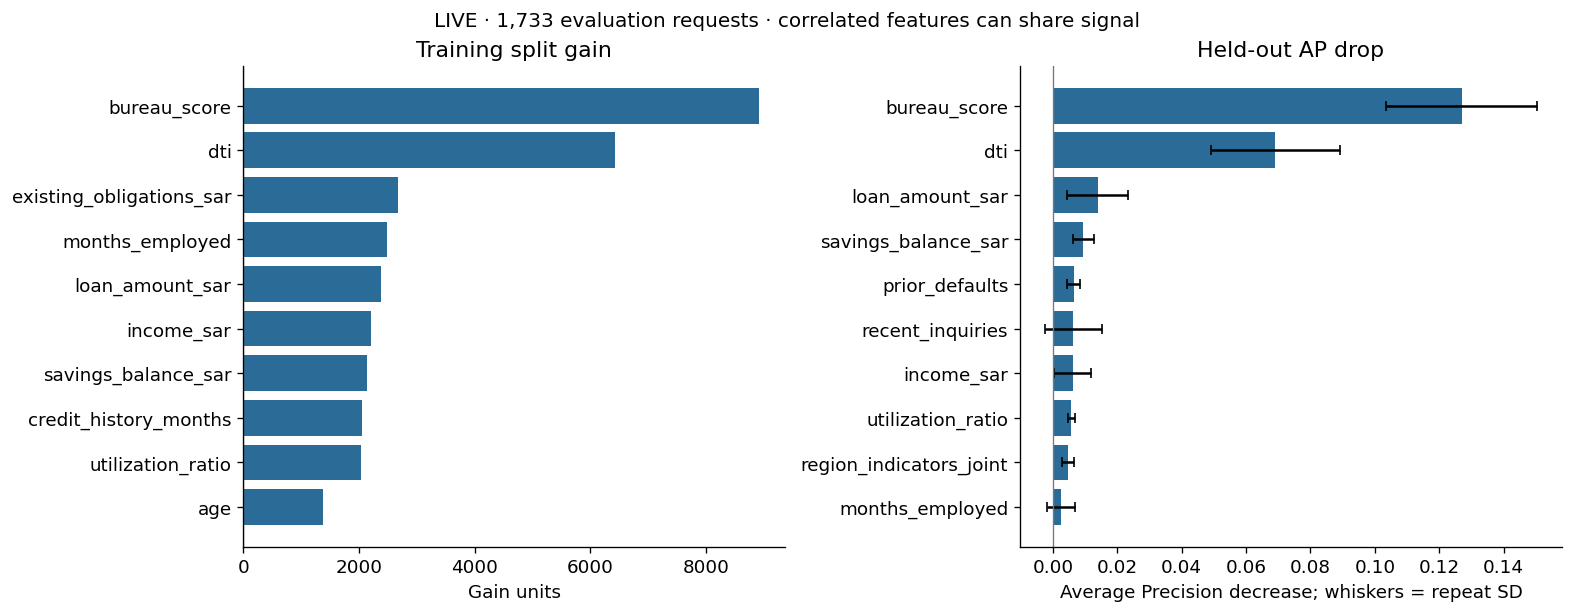

**Feature importance.** The left panel is how much each feature was used for splitting during training (gain). The right panel is how much average precision drops on 1,733 held-out requests when a feature is shuffled, with whiskers showing the spread over repeats. Both views put `bureau_score` first and `dti` second. Shuffling `bureau_score` costs about 0.127 AP and `dti` about 0.069, while the rest cost under 0.02. Some whiskers cross zero, and correlated features can share signal, so small differences are not meaningful. Importance describes the model and does not prove causality.

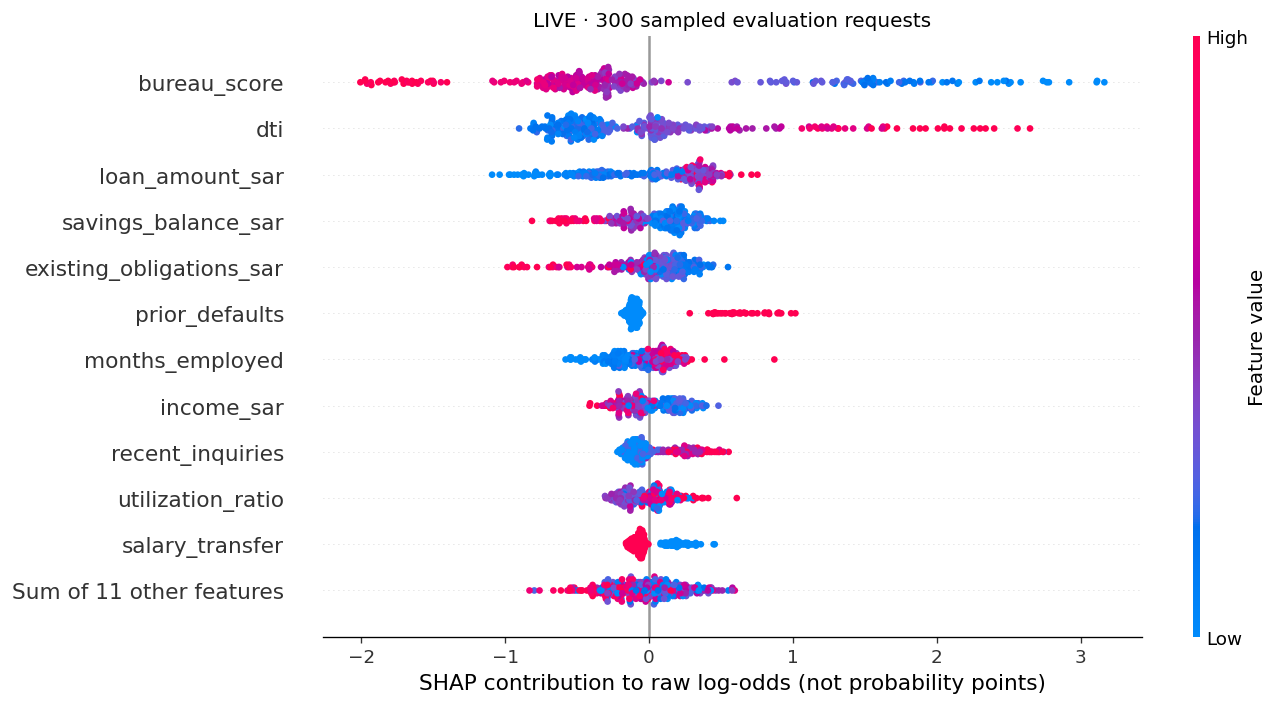

**SHAP summary (beeswarm).** Each dot is one of 300 sampled requests, placed by how much that feature pushed the model's raw score (log-odds, not probability points) and coloured by the feature's value. For `bureau_score`, low values (blue) push risk up, by as much as about +3, and high values (red) push it down. For `dti`, high values (red) raise risk. A non-zero `prior_defaults` (red) raises risk, and more savings lower it. This shows how the model uses the data, not what would happen if a person's feature changed.

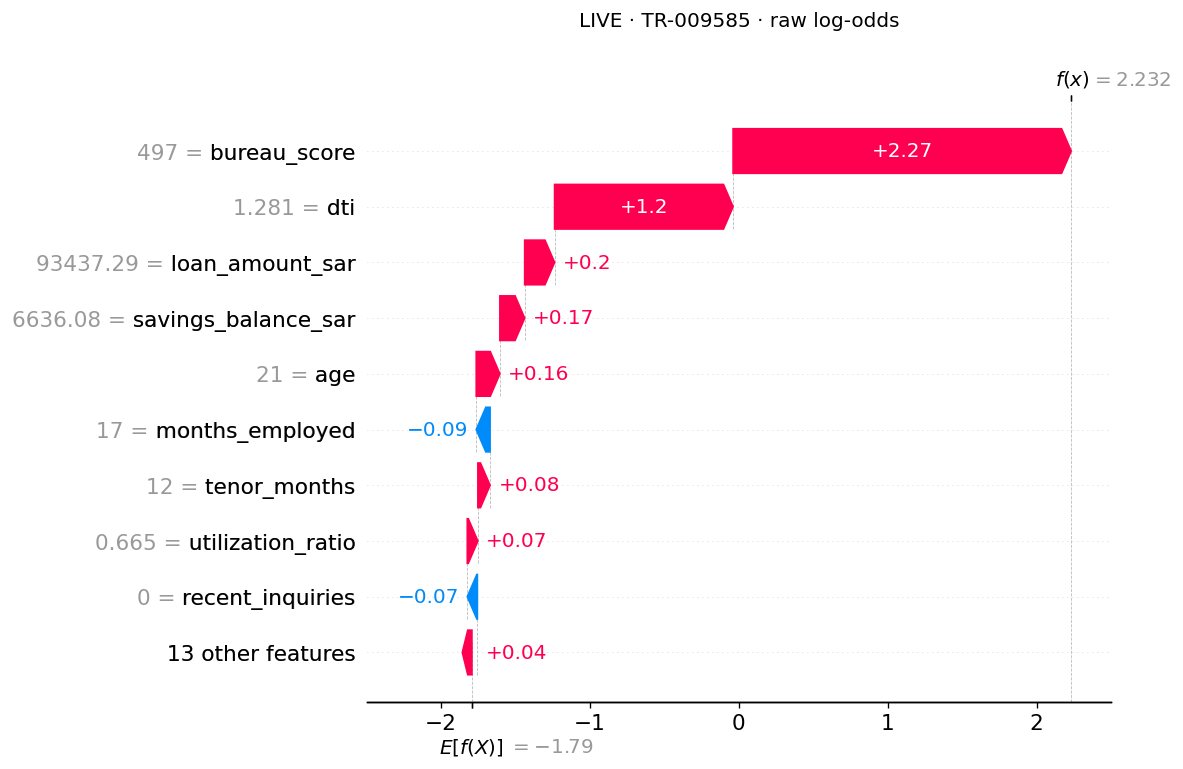

**SHAP waterfall for one request.** A local explanation for request TR-009585, the highest-scoring request in the SHAP sample (chosen without looking at its outcome). The score starts at the model's average, -1.79 log-odds, and each bar adds or subtracts. `bureau_score` = 497 adds +2.27 and `dti` = 1.28 adds +1.2, reaching 2.23. That is a raw probability of 0.903, which calibration reduces to 0.480. It explains this one request only. The global picture is in the beeswarm.

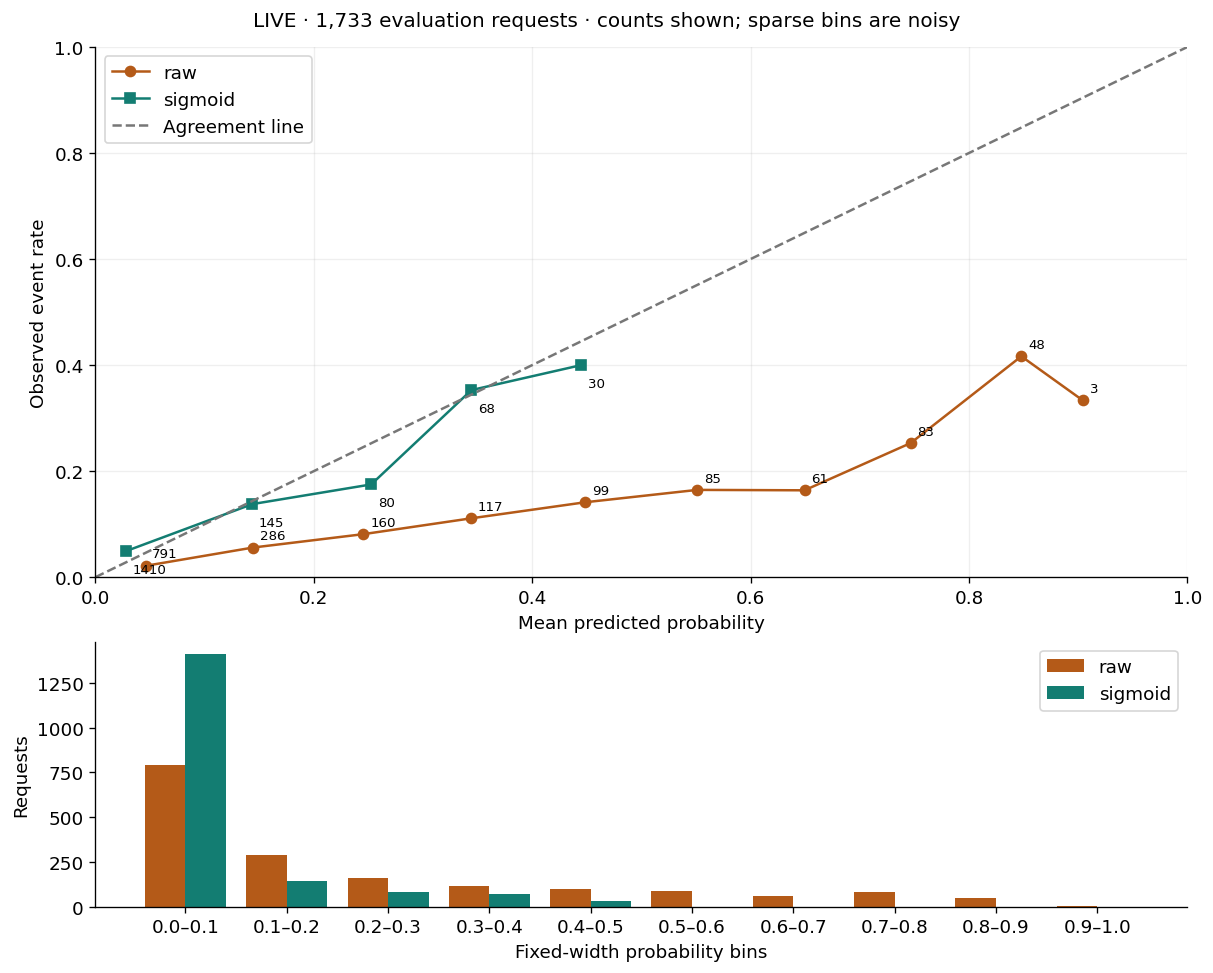

**Calibration (reliability diagram).** The top panel compares predicted probability with the observed default rate on 1,733 evaluation requests. The raw scores (orange) sit well below the diagonal, so the model overstates risk (for example, requests scored around 0.55 defaulted about 16% of the time). The sigmoid mapping (teal) moves the curve close to the diagonal. The bottom panel shows how many requests fall in each bin, and the sigmoid pushes most of them into the lowest bin. Sparse bins (a few dozen requests) are noisy. Brier improved from 0.113 to 0.067 and ECE from 0.147 to 0.022, while ranking quality (AP, AUC) stayed identical.

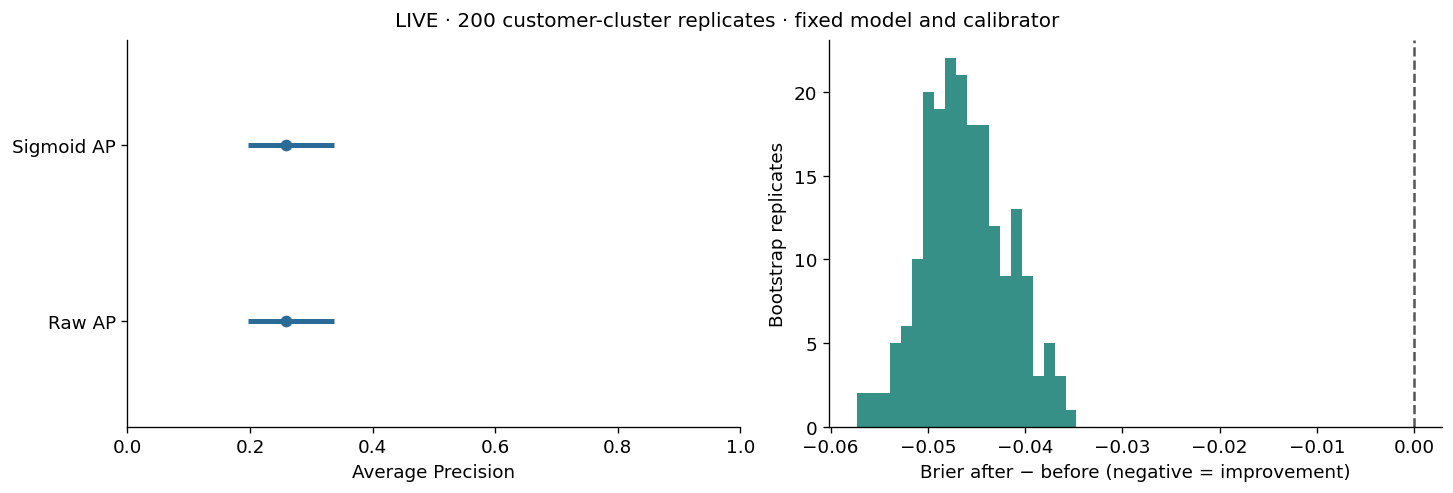

**Stability of the result.** 200 bootstrap replicates, resampling whole customers, with the model and calibrator held fixed. On the left, average precision is the same before and after calibration (about 0.26, with a wide interval of roughly 0.20 to 0.34) because calibration does not change the ranking. On the right, the change in Brier score is negative in every replicate (about -0.058 to -0.035) and never reaches zero, so the improvement is consistent. This does not include the uncertainty from training the model, fitting the calibrator, or future drift.

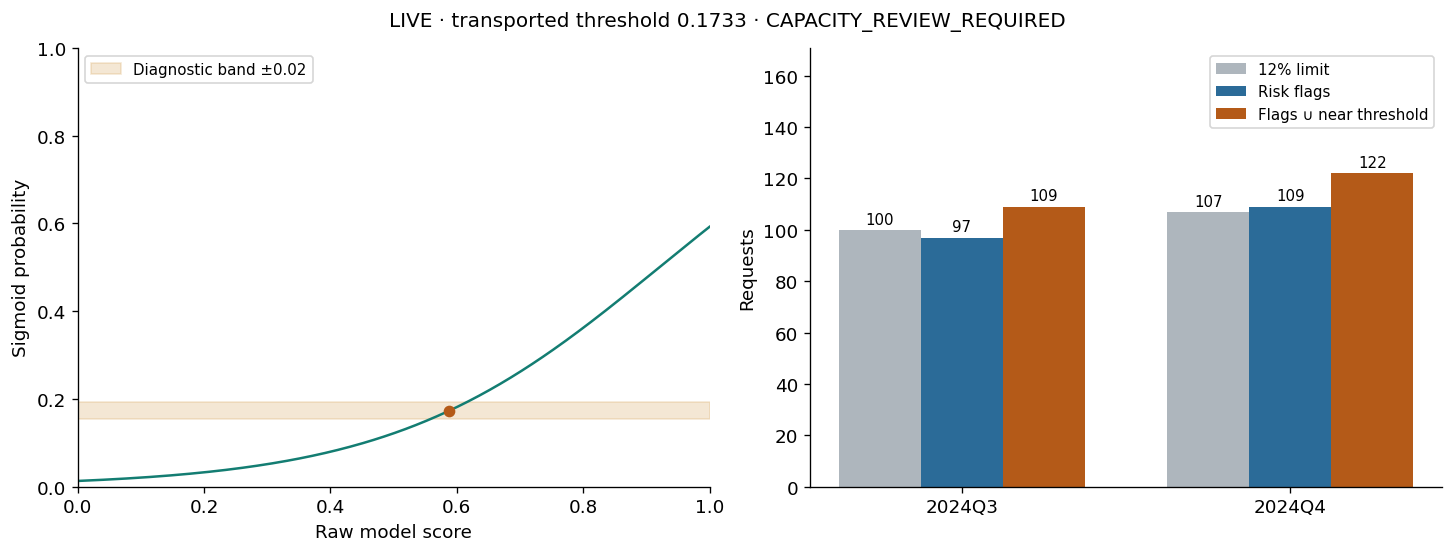

**Review zone and capacity check.** The left panel shows how the raw score maps to a calibrated probability. The chosen raw threshold of 0.588 corresponds to 0.173 after calibration, with a diagnostic band of plus or minus 0.02 around it. The right panel compares the 12% limit with the flags on the two evaluation quarters. In 2024Q3 the limit is 100, risk flags are 97, and flags plus near-threshold requests are 109. In 2024Q4 the limit is 107 and risk flags are 109 (122 with the near-threshold group). The status is `CAPACITY_REVIEW_REQUIRED`, and the threshold was not retuned on evaluation data.

### Gate 5: Final model

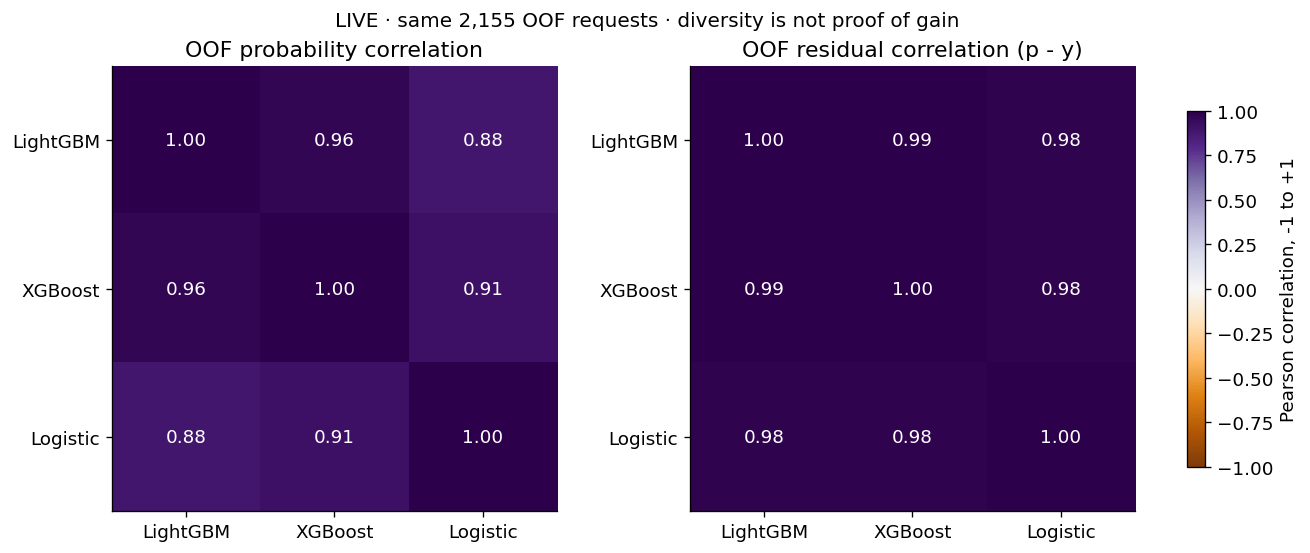

**Model diversity.** The left heatmap shows how correlated the three models' predicted probabilities are on the same 2,155 OOF requests (0.88 to 0.96). The right heatmap shows the residuals (prediction minus outcome), which are even more correlated (0.98 to 0.99). The models make largely the same mistakes, so combining them has little room to help. Low correlation alone would not prove a gain either, so the next figure measures it directly.

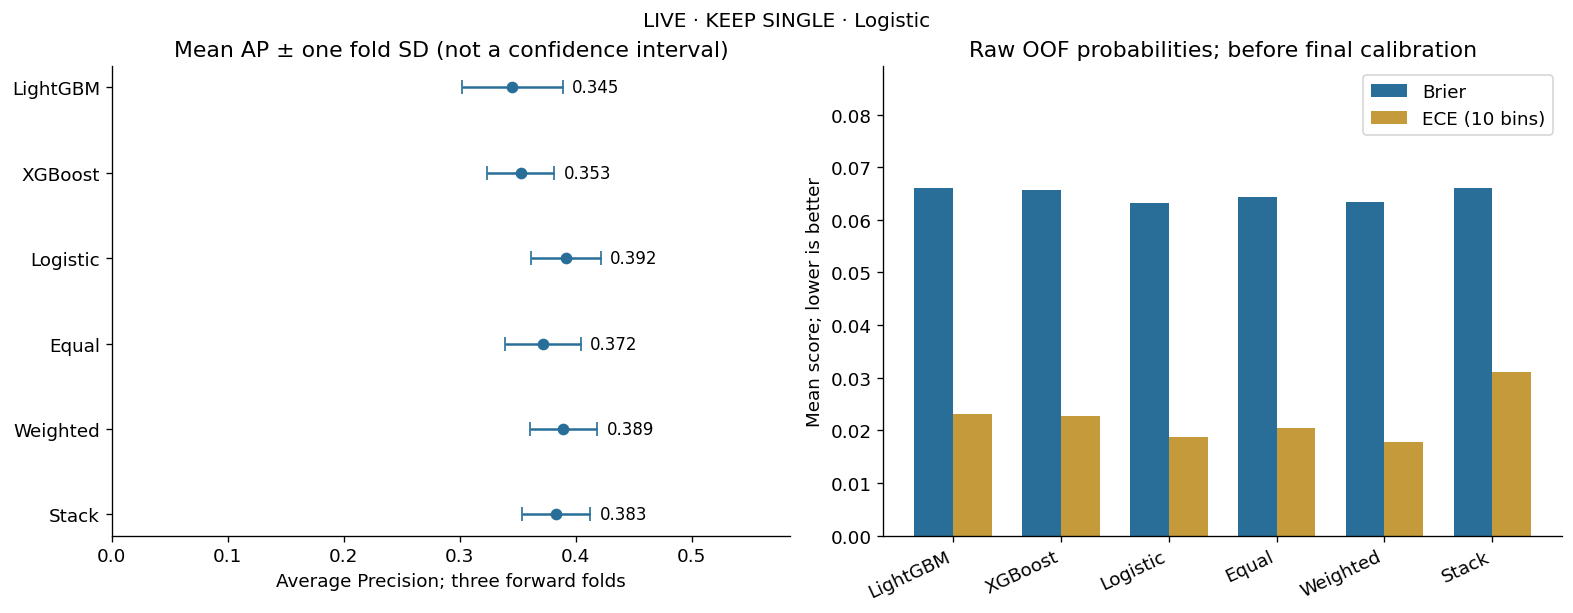

**Single models versus ensembles.** The left panel gives mean AP over the three forward folds with one fold standard deviation (not a confidence interval): Logistic 0.392, weighted average 0.389, stacking 0.383, equal average 0.372, XGBoost 0.353, LightGBM 0.345. The right panel shows raw Brier and ECE, where Logistic is among the best on both and stacking has the worst ECE (0.031). No ensemble beat the best single model by more than its fold standard deviation (0.030), so the decision is KEEP SINGLE with Logistic Regression.

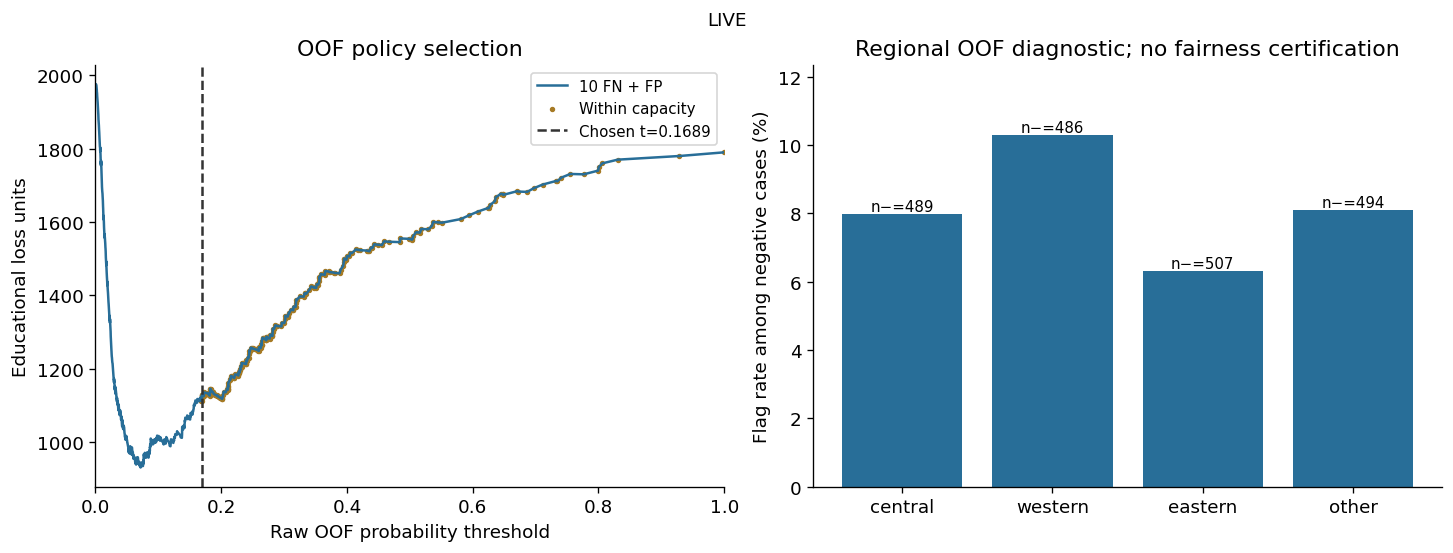

**Final policy and regions.** The left panel is the educational loss (10 x FN + FP) for every raw OOF threshold of the chosen model. The loss is lowest near 0.07, but those thresholds would flag far more than 12% of requests. The dashed line at 0.1689 marks the lowest-loss threshold that stays within capacity (1,111 units). The right panel shows the flag rate among non-default requests by region: central 8.0%, western 10.3%, eastern 6.3%, other 8.1%. The gap of about 3.98 points is descriptive and needs monitoring. It is not a fairness certification.

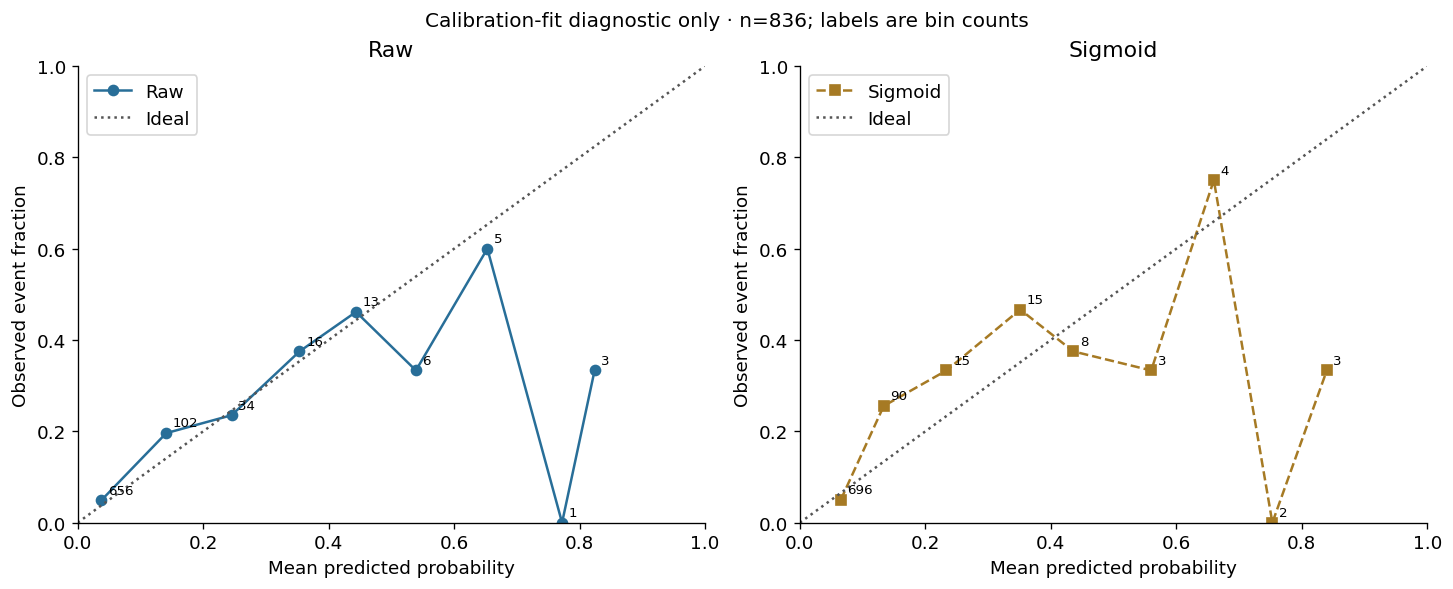

**Calibration fit diagnostic.** The reserved July to September 2024 period (836 rows, 78 defaults) is shown before and after the sigmoid mapping, with the number of requests in each bin. Both curves follow the diagonal at low probabilities, where most requests are, and become erratic above about 0.5 because those bins hold only a handful of requests. On these rows Brier moved from 0.0765 to 0.0781 and ECE from 0.0211 to 0.0349, so the sigmoid did not help here. This is a fit diagnostic on the same rows used to learn the mapping, not an independent test.

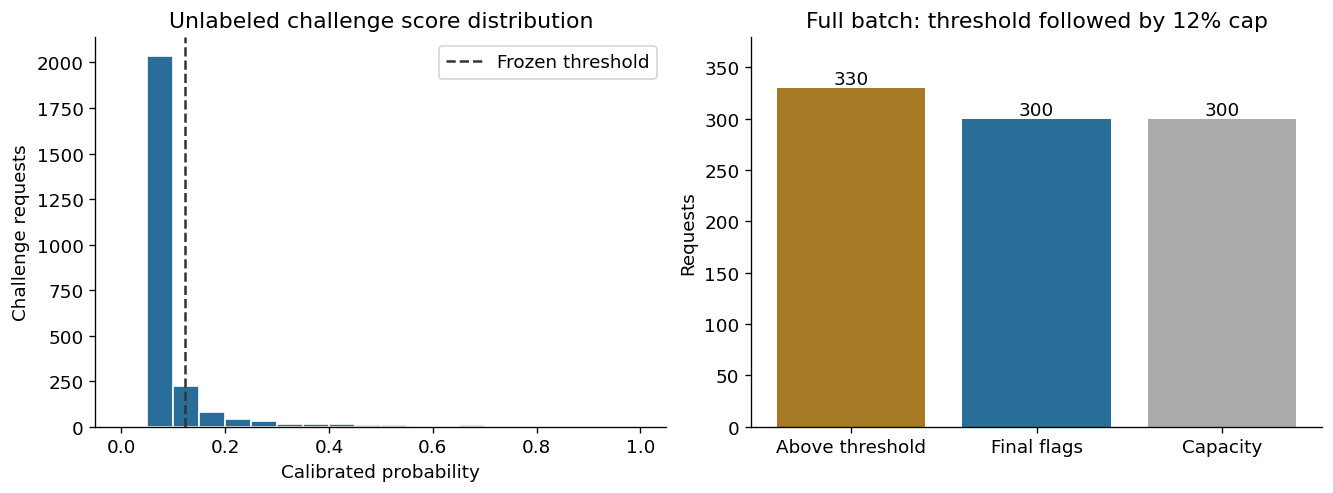

**Challenge predictions and capacity.** On the left, the calibrated probabilities of the 2,500 unlabeled challenge requests. Most are below 0.1, and the dashed line is the frozen threshold (0.1223). On the right, 330 requests exceed the threshold, but the 12% capacity is 300, so the highest-probability 300 are flagged and 30 are removed. The cap was applied once to the whole batch. No challenge performance is claimed because the labels are not available.

## Repository structure

```text
Tamweel-Lite/
├── README.md
├── Tamweel_Lite_Final_Project.ipynb   # README + all gate notebooks in one file
├── PROJECT_README.md
├── requirements.txt
├── requirements-colab.txt
├── requirements-check.txt
├── constraints.txt
├── .github/workflows/
│   └── final_project.yml     # Final Project Check (manual run)
├── notebooks/
│   ├── 00_readiness_check.ipynb
│   ├── 01_baseline_boosting.ipynb
│   ├── 02_validation_tuning.ipynb
│   ├── 03_cost_sensitive_decision.ipynb
│   ├── 04_explain_calibrate.ipynb
│   ├── 05_final_model.ipynb
│   └── 99_final_submission_check.ipynb
├── config/
│   ├── environment.json
│   ├── final_policy.json
│   └── requirements.txt
├── data/
│   ├── data_contract.json
│   ├── data_manifest.json
│   ├── tamweel_train.csv
│   └── tamweel_challenge.csv
├── scripts/                  # course support code, inference, replay, rebuild and final check
├── tamweel/                  # command-line inference wrapper
├── artifacts/                # final tables, figures, policy, metrics, provenance
│   └── final_model/          # exported model and manifest
├── evidence/                 # outputs from the earlier gates, one folder per gate
├── docs/
│   ├── TECHNICAL_REPORT.md
│   └── REQUIREMENTS_CHECKLIST.md
├── reports/
│   ├── MODEL_CARD.md
│   ├── ENSEMBLE_DECISION.md
│   ├── results_summary.json
│   └── gate*_*.png           # all 19 figures shown in this README
├── submission/
│   ├── submission.csv        # application_id, probability, decision
│   └── submission_manifest.json
└── presentation/             # course templates
```

## Quick start

### 1. Clone and install

```bash
git clone https://github.com/Jumanah-A/SDA-DSC-211.git
cd SDA-DSC-211
python -m venv .venv
```

Activate the environment, then install the dependencies:

```bash
pip install -r requirements.txt
```

### 2. Reproduce the saved predictions (no refitting)

```bash
python scripts/replay_final.py
```

This reloads the exported model and checks that every probability and decision matches `submission/submission.csv`.

### 3. Rebuild from data

```bash
python scripts/rebuild_final.py
```

This retrains, reselects and recalibrates from the data and compares the result with the saved submission.

### 4. Predict on new feature rows

```bash
python tamweel/inference.py --input data/tamweel_challenge.csv --output predictions.csv
```

The command returns application IDs and calibrated probabilities only. Apply the frozen threshold and the 12% capacity cap to the complete batch afterwards, as described in `artifacts/final_policy.json`.

### 5. Read the executed notebooks

Open the files in `notebooks/`, for example in Google Colab. They contain the saved outputs of the completed runs.

## Dataset and model

- Dataset: synthetic `tamweel-lite-1.0` (10,000 labeled training rows and 2,500 unlabeled challenge requests)
- Fit and selection pool: 6,576 rows, 3,931 customers, 537 positives (2022-01-01 to 2024-04-01)
- Calibration period: 836 rows, 78 positives (2024-07-01 to 2024-09-30)
- Final model: Logistic Regression with a sigmoid calibration mapping
- Seed: 211. Packages are pinned in `requirements.txt`.

## Interpretation and limitations

- The data are synthetic and do not represent real people or regions. The model is for training use only.
- A review flag is a simulated signal. A zero is not a safety guarantee or a financing approval.
- OOF results are used for development and selection. They are not an untouched final test, and three overlapping forward periods are not a significance test.
- The calibration figures are diagnostics on the rows used to fit the calibrator, not independent performance.
- Transporting a threshold from OOF models to a refitted model can change flag volume, which is why capacity is applied once to the whole batch.
- Loss units are fictional teaching units, not riyals, and review cost is not included.
- No challenge labels are available, so no challenge performance is claimed.
- The regional diagnostic is descriptive and is not a fairness certification.
- See `reports/MODEL_CARD.md` for the full model card, including the monitoring plan.

## Training-program attribution

This project was completed for the SDA-DSC-211 course lab series (Tamweel Lite), using the released course data and support code. Course support files are included unchanged under `scripts/`, `tamweel/` and `presentation/`.

## Daily answers | الإجابات اليومية

### Day 1 | اليوم الأول

<img width="822" height="113" alt="Screenshot 2026-11-24 at 10 34 23 AM" src="https://github.com/user-attachments/assets/5c574ef9-c5fe-422f-b88b-c09610745ff1" />


Daily question · Model comparison

**Which model did you select initially, and what is the strongest result supporting your choice?**

Initially I chose the XGBoost model, based on the table above. The XGBoost model has the highest Average Precision of all 3 models of (0.3338). Since default events don't occur often, I chose the average precision as my metric of choice to compare how the well models perform and then select the best one that would identify defaults.


### Day 2 | اليوم الثاني


Daily question · Honest validation


<img width="490" height="656" alt="Screenshot 2026-11-24 at 1 53 08 PM" src="https://github.com/user-attachments/assets/fdc4d9d5-e0f5-4eb2-8b1b-d6de914aa642" />


**What leakage risk did you identify, and how did the validation design prevent it?**

I identified a target leakage risk "days_past_due_60", this field is only available after the application (as it happens in the future) and the model shouldn't be able to access it while training. The validation design to prevent it was to remove the "days_past_due_60" field before training the model.


### Day 3 | اليوم الثالث


Daily question · Decision threshold

**Why is a fixed threshold of 0.5 not always suitable for this review policy?**

I didn’t use 0.5 because it would flag 19.9% of requests, but the review team can handle only 12%. I chose a threshold that keeps the number of flags within capacity while balancing missed defaults and false alarms.

### Day 4 | اليوم الرابع


Daily question · Interpretation and calibration

**Which feature was most important in your explanation, and why does that not prove causality?**

bureau_score was the most important feature because the model relied on it most when making predictions. That doesn’t prove it causes defaults. SHAP shows how the model used the data; it doesn’t tell us what would happen if someone’s score changed.

### Day 5 | اليوم الخامس


Daily question · Final model

**Why did you choose the single model or the ensemble for the final project?**

I chose Logistic Regression because it had the best mean AP across the three forward folds: 0.392. The weighted average scored 0.389, stacking 0.383, and equal averaging 0.372. None of the ensembles passed the worth-it check, so the extra complexity wasn’t worth it.

---
# Setup: readiness check

_Executed notebook `notebooks/00_readiness_check.ipynb`._

<a href="https://colab.research.google.com/github/Jumanah-A/SDA-DSC-211/blob/master/Copy_of_00_readiness_check.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table>
<tr>
<td width="50%" valign="top" dir="ltr">
<h1>Readiness Check</h1>
<p><strong>SDA-DSC-211 · Tamweel Lite · Notebook 00</strong></p>
<p>Spend <strong>30–40 minutes</strong> preparing your environment, inspecting the project data and completing six ungraded self-check questions.</p>
<p><strong>Outputs:</strong> <code>environment.json</code>, <code>data_check.json</code>, <code>runtime_checks.json</code> and <code>readiness_report.json</code>.</p>
<p>Use a free CPU runtime. No payment card, GPU, API key or Drive mount is required. Choose <strong>Runtime → Run all</strong>, then save the notebook and outputs before the session ends.</p>
<p>Prepared and delivered by <strong>Meaad Al-Marri</strong>.</p>
</td>
<td width="50%" valign="top" dir="rtl">
<h1>فحص الاستعداد</h1>
<p><strong>SDA-DSC-211 · Tamweel Lite · دفتر 00</strong></p>
<p>خصص <strong>30–40 دقيقة</strong> لتجهيز البيئة وفحص بيانات المشروع والإجابة عن ستة أسئلة للمراجعة الذاتية غير المحسوبة في الدرجة.</p>
<p><strong>المخرجات:</strong> <code>environment.json</code> و<code>data_check.json</code> و<code>runtime_checks.json</code> و<code>readiness_report.json</code>.</p>
<p>استخدم CPU المجاني. لا تحتاج إلى بطاقة دفع أو GPU أو مفتاح API أو ربط Drive. اختر <strong>Runtime → Run all</strong>، ثم احفظ الدفتر والمخرجات قبل انتهاء الجلسة.</p>
<p>إعداد وتقديم <strong>ميعاد المري</strong>.</p>
</td>
</tr>
</table>

<table>
<tr>
<td width="50%" valign="top" dir="ltr">
<h2>1. Prepare the workspace</h2>
<p>Select <strong>CPU</strong> from <strong>Runtime → Change runtime type</strong>. Run the shared setup cell before importing course libraries.</p>
<p>The setup downloads a fixed course revision, verifies SHA-256 checksums, retries temporary network failures three times, limits CPU threads and installs only missing pinned versions.</p>
<p><strong>Do not bypass a checksum failure.</strong> If an imported version changed, restart the session and run all cells from the beginning.</p>
</td>
<td width="50%" valign="top" dir="rtl">
<h2>1. جهّز مساحة العمل</h2>
<p>اختر <strong>CPU</strong> من <strong>Runtime → Change runtime type</strong>. شغّل خلية الإعداد المشتركة قبل استيراد مكتبات الدورة.</p>
<p>ينزّل الإعداد نسخة دورة ثابتة، ويتحقق من بصمات SHA-256، ويعيد محاولة أخطاء الشبكة المؤقتة ثلاث مرات، ويحد خيوط CPU، ويثبت الإصدارات المفقودة فقط.</p>
<p><strong>لا تتجاوز فشل البصمة.</strong> عند اختلاف إصدار مستورد، أعد تشغيل الجلسة ثم شغّل جميع الخلايا من البداية.</p>
</td>
</tr>
</table>

In [8]:
import importlib.metadata as metadata
import os
import signal
import subprocess
import sys

EXPECTED_VERSIONS = {
    "numpy": "2.1.3",
    "pandas": "2.2.3",
    "scipy": "1.16.3",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "xgboost": "3.4.1",
    "lightgbm": "4.6.0",
    "shap": "0.52.0",
    "numba": "0.61.2",
    "optuna": "4.5.0",
}

different_versions = []

for package_name, expected_version in EXPECTED_VERSIONS.items():
    try:
        current_version = metadata.version(package_name)
    except metadata.PackageNotFoundError:
        current_version = None

    if current_version != expected_version:
        different_versions.append(
            f"{package_name}: {current_version or 'غير مثبت'} → {expected_version}"
        )

if different_versions:
    print("سيتم تجهيز بيئة الدورة بالإصدارات المعتمدة:")
    for item in different_versions:
        print("-", item)

    requirements_url = (
        "https://raw.githubusercontent.com/"
        "almiyead-rgb/sda-dsc-211-student-template/"
        "fe0c0204e6076a7ac2139b7336485a097343fb8a/"
        "requirements-colab.txt"
    )

    constraints_url = (
        "https://raw.githubusercontent.com/"
        "almiyead-rgb/sda-dsc-211-student-template/"
        "fe0c0204e6076a7ac2139b7336485a097343fb8a/"
        "constraints.txt"
    )

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "--quiet",
        "--disable-pip-version-check",
        "-r",
        requirements_url,
        "-c",
        constraints_url,
    ])

    print(
        "\nتم تثبيت بيئة الدورة بنجاح.\n"
        "ستتم إعادة تشغيل الجلسة الآن بصورة تلقائية.\n"
        "بعد عودة الاتصال اختَر Runtime → Run all مرة أخرى."
    )

    os.kill(os.getpid(), signal.SIGKILL)

else:
    print("بيئة الدورة جاهزة، ويمكن متابعة تشغيل Notebook.")

بيئة الدورة جاهزة، ويمكن متابعة تشغيل Notebook.


In [9]:
from pathlib import Path
import hashlib, importlib.util, os, runpy, sys, time, urllib.request, urllib.error

RUN_STARTED = time.perf_counter()
COURSE_REVISION = "fe0c0204e6076a7ac2139b7336485a097343fb8a"
MANIFEST_SHA256 = "86d15e813caf833b7d86512808176388d4123dc3c01c6525ee849a76e8322c59"
SETUP_SHA256 = "79608f8f9559d9e6eb09d51ee541ee12d7e9262ac57d1ca3a948c8ecb14f0f35"
IN_COLAB = importlib.util.find_spec("google") is not None and importlib.util.find_spec("google.colab") is not None
ROOT = Path("/content/tamweel") if IN_COLAB else Path(os.environ.get("TAMWEEL_PROJECT_DIR", ".")).resolve()
setup_path = ROOT / "scripts/setup_colab.py"
setup_path.parent.mkdir(parents=True, exist_ok=True)
if not setup_path.exists() or hashlib.sha256(setup_path.read_bytes()).hexdigest() != SETUP_SHA256:
    setup_url = f"https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template/{COURSE_REVISION}/scripts/setup_colab.py"
    for attempt in range(3):
        try:
            with urllib.request.urlopen(setup_url, timeout=45) as response:
                setup_bytes = response.read(200000)
            if hashlib.sha256(setup_bytes).hexdigest() != SETUP_SHA256:
                raise ValueError("Setup checksum mismatch. Reopen the released notebook.")
            setup_path.write_bytes(setup_bytes)
            break
        except (urllib.error.URLError, TimeoutError):
            if attempt == 2:
                raise RuntimeError("Download unavailable. Retry setup or upload the unchanged project files; see READINESS_GUIDE.")
            time.sleep(attempt + 1)
environment = runpy.run_path(str(setup_path))["prepare"](ROOT, COURSE_REVISION, MANIFEST_SHA256)
FAST_MODE, FULL_MODE, SEED, N_JOBS = True, False, 211, 2

Package                 Version
numpy                   2.1.3
pandas                  2.2.3
scipy                   1.16.3
scikit-learn            1.6.1
matplotlib              3.10.0
xgboost                 3.4.1
lightgbm                4.6.0
shap                    0.52.0
numba                   0.61.2
optuna                  4.5.0
Python 3.13.18 | CPU | seed=211 | n_jobs=2 | FAST_MODE=True
Verified course files. Next: run the data and compatibility checks.


<table>
<tr>
<td width="50%" valign="top" dir="ltr">
<h2>2. Inspect the project data</h2>
<p>The training file contains <strong>10,000 rows and 22 model features</strong>. The challenge file contains <strong>2,500 rows without the target</strong>. All records are synthetic.</p>
<p><code>default_within_90d</code> means a default event within 90 days after the application. Identifiers, dates and split-control columns are not model features.</p>
<p><strong>Expected result:</strong> file sizes, missing-value counts and a successful contract/hash check. Execution stops if columns, hashes or challenge-label boundaries change.</p>
</td>
<td width="50%" valign="top" dir="rtl">
<h2>2. افحص بيانات المشروع</h2>
<p>يحتوي ملف التدريب على <strong>10,000 سجل و22 خاصية للنموذج</strong>. ويحتوي ملف التحدي على <strong>2,500 سجل دون الهدف</strong>. جميع السجلات اصطناعية.</p>
<p>يعني <code>default_within_90d</code> وقوع حدث تعثر خلال 90 يومًا بعد الطلب. لا تدخل المعرّفات والتواريخ وأعمدة التحكم في التقسيم ضمن خصائص النموذج.</p>
<p><strong>الناتج المتوقع:</strong> أحجام الملفات وعدد القيم الناقصة ونجاح فحص العقد والبصمات. يتوقف التنفيذ عند تغير الأعمدة أو البصمات أو حدود فصل إجابات التحدي.</p>
</td>
</tr>
</table>

In [10]:
import json
import pandas as pd
from IPython.display import display
from data_checks import load_course_data

frames, contract, data_summary = load_course_data(ROOT)
train = frames["train"]
feature_names = [item["name"] for item in contract["features"]]
target_name = contract["target"]["name"]
display(pd.DataFrame(data_summary).T.fillna("—"))
display(train[["application_id", "application_date", "income_sar", "bureau_score", target_name]].head(4))
(ROOT / "artifacts/data_check.json").write_text(json.dumps(data_summary, indent=2), encoding="utf-8")
print("Data checks passed | اجتازت البيانات الفحوص")

,rows,predictors,missing_feature_values,positive_rate
train,10000.0,22.0,766.0,0.0789
dirty,10000.0,22.0,766.0,0.0789
challenge,2500.0,22.0,216.0,—


,application_id,application_date,income_sar,bureau_score,default_within_90d
0,TR-001121,2022-01-01,8938.11,584.0,0
1,TR-002836,2022-01-01,16995.65,652.0,0
2,TR-005579,2022-01-01,8353.27,734.0,0
3,TR-006881,2022-01-01,8099.85,695.0,0


Data checks passed | اجتازت البيانات الفحوص


<table>
<tr>
<td width="50%" valign="top" dir="ltr">
<h2>3. Four essentials you will use every day</h2>
<ul>
<li><strong>Classification:</strong> predicting class 0 or 1 is not the same as estimating probability.</li>
<li><strong><code>predict_proba</code>:</strong> returns an estimated probability between 0 and 1, not a guarantee.</li>
<li><strong>Train / validation / test:</strong> learn from training, choose decisions with validation, and preserve final evaluation independence.</li>
<li><strong>Confusion matrix:</strong> counts TP, TN, FP and FN after a threshold converts scores into flags.</li>
</ul>
<p><strong>Learning example:</strong> 3 missed defaults and 20 false alarms under <code>10 × FN + FP</code> produce 50 simulated decision-cost units. This is not a real monetary loss or a 50-point grade deduction.</p>
</td>
<td width="50%" valign="top" dir="rtl">
<h2>3. أربع أفكار ستستخدمها يوميًا</h2>
<ul>
<li><strong>التصنيف:</strong> تقدير الفئة 0 أو 1 يختلف عن تقدير الاحتمال.</li>
<li><strong><code>predict_proba</code>:</strong> يعيد احتمالًا مقدرًا بين 0 و1، وليس ضمانًا.</li>
<li><strong>التدريب والتحقق والاختبار:</strong> تعلّم من التدريب، واختر القرارات بالتحقق، وحافظ على استقلال التقييم النهائي.</li>
<li><strong>مصفوفة الالتباس:</strong> تعد TP وTN وFP وFN بعد تحويل الدرجات إلى إشارات باستخدام عتبة.</li>
</ul>
<p><strong>مثال تعليمي:</strong> تؤدي 3 حالات تعثر لم تُرصد و20 إنذارًا خاطئًا وفق <code>10 × FN + FP</code> إلى 50 وحدة تكلفة قرار تعليمية. لا تمثل خسارة مالية فعلية ولا خصم 50 درجة.</p>
</td>
</tr>
</table>

<table>
<tr>
<td width="50%" valign="top" dir="ltr">
<h2>4. Test tool compatibility</h2>
<p>The shared cell uses a small independent sample of <strong>300 synthetic rows</strong> to check Logistic Regression, XGBoost, LightGBM, SHAP, calibration and Optuna.</p>
<p>This is a software compatibility check. It does not select a project model and is not an assessed modelling result.</p>
<p><strong>Expected result:</strong> all six checks report <code>PASS</code>.</p>
</td>
<td width="50%" valign="top" dir="rtl">
<h2>4. اختبر توافق الأدوات</h2>
<p>تستخدم الخلية المشتركة عينة مستقلة صغيرة من <strong>300 سجل اصطناعي</strong> لفحص Logistic Regression وXGBoost وLightGBM وSHAP والمعايرة وOptuna.</p>
<p>هذا فحص لتوافق البرامج. لا يختار نموذج المشروع ولا يمثل نتيجة نمذجة محسوبة في التقييم.</p>
<p><strong>الناتج المتوقع:</strong> ظهور <code>PASS</code> في الفحوص الستة.</p>
</td>
</tr>
</table>

In [11]:
from readiness_checks import check_runtime

runtime_report = check_runtime(ROOT)
assert all(value == "PASS" for value in runtime_report["checks"].values())
print("Environment ready | البيئة جاهزة")

logistic: PASS
xgboost: PASS
lightgbm: PASS
shap_margin_additivity: PASS
sigmoid_calibration: PASS
optuna: PASS
Environment ready | البيئة جاهزة


<table>
<tr>
<td width="50%" valign="top" dir="ltr">
<h2>5. Check your understanding — six ungraded questions</h2>
<p>Replace each <code>None</code> in <code>answers</code> with A, B or C. You may run the notebook first and return to the answers later. The result is not part of the course grade.</p>
<ol>
<li><code>predict_proba</code> returns 0.20. A: 20 guaranteed cases. B: an estimated 20% probability. C: a learner grade of 20.</li>
<li>Where should missing-value imputation be fitted? A: all data. B: challenge data. C: training rows inside each fold.</li>
<li>Which field suggests temporal leakage? A: collections contact after application. B: income known at application. C: requested term.</li>
<li>A customer has repeated applications. A: separate customers across validation boundaries. B: shuffle rows only. C: use customer ID as the target.</li>
<li>With 3 FN, 20 FP and weights 10 and 1, what is the simulated cost? A: 23. B: 50. C: 230.</li>
<li>Where should progress be saved before Colab closes? A: temporary session only. B: screenshot only. C: notebook and outputs in the repository or on the device.</li>
</ol>
</td>
<td width="50%" valign="top" dir="rtl">
<h2>5. اختبر فهمك — ستة أسئلة غير محسوبة</h2>
<p>استبدل كل <code>None</code> في قائمة <code>answers</code> بالحرف A أو B أو C. يمكنك تشغيل الدفتر أولًا ثم العودة للإجابات. لا تدخل النتيجة ضمن درجة الدورة.</p>
<ol>
<li>أعاد <code>predict_proba</code> القيمة 0.20. A: 20 حالة مؤكدة. B: احتمال مقدر بنسبة 20%. C: درجة المتدرب 20.</li>
<li>أين يجب تعلم تعويض القيم المفقودة؟ A: جميع البيانات. B: بيانات التحدي. C: صفوف التدريب داخل كل طية.</li>
<li>أي حقل يشير إلى تسرب زمني؟ A: اتصال التحصيل بعد الطلب. B: الدخل المعروف وقت الطلب. C: المدة المطلوبة.</li>
<li>للعميل طلبات متكررة. A: افصل العملاء بين حدود التحقق. B: اكتف بخلط الصفوف. C: استخدم معرف العميل هدفًا.</li>
<li>عند 3 FN و20 FP ووزنين 10 و1، ما تكلفة القرار التعليمية؟ A: 23. B: 50. C: 230.</li>
<li>أين تحفظ تقدمك قبل إغلاق Colab؟ A: الجلسة المؤقتة فقط. B: لقطة شاشة فقط. C: الدفتر والمخرجات في المستودع أو على الجهاز.</li>
</ol>
</td>
</tr>
</table>

In [14]:
answers = ["B", "C", "B", "C", "A", "C"]  # Replace None with "A", "B", or "C".
answer_key = ["B", "C", "A", "A", "B", "C"]
feedback = [
    "Probability is an estimate, not a guarantee | الاحتمال تقدير لا ضمان",
    "Fit preprocessing on training rows only | تعلّم التعويض من التدريب فقط",
    "Post-application collections are unavailable at decision time | التحصيل لاحق للقرار",
    "Separate repeated customers across validation boundaries | افصل العملاء المتكررين",
    "10 × 3 + 20 = 50 simulated units | وحدات افتراضية",
    "Save the notebook and actual outputs | احفظ الدفتر والمخرجات",
]
if len(answers) != 6 or any(a not in [None, "A", "B", "C"] for a in answers):
    raise ValueError("Use six answers: A, B, C, or None.")
answered = sum(a is not None for a in answers)
correct = sum(a == expected for a, expected in zip(answers, answer_key))
for number, (answer, expected, hint) in enumerate(zip(answers, answer_key, feedback), 1):
    status = "Not answered" if answer is None else "Correct" if answer == expected else "Review"
    print(f"{number}. {status}" + (f" — {hint}" if answer is not None else ""))
print(f"Self-check: {answered}/6 answered; {correct} correct. Not graded | غير محسوب في الدرجة")

1. Correct — Probability is an estimate, not a guarantee | الاحتمال تقدير لا ضمان
2. Correct — Fit preprocessing on training rows only | تعلّم التعويض من التدريب فقط
3. Review — Post-application collections are unavailable at decision time | التحصيل لاحق للقرار
4. Review — Separate repeated customers across validation boundaries | افصل العملاء المتكررين
5. Review — 10 × 3 + 20 = 50 simulated units | وحدات افتراضية
6. Correct — Save the notebook and actual outputs | احفظ الدفتر والمخرجات
Self-check: 6/6 answered; 3 correct. Not graded | غير محسوب في الدرجة


<table>
<tr>
<td width="50%" valign="top" dir="ltr">
<h2>6. Export readiness evidence</h2>
<p>The export cell writes environment, data and compatibility summaries to <code>artifacts/</code> and creates <code>readiness_artifacts.zip</code>.</p>
<p>Download the files and the executed notebook before the runtime ends. Extract the ZIP and upload its contents to <code>artifacts/</code>; do not rely on the ZIP alone.</p>
<p>The package contains no personal data and no challenge labels.</p>
</td>
<td width="50%" valign="top" dir="rtl">
<h2>6. صدّر أدلة الاستعداد</h2>
<p>تحفظ خلية التصدير ملخصات البيئة والبيانات والتوافق داخل <code>artifacts/</code>، وتنشئ ملف <code>readiness_artifacts.zip</code>.</p>
<p>نزّل الملفات والدفتر المنفذ قبل انتهاء الجلسة. فك ZIP وارفع محتوياته إلى <code>artifacts/</code>؛ لا تعتمد على ملف ZIP وحده.</p>
<p>لا تحتوي الحزمة على بيانات شخصية أو إجابات التحدي.</p>
</td>
</tr>
</table>

In [16]:
import platform, zipfile

report = {"status": "READY", "dataset_version": environment["dataset_version"],
          "course_revision": COURSE_REVISION, "python": platform.python_version(),
          "elapsed_seconds": round(time.perf_counter() - RUN_STARTED, 2),
          "data_checks": "PASS", "compatibility_checks": runtime_report["checks"],
          "self_check_answered": answered, "self_check_correct": correct,
          "self_check_is_graded": False}
if IN_COLAB:
    import resource
    report["peak_process_memory_mib"] = round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024, 1)
(ROOT / "artifacts/readiness_report.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
with zipfile.ZipFile(ROOT / "artifacts/readiness_artifacts.zip", "w", zipfile.ZIP_DEFLATED) as bundle:
    for filename in ["environment.json", "data_check.json", "runtime_checks.json", "readiness_report.json"]:
        bundle.write(ROOT / "artifacts" / filename, filename)
print("READY — احفظ ملفات artifacts ونسخة الدفتر")
print(f"Elapsed: {report['elapsed_seconds']} seconds | CPU | {len(train):,} training rows")

READY — احفظ ملفات artifacts ونسخة الدفتر
Elapsed: 400.68 seconds | CPU | 10,000 training rows


<table>
<tr>
<td width="50%" valign="top" dir="ltr">
<h2>Before you close the notebook</h2>
<ul>
<li>Confirm that <code>Environment ready</code> appeared without an error.</li>
<li>Understand the difference between model features, the target and split-control identifiers.</li>
<li>Review all six questions; they are not graded.</li>
<li>Save the notebook and actual outputs outside the temporary runtime.</li>
</ul>
<p><strong>Reflection:</strong> Why is chronological order alone insufficient when the training outcome has not finished maturing?</p>
<p><strong>Troubleshooting:</strong> retry setup after a temporary download failure; restart the session after an imported-version mismatch; restore the original file after a checksum mismatch; never purchase resources to finish this lab.</p>
</td>
<td width="50%" valign="top" dir="rtl">
<h2>قبل إغلاق الدفتر</h2>
<ul>
<li>تأكد من ظهور <code>Environment ready</code> دون خطأ.</li>
<li>افهم الفرق بين خصائص النموذج والهدف ومعرّفات التحكم في التقسيم.</li>
<li>راجع الأسئلة الستة؛ فهي غير محسوبة في الدرجة.</li>
<li>احفظ الدفتر والمخرجات الفعلية خارج جلسة التشغيل المؤقتة.</li>
</ul>
<p><strong>تأمل:</strong> لماذا لا يكفي ترتيب التواريخ إذا لم يكتمل رصد نتيجة طلب التدريب؟</p>
<p><strong>حل التعثر:</strong> أعد الإعداد بعد فشل تنزيل مؤقت، وأعد تشغيل الجلسة عند اختلاف إصدار مستورد، واسترجع الملف الأصلي عند اختلاف البصمة، ولا تشتر موارد لإكمال هذا اللاب.</p>
</td>
</tr>
</table>

---
# Gate 1: Baseline boosting

_Executed notebook `notebooks/01_baseline_boosting.ipynb`._

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Day 1 · Build a baseline and compare boosting</h2>
<p><strong>SDA-DSC-211 · Tamweel Lite · 60-minute lab · Free CPU</strong></p>
<p>Train Logistic Regression, XGBoost and LightGBM on the same development and comparison rows. Compare ranking quality and training time, then select an initial candidate using evidence from your own run.</p>
<p><strong>Deliverables:</strong> model-comparison CSV, prediction evidence, split membership, learning curves, ROC/precision–recall figure, run metadata and one short daily answer in README.</p>
<p><strong>Important boundary:</strong> the stratified random split is a temporary teaching baseline. It does not separate repeated customers or reproduce time and target-maturity boundaries. Do not present these scores as a deployment estimate. Day 2 replaces this design with honest validation.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>اليوم الأول · ابنِ خط أساس وقارن نماذج التعزيز</h2>
<p><strong>SDA-DSC-211 · Tamweel Lite · لاب 60 دقيقة · CPU مجاني</strong></p>
<p>درّب Logistic Regression وXGBoost وLightGBM على صفوف التطوير والمقارنة نفسها. قارن جودة ترتيب المخاطر وزمن التدريب، ثم اختر مرشحًا أوليًا اعتمادًا على أدلة تشغيلك أنت.</p>
<p><strong>المخرجات:</strong> ملف مقارنة النماذج، وأدلة التنبؤ، وعضوية التقسيم، ومنحنيات التعلم، ورسم ROC وprecision–recall، وبيانات التشغيل، وإجابة يومية قصيرة في README.</p>
<p><strong>حد مهم:</strong> التقسيم العشوائي الطبقي خط أساس تعليمي مؤقت؛ لا يفصل العملاء المتكررين ولا يحاكي حدود الزمن ونضج الهدف. لا تعرض هذه الدرجات بوصفها تقديرًا للنشر. سيستبدل اليوم الثاني هذا التصميم بتحقق صادق.</p>
</td>
</tr>
</table>

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Official daily requirement</h2>
<p>Run all cells, compare the generated files with EXPECTED_RESULTS.md, then answer only the single question at the end of this notebook in your repository README. Legacy reflection variables inside code cells are compatibility fields; leave them unchanged.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>المطلوب اليومي المعتمد</h2>
<p>شغّل جميع الخلايا، وقارن الملفات الناتجة بصفحة EXPECTED_RESULTS.md، ثم أجب فقط عن السؤال الواحد في نهاية هذا الدفتر داخل README في مستودعك. حقول الانعكاس القديمة داخل خلايا الكود مخصصة للتوافق؛ اتركها دون تعديل.</p>
</td>
</tr>
</table>

In [35]:
import importlib.metadata as metadata
import os
import signal
import subprocess
import sys

EXPECTED_VERSIONS = {
    "numpy": "2.1.3",
    "pandas": "2.2.3",
    "scipy": "1.16.3",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "xgboost": "3.4.1",
    "lightgbm": "4.6.0",
    "shap": "0.52.0",
    "numba": "0.61.2",
    "optuna": "4.5.0",
}

different_versions = []

for package_name, expected_version in EXPECTED_VERSIONS.items():
    try:
        current_version = metadata.version(package_name)
    except metadata.PackageNotFoundError:
        current_version = None

    if current_version != expected_version:
        different_versions.append(
            f"{package_name}: {current_version or 'غير مثبت'} → {expected_version}"
        )

if different_versions:
    print("سيتم تجهيز بيئة الدورة بالإصدارات المعتمدة:")
    for item in different_versions:
        print("-", item)

    requirements_url = (
        "https://raw.githubusercontent.com/"
        "almiyead-rgb/sda-dsc-211-student-template/"
        "fe0c0204e6076a7ac2139b7336485a097343fb8a/"
        "requirements-colab.txt"
    )

    constraints_url = (
        "https://raw.githubusercontent.com/"
        "almiyead-rgb/sda-dsc-211-student-template/"
        "fe0c0204e6076a7ac2139b7336485a097343fb8a/"
        "constraints.txt"
    )

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "--quiet",
        "--disable-pip-version-check",
        "-r",
        requirements_url,
        "-c",
        constraints_url,
    ])

    print(
        "\nتم تثبيت بيئة الدورة بنجاح.\n"
        "ستتم إعادة تشغيل الجلسة الآن بصورة تلقائية.\n"
        "بعد عودة الاتصال اختَر Runtime → Run all مرة أخرى."
    )

    os.kill(os.getpid(), signal.SIGKILL)

else:
    print("بيئة الدورة جاهزة، ويمكن متابعة تشغيل Notebook.")


بيئة الدورة جاهزة، ويمكن متابعة تشغيل Notebook.


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>1. Prepare the environment</h2>
<p>Select <strong>Runtime → Run all</strong> using the free CPU runtime. The setup downloads pinned course files, verifies SHA-256 hashes and retries temporary network failures.</p>
<ul><li><code>FAST_MODE=True</code>: up to 300 trees and two CPU threads; use this first.</li><li><code>FULL_MODE=True</code>: optional cap of 900 trees after saving the baseline run.</li><li>No GPU, API key, Drive mount or paid subscription is required.</li></ul>
<p><strong>Pass condition:</strong> the setup prints <code>Day 1 setup verified</code>. A checksum or imported-version failure must not be bypassed; restart the session and run from the beginning.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>1. جهّز بيئة التشغيل</h2>
<p>اختر <strong>Runtime → Run all</strong> باستخدام CPU المجاني. ينزّل الإعداد ملفات الدورة ذات الإصدارات المثبتة، ويتحقق من بصمات SHA-256، ويعيد محاولة أخطاء الشبكة المؤقتة.</p>
<ul><li><code>FAST_MODE=True</code>: حتى 300 شجرة وخيطَي CPU؛ ابدأ به.</li><li><code>FULL_MODE=True</code>: سقف اختياري يبلغ 900 شجرة بعد حفظ تجربة الأساس.</li><li>لا تحتاج إلى GPU أو مفتاح API أو ربط Drive أو اشتراك مدفوع.</li></ul>
<p><strong>شرط الاجتياز:</strong> ظهور <code>Day 1 setup verified</code>. لا تتجاوز فشل البصمة أو اختلاف إصدار مستورد؛ أعد تشغيل الجلسة ثم شغّل الدفتر من البداية.</p>
</td>
</tr>
</table>

In [36]:
from pathlib import Path
import hashlib, importlib.util, os, runpy, sys, time, urllib.request, urllib.error

RUN_STARTED = time.perf_counter()
COURSE_REVISION = "fe0c0204e6076a7ac2139b7336485a097343fb8a"
MANIFEST_SHA256 = "86d15e813caf833b7d86512808176388d4123dc3c01c6525ee849a76e8322c59"
SETUP_SHA256 = "79608f8f9559d9e6eb09d51ee541ee12d7e9262ac57d1ca3a948c8ecb14f0f35"
IN_COLAB = importlib.util.find_spec("google") is not None and importlib.util.find_spec("google.colab") is not None
ROOT = Path("/content/tamweel") if IN_COLAB else Path(os.environ.get("TAMWEEL_PROJECT_DIR", ".")).resolve()
setup_path = ROOT / "scripts/setup_colab.py"
setup_path.parent.mkdir(parents=True, exist_ok=True)
if not setup_path.exists() or hashlib.sha256(setup_path.read_bytes()).hexdigest() != SETUP_SHA256:
    setup_url = f"https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template/{COURSE_REVISION}/scripts/setup_colab.py"
    for attempt in range(3):
        try:
            with urllib.request.urlopen(setup_url, timeout=45) as response:
                setup_bytes = response.read(200000)
            if hashlib.sha256(setup_bytes).hexdigest() != SETUP_SHA256:
                raise ValueError("Setup checksum mismatch. Reopen the released notebook.")
            setup_path.write_bytes(setup_bytes)
            break
        except (urllib.error.URLError, TimeoutError):
            if attempt == 2:
                raise RuntimeError("Download unavailable. Retry setup or upload the unchanged project files; see READINESS_GUIDE.")
            time.sleep(attempt + 1)
environment = runpy.run_path(str(setup_path))["prepare"](ROOT, COURSE_REVISION, MANIFEST_SHA256)
FAST_MODE, FULL_MODE, SEED, N_JOBS = True, False, 211, 2

from setup_colab import fetch_verified
LAB_REVISION = "c8344f6b19b26dcbce3dcfc671b746c59bf55895"
LAB_SHA256 = "2a968ba9e738cc5e3dae12077e576fdb40ec6ec64230613e445bbc7884e7e1ba"
fetch_verified(
    f"https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template/{LAB_REVISION}/scripts/day1_lab.py",
    ROOT / "scripts/day1_lab.py", LAB_SHA256)
print("Day 1 setup verified | إعداد اليوم الأول جاهز")

Package                 Version
numpy                   2.1.3
pandas                  2.2.3
scipy                   1.16.3
scikit-learn            1.6.1
matplotlib              3.10.0
xgboost                 3.4.1
lightgbm                4.6.0
shap                    0.52.0
numba                   0.61.2
optuna                  4.5.0
Python 3.13.18 | CPU | seed=211 | n_jobs=2 | FAST_MODE=True
Verified course files. Next: run the data and compatibility checks.
Day 1 setup verified | إعداد اليوم الأول جاهز


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>2. Understand the task and data</h2>
<p>All records are synthetic. The target <code>default_within_90d</code> records whether a default event occurs within 90 days after the application; it does not mean a delay of exactly 90 days.</p>
<ul><li>Use 22 features available at application time.</li><li>Exclude identifiers, dates, split-control columns and the target from model inputs.</li><li>Learn missing-value imputation from training rows only.</li><li>Do not use challenge data in this lab.</li></ul>

</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>2. افهم المهمة والبيانات</h2>
<p>جميع السجلات اصطناعية. يسجل الهدف <code>default_within_90d</code> ما إذا وقع حدث تعثر خلال 90 يومًا بعد الطلب؛ ولا يعني تأخرًا مدته 90 يومًا بالضبط.</p>
<ul><li>استخدم 22 خاصية متاحة وقت تقديم الطلب.</li><li>استبعد المعرّفات والتواريخ وأعمدة التحكم في التقسيم والهدف من مدخلات النموذج.</li><li>تعلّم تعويض القيم المفقودة من صفوف التدريب فقط.</li><li>لا تستخدم بيانات التحدي في هذا اللاب.</li></ul>

</td>
</tr>
</table>

In [37]:
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import roc_curve, precision_recall_curve
from data_checks import load_course_data
from day1_lab import (LabConfig, MODEL_NAMES, make_splits, select_tree_count,
                      fit_model, compare_models, learner_checkpoint, config_dict)

warnings.filterwarnings("ignore", message="scipy.optimize:.*disp.*", category=DeprecationWarning)
frames, contract, data_summary = load_course_data(ROOT)
train = frames["train"]
FAST_MODE, FULL_MODE = True, False  # Choose exactly one mode.
assert FAST_MODE != FULL_MODE, "Choose exactly one mode."
config = LabConfig(max_trees=300 if FAST_MODE else 900)
X, y, splits = make_splits(train, contract, seed=config.seed)
ARTIFACTS = ROOT / "artifacts"
ARTIFACTS.mkdir(exist_ok=True)
display(pd.DataFrame({"rows": [len(train)], "predictors": [X.shape[1]],
                      "positive_rate": [y.mean()], "missing_cells": [int(X.isna().sum().sum())]}))
display(train[["application_id", "income_sar", "bureau_score", contract["target"]["name"]]].head(10))

,rows,predictors,positive_rate,missing_cells
0,10000,22,0.0789,766


,application_id,income_sar,bureau_score,default_within_90d
0,TR-001121,8938.11,584.0,0
1,TR-002836,16995.65,652.0,0
2,TR-005579,8353.27,734.0,0
3,TR-006881,8099.85,695.0,0
4,TR-001137,7763.53,646.0,0
5,TR-001271,7217.43,646.0,0
6,TR-002487,9376.16,614.0,0
7,TR-004161,15892.57,655.0,0
8,TR-004487,7618.08,609.0,0
9,TR-004591,11447.71,NaN,0


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>3. Separate data roles before fitting</h2>
<p>The 10,000 applications have distinct roles:</p>
<table><tr><th>Role</th><th>Rows</th><th>Purpose</th></tr><tr><td>Inner fit</td><td>6,000</td><td>Fit preprocessing and trees while selecting their count</td></tr><tr><td>Inner stop</td><td>2,000</td><td>Select the number of trees using log loss</td></tr><tr><td>Development</td><td>8,000</td><td>Refit each model after internal decisions are fixed</td></tr><tr><td>Comparison</td><td>2,000</td><td>Score all models once after fitting</td></tr></table>
<p>The inner sets are contained inside development; they are not extra data. The comparison set must not be used for early stopping or repeated tuning. This separation improves the teaching comparison, but customer and time leakage remain intentionally unresolved until Day 2.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>3. افصل أدوار البيانات قبل التدريب</h2>
<p>للطلبات البالغ عددها 10,000 أدوار منفصلة:</p>
<table><tr><th>الدور</th><th>الصفوف</th><th>الغرض</th></tr><tr><td>Inner fit</td><td>6,000</td><td>تعلم المعالجة والأشجار أثناء اختيار عددها</td></tr><tr><td>Inner stop</td><td>2,000</td><td>اختيار عدد الأشجار باستخدام log loss</td></tr><tr><td>Development</td><td>8,000</td><td>إعادة تدريب كل نموذج بعد تثبيت القرارات الداخلية</td></tr><tr><td>Comparison</td><td>2,000</td><td>تقييم جميع النماذج مرة واحدة بعد التدريب</td></tr></table>
<p>المجموعتان الداخليتان جزء من التطوير وليستا بيانات إضافية. لا تستخدم مجموعة المقارنة للإيقاف المبكر أو الضبط المتكرر. يحسن هذا الفصل المقارنة التعليمية، لكن تسرب العميل والزمن يبقيان دون معالجة عمدًا حتى اليوم الثاني.</p>
</td>
</tr>
</table>

In [38]:
development, comparison = splits["development"], splits["comparison"]
inner_fit, inner_stop = splits["inner_fit"], splits["inner_stop"]
assert not (set(development) & set(comparison))
assert not (set(inner_fit) & set(inner_stop))
split_table = pd.DataFrame([
    {"role": role, "rows": len(index), "positive_rate": y.loc[index].mean()}
    for role, index in splits.items()
])
shared_customers = len(set(train.loc[development, "customer_id"]) & set(train.loc[comparison, "customer_id"]))
display(split_table)
print(f"Customers shared across development/comparison: {shared_customers} — revisit on Day 2")
models, timings, selections = {}, {}, {}

,role,rows,positive_rate
0,development,8000,0.078875
1,comparison,2000,0.079000
2,inner_fit,6000,0.078833
3,inner_stop,2000,0.079000


Customers shared across development/comparison: 1226 — revisit on Day 2


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>4. Start with a simple baseline</h2>
<p>The baseline is a single Pipeline: median imputation, feature scaling and Logistic Regression. Every learned preprocessing value comes from development rows only.</p>
<p><strong>Why it matters:</strong> a more complex model must demonstrate value over a credible simple reference. Complexity is not evidence of improvement.</p>
<p><strong>Observe:</strong> training time, ROC-AUC and Average Precision. Do not reject the baseline merely because it does not use trees.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>4. ابدأ بخط أساس بسيط</h2>
<p>خط الأساس Pipeline واحدة تجمع التعويض بالوسيط وتوحيد المقاييس وLogistic Regression. تُتعلم جميع قيم المعالجة من صفوف التطوير فقط.</p>
<p><strong>لماذا يهم؟</strong> يجب أن يثبت النموذج الأكثر تعقيدًا قيمة تتجاوز مرجعًا بسيطًا وموثوقًا. التعقيد وحده ليس دليلًا على التحسن.</p>
<p><strong>راقب:</strong> زمن التدريب وROC-AUC وAverage Precision. لا تستبعد خط الأساس لمجرد أنه لا يستخدم الأشجار.</p>
</td>
</tr>
</table>

In [39]:
name = "Logistic Regression"
models[name], timings[name] = fit_model(name, X.loc[development], y.loc[development], config)
print(f"Baseline fitted on {len(development):,} rows in {timings[name]['train_seconds']:.3f} s")

Baseline fitted on 8,000 rows in 0.107 s


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>5. Compare boosting with early stopping</h2>
<p>Boosting adds trees sequentially to reduce the objective. Under logistic classification, tree contributions accumulate in log-odds space before conversion to probability; the model is not directly summing tree probabilities.</p>
<table><tr><th>Control</th><th>What to observe</th></tr><tr><td><code>learning_rate</code></td><td>Contribution of each tree; a smaller value may require more trees</td></tr><tr><td><code>max_trees</code></td><td>Search ceiling, not a mandatory tree count</td></tr><tr><td><code>xgb_depth</code> / <code>lgb_leaves</code></td><td>Tree complexity</td></tr><tr><td><code>min_child_samples</code></td><td>Prevents very small LightGBM leaves</td></tr><tr><td><code>patience</code></td><td>Rounds without improvement in inner-stop log loss</td></tr></table>
<p><code>selected_trees</code> is one-based. Logistic Regression has no tree count. Class weights are intentionally deferred to a later lab.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>5. قارن التعزيز باستخدام الإيقاف المبكر</h2>
<p>يضيف التعزيز أشجارًا بالتتابع لتقليل دالة الهدف. في التصنيف اللوجستي تتراكم إسهامات الأشجار في فضاء log-odds قبل تحويلها إلى احتمال؛ ولا يجمع النموذج احتمالات الأشجار مباشرة.</p>
<table><tr><th>الإعداد</th><th>ما الذي تراقبه؟</th></tr><tr><td><code>learning_rate</code></td><td>مساهمة كل شجرة؛ قد تتطلب القيمة الأصغر أشجارًا أكثر</td></tr><tr><td><code>max_trees</code></td><td>سقف البحث وليس عددًا إلزاميًا</td></tr><tr><td><code>xgb_depth</code> / <code>lgb_leaves</code></td><td>تعقيد الأشجار</td></tr><tr><td><code>min_child_samples</code></td><td>يمنع أوراق LightGBM الصغيرة جدًا</td></tr><tr><td><code>patience</code></td><td>عدد الجولات دون تحسن في inner-stop log loss</td></tr></table>
<p>يبدأ <code>selected_trees</code> من 1. لا يوجد عدد أشجار لـLogistic Regression. تؤجل أوزان الفئات عمدًا إلى لاب لاحق.</p>
</td>
</tr>
</table>

In [40]:
for name in ("XGBoost", "LightGBM"):
    selections[name] = select_tree_count(
        name, X.loc[inner_fit], y.loc[inner_fit], X.loc[inner_stop], y.loc[inner_stop], config)
    models[name], timings[name] = fit_model(
        name, X.loc[development], y.loc[development], config, selections[name])
    print(f"{name}: {selections[name]['selected_trees']} selected trees; "
          f"{selections[name]['rounds_evaluated']} evaluated rounds; "
          f"{timings[name]['train_seconds']:.3f} s including selection + refit")
    if selections[name]["hit_tree_budget"]:
        print("Tree budget reached: record this limitation before considering FULL_MODE.")

XGBoost: 61 selected trees; 91 evaluated rounds; 1.517 s including selection + refit
LightGBM: 41 selected trees; 71 evaluated rounds; 4.693 s including selection + refit


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Read the learning curves</h2>
<p>The dashed line shows inner-stop loss. The vertical marker shows the selected tree count. Falling training loss alone is not enough.</p>
<ul><li>Identify where inner-stop loss stops improving.</li><li>Record whether the search reached the tree budget.</li><li>Do not infer general superiority from one curve.</li></ul>
<p>Plot labels remain concise English technical labels so exported figures render consistently across environments.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>اقرأ منحنيات التعلم</h2>
<p>يمثل الخط المتقطع خسارة inner stop، وتحدد العلامة الرأسية عدد الأشجار المختار. انخفاض خسارة التدريب وحدها لا يكفي.</p>
<ul><li>حدد أين توقفت خسارة inner stop عن التحسن.</li><li>سجل ما إذا وصل البحث إلى سقف الأشجار.</li><li>لا تستنتج تفوقًا عامًا من منحنى واحد.</li></ul>
<p>تبقى عناوين الرسوم التقنية بالإنجليزية وبصياغة قصيرة لضمان ثبات عرض الملفات المصدّرة عبر البيئات المختلفة.</p>
</td>
</tr>
</table>

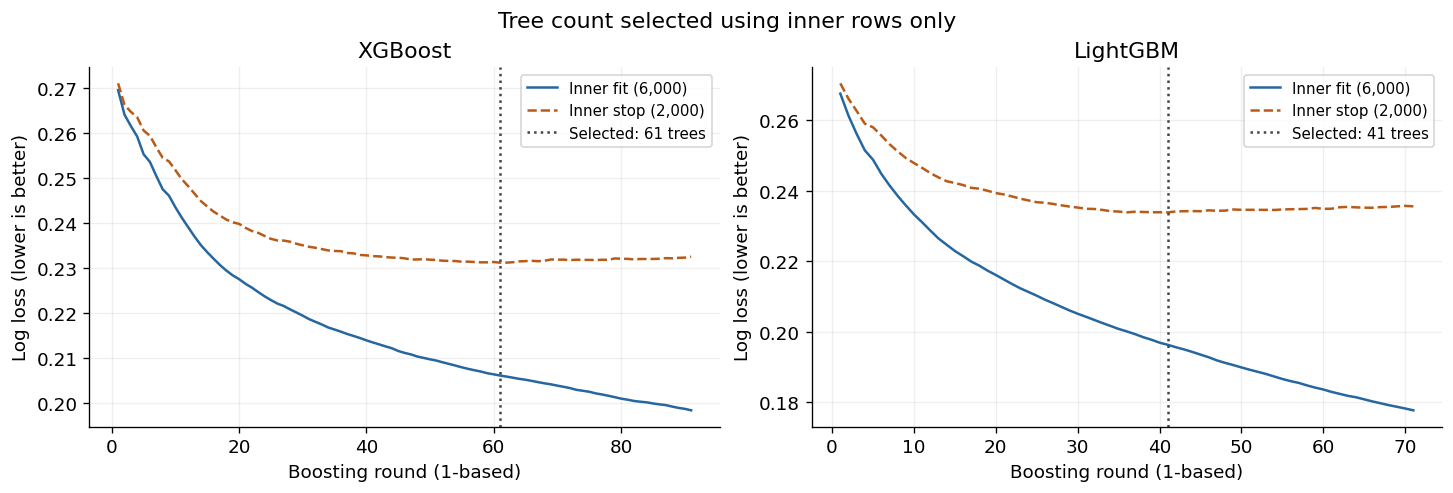

In [41]:
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.2})
colors = {"Logistic Regression": "#2667A0", "XGBoost": "#BA5A17", "LightGBM": "#18816A"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, (name, result) in zip(axes, selections.items()):
    rounds = np.arange(1, len(result["curves"]["fit"]) + 1)
    ax.plot(rounds, result["curves"]["fit"], label="Inner fit (6,000)", color="#2667A0")
    ax.plot(rounds, result["curves"]["stop"], label="Inner stop (2,000)", color="#BA5A17", linestyle="--")
    ax.axvline(result["selected_trees"], color="#444444", linestyle=":",
               label=f"Selected: {result['selected_trees']} trees")
    ax.set(title=name, xlabel="Boosting round (1-based)", ylabel="Log loss (lower is better)")
    ax.legend(fontsize=9)
fig.suptitle("Tree count selected using inner rows only")
fig.savefig(ARTIFACTS / "day1_learning_curves.png", dpi=160)
plt.show()

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>6. Compare the three models fairly</h2>
<p><strong>ROC-AUC</strong> summarizes ranking of positive versus negative cases across thresholds. <strong>Average Precision (AP)</strong> summarizes precision–recall performance and is especially useful when the positive class is uncommon. In this course, PR-AUC refers to scikit-learn Average Precision, not trapezoidal area.</p>
<p><code>train_seconds</code> includes tree-count selection and refitting for boosting models, and fitting for Logistic Regression. Download and plotting time are excluded. Timing is an observation from this run, not a hardware guarantee.</p>
<p>This single split has no confidence interval and does not establish calibration, operational value or general superiority. Simulated decision cost <code>10 × FN + FP</code> and 12% review capacity are introduced in a later decision lab.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>6. قارن النماذج الثلاثة بعدالة</h2>
<p>يلخص <strong>ROC-AUC</strong> ترتيب الحالات الموجبة مقابل السالبة عبر العتبات. ويلخص <strong>Average Precision (AP)</strong> أداء precision–recall، ويكون مهمًا عند ندرة الفئة الموجبة. في هذه الدورة يشير PR-AUC إلى Average Precision في scikit-learn، وليس المساحة شبه المنحرفة.</p>
<p>يشمل <code>train_seconds</code> اختيار عدد الأشجار وإعادة التدريب لنماذج التعزيز، وتدريب Logistic Regression. لا يشمل زمن التنزيل والرسم. الزمن رصد لهذا التشغيل وليس ضمانًا على جهاز آخر.</p>
<p>لا تتضمن هذه التجربة الواحدة فترات ثقة، ولا تثبت المعايرة أو القيمة التشغيلية أو التفوق العام. ستُستخدم تكلفة القرار التعليمية <code>10 × FN + FP</code> وسعة مراجعة 12% في لاب قرار لاحق.</p>
</td>
</tr>
</table>

In [42]:
comparison_table, probabilities = compare_models(
    models, timings, selections, X.loc[comparison], y.loc[comparison])
comparison_table["selected_trees"] = comparison_table["selected_trees"].astype("Int64")
display(comparison_table[["model", "roc_auc", "average_precision", "train_seconds",
                          "selected_trees", "comparison_rows", "positive_rate"]].round(4))
comparison_table.to_csv(ARTIFACTS / "day1_model_comparison.csv", index=False)
prediction_export = train.loc[comparison, ["application_id", "default_within_90d"]].join(probabilities)
prediction_export.to_csv(ARTIFACTS / "day1_comparison_predictions.csv", index=False)
assert len(comparison_table) == 3
assert comparison_table[["roc_auc", "average_precision", "train_seconds"]].notna().all().all()
print("TECHNICAL_READY — three models compared; your interpretation is still required.")
print("Jumanah's interpretation: Logistic Regression scores the highest on the ROC-AUC metric and it is the fastest of all modesl, XGBoost scores has the highest average precision, but much slower than logistic regression")

,model,roc_auc,average_precision,train_seconds,selected_trees,comparison_rows,positive_rate
0,Logistic Regression,0.8213,0.3258,0.1066,<NA>,2000,0.079
1,XGBoost,0.8124,0.3338,1.5167,61,2000,0.079
2,LightGBM,0.8138,0.3248,4.6929,41,2000,0.079


TECHNICAL_READY — three models compared; your interpretation is still required.
Jumanah's interpretation: Logistic Regression scores the highest on the ROC-AUC metric and it is the fastest of all modesl, XGBoost scores has the highest average precision, but much slower than logistic regression


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Read ROC and precision–recall together</h2>
<p>The ROC reference line represents random ranking. The precision reference line equals the positive prevalence in the comparison sample.</p>
<ul><li>Compare curve separation, not only one headline number.</li><li>Inspect precision when recall is high.</li><li>Return to the table for exact values and sample context.</li></ul>
<p>A visually higher curve on one random split is evidence for this run only.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>اقرأ ROC وprecision–recall معًا</h2>
<p>يمثل الخط المرجعي في ROC ترتيبًا عشوائيًا، بينما يساوي خط precision المرجعي نسبة الفئة الموجبة في عينة المقارنة.</p>
<ul><li>قارن تباعد المنحنيات، ولا تعتمد على رقم رئيس واحد فقط.</li><li>افحص precision عندما يكون recall مرتفعًا.</li><li>ارجع إلى الجدول للقيم الدقيقة وسياق حجم العينة.</li></ul>
<p>ارتفاع منحنى بصريًا على تقسيم عشوائي واحد دليل يخص هذا التشغيل فقط.</p>
</td>
</tr>
</table>

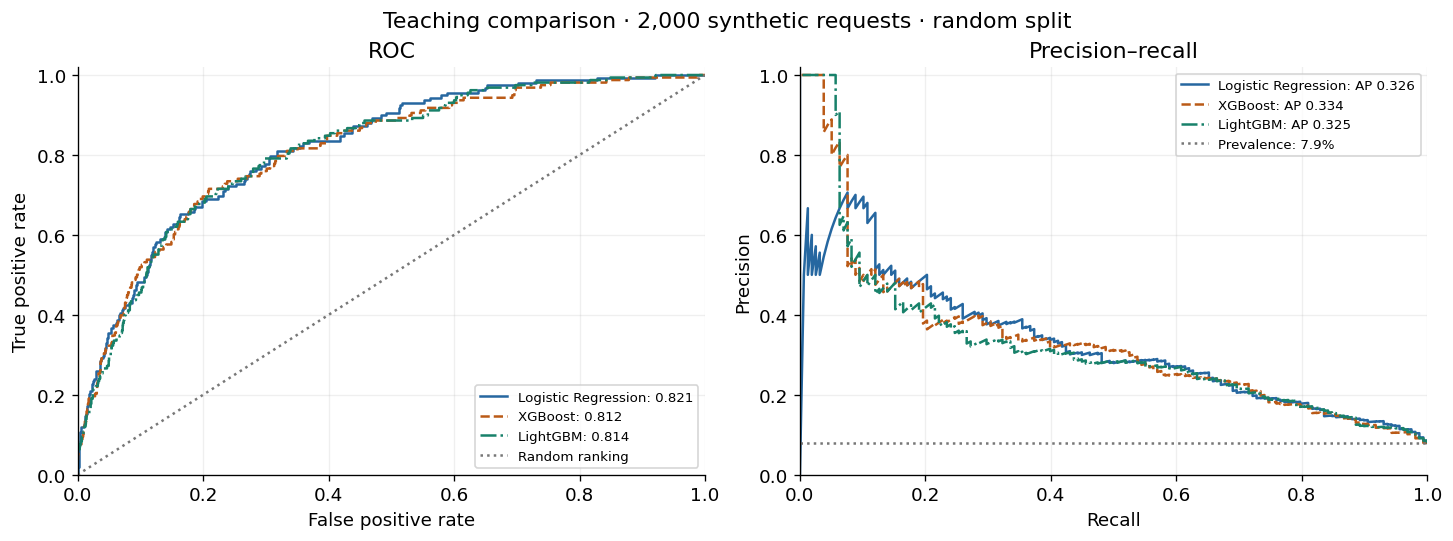

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
styles = ["-", "--", "-."]
for name, style in zip(MODEL_NAMES, styles):
    fpr, tpr, _ = roc_curve(y.loc[comparison], probabilities[name])
    precision, recall, _ = precision_recall_curve(y.loc[comparison], probabilities[name])
    row = comparison_table.set_index("model").loc[name]
    axes[0].plot(fpr, tpr, color=colors[name], linestyle=style, label=f"{name}: {row.roc_auc:.3f}")
    axes[1].plot(recall, precision, color=colors[name], linestyle=style, label=f"{name}: AP {row.average_precision:.3f}")
axes[0].plot([0, 1], [0, 1], color="#777777", linestyle=":", label="Random ranking")
axes[1].axhline(y.loc[comparison].mean(), color="#777777", linestyle=":",
               label=f"Prevalence: {y.loc[comparison].mean():.1%}")
axes[0].set(title="ROC", xlabel="False positive rate", ylabel="True positive rate")
axes[1].set(title="Precision–recall", xlabel="Recall", ylabel="Precision")
for ax in axes:
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
axes[0].legend(fontsize=8, loc="lower right")
axes[1].legend(fontsize=8, loc="upper right")
fig.suptitle(f"Teaching comparison · {len(comparison):,} synthetic requests · random split")
fig.savefig(ARTIFACTS / "day1_roc_pr.png", dpi=160)
plt.show()

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>7. Own the model-selection decision</h2>
<p>Complete the next shared code cell in your own words. There is no automatic winner and no model is required to win.</p>
<ol><li><strong>Problem statement:</strong> outcome, decision time and intended teaching use.</li><li><strong>Candidate:</strong> choose one of the three models.</li><li><strong>Evidence:</strong> cite a number or comparison from your run.</li><li><strong>Limitation:</strong> state what this experiment cannot prove.</li><li><strong>Next test:</strong> identify evidence that could change your choice.</li></ol>
<p><strong>Exit questions:</strong> Why inspect AP beside ROC-AUC under class imbalance? Why must the comparison set remain separate from early stopping?</p>
<p>The automated checkpoint detects empty fields only. It does not judge correctness, award a grade or prove authorship.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>7. امتلك قرار اختيار النموذج</h2>
<p>أكمل خلية الكود المشتركة التالية بصياغتك أنت. لا يوجد فائز تلقائي، ولا يُشترط أن يفوز نموذج محدد.</p>
<ol><li><strong>صياغة المشكلة:</strong> النتيجة ولحظة القرار والاستخدام التعليمي.</li><li><strong>المرشح:</strong> اختر أحد النماذج الثلاثة.</li><li><strong>الدليل:</strong> استشهد برقم أو مقارنة من تشغيلك.</li><li><strong>القيد:</strong> وضح ما لا تستطيع التجربة إثباته.</li><li><strong>الاختبار التالي:</strong> حدد دليلًا قد يغير اختيارك.</li></ol>
<p><strong>سؤالا الخروج:</strong> لماذا تفحص AP بجانب ROC-AUC عند عدم توازن الفئات؟ ولماذا يجب فصل مجموعة المقارنة عن الإيقاف المبكر؟</p>
<p>يكتشف الفحص الآلي الخانات الفارغة فقط؛ لا يحكم على صحة الإجابة ولا يمنح درجة ولا يثبت الملكية الفكرية.</p>
</td>
</tr>
</table>

In [44]:
problem_statement = "We're comparing the models to rank applications by their risk of a default event occuring within 90 days after the application"  # Outcome, decision time and intended teaching use.
candidate = "XGBoost"  # "Logistic Regression", "XGBoost", or "LightGBM"
notes = {"evidence": "The XGBoost model scored the highest at 0.3338 at the average percision metric which is the metric we are concerned with as the default occuring is a rarity, and that's the metric that catches it, while the logsitic regression was teh fastest and scored the highest in the ROC metric", "limitation": "The random split does not show us how accurately the model will perform on future applicants", "next_test": "Perform a differnt split and check whether the models will perform the same way."}
exit_answers = ["Because AP catches rare of uncommon events and defaults are rare events", "Because we need the model to accurately choose the number of trees and not tune it based on the set and make the scores untrustworthy"]
checkpoint = learner_checkpoint(candidate, notes, problem_statement, exit_answers)
print(checkpoint["status"])
for reminder in checkpoint["missing"]:
    print("-", reminder)

READY_FOR_REVIEW


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>8. Export evidence, not screenshots</h2>
<p>The export cell writes eight required files and creates <code>day1_artifacts.zip</code>. Download the ZIP, extract it and upload the actual files to <code>artifacts/</code>. Save the executed notebook in <code>notebooks/</code>.</p>
<ul><li><code>TECHNICAL_READY</code>: the models and evidence were produced.</li><li><code>LEARNER_WORK_REQUIRED</code>: technical execution passed, but your written fields remain incomplete.</li><li><code>READY_FOR_REVIEW</code>: required fields are present; this is not a grade or correctness guarantee.</li></ul>
<p>Copy your problem statement into your project README. Never upload access tokens, passwords or personal data.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>8. صدّر الأدلة وليس لقطات الشاشة فقط</h2>
<p>تكتب خلية التصدير ثمانية ملفات إلزامية وتنشئ <code>day1_artifacts.zip</code>. نزّل الحزمة وافكها وارفع الملفات الفعلية إلى <code>artifacts/</code>. واحفظ الدفتر المنفذ داخل <code>notebooks/</code>.</p>
<ul><li><code>TECHNICAL_READY</code>: تم إنتاج النماذج والأدلة.</li><li><code>LEARNER_WORK_REQUIRED</code>: نجح التنفيذ التقني، لكن حقولك الكتابية غير مكتملة.</li><li><code>READY_FOR_REVIEW</code>: الحقول المطلوبة موجودة؛ ولا تمثل درجة أو ضمانًا لصحة التفسير.</li></ul>
<p>انسخ صياغة المشكلة إلى README الخاص بمشروعك. لا ترفع رموز الدخول أو كلمات المرور أو البيانات الشخصية.</p>
</td>
</tr>
</table>

In [45]:
import platform, zipfile

checkpoint = learner_checkpoint(candidate, notes, problem_statement, exit_answers)
reflection = {"problem_statement": problem_statement, "candidate": candidate,
              "notes": notes, "exit_answers": exit_answers, "checkpoint": checkpoint}
(ARTIFACTS / "day1_reflection.json").write_text(json.dumps(reflection, ensure_ascii=False, indent=2), encoding="utf-8")
membership = train[["application_id"]].copy()
membership["role"] = "comparison"
membership.loc[inner_fit, "role"] = "inner_fit"
membership.loc[inner_stop, "role"] = "inner_stop"
membership.to_csv(ARTIFACTS / "day1_split_membership.csv", index=False)
report = {"technical_status": "TECHNICAL_READY", "learner_status": checkpoint["status"],
          "data_revision": COURSE_REVISION, "lab_revision": LAB_REVISION,
          "lab_sha256": LAB_SHA256, "data_manifest_sha256": MANIFEST_SHA256,
          "training_file_sha256": hashlib.sha256((ROOT / "data/tamweel_train.csv").read_bytes()).hexdigest(),
          "config": config_dict(config), "mode": "FAST" if FAST_MODE else "FULL",
          "python": platform.python_version(), "split": split_table.to_dict("records"),
          "split_method": "random stratified teaching baseline; not final validation",
          "shared_customers": shared_customers, "selections": selections,
          "ap_definition": "sklearn average_precision_score, non-interpolated",
          "elapsed_seconds": round(time.perf_counter() - RUN_STARTED, 2)}
if IN_COLAB:
    import resource
    report["peak_process_memory_mib"] = round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024, 1)
(ARTIFACTS / "day1_run.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
export_names = ["environment.json", "day1_model_comparison.csv", "day1_comparison_predictions.csv",
                "day1_split_membership.csv", "day1_learning_curves.png", "day1_roc_pr.png",
                "day1_reflection.json", "day1_run.json"]
with zipfile.ZipFile(ARTIFACTS / "day1_artifacts.zip", "w", zipfile.ZIP_DEFLATED) as bundle:
    for filename in export_names:
        bundle.write(ARTIFACTS / filename, filename)
print(f"TECHNICAL_READY | {checkpoint['status']} | {report['elapsed_seconds']} seconds | CPU")
print("Saved day1_artifacts.zip — download it and save your notebook.")

TECHNICAL_READY | READY_FOR_REVIEW | 10.34 seconds | CPU
Saved day1_artifacts.zip — download it and save your notebook.


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Completion checkpoint and next step</h2>
<ul><li>Three valid model rows appear in <code>day1_model_comparison.csv</code>.</li><li>You can explain development, inner stopping and comparison roles.</li><li>You selected one candidate and documented evidence, a limitation and a next test.</li><li>You saved the executed notebook and all eight artifacts outside the temporary Colab session.</li></ul>
<p><strong>Optional extension:</strong> after preserving the baseline, change <code>learning_rate</code> once with the same split. Document the impact on tree count and time. Repeatedly searching for the highest comparison score would convert the comparison set into a tuning set.</p>
<p><strong>Troubleshooting:</strong> retry setup after a download interruption; restart the session after an imported-version mismatch; restore original files after a checksum failure; never replace your outputs with another learner's table.</p>
<p><strong>Day 2:</strong> test customer separation, time ordering and target maturity, then reassess whether the first candidate remains credible.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>نقطة الإكمال والخطوة التالية</h2>
<ul><li>تظهر ثلاثة صفوف صالحة في <code>day1_model_comparison.csv</code>.</li><li>تستطيع شرح أدوار التطوير والإيقاف الداخلي والمقارنة.</li><li>اخترت مرشحًا ووثقت دليلًا وقيدًا واختبارًا تاليًا.</li><li>حفظت الدفتر المنفذ والملفات الثمانية خارج جلسة Colab المؤقتة.</li></ul>
<p><strong>توسع اختياري:</strong> بعد حفظ تجربة الأساس، غيّر <code>learning_rate</code> مرة واحدة مع التقسيم نفسه، ووثق أثره على عدد الأشجار والزمن. البحث المتكرر عن أعلى نتيجة يحول مجموعة المقارنة إلى مجموعة ضبط.</p>
<p><strong>حل التعثر:</strong> أعد خلية الإعداد عند انقطاع التنزيل؛ أعد تشغيل الجلسة عند اختلاف إصدار مستورد؛ استرجع الملفات الأصلية عند فشل البصمة؛ ولا تستبدل مخرجاتك بجدول متدرب آخر.</p>
<p><strong>اليوم الثاني:</strong> اختبر فصل العملاء وترتيب الزمن ونضج الهدف، ثم أعد تقييم مدى موثوقية المرشح الأول.</p>
</td>
</tr>
</table>

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Daily question · Model comparison</h2>
<p><strong>Which model did you select initially, and what is the strongest result supporting your choice?</strong><br><br>Write a short answer under <code>Day 1</code> in the <code>Daily answers | الإجابات اليومية</code> section of your repository README. Then download this executed notebook and the required generated files and upload them on the same day.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>سؤال اليوم · مقارنة النماذج</h2>
<p><strong>أي نموذج اخترت مبدئيًا، وما الدليل الأقوى من نتائجك؟</strong><br><br>اكتب إجابة مختصرة تحت <code>Day 1 | اليوم 1</code> في قسم <code>Daily answers | الإجابات اليومية</code> داخل README في مستودعك، ثم نزّل هذا الدفتر بعد التنفيذ وملفات النتائج المطلوبة وارفعها في اليوم نفسه.</p>
</td>
</tr>
</table>

---
# Gate 2: Honest validation and tuning

_Executed notebook `notebooks/02_validation_tuning.ipynb`._

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Day 2 · Validate honestly before tuning</h2>
<p><strong>SDA-DSC-211 · Tamweel Lite · 60-minute lab · Free CPU</strong></p>
<p>Audit feature availability, remove post-outcome leakage and exact duplicate events, then evaluate later requests with mature labels while excluding each validation fold's customers from its training fold. Freeze a bounded search on a separate historical customer cohort before reading outer-validation results.</p>
<p><strong>Deliverables:</strong> leakage and fold audits, bounded-search history, frozen parameters, validation report and summary, out-of-fold predictions and coverage, provenance, figures, run metadata and your written interpretation.</p>
<p><strong>Scientific boundary:</strong> all records are synthetic. The random protocols are negative controls, not deployment evidence. The forward folds estimate a particular later-period, unseen-customer scenario; they are not a final independent test and do not prove fairness, calibration or operational value.</p>
<table><tr><th>Minutes</th><th>Your task</th></tr><tr><td>0–8</td><td>Prepare the environment and read the data contract</td></tr><tr><td>8–18</td><td>Audit leakage and duplicate events</td></tr><tr><td>18–30</td><td>Inspect time, customer and label-maturity boundaries</td></tr><tr><td>30–45</td><td>Run the bounded search on the reserved cohort</td></tr><tr><td>45–53</td><td>Compare means, variation and coverage</td></tr><tr><td>53–60</td><td>Write your reasoning and export evidence</td></tr></table>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>اليوم الثاني · تحقّق بصدق قبل ضبط النموذج</h2>
<p><strong>SDA-DSC-211 · Tamweel Lite · لاب 60 دقيقة · CPU مجاني</strong></p>
<p>دقّق زمن إتاحة الخصائص، واحذف تسرب ما بعد النتيجة والنسخ المتطابقة من الحدث، ثم قيّم الطلبات اللاحقة بعد نضج أهدافها مع استبعاد عملاء كل طية تحقق من تدريب الطية نفسها. جمّد بحثًا محدودًا على مجموعة تاريخية منفصلة قبل قراءة نتائج التحقق الخارجي.</p>
<p><strong>المخرجات:</strong> تدقيق التسرب والطيات، وسجل البحث المحدود، والإعدادات المجمدة، وتقرير التحقق وملخصه، وتنبؤات OOF وتغطيتها، ومصدر التدريب، والرسوم، وبيانات التشغيل، وتفسيرك المكتوب.</p>
<p><strong>حد علمي:</strong> جميع السجلات اصطناعية. البروتوكولات العشوائية ضوابط سلبية وليست دليل نشر. تقيس الطيات الزمنية سيناريو محددًا لطلبات لاحقة من عملاء غير موجودين في تدريب الطية؛ وليست اختبارًا نهائيًا مستقلًا، ولا تثبت العدالة أو المعايرة أو القيمة التشغيلية.</p>
<table><tr><th>الدقائق</th><th>مهمتك</th></tr><tr><td>0–8</td><td>جهّز البيئة واقرأ عقد البيانات</td></tr><tr><td>8–18</td><td>دقّق التسرب والطلبات المكررة</td></tr><tr><td>18–30</td><td>افحص حدود الزمن والعملاء ونضج الهدف</td></tr><tr><td>30–45</td><td>نفّذ البحث المحدود على المجموعة المحجوزة</td></tr><tr><td>45–53</td><td>قارن المتوسط والتشتت والتغطية</td></tr><tr><td>53–60</td><td>اكتب تفسيرك وصدّر الأدلة</td></tr></table>
</td>
</tr>
</table>

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Official daily requirement</h2>
<p>Run all cells, compare the generated files with EXPECTED_RESULTS.md, then answer only the single question at the end of this notebook in your repository README. Legacy reflection variables inside code cells are compatibility fields; leave them unchanged.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>المطلوب اليومي المعتمد</h2>
<p>شغّل جميع الخلايا، وقارن الملفات الناتجة بصفحة EXPECTED_RESULTS.md، ثم أجب فقط عن السؤال الواحد في نهاية هذا الدفتر داخل README في مستودعك. حقول الانعكاس القديمة داخل خلايا الكود مخصصة للتوافق؛ اتركها دون تعديل.</p>
</td>
</tr>
</table>

In [18]:
import importlib.metadata as metadata
import os
import signal
import subprocess
import sys

EXPECTED_VERSIONS = {
    "numpy": "2.1.3",
    "pandas": "2.2.3",
    "scipy": "1.16.3",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "xgboost": "3.4.1",
    "lightgbm": "4.6.0",
    "shap": "0.52.0",
    "numba": "0.61.2",
    "optuna": "4.5.0",
}

different_versions = []

for package_name, expected_version in EXPECTED_VERSIONS.items():
    try:
        current_version = metadata.version(package_name)
    except metadata.PackageNotFoundError:
        current_version = None

    if current_version != expected_version:
        different_versions.append(
            f"{package_name}: {current_version or 'غير مثبت'} → {expected_version}"
        )

if different_versions:
    print("سيتم تجهيز بيئة الدورة بالإصدارات المعتمدة:")
    for item in different_versions:
        print("-", item)

    requirements_url = (
        "https://raw.githubusercontent.com/"
        "almiyead-rgb/sda-dsc-211-student-template/"
        "fe0c0204e6076a7ac2139b7336485a097343fb8a/"
        "requirements-colab.txt"
    )

    constraints_url = (
        "https://raw.githubusercontent.com/"
        "almiyead-rgb/sda-dsc-211-student-template/"
        "fe0c0204e6076a7ac2139b7336485a097343fb8a/"
        "constraints.txt"
    )

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "--quiet",
        "--disable-pip-version-check",
        "-r",
        requirements_url,
        "-c",
        constraints_url,
    ])

    print(
        "\nتم تثبيت بيئة الدورة بنجاح.\n"
        "ستتم إعادة تشغيل الجلسة الآن بصورة تلقائية.\n"
        "بعد عودة الاتصال اختَر Runtime → Run all مرة أخرى."
    )

    os.kill(os.getpid(), signal.SIGKILL)

else:
    print("بيئة الدورة جاهزة، ويمكن متابعة تشغيل Notebook.")


بيئة الدورة جاهزة، ويمكن متابعة تشغيل Notebook.


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>1. Prepare a controlled environment</h2>
<p>Open a fresh notebook session, select the free CPU runtime and choose <strong>Runtime → Run all</strong>. Setup verifies pinned library versions, the data manifest and SHA-256 hashes before modeling.</p>
<ul><li><code>FAST_MODE=True</code>: two CPU threads and a ceiling of 200 trees; use this first.</li><li><code>FULL_MODE=True</code>: optional ceiling of 600 trees.</li><li>Both modes retain at most eight sequential trials, three search folds and a 120-second cooperative search budget.</li><li>No GPU, API key, Drive mount or paid service is required.</li></ul>
<p><strong>Pass condition:</strong> the cell prints <code>Day 2 setup verified</code>. Do not bypass checksum or imported-version failures; restart the session and run from the beginning.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>1. جهّز بيئة تشغيل محكومة</h2>
<p>افتح جلسة دفتر جديدة، واختر بيئة CPU المجانية، ثم نفّذ <strong>Runtime → Run all</strong>. يتحقق الإعداد من إصدارات المكتبات المثبتة وبيان البيانات وبصمات SHA-256 قبل بدء النمذجة.</p>
<ul><li><code>FAST_MODE=True</code>: خيطا CPU وسقف 200 شجرة؛ ابدأ به.</li><li><code>FULL_MODE=True</code>: سقف اختياري يبلغ 600 شجرة.</li><li>يحتفظ الوضعان بحد أقصى قدره ثماني تجارب متتابعة وثلاث طيات للبحث وميزانية بحث تعاونية قدرها 120 ثانية.</li><li>لا تحتاج إلى GPU أو مفتاح API أو ربط Drive أو خدمة مدفوعة.</li></ul>
<p><strong>شرط الاجتياز:</strong> ظهور <code>Day 2 setup verified</code>. لا تتجاوز فشل البصمة أو اختلاف إصدار مستورد؛ أعد تشغيل الجلسة ثم شغّل الدفتر من البداية.</p>
</td>
</tr>
</table>

In [19]:
from pathlib import Path
import hashlib, importlib.util, os, runpy, sys, time, urllib.request, urllib.error

RUN_STARTED = time.perf_counter()
COURSE_REVISION = "fe0c0204e6076a7ac2139b7336485a097343fb8a"
MANIFEST_SHA256 = "86d15e813caf833b7d86512808176388d4123dc3c01c6525ee849a76e8322c59"
SETUP_SHA256 = "79608f8f9559d9e6eb09d51ee541ee12d7e9262ac57d1ca3a948c8ecb14f0f35"
IN_COLAB = importlib.util.find_spec("google") is not None and importlib.util.find_spec("google.colab") is not None
ROOT = Path("/content/tamweel") if IN_COLAB else Path(os.environ.get("TAMWEEL_PROJECT_DIR", ".")).resolve()
setup_path = ROOT / "scripts/setup_colab.py"
setup_path.parent.mkdir(parents=True, exist_ok=True)
if not setup_path.exists() or hashlib.sha256(setup_path.read_bytes()).hexdigest() != SETUP_SHA256:
    setup_url = f"https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template/{COURSE_REVISION}/scripts/setup_colab.py"
    for attempt in range(3):
        try:
            with urllib.request.urlopen(setup_url, timeout=45) as response:
                setup_bytes = response.read(200000)
            if hashlib.sha256(setup_bytes).hexdigest() != SETUP_SHA256:
                raise ValueError("Setup checksum mismatch. Reopen the released notebook.")
            setup_path.write_bytes(setup_bytes)
            break
        except (urllib.error.URLError, TimeoutError):
            if attempt == 2:
                raise RuntimeError("Download unavailable. Retry setup or upload the unchanged project files; see READINESS_GUIDE.")
            time.sleep(attempt + 1)
environment = runpy.run_path(str(setup_path))["prepare"](ROOT, COURSE_REVISION, MANIFEST_SHA256)
FAST_MODE, FULL_MODE, SEED, N_JOBS = True, False, 211, 2

from setup_colab import fetch_verified
LAB_REVISION = "1e1da4acbee8941bef07245b259fb6c27ced4ad7"
SUPPORT_HASHES = {'scripts/day2_validation.py': 'd2fd0353330c3629bdaed6c570528792955fce232540a85d33532a9432522f43', 'data/day2_optuna_example.csv': 'a59000eee4caced319735d237b8d121b2e0c7384acce93392d214ddbfe2f5b93', 'data/day2_optuna_example.json': 'a91a4d3a39ecd9cbab9bf902aaf5e2e060d4e21bcc93793057d5250aa002802c'}
for relative, sha256 in SUPPORT_HASHES.items():
    fetch_verified(
        f"https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template/{LAB_REVISION}/{relative}",
        ROOT / relative, sha256)
print("Day 2 setup verified | إعداد اليوم الثاني جاهز")

Package                 Version
numpy                   2.1.3
pandas                  2.2.3
scipy                   1.16.3
scikit-learn            1.6.1
matplotlib              3.10.0
xgboost                 3.4.1
lightgbm                4.6.0
shap                    0.52.0
numba                   0.61.2
optuna                  4.5.0
Python 3.13.18 | CPU | seed=211 | n_jobs=2 | FAST_MODE=True
Verified course files. Next: run the data and compatibility checks.
Day 2 setup verified | إعداد اليوم الثاني جاهز


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>2. Audit information availability and duplicates</h2>
<p>The target <code>default_within_90d</code> records whether a default event occurs within 90 days after the application. It does not mean an account reaches exactly 90 days past due.</p>
<p>Use the feature dictionary's <code>available_at</code> field. A predictor is eligible only when its information exists at application time. A strong correlation alone does not prove leakage.</p>
<table><tr><th>Risk</th><th>Guard</th></tr><tr><td>Target leakage</td><td>Remove fields describing the later outcome</td></tr><tr><td>Preprocessing leakage</td><td>Learn imputation from training rows only</td></tr><tr><td>Time leakage</td><td>Train only on applications whose labels are mature before validation starts</td></tr><tr><td>Customer leakage</td><td>Exclude validation customers from the same fold's training rows</td></tr><tr><td>Duplicate leakage</td><td>Deduplicate identical events and reject conflicting copies</td></tr></table>
<p>The dirty training copy is read to demonstrate the audit. Challenge data is not used for model selection or comparison in this lab.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>2. دقّق إتاحة المعلومات والتكرار</h2>
<p>يسجل الهدف <code>default_within_90d</code> ما إذا وقع حدث تعثر خلال 90 يومًا بعد الطلب. ولا يعني وصول الحساب إلى 90 يوم تأخر بالضبط.</p>
<p>استخدم حقل <code>available_at</code> في قاموس الخصائص. لا تُقبل الخاصية إلا إذا كانت معلومتها موجودة وقت تقديم الطلب. الارتباط القوي وحده لا يثبت التسرب.</p>
<table><tr><th>الخطر</th><th>الحارس</th></tr><tr><td>تسرب الهدف</td><td>حذف الحقول التي تصف النتيجة اللاحقة</td></tr><tr><td>تسرب المعالجة</td><td>تعلم التعويض من صفوف التدريب فقط</td></tr><tr><td>تسرب الزمن</td><td>التدريب على الطلبات التي نضجت أهدافها قبل بدء التحقق</td></tr><tr><td>تسرب العميل</td><td>استبعاد عملاء التحقق من تدريب الطية نفسها</td></tr><tr><td>تسرب التكرار</td><td>حذف الأحداث المتطابقة ورفض النسخ المتعارضة</td></tr></table>
<p>تُقرأ نسخة التدريب المتسربة لشرح التدقيق. لا تُستخدم بيانات التحدي في اختيار النموذج أو مقارنته في هذا اللاب.</p>
</td>
</tr>
</table>

In [20]:
import json, platform, zipfile
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from data_checks import validate_frame
from day2_validation import (ValidationConfig, BASE_PARAMS, leakage_audit,
    deduplicate_applications, make_time_group_split, reserve_tuning_pool,
    tune_on_reserved_pool, negative_controls, evaluate_outer, summarize_folds, reflection_check)

contract = json.loads((ROOT / "data/data_contract.json").read_text(encoding="utf-8"))
dictionary = pd.read_csv(ROOT / "data/feature_dictionary.csv")
dirty = pd.read_csv(ROOT / "data/tamweel_dirty.csv")
validate_frame(dirty, contract, "dirty")
audit = leakage_audit(dirty, dictionary)
assert not audit.action.eq("BLOCK_UNKNOWN").any(), "Review unknown fields before training."
leaked_features = audit.loc[audit.action.eq("DROP_POST_OUTCOME"), "feature"].tolist()
clean, duplicates = deduplicate_applications(dirty.drop(columns=leaked_features))
validate_frame(clean, contract, "train")
target = contract["target"]["name"]
FAST_MODE, FULL_MODE = True, False
assert FAST_MODE != FULL_MODE, "Choose exactly one mode."
config = ValidationConfig(max_trees=200 if FAST_MODE else 600, trials=8, timeout_seconds=120)
ARTIFACTS = ROOT / "artifacts"
ARTIFACTS.mkdir(exist_ok=True)
display(audit)
display(pd.DataFrame([{**duplicates, "predictors": int(audit.action.eq("KEEP").sum()),
                       "positive_rate": clean[target].mean()}]))
print("Explain which two fields you removed and when their information becomes available.")

,feature,role,available_at,action
0,application_id,id,application_date,EXCLUDE_METADATA_OR_TARGET
1,customer_id,id,application_date,EXCLUDE_METADATA_OR_TARGET
2,application_date,split,application_date,EXCLUDE_METADATA_OR_TARGET
3,age,predictor,application_date,KEEP
4,income_sar,predictor,application_date,KEEP
5,loan_amount_sar,predictor,application_date,KEEP
6,tenor_months,predictor,application_date,KEEP
7,bureau_score,predictor,application_date,KEEP
8,dti,predictor,application_date,KEEP
9,months_employed,predictor,application_date,KEEP


,input_rows,retained_rows,duplicate_rows_removed,predictors,positive_rate
0,10000,10000,0,22,0.0789


Explain which two fields you removed and when their information becomes available.


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>3. Freeze time, customer and label-maturity roles</h2>
<p>The notebook creates three consecutive forward-validation windows. For each fold, training rows must satisfy:</p>
<p><strong>application date + 90 days &lt; validation start</strong></p>
<p>The strict inequality intentionally excludes labels that mature exactly on the boundary. Every customer appearing in a fold's validation period is removed from that fold's training rows.</p>
<ul><li>The design evaluates later requests from customers unseen in the corresponding training fold.</li><li>A customer may appear in more than one validation period; the guarantee is zero train–validation overlap within each fold.</li><li>Earlier rows remain a warm-up period. They must not receive fitted-training predictions disguised as OOF evidence.</li><li>Exact duplicate events are removed before splitting. Conflicting copies stop execution.</li></ul>
<p>Inspect the fold-audit table and figure before interpreting any performance metric.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>3. جمّد أدوار الزمن والعملاء ونضج الهدف</h2>
<p>ينشئ الدفتر ثلاث فترات تحقق زمنية متتابعة. يجب أن تحقق صفوف تدريب كل طية الشرط الآتي:</p>
<p><strong>تاريخ الطلب + 90 يومًا &lt; بداية التحقق</strong></p>
<p>تستبعد المتباينة الصارمة عمدًا الأهداف التي تنضج في يوم الحد نفسه. ويُحذف من تدريب كل طية كل عميل يظهر في فترة تحقق تلك الطية.</p>
<ul><li>يقيس التصميم طلبات لاحقة من عملاء لم يظهروا في تدريب الطية المقابلة.</li><li>قد يظهر العميل في أكثر من فترة تحقق؛ والضمان هو عدم وجود تداخل بين التدريب والتحقق داخل الطية نفسها.</li><li>تبقى الصفوف المبكرة فترة تمهيد. لا تمنحها تنبؤات تدريب ثم تعرضها بوصفها OOF.</li><li>تُحذف الأحداث المتطابقة قبل التقسيم، بينما توقف النسخ المتعارضة التنفيذ.</li></ul>
<p>افحص جدول تدقيق الطيات والرسم قبل تفسير أي مقياس أداء.</p>
</td>
</tr>
</table>

,fold,validation_start,validation_end_exclusive,train_rows,validation_rows,train_positives,validation_positives,immature_past_rows_removed,customer_overlap_rows_removed,shared_customers,latest_training_label_available,validation_positive_rate
0,1,2023-07-01,2024-01-01,3223,1632,274,110,826,912,0,2023-06-30,0.067402
1,2,2024-01-01,2024-07-01,4460,1674,353,135,785,1348,0,2023-12-31,0.080645
2,3,2024-07-01,2025-01-01,5731,1733,465,139,861,1675,0,2024-06-30,0.080208


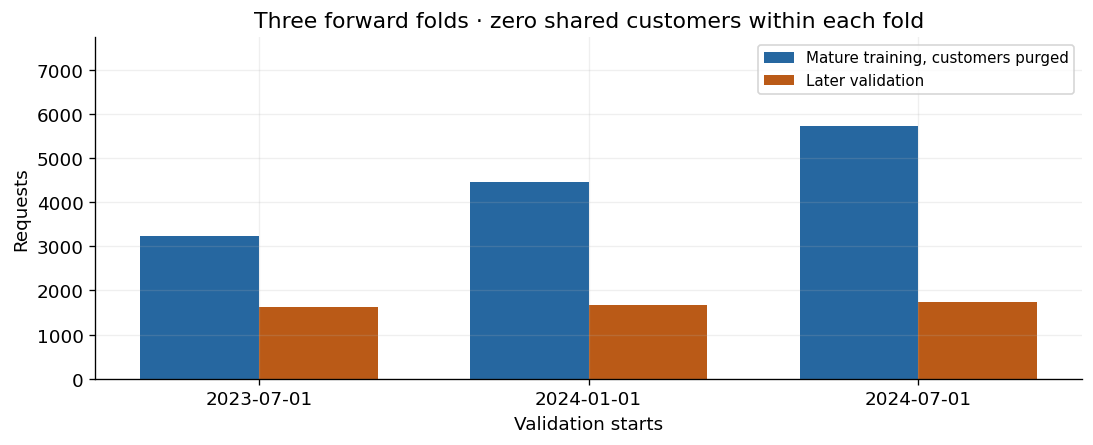

In [21]:
folds = make_time_group_split(clean, horizon_days=contract["target"]["horizon_days"])
fold_audit = pd.DataFrame([fold["audit"] for fold in folds])
for fold in folds:
    tr, va = clean.loc[fold["train"]], clean.loc[fold["valid"]]
    assert not set(tr.customer_id) & set(va.customer_id)
    assert (pd.to_datetime(tr.application_date) + pd.Timedelta(days=90) <
            pd.Timestamp(fold["audit"]["validation_start"])).all()
fold_audit["validation_positive_rate"] = fold_audit.validation_positives / fold_audit.validation_rows
display(fold_audit)

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.2})
fig, ax = plt.subplots(figsize=(9, 3.6), constrained_layout=True)
x = np.arange(len(fold_audit))
ax.bar(x - .18, fold_audit.train_rows, .36, label="Mature training, customers purged", color="#2667A0")
ax.bar(x + .18, fold_audit.validation_rows, .36, label="Later validation", color="#BA5A17")
ax.set(xticks=x, xticklabels=fold_audit.validation_start, ylabel="Requests", xlabel="Validation starts",
       title="Three forward folds · zero shared customers within each fold")
ax.set_ylim(0, fold_audit.train_rows.max() * 1.35)
ax.legend(fontsize=9)
fig.savefig(ARTIFACTS / "day2_fold_sizes.png", dpi=160)
plt.show()

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>4. Reserve search before reading outer validation</h2>
<p>Hyperparameters are selected once from a historical cohort that is mature before the first outer-validation window. All customers used in any of the three outer-validation periods are excluded from this search cohort.</p>
<p>Inside the reserved cohort, three forward folds also separate customers. Each fold contains an inner stopping split: preprocessing and trees are learned on inner-fit rows, the tree count is selected on inner-stop log loss, and the model is then refit on the full fold-training rows.</p>
<ul><li>Outer-validation rows never select imputation, tree count or hyperparameters.</li><li>Future target values are not used to define search parameters.</li><li>The released data produces a relatively small search cohort, with few positive examples in some inner partitions. Record this limitation.</li></ul>
<p>The best search AP is a model-selection statistic. It is not an estimate of future outer performance.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>4. احجز البحث قبل قراءة التحقق الخارجي</h2>
<p>تُختار المعاملات مرة واحدة من مجموعة تاريخية نضجت أهدافها قبل أول فترة تحقق خارجي. ويُستبعد من مجموعة البحث جميع العملاء المستخدمين في فترات التحقق الخارجي الثلاث.</p>
<p>داخل المجموعة المحجوزة توجد ثلاث طيات زمنية تفصل العملاء أيضًا. تتضمن كل طية جزءًا داخليًا للإيقاف: تتعلم المعالجة والأشجار من صفوف inner fit، ويُختار عدد الأشجار من inner stop باستخدام log loss، ثم يُعاد التدريب على صفوف تدريب الطية كاملة.</p>
<ul><li>لا تختار صفوف التحقق الخارجي التعويض أو عدد الأشجار أو معاملات البحث.</li><li>لا تُستخدم أهداف المستقبل في تحديد إعدادات البحث.</li><li>تنتج البيانات المنشورة مجموعة بحث صغيرة نسبيًا، مع أمثلة موجبة قليلة في بعض الأجزاء الداخلية. وثّق هذا القيد.</li></ul>
<p>أفضل AP داخل البحث إحصائية لاختيار النموذج، وليست تقديرًا للأداء الخارجي المستقبلي.</p>
</td>
</tr>
</table>

In [22]:
pool = reserve_tuning_pool(clean, folds)
outer_ids = np.concatenate([fold["valid"] for fold in folds])
assert not set(pool.customer_id) & set(clean.loc[outer_ids, "customer_id"])
assert (pd.to_datetime(pool.application_date) + pd.Timedelta(days=90) < pd.Timestamp("2023-07-01")).all()
display(pd.DataFrame([{"search_rows": len(pool), "search_positives": int(pool[target].sum()),
    "search_positive_rate": pool[target].mean(), "latest_application": pool.application_date.max(),
    "outer_validation_rows": len(outer_ids)}]))

,search_rows,search_positives,search_positive_rate,latest_application,outer_validation_rows
0,1935,176,0.090956,2023-04-01,5039


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>5. Run a bounded Optuna search</h2>
<p>The objective is mean <strong>Average Precision (AP)</strong> across three internal forward folds. Search changes only <code>learning_rate</code>, <code>num_leaves</code> and <code>min_child_samples</code>.</p>
<ul><li>Seed: 211.</li><li>At most eight sequential trials.</li><li>At most 120 seconds for search, with cooperative stopping that can finish slightly after the boundary.</li><li><code>COMPLETE</code>: all three fold scores were calculated.</li><li><code>PRUNED</code>: the trial stopped early.</li><li><code>FAIL</code>: the attempt did not produce a complete objective; partial values are not a completed mean.</li></ul>
<p>If no trial completes, the notebook shows a stored <code>EDUCATIONAL_EXAMPLE</code> for discussion only and reports <code>TUNING_REQUIRED</code>. The example is never copied into your live results or submission. Retry later in a fresh free-CPU session rather than purchasing compute.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>5. نفّذ بحث Optuna محدودًا</h2>
<p>الهدف هو متوسط <strong>Average Precision (AP)</strong> عبر ثلاث طيات زمنية داخلية. يغيّر البحث فقط <code>learning_rate</code> و<code>num_leaves</code> و<code>min_child_samples</code>.</p>
<ul><li>البذرة: 211.</li><li>حد أقصى قدره ثماني تجارب متتابعة.</li><li>حد أقصى قدره 120 ثانية للبحث، مع إيقاف تعاوني قد ينتهي بعد الحد بقليل.</li><li><code>COMPLETE</code>: اكتملت درجات الطيات الثلاث.</li><li><code>PRUNED</code>: أوقفت التجربة مبكرًا.</li><li><code>FAIL</code>: لم تنتج المحاولة هدفًا مكتملًا؛ ولا تُعامل القيم الجزئية بوصفها متوسطًا مكتملًا.</li></ul>
<p>إذا لم تكتمل أي تجربة، يعرض الدفتر <code>EDUCATIONAL_EXAMPLE</code> محفوظًا للنقاش فقط ويظهر <code>TUNING_REQUIRED</code>. لا يُنسخ المثال إلى نتائجك الفعلية أو تسليمك. أعد المحاولة لاحقًا في جلسة CPU مجانية جديدة بدل شراء موارد حوسبة.</p>
</td>
</tr>
</table>

,status,completed_trials,attempted_trials,elapsed_seconds,stopping_reason,best_tuning_ap
0,COMPLETE,8,8,2.259308,TRIAL_LIMIT,0.333269


,fold,validation_start,validation_end_exclusive,train_rows,validation_rows,train_positives,validation_positives,immature_past_rows_removed,customer_overlap_rows_removed,shared_customers,latest_training_label_available
0,1,2022-10-01,2023-01-01,703,381,52,42,351,99,0,2022-09-30
1,2,2023-01-01,2023-03-01,1070,271,83,27,373,91,0,2022-12-31
2,3,2023-03-01,2023-04-02,1355,130,118,15,389,61,0,2023-02-28


,trial,state,mean_ap,seconds,learning_rate,num_leaves,min_child_samples,fold_1_ap,fold_2_ap,fold_3_ap
0,0,COMPLETE,0.316524,0.232311,0.085161,15,10,0.319910,0.320935,0.308727
1,1,COMPLETE,0.333269,0.245409,0.085305,31,40,0.391154,0.349373,0.259279
2,2,COMPLETE,0.308752,0.342973,0.034906,31,40,0.404534,0.271448,0.250276
3,3,COMPLETE,0.320550,0.302282,0.040259,31,20,0.384913,0.316815,0.259923
4,4,COMPLETE,0.327798,0.319474,0.062862,15,40,0.403532,0.310814,0.269049
5,5,COMPLETE,0.319093,0.226852,0.037608,7,10,0.365309,0.299275,0.292694
6,6,COMPLETE,0.318537,0.289218,0.039240,15,40,0.414490,0.284021,0.257101
7,7,COMPLETE,0.319024,0.272498,0.062020,31,20,0.376677,0.322038,0.258357


Frozen search parameters: {'learning_rate': 0.08530488562858765, 'num_leaves': 31, 'min_child_samples': 40}
setting combination with the highest AP gets chosen: whihc is trial 1


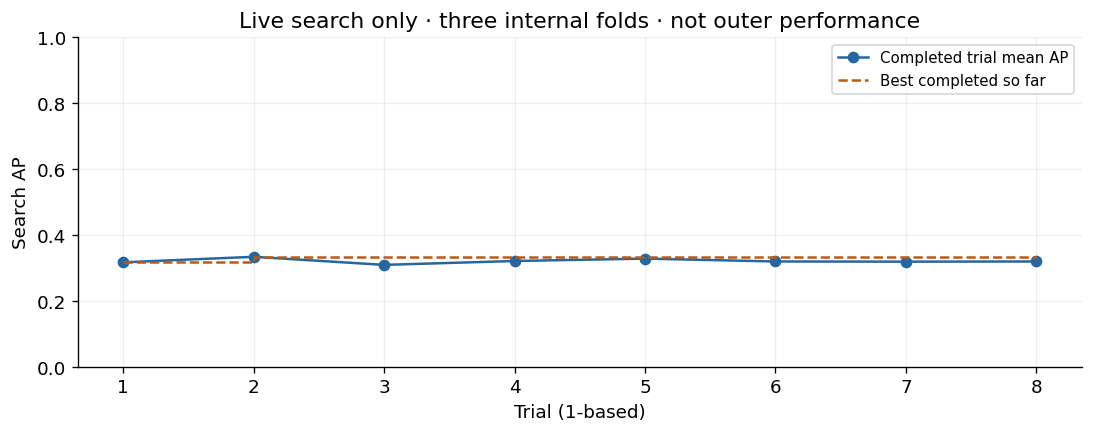

In [23]:
search, history = tune_on_reserved_pool(pool, contract, config)
has_tuned = search["best_params"] is not None
display(pd.DataFrame([{key: search[key] for key in ["status", "completed_trials", "attempted_trials",
    "elapsed_seconds", "stopping_reason", "best_tuning_ap"]}]))
display(pd.DataFrame(search["fold_audits"]))
display(history)
if not has_tuned:
    example = pd.read_csv(ROOT / "data/day2_optuna_example.csv")
    example_info = json.loads((ROOT / "data/day2_optuna_example.json").read_text(encoding="utf-8"))
    assert example_info["source"] == "EDUCATIONAL_EXAMPLE"
    print("EDUCATIONAL_EXAMPLE — discussion only; not your run or submission. TUNING_REQUIRED.")
    display(example)
else:
    print("Frozen search parameters:", search["best_params"])

fig, ax = plt.subplots(figsize=(9, 3.5), constrained_layout=True)
completed = history[history.state.eq("COMPLETE")]
if len(completed):
    ax.plot(completed.trial + 1, completed.mean_ap, marker="o", color="#2667A0", label="Completed trial mean AP")
    ax.step(completed.trial + 1, completed.mean_ap.cummax(), where="post", color="#BA5A17",
            linestyle="--", label="Best completed so far")
    ax.legend(fontsize=9)
else:
    ax.text(.5, .5, "No completed live trials — rerun needed", transform=ax.transAxes, ha="center")
ax.set(xlabel="Trial (1-based)", ylabel="Search AP", ylim=(0, 1), xticks=range(1, config.trials+1),
       title="Live search only · three internal folds · not outer performance")
fig.savefig(ARTIFACTS / "day2_search.png", dpi=160)

print("setting combination with the highest AP gets chosen: whihc is trial 1")
plt.show()

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>6. Compare only after search is frozen</h2>
<p>Every protocol uses LightGBM, but the data protocol changes:</p>
<table><tr><th>Protocol</th><th>Purpose</th></tr><tr><td>Leaky random control</td><td>Deliberately uses two post-outcome fields and all-row imputation; unsafe negative control</td></tr><tr><td>Clean random control</td><td>Uses eligible fields and training-only imputation but still mixes time and customers; unsafe for decisions</td></tr><tr><td>Honest fixed</td><td>Uses forward mature-label, customer-purged folds with the fixed base parameters and 80 trees</td></tr><tr><td>Honest reserved search</td><td>Uses the same honest outer folds with parameters frozen on the separate search cohort and internal tree selection</td></tr></table>
<p>The random protocols cover 10,000 requests; the time-based protocols cover 5,039 later eligible requests and use different training sizes. Gaps are descriptive and combine period, population and data-availability differences. They are not isolated causal estimates of leakage.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>6. قارن بعد تجميد البحث</h2>
<p>تستخدم جميع البروتوكولات LightGBM، لكن بروتوكول البيانات يتغير:</p>
<table><tr><th>البروتوكول</th><th>الغرض</th></tr><tr><td>Leaky random control</td><td>يستخدم عمدًا خاصيتين بعد النتيجة وتعويضًا من كامل البيانات؛ ضابط سلبي غير آمن</td></tr><tr><td>Clean random control</td><td>يستخدم الخصائص المؤهلة وتعويض التدريب فقط، لكنه يخلط الزمن والعملاء؛ غير صالح للقرار</td></tr><tr><td>Honest fixed</td><td>يستخدم طيات زمنية ناضجة الأهداف ومستبعدة العملاء مع الإعداد الأساسي الثابت و80 شجرة</td></tr><tr><td>Honest reserved search</td><td>يستخدم الطيات الخارجية الصادقة نفسها مع معاملات مجمدة من مجموعة البحث واختيار داخلي لعدد الأشجار</td></tr></table>
<p>تغطي البروتوكولات العشوائية 10,000 طلب، بينما تغطي البروتوكولات الزمنية 5,039 طلبًا لاحقًا مؤهلًا وبأحجام تدريب مختلفة. الفروق وصفية وتجمع اختلافات الفترة والسكان والبيانات المتاحة، وليست تقديرًا سببيًا مستقلًا للتسرب.</p>
</td>
</tr>
</table>

In [24]:
controls = negative_controls(clean, dirty, contract, config)
fixed_report, fixed_oof, fixed_origin = evaluate_outer(
    clean, contract, folds, BASE_PARAMS, config, "clean_time_group_fixed", fixed_trees=80)
reports, predictions, origins = [controls, fixed_report], [fixed_oof], fixed_origin
if has_tuned:
    tuned_report, tuned_oof, tuned_origin = evaluate_outer(
        clean, contract, folds, search["best_params"], config, "clean_time_group_tuned")
    reports.append(tuned_report); predictions.append(tuned_oof); origins += tuned_origin
validation_report = pd.concat(reports, ignore_index=True)
summary = summarize_folds(validation_report)
oof = pd.concat(predictions, ignore_index=True)
assert not oof.duplicated(["scheme", "application_id"]).any()
display(summary.round(4))
display(validation_report[["scheme", "fold", "roc_auc", "average_precision", "train_rows",
    "validation_rows", "selected_trees", "shared_customers", "prediction_source"]].round(4))
gaps = summary.set_index("scheme")
print("Observed AP gap, leaky minus clean random:",
      round(gaps.loc["leaky_random_control", "ap_mean"] - gaps.loc["clean_random_control", "ap_mean"], 4))
print("Observed AP gap, clean random minus honest fixed:",
      round(gaps.loc["clean_random_control", "ap_mean"] - gaps.loc["clean_time_group_fixed", "ap_mean"], 4))

,scheme,folds,validation_rows,roc_auc_mean,roc_auc_sd,ap_mean,ap_sd
0,leaky_random_control,3,10000,0.9999,0.0002,0.9988,0.0014
1,clean_random_control,3,10000,0.8010,0.0200,0.3110,0.0293
2,clean_time_group_fixed,3,5039,0.7976,0.0206,0.3153,0.0426
3,clean_time_group_tuned,3,5039,0.7855,0.0232,0.3133,0.0259


,scheme,fold,roc_auc,average_precision,train_rows,validation_rows,selected_trees,shared_customers,prediction_source
0,leaky_random_control,1,0.9996,0.9973,6666,3334,80,1713,NEGATIVE_CONTROL_NOT_FOR_DECISIONS
1,clean_random_control,1,0.7807,0.2776,6666,3334,80,1713,NEGATIVE_CONTROL_NOT_FOR_DECISIONS
2,leaky_random_control,2,0.9999,0.9992,6667,3333,80,1675,NEGATIVE_CONTROL_NOT_FOR_DECISIONS
3,clean_random_control,2,0.8018,0.3232,6667,3333,80,1675,NEGATIVE_CONTROL_NOT_FOR_DECISIONS
4,leaky_random_control,3,1.0000,1.0000,6667,3333,80,1656,NEGATIVE_CONTROL_NOT_FOR_DECISIONS
5,clean_random_control,3,0.8206,0.3321,6667,3333,80,1656,NEGATIVE_CONTROL_NOT_FOR_DECISIONS
6,clean_time_group_fixed,1,0.7948,0.3395,3223,1632,80,0,LIVE_OUT_OF_FOLD
7,clean_time_group_fixed,2,0.8194,0.3403,4460,1674,80,0,LIVE_OUT_OF_FOLD
8,clean_time_group_fixed,3,0.7786,0.2661,5731,1733,80,0,LIVE_OUT_OF_FOLD
9,clean_time_group_tuned,1,0.7826,0.3356,3223,1632,24,0,LIVE_OUT_OF_FOLD


Observed AP gap, leaky minus clean random: 0.6879
Observed AP gap, clean random minus honest fixed: -0.0044


<table style="width:100%; border-collapse:collapse;">


<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Read mean and variation together</h2>
<p>The reported score is the unweighted mean across three folds. Error bars show the sample standard deviation with <code>ddof=1</code>.</p>
<ul><li>The folds are related time periods, not three independent experiments.</li><li>The error bar is not a confidence interval and not a significance test.</li><li>AP means <strong>Average Precision</strong>, not trapezoidal area under the precision–recall curve.</li><li>Read fold size, positive rate and coverage beside the headline metrics.</li></ul>
<p>Selected tree counts or the last decimal places can differ across systems even with pinned versions. Do not repeat search because an outer-validation number is disappointing; repeated selection on outer folds converts them into development data.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>اقرأ المتوسط والتشتت معًا</h2>
<p>الدرجة المعروضة هي المتوسط غير الموزون للطيات الثلاث. وتمثل أشرطة الخطأ الانحراف المعياري العيّني باستخدام <code>ddof=1</code>.</p>
<ul><li>الطيات فترات زمنية مترابطة وليست ثلاث تجارب مستقلة.</li><li>شريط الخطأ ليس فترة ثقة ولا اختبار دلالة.</li><li>يشير AP إلى <strong>Average Precision</strong> وليس المساحة شبه المنحرفة تحت منحنى precision–recall.</li><li>اقرأ حجم الطية ونسبة الفئة الموجبة والتغطية بجانب المقاييس الرئيسية.</li></ul>
<p>قد يختلف عدد الأشجار المختار أو آخر المنازل العشرية بين الأنظمة رغم تثبيت الإصدارات. لا تُعد البحث لأن رقم التحقق الخارجي لم يعجبك؛ فالاختيار المتكرر على الطيات الخارجية يحولها إلى بيانات تطوير.</p>
</td>
</tr>
</table>

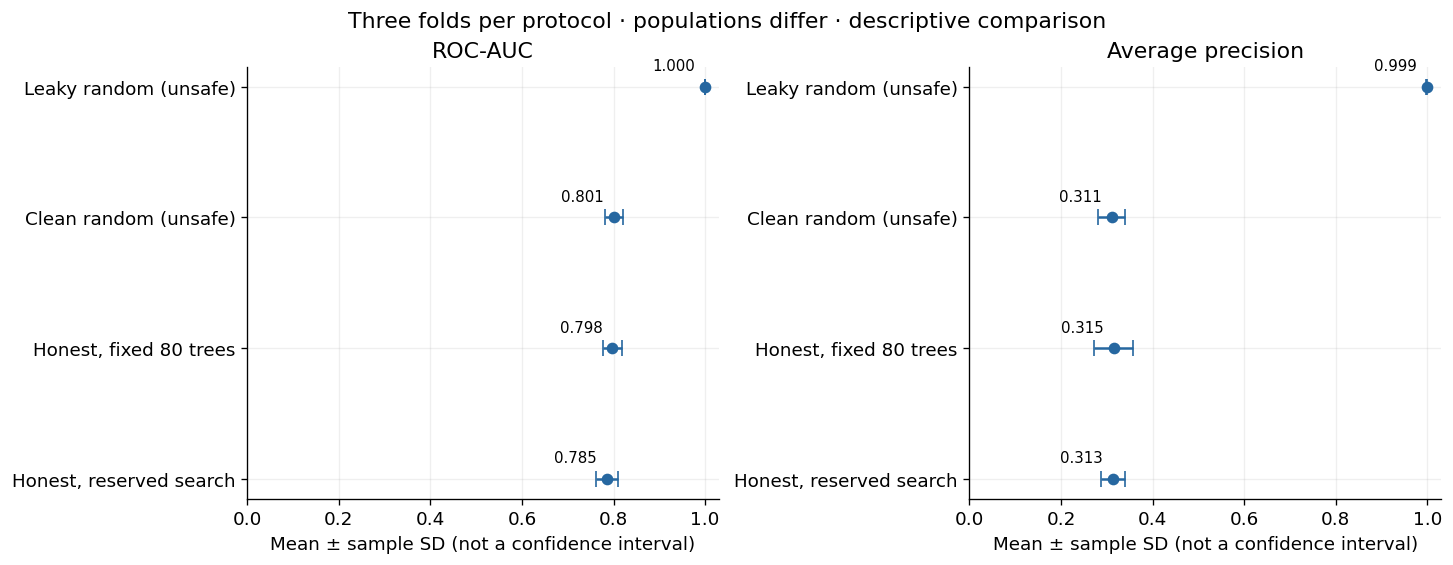

In [25]:
labels = {"leaky_random_control": "Leaky random (unsafe)", "clean_random_control": "Clean random (unsafe)",
          "clean_time_group_fixed": "Honest, fixed 80 trees", "clean_time_group_tuned": "Honest, reserved search"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
y = np.arange(len(summary))
for ax, mean_col, sd_col, title in zip(axes, ["roc_auc_mean", "ap_mean"], ["roc_auc_sd", "ap_sd"], ["ROC-AUC", "Average precision"]):
    ax.errorbar(summary[mean_col], y, xerr=summary[sd_col], fmt="o", capsize=5, color="#2667A0")
    ax.set(yticks=y, yticklabels=[labels[s] for s in summary.scheme], xlim=(0, 1.03),
           xlabel="Mean ± sample SD (not a confidence interval)", title=title)
    ax.invert_yaxis()
    for row, value in enumerate(summary[mean_col]):
        ax.annotate(f"{value:.3f}", (value, row), xytext=(-6, 10), textcoords="offset points", ha="right", fontsize=9)
fig.suptitle("Three folds per protocol · populations differ · descriptive comparison")
fig.savefig(ARTIFACTS / "day2_validation_comparison.png", dpi=160)
plt.show()

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>7. Verify out-of-fold coverage</h2>
<p>Every saved probability is generated for an application outside the corresponding fold's training rows after its internal choices are fixed.</p>
<ul><li>Each successful honest scheme produces 5,039 OOF probabilities.</li><li>The remaining 4,961 applications are warm-up rows without OOF predictions.</li><li>Coverage is 50.39% of all clean training rows and 100% of requests eligible from 2023-07-01 onward.</li><li>Do not fill warm-up rows with training predictions or artificial probabilities.</li><li>Do not export the leaky-control predictions for later decision work.</li></ul>
<p>This OOF set is not an independent final test and does not guarantee fairness or calibration. Preserve each row's role so later decisions use declared coverage.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>7. تحقّق من تغطية OOF</h2>
<p>يُنتج كل احتمال محفوظ لطلب خارج صفوف تدريب الطية المقابلة بعد تثبيت خياراتها الداخلية.</p>
<ul><li>ينتج كل إعداد صادق ناجح 5,039 احتمال OOF.</li><li>تبقى الطلبات البالغ عددها 4,961 صفوف تمهيد بلا تنبؤات OOF.</li><li>تبلغ التغطية 50.39% من جميع صفوف التدريب النظيفة و100% من الطلبات المؤهلة بدءًا من 2023-07-01.</li><li>لا تملأ صفوف التمهيد بتنبؤات التدريب أو احتمالات مصطنعة.</li><li>لا تصدّر تنبؤات الضابط المتسرب لأعمال القرار اللاحقة.</li></ul>
<p>لا تمثل مجموعة OOF اختبارًا نهائيًا مستقلًا، ولا تضمن العدالة أو المعايرة. احتفظ بدور كل صف حتى تُبنى القرارات اللاحقة على تغطية معلنة.</p>
</td>
</tr>
</table>

In [26]:
coverage = clean[["application_id", "application_date"]].copy()
coverage["role"], coverage["fold"] = "warmup_no_oof", 0
for fold in folds:
    coverage.loc[fold["valid"], "role"] = "eligible_oof"
    coverage.loc[fold["valid"], "fold"] = fold["audit"]["fold"]
eligible_ids = set(coverage.loc[coverage.role.eq("eligible_oof"), "application_id"])
for scheme, group in oof.groupby("scheme"):
    assert set(group.application_id) == eligible_ids
    assert group.probability.between(0, 1).all()
display(pd.DataFrame([{"all_rows": len(clean), "eligible_rows": len(eligible_ids),
    "warmup_without_oof": len(clean)-len(eligible_ids), "whole_data_coverage": len(eligible_ids)/len(clean),
    "eligible_coverage": 1.0, "live_honest_schemes": oof.scheme.nunique()}]))

,all_rows,eligible_rows,warmup_without_oof,whole_data_coverage,eligible_coverage,live_honest_schemes
0,10000,5039,4961,0.5039,1.0,2


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>8. Write your own validation argument</h2>
<p>Complete the shared response dictionary in your own words, then rerun the response and export cells:</p>
<ol><li>Name one leaked field and explain why its information was unavailable at application time.</li><li>Justify time ordering, customer separation and the strict 90-day maturity rule.</li><li>Cite two numerical gaps from your validation table and explain why they do not prove universal superiority.</li><li>Explain why imputation is learned inside training and what the inner stopping set controls.</li><li>State one search-budget limitation and one OOF-coverage or fold-dependence limitation.</li></ol>
<p>The checkpoint detects missing fields only. It does not write your answer, judge correctness, award a grade or prove authorship.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>8. اكتب حجتك الخاصة للتحقق</h2>
<p>أكمل قاموس الإجابات المشترك بصياغتك أنت، ثم أعد تشغيل خلية الإجابات وخلية التصدير:</p>
<ol><li>اذكر خاصية متسربة، واشرح لماذا لم تكن معلومتها متاحة وقت تقديم الطلب.</li><li>برر ترتيب الزمن وفصل العملاء وقاعدة نضج الهدف الصارمة لمدة 90 يومًا.</li><li>استشهد بفجوتين رقميتين من جدول التحقق، واشرح لماذا لا تثبتان تفوقًا عامًا.</li><li>اشرح لماذا يُتعلم التعويض داخل التدريب وما الذي يتحكم فيه جزء الإيقاف الداخلي.</li><li>اذكر قيدًا في ميزانية البحث وقيدًا في تغطية OOF أو اعتماد الطيات.</li></ol>
<p>يفحص الحارس اكتمال الخانات فقط؛ لا يكتب إجابتك، ولا يحكم على صحتها، ولا يمنح درجة، ولا يثبت الملكية.</p>
</td>
</tr>
</table>

In [27]:
responses = {"leak_example": "The 'days_past_due_60' field is a leaked field as this field lets us know whether an applicant was 60 days late on a payment. This information is not available at applictaion time as it happens in the future and becomes avaiable after the application.",
             "split_reason": "Time ordering is used to seperate the applications and ensure the model learns from past applications and is tested on the newer ones to prevent time-leakage; customer separation was done to prevent the model from knwoing the training customers in the validation stage and making the model untrsutworthy; the strict 90 day maturity rule was becasue we needed the 90 days to know wether the applictaion defaulted within that time period for the trainign data",
             "observed_gap": "The observed AP gap, leaky minus clean random: 0.6879  does not prove that it is better as it was given all the data past and future and thus no actual wokr was done by the model, and the observed AP gap, clean random minus honest fixed: -0.0044: does not prove universal superiority as they were tested on different groups and different time periods and that is not a fair comparison",
             "imputer_reason": "Imputation is learned inside training due to the fact that the missing values are filled using the training data only, so the validation data isnt inlfuenced by the model; innner stopping set controls  are used to choose how many trees are selected based on the inner-stop log loss",
             "limitations": "the OOF -coverage limitation is due to the fact that the OOF predictions cover 5,039 /10,000 applications and the rest of the application doen't a chnace at a fair OOF prediction, as for the search limitation the model had to stick to 8 settings trial limit"}
checkpoint = reflection_check(responses)
print(checkpoint["status"])
print("Missing:", checkpoint["missing"])

READY_FOR_REVIEW
Missing: []


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>9. Export evidence and preserve provenance</h2>
<p>The export cell writes the validation tables, search record, audits, OOF predictions and coverage, provenance, reflection, run metadata, three figures and <code>environment.json</code>, then creates <code>day2_artifacts.zip</code>.</p>
<p>Download the ZIP from <strong>Files → tamweel → artifacts</strong>, extract it and upload the actual files to your repository's <code>artifacts/</code> directory. Save the executed notebook as <code>notebooks/02_validation_tuning.ipynb</code>.</p>
<ul><li><code>TECHNICAL_READY</code>: execution and at least one live tuning trial completed.</li><li><code>TUNING_REQUIRED</code>: no live trial completed; rerun is required.</li><li><code>LEARNER_WORK_REQUIRED</code>: technical work exists, but your written fields are incomplete.</li><li><code>READY_FOR_REVIEW</code>: required fields are present; this is not a grade or correctness guarantee.</li></ul>
<p>Saving again replaces this day's artifact names. Preserve a copy before rerunning. Never upload credentials, access tokens or personal data.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>9. صدّر الأدلة واحتفظ بمصدرها</h2>
<p>تكتب خلية التصدير جداول التحقق وسجل البحث والتدقيقات وتنبؤات OOF وتغطيتها ومصدر التدريب والتفسير وبيانات التشغيل وثلاثة رسوم و<code>environment.json</code>، ثم تنشئ <code>day2_artifacts.zip</code>.</p>
<p>نزّل الحزمة من <strong>Files → tamweel → artifacts</strong>، وافكها، وارفع الملفات الفعلية إلى مجلد <code>artifacts/</code> في مستودعك. واحفظ الدفتر المنفذ باسم <code>notebooks/02_validation_tuning.ipynb</code>.</p>
<ul><li><code>TECHNICAL_READY</code>: نجح التنفيذ واكتملت تجربة ضبط فعلية واحدة على الأقل.</li><li><code>TUNING_REQUIRED</code>: لم تكتمل تجربة فعلية؛ يلزم إعادة التشغيل.</li><li><code>LEARNER_WORK_REQUIRED</code>: توجد الأدلة التقنية، لكن حقولك الكتابية غير مكتملة.</li><li><code>READY_FOR_REVIEW</code>: الحقول المطلوبة موجودة؛ ولا تمثل درجة أو ضمانًا لصحة التفسير.</li></ul>
<p>يستبدل الحفظ المتكرر أسماء ملفات هذا اليوم. احتفظ بنسخة قبل إعادة التشغيل. لا ترفع بيانات اعتماد أو رموز وصول أو بيانات شخصية.</p>
</td>
</tr>
</table>

In [28]:
checkpoint = reflection_check(responses)
technical_status = "TECHNICAL_READY" if has_tuned else "TUNING_REQUIRED"
csv_outputs = {"validation_report.csv": validation_report, "validation_summary.csv": summary,
    "optuna_results.csv": history, "leakage_audit.csv": audit, "fold_audit.csv": fold_audit,
    "day2_oof_predictions.csv": oof, "day2_oof_coverage.csv": coverage}
for filename, table in csv_outputs.items():
    table.to_csv(ARTIFACTS / filename, index=False)
run = {"technical_status": technical_status, "learner_status": checkpoint["status"],
    "data_revision": COURSE_REVISION, "lab_revision": LAB_REVISION, "support_sha256": SUPPORT_HASHES,
    "data_manifest_sha256": MANIFEST_SHA256,
    "dirty_data_sha256": hashlib.sha256((ROOT / "data/tamweel_dirty.csv").read_bytes()).hexdigest(),
    "config": asdict(config), "mode": "FAST" if FAST_MODE else "FULL", "python": platform.python_version(),
    "duplicates": duplicates, "removed_features": leaked_features,
    "oof_rows_per_scheme": {name: len(group) for name, group in oof.groupby("scheme")},
    "oof_whole_data_coverage": len(eligible_ids)/len(clean), "warmup_rows": len(clean)-len(eligible_ids),
    "search_source": "LIVE", "example_used_for_results": False,
    "challenge_used_for_modeling": False, "grading": "No automatic grade"}
json_outputs = {"best_params.json": search, "day2_provenance.json": origins,
                "day2_reflection.json": {"responses": responses, "checkpoint": checkpoint}, "day2_run.json": run}
for filename, payload in json_outputs.items():
    (ARTIFACTS / filename).write_text(json.dumps(payload, ensure_ascii=False, indent=2), encoding="utf-8")
files = list(csv_outputs) + list(json_outputs) + ["day2_fold_sizes.png", "day2_search.png",
    "day2_validation_comparison.png", "environment.json"]
with zipfile.ZipFile(ARTIFACTS / "day2_artifacts.zip", "w", zipfile.ZIP_DEFLATED) as archive:
    for filename in files:
        assert (ARTIFACTS / filename).is_file(), filename
        archive.write(ARTIFACTS / filename, arcname=filename)
print(technical_status, "|", checkpoint["status"])
print(f"Saved {len(files)} files in day2_artifacts.zip | احفظ الدفتر وملفاتك ثم أكمل تفسيرك")

TECHNICAL_READY | READY_FOR_REVIEW
Saved 15 files in day2_artifacts.zip | احفظ الدفتر وملفاتك ثم أكمل تفسيرك


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Completion checkpoint and next step</h2>
<ul><li>You can identify the removed post-outcome fields and explain their availability time.</li><li>Each fold shows zero shared customers and mature training labels before validation starts.</li><li>You can distinguish attempted, completed, pruned and failed search trials.</li><li>You read fold means, sample standard deviations, population differences and OOF coverage together.</li></ul>
<p><strong>Before presenting results:</strong> show one leakage example, point to evidence of customer separation and label maturity, distinguish mean fold AP from pooled AP, and state the result's limits beside the score.</p>
<p><strong>References:</strong> scikit-learn cross-validation and preprocessing-leakage guidance, LightGBM early stopping and Optuna bounded-study documentation linked in the course guide.</p>
<p><strong>Day 3:</strong> use the honest validation foundation to examine simulated decision costs, thresholds and the consequences of false approvals and false declines.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>نقطة الإكمال والخطوة التالية</h2>
<ul><li>تستطيع تحديد خصائص ما بعد النتيجة المحذوفة وشرح زمن إتاحة معلوماتها.</li><li>تُظهر كل طية صفر عملاء مشتركين ونضج أهداف التدريب قبل بدء التحقق.</li><li>تستطيع التمييز بين محاولات البحث والمكتمل منها والموقوفة والفاشلة.</li><li>تقرأ متوسطات الطيات والانحرافات المعيارية العيّنية واختلاف السكان وتغطية OOF معًا.</li><li>أكملت الإجابات الخمس التي يملكها المتدرب، وحفظت الدفتر المنفذ وحزمة الأدلة خارج الجلسة المؤقتة.</li></ul>
<p><strong>قبل عرض النتائج:</strong> اعرض مثالًا للتسرب، وأشر إلى دليل فصل العملاء ونضج الهدف، وميّز بين متوسط AP عبر الطيات وAP بعد جمع الاحتمالات، وضع حدود النتيجة بجانب الدرجة.</p>
<p><strong>المراجع:</strong> إرشادات scikit-learn للتحقق ومنع تسرب المعالجة، وتوثيق LightGBM للإيقاف المبكر، وتوثيق Optuna للبحث المحدود، وكلها مرتبطة في دليل الدورة.</p>
<p><strong>اليوم الثالث:</strong> استخدم أساس التحقق الصادق لفحص تكاليف القرار التعليمية والعتبات وآثار الموافقات الخاطئة والرفض الخاطئ.</p>
</td>
</tr>
</table>

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Daily question · Honest validation</h2>
<p><strong>What leakage risk did you identify, and how did the validation design prevent it?</strong><br><br>Write a short answer under <code>Day 2</code> in the <code>Daily answers | الإجابات اليومية</code> section of your repository README. Then download this executed notebook and the required generated files and upload them on the same day.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>سؤال اليوم · التحقق الصادق</h2>
<p><strong>ما خطر التسرب الذي اكتشفته، وكيف منعه تصميم التحقق؟</strong><br><br>اكتب إجابة مختصرة تحت <code>Day 2 | اليوم 2</code> في قسم <code>Daily answers | الإجابات اليومية</code> داخل README في مستودعك، ثم نزّل هذا الدفتر بعد التنفيذ وملفات النتائج المطلوبة وارفعها في اليوم نفسه.</p>
</td>
</tr>
</table>

---
# Gate 3: Cost-sensitive decision

_Executed notebook `notebooks/03_cost_sensitive_decision.ipynb`._

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Day 3 · Choose a decision threshold you can defend</h2>
<p><strong>SDA-DSC-211 · Tamweel Lite · 60-minute lab · Free CPU</strong></p>
<p>Compare unweighted training, class weighting and training-only oversampling on the same honest out-of-fold rows. Convert model scores into simulated review flags using an explicit error-loss policy and a capacity ceiling for every validation period.</p>
<p><strong>Deliverables:</strong> model and threshold comparisons, a cost curve, exact threshold JSON, period-capacity and regional audits, sensitivity scenarios, provenance, your written reasoning and <code>reports/DECISION_CARD.md</code>.</p>
<p><strong>Decision boundary:</strong> a flag means simulated review, not automatic approval or refusal. Loss values are educational decision units, not Saudi riyals, fees, expected credit loss or grade deductions. Threshold selection uses development OOF labels and is not a final independent test.</p>
<table><tr><th>Minutes</th><th>Your task</th></tr><tr><td>0–10</td><td>Freeze the loss and capacity policy</td></tr><tr><td>10–20</td><td>Generate OOF evidence for three strategies</td></tr><tr><td>20–35</td><td>Compare ranking and sweep thresholds</td></tr><tr><td>35–45</td><td>Audit capacity in every period</td></tr><tr><td>45–50</td><td>Inspect cost sensitivity</td></tr><tr><td>50–55</td><td>Review descriptive regional differences</td></tr><tr><td>55–60</td><td>Write and export the decision card</td></tr></table>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>اليوم الثالث · اختر عتبة قرار تستطيع تبريرها</h2>
<p><strong>SDA-DSC-211 · Tamweel Lite · لاب 60 دقيقة · CPU مجاني</strong></p>
<p>قارن التدريب غير الموزون ووزن الفئة وإعادة أخذ العينات داخل التدريب فقط على صفوف OOF الصادقة نفسها. ثم حوّل درجات النموذج إلى إشارات مراجعة محاكاة باستخدام سياسة معلنة لخسارة الأخطاء وسقف سعة لكل فترة تحقق.</p>
<p><strong>المخرجات:</strong> مقارنات النماذج والعتبات، ومنحنى التكلفة، وملف JSON للعتبة الدقيقة، وتدقيق السعة والمناطق، وسيناريوهات الحساسية، ومصدر التنفيذ، وتفسيرك المكتوب، وملف <code>reports/DECISION_CARD.md</code>.</p>
<p><strong>حد القرار:</strong> الإشارة تعني مراجعة محاكاة، ولا تعني قبولًا أو رفضًا آليًا. قيم الخسارة وحدات قرار تعليمية، وليست ريالات سعودية أو رسومًا أو خسارة ائتمانية متوقعة أو خصمًا من الدرجة. اختيار العتبة يستخدم أهداف OOF التطويرية، وليس اختبارًا نهائيًا مستقلًا.</p>
<table><tr><th>الدقائق</th><th>مهمتك</th></tr><tr><td>0–10</td><td>ثبّت سياسة الخسارة والسعة</td></tr><tr><td>10–20</td><td>أنشئ أدلة OOF للاستراتيجيات الثلاث</td></tr><tr><td>20–35</td><td>قارن الترتيب وامسح العتبات</td></tr><tr><td>35–45</td><td>دقّق السعة في كل فترة</td></tr><tr><td>45–50</td><td>افحص حساسية التكلفة</td></tr><tr><td>50–55</td><td>راجع الفروق الوصفية بين المناطق</td></tr><tr><td>55–60</td><td>اكتب بطاقة القرار وصدّرها</td></tr></table>
</td>
</tr>
</table>

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Official daily requirement</h2>
<p>Run all cells, compare the generated files with EXPECTED_RESULTS.md, then answer only the single question at the end of this notebook in your repository README. Legacy reflection variables inside code cells are compatibility fields; leave them unchanged.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>المطلوب اليومي المعتمد</h2>
<p>شغّل جميع الخلايا، وقارن الملفات الناتجة بصفحة EXPECTED_RESULTS.md، ثم أجب فقط عن السؤال الواحد في نهاية هذا الدفتر داخل README في مستودعك. حقول الانعكاس القديمة داخل خلايا الكود مخصصة للتوافق؛ اتركها دون تعديل.</p>
</td>
</tr>
</table>

In [23]:
import importlib.metadata as metadata
import os
import signal
import subprocess
import sys

EXPECTED_VERSIONS = {
    "numpy": "2.1.3",
    "pandas": "2.2.3",
    "scipy": "1.16.3",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "xgboost": "3.4.1",
    "lightgbm": "4.6.0",
    "shap": "0.52.0",
    "numba": "0.61.2",
    "optuna": "4.5.0",
}

different_versions = []

for package_name, expected_version in EXPECTED_VERSIONS.items():
    try:
        current_version = metadata.version(package_name)
    except metadata.PackageNotFoundError:
        current_version = None

    if current_version != expected_version:
        different_versions.append(
            f"{package_name}: {current_version or 'غير مثبت'} → {expected_version}"
        )

if different_versions:
    print("سيتم تجهيز بيئة الدورة بالإصدارات المعتمدة:")
    for item in different_versions:
        print("-", item)

    requirements_url = (
        "https://raw.githubusercontent.com/"
        "almiyead-rgb/sda-dsc-211-student-template/"
        "fe0c0204e6076a7ac2139b7336485a097343fb8a/"
        "requirements-colab.txt"
    )

    constraints_url = (
        "https://raw.githubusercontent.com/"
        "almiyead-rgb/sda-dsc-211-student-template/"
        "fe0c0204e6076a7ac2139b7336485a097343fb8a/"
        "constraints.txt"
    )

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "--quiet",
        "--disable-pip-version-check",
        "-r",
        requirements_url,
        "-c",
        constraints_url,
    ])

    print(
        "\nتم تثبيت بيئة الدورة بنجاح.\n"
        "ستتم إعادة تشغيل الجلسة الآن بصورة تلقائية.\n"
        "بعد عودة الاتصال اختَر Runtime → Run all مرة أخرى."
    )

    os.kill(os.getpid(), signal.SIGKILL)

else:
    print("بيئة الدورة جاهزة، ويمكن متابعة تشغيل Notebook.")


بيئة الدورة جاهزة، ويمكن متابعة تشغيل Notebook.


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>1. Prepare a controlled environment</h2>
<p>Open a fresh session, select the free CPU runtime and choose <strong>Runtime → Run all</strong>. Setup verifies pinned versions, data hashes and support files before training.</p>
<ul><li><code>FAST_MODE=True</code>: 80 trees per model and two CPU threads; use this first.</li><li><code>FULL_MODE=True</code>: optional 160-tree cap.</li><li>The Day 2 time/customer split is rebuilt from source; no previous notebook output is required.</li><li>No GPU, API key, Drive mount, paid package or external service is required.</li></ul>
<p>Tree count is frozen before comparing imbalance treatments. Do not tune again after reading today’s OOF results. If setup requests a restart, restart the session and run from the beginning.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>1. جهّز بيئة تشغيل محكومة</h2>
<p>افتح جلسة جديدة، واختر CPU المجاني، ثم نفّذ <strong>Runtime → Run all</strong>. يتحقق الإعداد من الإصدارات المثبتة وبصمات البيانات وملفات الدعم قبل التدريب.</p>
<ul><li><code>FAST_MODE=True</code>: عدد 80 شجرة لكل نموذج وخيطا CPU؛ ابدأ به.</li><li><code>FULL_MODE=True</code>: سقف اختياري قدره 160 شجرة.</li><li>يعاد بناء تقسيم الزمن والعملاء من اليوم الثاني من المصدر؛ لا تحتاج إلى مخرجات دفتر سابق.</li><li>لا تحتاج إلى GPU أو مفتاح API أو ربط Drive أو حزمة مدفوعة أو خدمة خارجية.</li></ul>
<p>يُثبّت عدد الأشجار قبل مقارنة طرق عدم التوازن. لا تعِد الضبط بعد قراءة نتائج OOF اليوم. إذا طلب الإعداد إعادة التشغيل، أعد الجلسة ثم شغّل الدفتر من البداية.</p>
</td>
</tr>
</table>

In [24]:
from pathlib import Path
import hashlib, importlib.util, os, runpy, sys, time, urllib.request, urllib.error

RUN_STARTED = time.perf_counter()
COURSE_REVISION = "fe0c0204e6076a7ac2139b7336485a097343fb8a"
MANIFEST_SHA256 = "86d15e813caf833b7d86512808176388d4123dc3c01c6525ee849a76e8322c59"
SETUP_SHA256 = "79608f8f9559d9e6eb09d51ee541ee12d7e9262ac57d1ca3a948c8ecb14f0f35"
IN_COLAB = importlib.util.find_spec("google") is not None and importlib.util.find_spec("google.colab") is not None
ROOT = Path("/content/tamweel") if IN_COLAB else Path(os.environ.get("TAMWEEL_PROJECT_DIR", ".")).resolve()
setup_path = ROOT / "scripts/setup_colab.py"
setup_path.parent.mkdir(parents=True, exist_ok=True)
if not setup_path.exists() or hashlib.sha256(setup_path.read_bytes()).hexdigest() != SETUP_SHA256:
    setup_url = f"https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template/{COURSE_REVISION}/scripts/setup_colab.py"
    for attempt in range(3):
        try:
            with urllib.request.urlopen(setup_url, timeout=45) as response:
                setup_bytes = response.read(200000)
            if hashlib.sha256(setup_bytes).hexdigest() != SETUP_SHA256:
                raise ValueError("Setup checksum mismatch. Reopen the released notebook.")
            setup_path.write_bytes(setup_bytes)
            break
        except (urllib.error.URLError, TimeoutError):
            if attempt == 2:
                raise RuntimeError("Download unavailable. Retry setup or upload the unchanged project files; see READINESS_GUIDE.")
            time.sleep(attempt + 1)
environment = runpy.run_path(str(setup_path))["prepare"](ROOT, COURSE_REVISION, MANIFEST_SHA256)
FAST_MODE, FULL_MODE, SEED, N_JOBS = True, False, 211, 2

from setup_colab import fetch_verified
DAY2_REVISION = "1e1da4acbee8941bef07245b259fb6c27ced4ad7"
DAY2_SHA256 = "d2fd0353330c3629bdaed6c570528792955fce232540a85d33532a9432522f43"
fetch_verified(f"https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template/{DAY2_REVISION}/scripts/day2_validation.py",
               ROOT / "scripts/day2_validation.py", DAY2_SHA256)
LAB_REVISION = "c2dc52e129878d0d487db1874891c658de7c4d0d"
SUPPORT_HASHES = {'scripts/day3_decision.py': '40f176633c91fc530db222978bc44495a401b888b1ce448728948f7ae0ca9e12', 'data/day3_oof_example.csv': '659952bef85ac3b7ceb7ab84eb2102de6c9b433a1ba122cd57df96581baf0eb3', 'data/day3_oof_example.json': '920cf9830043afcc83f8c276c8945677296eb3c49a6e69326d47f6080a9e7fad'}
for relative, digest in SUPPORT_HASHES.items():
    fetch_verified(f"https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template/{LAB_REVISION}/{relative}",
                   ROOT / relative, digest)
print("Day 3 setup verified | إعداد اليوم الثالث جاهز")

Package                 Version
numpy                   2.1.3
pandas                  2.2.3
scipy                   1.16.3
scikit-learn            1.6.1
matplotlib              3.10.0
xgboost                 3.4.1
lightgbm                4.6.0
shap                    0.52.0
numba                   0.61.2
optuna                  4.5.0
Python 3.13.18 | CPU | seed=211 | n_jobs=2 | FAST_MODE=True
Verified course files. Next: run the data and compatibility checks.
Day 3 setup verified | إعداد اليوم الثالث جاهز


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>2. Freeze the teaching loss and capacity policy</h2>
<p>The target is a default event within 90 days after application. All records are synthetic, and challenge data remain closed.</p>
<table><tr><th>Outcome</th><th>Teaching meaning</th><th>Loss units</th></tr><tr><td>TP</td><td>Flag before a later default event</td><td>0</td></tr><tr><td>FN</td><td>Later default without a flag</td><td>10</td></tr><tr><td>FP</td><td>Flag on a non-default case</td><td>1</td></tr><tr><td>TN</td><td>Non-default case without a flag</td><td>0</td></tr></table>
<p><strong>Observed educational loss = 10 × FN + 1 × FP.</strong> Review cost and review effectiveness are omitted from this simplified policy.</p>
<p><strong>Capacity rule:</strong> flags must not exceed 12% of requests in <em>each</em> validation period, rounded down to a whole request. A pooled rate alone can hide overload in one period. Keep this policy fixed for the core exercise.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>2. ثبّت سياسة الخسارة والسعة التعليمية</h2>
<p>الهدف هو وقوع حدث تعثر خلال 90 يومًا بعد الطلب. جميع السجلات اصطناعية، وتبقى بيانات التحدي مغلقة.</p>
<table><tr><th>النتيجة</th><th>معناها التعليمي</th><th>وحدات الخسارة</th></tr><tr><td>TP</td><td>إشارة قبل حدث تعثر لاحق</td><td>0</td></tr><tr><td>FN</td><td>تعثر لاحق لم ترفع له إشارة</td><td>10</td></tr><tr><td>FP</td><td>إشارة لحالة لم تتعثر</td><td>1</td></tr><tr><td>TN</td><td>حالة سليمة بلا إشارة</td><td>0</td></tr></table>
<p><strong>الخسارة التعليمية المرصودة = 10 × FN + 1 × FP.</strong> لا تتضمن السياسة المبسطة تكلفة المراجعة أو فعاليتها.</p>
<p><strong>قاعدة السعة:</strong> يجب ألا تتجاوز الإشارات 12% من طلبات <em>كل</em> فترة تحقق، مع التقريب إلى العدد الصحيح الأدنى. قد تخفي النسبة المجمعة وحدها ازدحام فترة معينة. أبقِ السياسة ثابتة في التطبيق الأساسي.</p>
</td>
</tr>
</table>

In [25]:
import json, platform, zipfile
from dataclasses import asdict, replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
from IPython.display import display
from data_checks import validate_frame
from day2_validation import deduplicate_applications, make_time_group_split
from day3_decision import (STRATEGIES, TARGET, DecisionConfig, CostPolicy, generate_oof,
    validate_oof, threshold_sweep, select_threshold, flag_at, period_audit, region_audit,
    reflection_check, load_example, TrainingBudgetExpired)

contract = json.loads((ROOT / "data/data_contract.json").read_text(encoding="utf-8"))
train, duplicates = deduplicate_applications(pd.read_csv(ROOT / "data/tamweel_train.csv"))
validate_frame(train, contract, "train")
FAST_MODE, FULL_MODE = True, False
assert FAST_MODE != FULL_MODE
config = DecisionConfig(trees=80 if FAST_MODE else 160)
policy = CostPolicy(**contract["decision_policy"])
MODEL_FOR_DECISION = "weighted"  # Declared before comparison; not a claim of superiority.
USE_EXAMPLE = False  # True is discussion only, never your submission.
ASSESSMENT_MODE = os.environ.get("ASSESSMENT_MODE", "0") == "1"
assert MODEL_FOR_DECISION in STRATEGIES
ARTIFACTS, REPORTS = ROOT / "artifacts", ROOT / "reports"
ARTIFACTS.mkdir(exist_ok=True); REPORTS.mkdir(exist_ok=True)
folds = make_time_group_split(train, horizon_days=contract["target"]["horizon_days"])
display(pd.DataFrame([{"training_rows": len(train), "positive_rate": train[TARGET].mean(),
    "FN_loss_units": policy.false_negative_cost, "FP_loss_units": policy.false_positive_cost,
    "period_capacity_fraction": policy.max_flag_fraction, "trees_per_model": config.trees}]))
display(pd.DataFrame([fold["audit"] for fold in folds]))

,training_rows,positive_rate,FN_loss_units,FP_loss_units,period_capacity_fraction,trees_per_model
0,10000,0.0789,10,1,0.12,80


,fold,validation_start,validation_end_exclusive,train_rows,validation_rows,train_positives,validation_positives,immature_past_rows_removed,customer_overlap_rows_removed,shared_customers,latest_training_label_available
0,1,2023-07-01,2024-01-01,3223,1632,274,110,826,912,0,2023-06-30
1,2,2024-01-01,2024-07-01,4460,1674,353,135,785,1348,0,2023-12-31
2,3,2024-07-01,2025-01-01,5731,1733,465,139,861,1675,0,2024-06-30


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>3. Change training only, never validation</h2>
<p>All three LightGBM strategies use the same approved features, folds, tree budget and random seed:</p>
<table><tr><th>Strategy</th><th>Training change</th></tr><tr><td><code>unweighted</code></td><td>No row duplication or class weight</td></tr><tr><td><code>weighted</code></td><td><code>scale_pos_weight = negatives / positives</code> from that fold’s training rows only</td></tr><tr><td><code>oversampled</code></td><td>Randomly duplicate the minority class inside training until classes are balanced</td></tr></table>
<p>Missing-value imputation is learned from the original training rows before oversampling. Validation prevalence remains untouched. Class weighting changes model fitting; the FN/FP policy changes the downstream decision. They are not the same quantity.</p>
<p>Weighting and oversampling can distort probability calibration. Do not interpret a raw score of 0.70 as a reliable 70% probability before Day 4 calibration checks.</p>
<p>If the cooperative CPU budget expires, a labelled educational example may support discussion, but it is not a learner run and cannot be submitted. Assessment mode disables this fallback.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>3. غيّر التدريب فقط ولا تمس التحقق</h2>
<p>تستخدم استراتيجيات LightGBM الثلاث الخصائص والطيات وميزانية الأشجار والبذرة نفسها:</p>
<table><tr><th>الاستراتيجية</th><th>التغيير داخل التدريب</th></tr><tr><td><code>unweighted</code></td><td>لا نسخ للصفوف ولا وزن للفئة</td></tr><tr><td><code>weighted</code></td><td><code>scale_pos_weight = negatives / positives</code> من صفوف تدريب الطية فقط</td></tr><tr><td><code>oversampled</code></td><td>نسخ عشوائي للفئة الأقل داخل التدريب حتى تتوازن الفئتان</td></tr></table>
<p>يتعلم تعويض القيم المفقودة من صفوف التدريب الأصلية قبل إعادة العينات. تبقى نسبة الفئة في التحقق دون تغيير. يغيّر وزن الفئة تدريب النموذج، بينما تغيّر سياسة FN وFP القرار اللاحق؛ وهما كميتان مختلفتان.</p>
<p>قد يشوّه الوزن وإعادة العينات معايرة الاحتمالات. لا تفسّر الدرجة الخام 0.70 بوصفها احتمالًا موثوقًا قدره 70% قبل فحوص المعايرة في اليوم الرابع.</p>
<p>إذا انتهت ميزانية CPU التعاونية، فقد يظهر مثال تعليمي موسوم للنقاش، لكنه ليس تشغيل المتدرب ولا يصلح للتسليم. يعطّل وضع التقييم هذا البديل.</p>
</td>
</tr>
</table>

In [26]:
fallback_reason = None
if not USE_EXAMPLE:
    try:
        oof, model_report, provenance = generate_oof(train, contract, config)
    except TrainingBudgetExpired as exc:
        if ASSESSMENT_MODE:
            raise
        USE_EXAMPLE, fallback_reason = True, str(exc)
if USE_EXAMPLE:
    oof, example_info = load_example(ROOT / "data/day3_oof_example.csv",
        ROOT / "data/day3_oof_example.json", train, folds, assessment_mode=ASSESSMENT_MODE)
    model_report = pd.DataFrame(example_info["model_report"])
    provenance = {"source": "EDUCATIONAL_EXAMPLE", "example_metadata": example_info,
                  "fallback_reason": fallback_reason or "Learner selected discussion example"}
SOURCE = oof.source.iloc[0]
effective_config = example_info["config"] if USE_EXAMPLE else asdict(config)
coverage = validate_oof(oof, train, folds)
print("LIVE — your CPU run" if SOURCE == "LIVE" else
      "EDUCATIONAL_EXAMPLE — discussion only; EXAMPLE_ONLY_NOT_SUBMITTABLE")
display(pd.DataFrame([coverage]))
display(model_report[["strategy", "fold", "original_training_rows", "fitted_rows",
    "scale_pos_weight", "training_positive_rate", "fitted_positive_rate", "average_precision",
    "train_seconds", "source"]].round(4))
selected = oof[oof.strategy.eq(MODEL_FOR_DECISION)].copy()
assert selected.application_id.is_unique
print(f"Decision strategy declared before comparison: {MODEL_FOR_DECISION}")

LIVE — your CPU run


,eligible_rows,all_rows,whole_data_coverage,eligible_coverage,warmup_without_oof,source
0,5039,10000,0.5039,1.0,4961,LIVE


,strategy,fold,original_training_rows,fitted_rows,scale_pos_weight,training_positive_rate,fitted_positive_rate,average_precision,train_seconds,source
0,unweighted,1,3223,3223,1.0000,0.0850,0.0850,0.3395,0.2099,LIVE
1,weighted,1,3223,3223,10.7628,0.0850,0.0850,0.3378,0.1971,LIVE
2,oversampled,1,3223,5898,1.0000,0.0850,0.5000,0.3502,0.5675,LIVE
3,unweighted,2,4460,4460,1.0000,0.0791,0.0791,0.3403,0.3364,LIVE
4,weighted,2,4460,4460,11.6346,0.0791,0.0791,0.3295,0.5739,LIVE
5,oversampled,2,4460,8214,1.0000,0.0791,0.5000,0.3390,0.6856,LIVE
6,unweighted,3,5731,5731,1.0000,0.0811,0.0811,0.2661,0.4032,LIVE
7,weighted,3,5731,5731,11.3247,0.0811,0.0811,0.2707,0.3134,LIVE
8,oversampled,3,5731,10532,1.0000,0.0811,0.5000,0.2776,1.1239,LIVE


Decision strategy declared before comparison: weighted


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>4. Accuracy can hide complete failure</h2>
<p>Each strategy covers the same 5,039 later eligible applications. Another 4,961 warm-up rows have no OOF prediction and must not be filled with training predictions.</p>
<ul><li><strong>ROC-AUC:</strong> pooled OOF ranking quality across thresholds.</li><li><strong>Average Precision:</strong> the course PR-AUC definition for the pooled OOF rows.</li><li><strong>Accuracy at 0.5:</strong> a decision result at one arbitrary threshold, not a complete model-quality measure.</li></ul>
<p>The “flag nobody” reference can show high accuracy while recall is zero. Inspect prevalence, AP, recall, precision, flags and loss together. Pooled AP here is not the mean of Day 2 fold AP values.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>4. قد تخفي Accuracy فشلًا كاملًا</h2>
<p>تغطي كل استراتيجية الطلبات اللاحقة المؤهلة نفسها وعددها 5,039. وتبقى 4,961 عينة تمهيدية بلا تنبؤ OOF، ولا يجوز ملؤها بتنبؤات التدريب.</p>
<ul><li><strong>ROC-AUC:</strong> جودة ترتيب OOF المجمعة عبر العتبات.</li><li><strong>Average Precision:</strong> تعريف PR-AUC المعتمد في الدورة لصفوف OOF المجمعة.</li><li><strong>Accuracy عند 0.5:</strong> نتيجة قرار عند عتبة اعتباطية واحدة، وليست مقياسًا كاملًا لجودة النموذج.</li></ul>
<p>قد يحقق مرجع «لا ترفع إشارة لأحد» Accuracy مرتفعة بينما يساوي Recall صفرًا. اقرأ نسبة الموجب وAP وRecall وPrecision وعدد الإشارات والخسارة معًا. AP المجمعة هنا ليست متوسط AP لطيات اليوم الثاني.</p>
</td>
</tr>
</table>

,strategy,rows,positive_rate,pooled_roc_auc,pooled_ap,accuracy_at_0_5,recall_at_0_5,precision_at_0_5,flags_at_0_5,loss_at_0_5,capacity_ok_at_0_5,source
0,unweighted,5039,0.0762,0.7979,0.3091,0.9256,0.1250,0.5517,87,3399,True,LIVE
1,weighted,5039,0.0762,0.7969,0.3100,0.8125,0.5781,0.2209,1005,2403,False,LIVE
2,oversampled,5039,0.0762,0.7979,0.3159,0.8073,0.5990,0.2197,1047,2357,False,LIVE


,rule,rows,accuracy,recall,precision,loss_units
0,No flags for anyone,5039,0.923794,0.0,None,3840


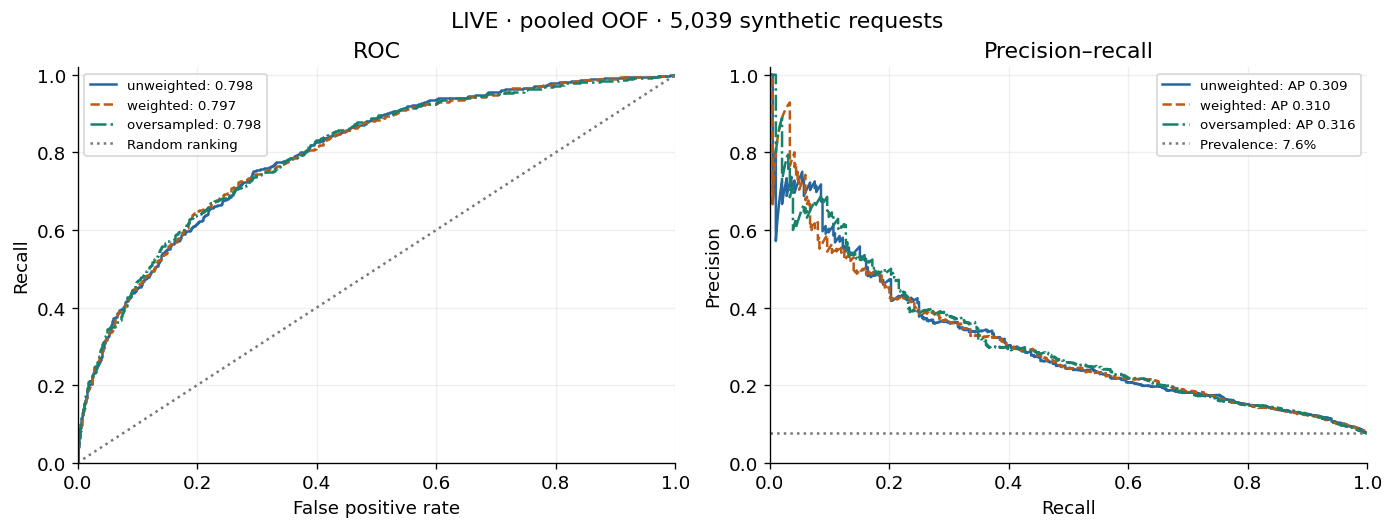

In [27]:
comparison_rows = []
for strategy, group in oof.groupby("strategy", sort=False):
    sweep = threshold_sweep(group, policy)
    default = sweep.loc[sweep.threshold.eq(.5)].iloc[0]
    comparison_rows.append({"strategy": strategy, "rows": len(group), "positive_rate": group[TARGET].mean(),
        "pooled_roc_auc": roc_auc_score(group[TARGET], group.probability),
        "pooled_ap": average_precision_score(group[TARGET], group.probability),
        "accuracy_at_0_5": default.accuracy, "recall_at_0_5": default.recall,
        "precision_at_0_5": default.precision, "flags_at_0_5": default.flagged,
        "loss_at_0_5": default.loss_units, "capacity_ok_at_0_5": default.capacity_feasible, "source": SOURCE})
comparison = pd.DataFrame(comparison_rows)
display(comparison.round(4))
no_flag_reference = {"rule": "No flags for anyone", "rows": len(selected),
    "accuracy": 1-selected[TARGET].mean(), "recall": 0., "precision": None,
    "loss_units": int(selected[TARGET].sum()) * policy.false_negative_cost}
display(pd.DataFrame([no_flag_reference]))

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 120, "axes.grid": True, "grid.alpha": .2})
colors = {"unweighted": "#2667A0", "weighted": "#BA5A17", "oversampled": "#18816A"}
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3), constrained_layout=True)
for strategy, style in zip(STRATEGIES, ["-", "--", "-."]):
    group = oof[oof.strategy.eq(strategy)]
    fpr, tpr, _ = roc_curve(group[TARGET], group.probability)
    precision, recall, _ = precision_recall_curve(group[TARGET], group.probability)
    row = comparison.set_index("strategy").loc[strategy]
    axes[0].plot(fpr, tpr, color=colors[strategy], linestyle=style, label=f"{strategy}: {row.pooled_roc_auc:.3f}")
    axes[1].plot(recall, precision, color=colors[strategy], linestyle=style, label=f"{strategy}: AP {row.pooled_ap:.3f}")
axes[0].plot([0,1], [0,1], color="#777777", linestyle=":", label="Random ranking")
axes[1].axhline(selected[TARGET].mean(), color="#777777", linestyle=":", label=f"Prevalence: {selected[TARGET].mean():.1%}")
axes[0].set(title="ROC", xlabel="False positive rate", ylabel="Recall")
axes[1].set(title="Precision–recall", xlabel="Recall", ylabel="Precision")
for ax in axes:
    ax.set_xlim(0,1); ax.set_ylim(0,1.02); ax.legend(fontsize=8)
fig.suptitle(f"{SOURCE} · pooled OOF · {len(selected):,} synthetic requests")
fig.savefig(ARTIFACTS / "day3_roc_pr.png", dpi=160)
plt.show()

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>5. Sweep every distinct decision rule</h2>
<p>A request is flagged when <strong>score ≥ threshold</strong>. The sweep evaluates every distinct score, adds 0.5 explicitly and includes a no-flag rule, avoiding a coarse grid that can miss the best observed rule.</p>
<ul><li>Tied scores remain together; do not break ties by identifier to fill capacity.</li><li>If loss ties, prefer fewer flags and then the higher threshold.</li><li>Select one minimum-loss rule without a capacity limit and another minimum-loss rule feasible in every period.</li></ul>
<p>The unconstrained rule cannot have higher observed OOF loss than 0.5 because 0.5 is included. The capacity-constrained rule may have higher loss when 0.5 is infeasible.</p>
<p>Selection on OOF is safer than selection on training predictions, but it still uses the same development labels to choose the threshold. The selected loss is optimistic development evidence, not final-test performance.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>5. افحص كل قاعدة عتبة مميزة</h2>
<p>ترفع الإشارة عندما تكون <strong>الدرجة ≥ العتبة</strong>. يفحص المسح كل درجة مميزة، ويضيف 0.5 صراحة، ويضم قاعدة بلا إشارات، بدل شبكة خشنة قد تفوّت أفضل قاعدة مرصودة.</p>
<ul><li>تبقى الدرجات المتعادلة معًا؛ لا تكسر التعادل بالمعرّف لملء السعة.</li><li>عند تساوي الخسارة، فضّل إشارات أقل ثم العتبة الأعلى.</li><li>اختر قاعدة بأقل خسارة دون قيد، وقاعدة أخرى بأقل خسارة قابلة للتنفيذ في كل فترة.</li></ul>
<p>لا يمكن أن تتجاوز خسارة القاعدة غير المقيدة خسارة 0.5 المرصودة لأن 0.5 ضمن المرشحين. وقد تزيد خسارة القاعدة المقيدة إذا كانت 0.5 غير قابلة للتنفيذ.</p>
<p>الاختيار على OOF أكثر أمانًا من الاختيار على تنبؤات التدريب، لكنه ما زال يستخدم أهداف التطوير نفسها لاختيار العتبة. الخسارة المختارة دليل تطوير متفائل، وليست أداء اختبار نهائي.</p>
</td>
</tr>
</table>

,rule,threshold,tp,fp,fn,tn,recall,precision,flagged,flag_fraction,loss_units,loss_units_per_10000,capacity_feasible
0,Default 0.5,0.5000,222,783,162,3872,0.5781,0.2209,1005,0.1994,2403,4768.8033,False
1,"Minimum loss, no capacity limit",0.4486,246,895,138,3760,0.6406,0.2156,1141,0.2264,2275,4514.7847,False
2,"Minimum loss, every-period capacity",0.6583,157,369,227,4286,0.4089,0.2985,526,0.1044,2639,5237.1502,True


Constrained minus default loss: +236 educational units. Default feasible: False
Exact rule to preserve in JSON: 0.6583471436014694 with >=


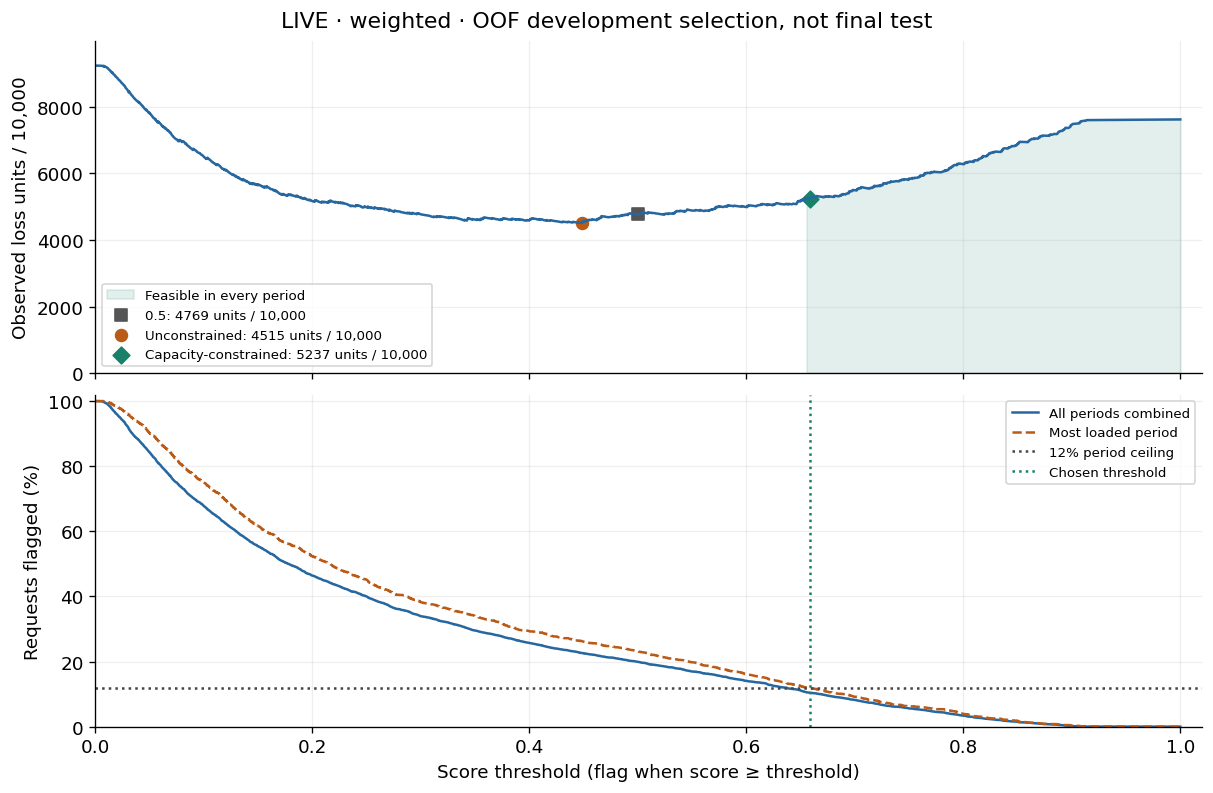

In [28]:
cost_curve = threshold_sweep(selected, policy)
unconstrained = select_threshold(cost_curve, constrained=False)
chosen = select_threshold(cost_curve, constrained=True)
default = cost_curve.loc[cost_curve.threshold.eq(.5)].iloc[0].to_dict()
operating_points = pd.DataFrame([{**point, "rule": name} for name, point in
    [("Default 0.5", default), ("Minimum loss, no capacity limit", unconstrained),
     ("Minimum loss, every-period capacity", chosen)]])
display(operating_points[["rule", "threshold", "tp", "fp", "fn", "tn", "recall", "precision",
    "flagged", "flag_fraction", "loss_units", "loss_units_per_10000", "capacity_feasible"]].round(4))
assert unconstrained["loss_units"] <= default["loss_units"]
if default["capacity_feasible"]:
    assert chosen["loss_units"] <= default["loss_units"]
periods = period_audit(selected, chosen["threshold"], policy)
assert periods.within_capacity.all()
delta = chosen["loss_units"] - default["loss_units"]
print(f"Constrained minus default loss: {delta:+.0f} educational units. Default feasible: {default['capacity_feasible']}")
print("Exact rule to preserve in JSON:", repr(chosen["threshold"]), "with >=")

fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, constrained_layout=True)
axes[0].plot(cost_curve.threshold, cost_curve.loss_units_per_10000, color="#2667A0")
axes[0].fill_between(cost_curve.threshold, 0, cost_curve.loss_units_per_10000,
    where=cost_curve.capacity_feasible, color="#18816A", alpha=.12, label="Feasible in every period")
for label, point, marker, color in [("0.5", default, "s", "#555555"),
    ("Unconstrained", unconstrained, "o", "#BA5A17"), ("Capacity-constrained", chosen, "D", "#18816A")]:
    axes[0].scatter([point["threshold"]], [point["loss_units_per_10000"]], marker=marker, color=color, s=50,
        label=f"{label}: {point['loss_units_per_10000']:.0f} units / 10,000")
axes[0].set(ylabel="Observed loss units / 10,000", ylim=(0, cost_curve.loss_units_per_10000.max()*1.08))
axes[0].legend(fontsize=8)
axes[1].plot(cost_curve.threshold, cost_curve.flag_fraction*100, label="All periods combined", color="#2667A0")
axes[1].plot(cost_curve.threshold, cost_curve.max_period_flag_fraction*100, linestyle="--",
    label="Most loaded period", color="#BA5A17")
axes[1].axhline(policy.max_flag_fraction*100, color="#444444", linestyle=":", label="12% period ceiling")
axes[1].axvline(chosen["threshold"], color="#18816A", linestyle=":", label="Chosen threshold")
axes[1].set(xlabel="Score threshold (flag when score ≥ threshold)", ylabel="Requests flagged (%)", ylim=(0,102), xlim=(0,1.02))
axes[1].legend(fontsize=8)
fig.suptitle(f"{SOURCE} · {MODEL_FOR_DECISION} · OOF development selection, not final test")
fig.savefig(ARTIFACTS / "cost_curve.png", dpi=160)
plt.show()

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>6. Audit every period and test policy sensitivity</h2>
<p>The per-period table is the binding capacity evidence. A pooled rate alone is insufficient. Preserve the full exported threshold precision; rounding can change which tied or boundary scores are flagged.</p>
<p>Test FN costs of 8, 10 and 12 while holding FP cost at 1 and capacity at 12%. These are ±20% policy scenarios, not confidence intervals. They show whether the operating point is fragile to a plausible assumption change.</p>
<p>The theoretical unconstrained threshold 1/11 requires calibrated probabilities, the stated loss matrix and no capacity limit. Do not impose it on today’s weighted raw scores.</p>
<p>Historical feasibility does not guarantee future capacity. A production process would monitor queue volume, score distribution, prevalence and threshold stability.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>6. دقّق كل فترة واختبر حساسية السياسة</h2>
<p>جدول كل فترة هو دليل السعة الملزم؛ لا تكفي النسبة المجمعة وحدها. احتفظ بالدقة الكاملة للعتبة المصدرة، لأن التقريب قد يغيّر الحالات المتعادلة أو الواقعة عند الحد.</p>
<p>اختبر خسارة FN بالقيم 8 و10 و12 مع إبقاء خسارة FP عند 1 والسعة عند 12%. هذه سيناريوهات سياسة ±20% وليست فترات ثقة، وتوضح مدى هشاشة نقطة التشغيل أمام تغير افتراض معقول.</p>
<p>تتطلب العتبة النظرية غير المقيدة 1/11 احتمالات معايرة ومصفوفة الخسارة المحددة وغياب قيد السعة. لا تفرضها على درجات اليوم الخام الموزونة.</p>
<p>لا تضمن القابلية التاريخية سعة المستقبل. تحتاج العملية الفعلية إلى مراقبة حجم الطابور وتوزيع الدرجات ونسبة الحدث واستقرار العتبة.</p>
</td>
</tr>
</table>

In [29]:
display(periods)
sensitivity_rows = []
for fn_cost in [8., 10., 12.]:
    scenario_policy = replace(policy, false_negative_cost=fn_cost)
    scenario = select_threshold(threshold_sweep(selected, scenario_policy))
    sensitivity_rows.append({"FN_loss_units": fn_cost, "FP_loss_units": policy.false_positive_cost,
        "capacity_fraction": policy.max_flag_fraction, "threshold": scenario["threshold"],
        "flagged": scenario["flagged"], "recall": scenario["recall"],
        "loss_units": scenario["loss_units"], "capacity_feasible": scenario["capacity_feasible"], "source": SOURCE})
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity.round(4))
print("Theoretical threshold 1/11 ≈ 0.0909 requires calibrated probabilities, this loss matrix and no capacity limit.")
print("Do not impose that formula on today's weighted raw scores.")

,fold,rows,capacity,flagged,flag_fraction,within_capacity,source
0,1,1632,195,137,0.083946,True,LIVE
1,2,1674,200,183,0.109319,True,LIVE
2,3,1733,207,206,0.118869,True,LIVE


,FN_loss_units,FP_loss_units,capacity_fraction,threshold,flagged,recall,loss_units,capacity_feasible,source
0,8.0,1,0.12,0.6583,526,0.4089,2185.0,True,LIVE
1,10.0,1,0.12,0.6583,526,0.4089,2639.0,True,LIVE
2,12.0,1,0.12,0.6583,526,0.4089,3093.0,True,LIVE


Theoretical threshold 1/11 ≈ 0.0909 requires calibrated probabilities, this loss matrix and no capacity limit.
Do not impose that formula on today's weighted raw scores.


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>7. Report descriptive group differences carefully</h2>
<p>After freezing one shared threshold, compute each synthetic region’s false-positive rate as <strong>FP ÷ non-default cases</strong>. Report the denominator, flag count and recall alongside the rate.</p>
<ul><li>The gap is the largest FPR minus the smallest, in percentage points.</li><li>A missing denominator produces a missing rate, not zero.</li><li>Groups with fewer than 30 non-default cases receive a low-support warning.</li></ul>
<p>This is a descriptive audit, not a statistical significance test, legal fairness certification or causal conclusion about geography. A visible gap requires review; a small gap does not prove fairness. Do not hide differences by assigning separate thresholds to groups without a governed policy.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>7. أبلغ عن الفروق الوصفية بين المجموعات بحذر</h2>
<p>بعد تثبيت عتبة مشتركة واحدة، احسب معدل الإنذار الخاطئ لكل منطقة اصطناعية وفق <strong>FP ÷ الحالات غير المتعثرة</strong>. اعرض المقام وعدد الإشارات وRecall بجانب المعدل.</p>
<ul><li>الفجوة هي أكبر FPR ناقص أصغره بوحدة نقطة مئوية.</li><li>غياب المقام ينتج معدلًا غير متاح، لا صفرًا.</li><li>تُوسم المجموعة عندما يقل دعم الحالات السليمة عن 30.</li></ul>
<p>هذا تدقيق وصفي، وليس اختبار دلالة أو شهادة عدالة قانونية أو استنتاجًا سببيًا عن الجغرافيا. الفجوة الظاهرة تحتاج إلى مراجعة، والفجوة الصغيرة لا تثبت العدالة. لا تخفِ الفروق بعتبات منفصلة للمجموعات دون سياسة محكومة.</p>
</td>
</tr>
</table>

,region,rows,negatives,positives,flagged,false_positives,true_positives,false_positive_rate,recall,low_negative_support,source
0,central,1184,1088,96,131,88,43,0.0809,0.4479,False,LIVE
1,western,1262,1158,104,132,96,36,0.0829,0.3462,False,LIVE
2,eastern,1295,1192,103,131,92,39,0.0772,0.3786,False,LIVE
3,other,1298,1217,81,132,93,39,0.0764,0.4815,False,LIVE


FPR gap (percentage points): 0.6484134519182061


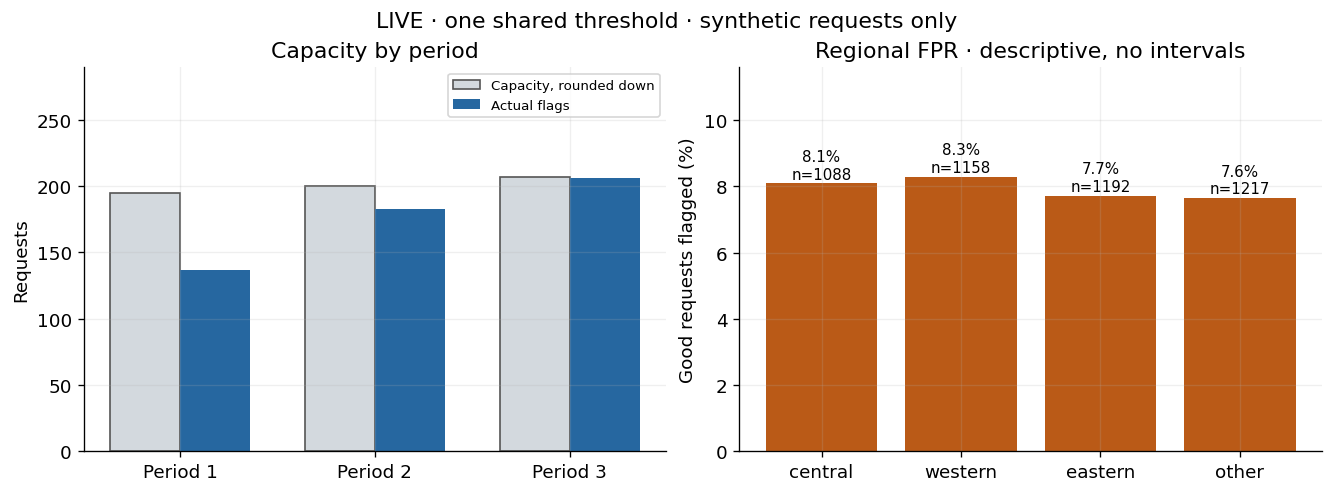

In [30]:
regions, gap_info = region_audit(selected, chosen["threshold"])
display(regions.round(4))
print("FPR gap (percentage points):", gap_info["fpr_gap_percentage_points"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
x = np.arange(len(periods))
axes[0].bar(x-.18, periods.capacity, .36, color="#D3D9DE", edgecolor="#555555", label="Capacity, rounded down")
axes[0].bar(x+.18, periods.flagged, .36, color="#2667A0", label="Actual flags")
axes[0].set(xticks=x, xticklabels=[f"Period {n}" for n in periods.fold], ylabel="Requests", title="Capacity by period")
axes[0].set_ylim(0, periods.capacity.max()*1.4)
axes[0].legend(fontsize=8)
axes[1].bar(regions.region, regions.false_positive_rate*100, color="#BA5A17")
axes[1].set(ylabel="Good requests flagged (%)", title="Regional FPR · descriptive, no intervals")
for i, row in enumerate(regions.itertuples()):
    if pd.notna(row.false_positive_rate):
        axes[1].text(i, row.false_positive_rate*100+.15, f"{row.false_positive_rate:.1%}\nn={row.negatives}", ha="center", fontsize=9)
axes[1].set_ylim(0, max(10, regions.false_positive_rate.max()*140))
fig.suptitle(f"{SOURCE} · one shared threshold · synthetic requests only")
fig.savefig(ARTIFACTS / "day3_capacity_regions.png", dpi=160)
plt.show()

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>8. Write the decision argument yourself</h2>
<p>Complete the shared response cell in your own words and cite numbers from your run:</p>
<ol><li>Why the selected threshold is defensible.</li><li>The observed loss–capacity trade-off.</li><li>The regional FPR gap and what needs review.</li><li>Limitations: OOF development selection, coverage, calibration and simplified policy.</li><li>Why accuracy can mislead under class imbalance.</li><li>Why threshold selection uses OOF rather than training predictions or challenge data.</li></ol>
<p>Copying the threshold alone is insufficient. The automated checkpoint detects missing fields only; it does not judge correctness, assign a grade or establish authorship.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>8. اكتب حجة القرار بنفسك</h2>
<p>أكمل خلية الإجابات المشتركة بصياغتك أنت، واستشهد بأرقام من تشغيلك:</p>
<ol><li>لماذا يمكن الدفاع عن العتبة المختارة.</li><li>المقايضة المرصودة بين الخسارة والسعة.</li><li>فجوة FPR بين المناطق وما يحتاج إلى مراجعة.</li><li>القيود: اختيار تطويري على OOF، والتغطية، والمعايرة، وتبسيط السياسة.</li><li>لماذا قد تكون Accuracy مضللة مع عدم توازن الفئات.</li><li>لماذا نختار العتبة على OOF بدل تنبؤات التدريب أو بيانات التحدي.</li></ol>
<p>لا يكفي نسخ رقم العتبة. يكتشف الفحص الآلي الحقول الفارغة فقط؛ ولا يحكم على صحة الإجابة أو يمنح درجة أو يثبت الملكية.</p>
</td>
</tr>
</table>

In [31]:
responses = {
    "threshold_reason": "The chosen threshold is defensible because 0.6583 was the lowest loss threshold that stays within the 12% review limit in every period. It flags 526 requests (10.4%) and catches 157 of 384 defaults (recall 41%, precision 30%). Its loss is 2,639 units. The lower threshold of 0.4486 has less loss, but flags too many requests (22.6%). The default 0.5 also flags too many (19.9%).",
    "cost_capacity_tradeoff": "A higher loss was accepted to honor the capacity of the number of reviews.The chosen threshold has a loss of 2,639, compared with 2,275 at the unconstrained threshold and 2,403 at 0.5. Its recall is also lower: 41% instead of 64% at the unconstrained threshold. For the three cost scenarios tested the capacity limit was the driver in the decision. ",
    "regional_gap": "The false-positive rate was 7.64% in “Other” and 8.29% in the Western region—a gap of 0.65 percentage points. Recall ranged from 35% in the West to 48% in “Other.” These differences are worth reviewing,  but it doesn’t prove the model is fair or unfair.",
    "limitations": "This isn’t a final test because I chose the threshold using the same OOF results I used to measure it, so the loss may look a little better than it would on new data. Only 5,039 of the 10,000 rows have OOF predictions; the 4,961 warm-up rows don’t. Because the model used class weighting, its scores may not be reliable probabilities. The data is synthetic, and the loss units aren’t real money. The calculation also leaves out the cost of doing reviews. Staying within capacity in these periods doesn’t guarantee the same result in the future.",
    "why_accuracy_misleads": "Only 7.6% of cases defaulted. If the model flagged nobody, it would still be 92.4% accurate—but it would catch no defaults. The unweighted model was 92.6% accurate but caught only 12.5% of defaults. The weighted model was less accurate at 81%, but caught 58% and had lower loss. Since missing a default costs ten times more than a false alarm, accuracy isn’t enough to judge the models.",
    "why_oof": "Training predictions can look too good because the model has already seen those examples. OOF predictions are made for examples the model didn’t train on, so they give a fairer check. The time-based folds also keep the data in the right order. The challenge data should stay untouched for the final test; using it to choose a threshold would make that test less reliable."}
checkpoint = reflection_check(responses, SOURCE)
print(checkpoint["status"], "| missing:", checkpoint["missing"])

READY_FOR_REVIEW | missing: []


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>9. Export the decision card and evidence</h2>
<p>The export cell creates <code>reports/DECISION_CARD.md</code> from actual run values and your text, then saves CSV, JSON and figure evidence.</p>
<ul><li><code>TECHNICAL_READY</code>: the live run and technical guards completed.</li><li><code>LEARNER_WORK_REQUIRED</code>: technical work passed, but your interpretation remains incomplete.</li><li><code>READY_FOR_REVIEW</code>: required text fields exist; this is not an automated grade.</li><li><code>EXAMPLE_ONLY_NOT_SUBMITTABLE</code>: the recovery example was used and cannot represent your work.</li></ul>
<p>Download <code>day3_artifacts.zip</code>, extract it at the repository root and retain the generated <code>artifacts/</code> and <code>reports/</code> folders. Save the executed notebook as <code>notebooks/03_cost_sensitive_decision.ipynb</code>. Uploading only the ZIP does not satisfy the visible-file requirements.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>9. صدّر بطاقة القرار والأدلة</h2>
<p>تنشئ خلية التصدير ملف <code>reports/DECISION_CARD.md</code> من قيم التشغيل الفعلية ونصك، ثم تحفظ أدلة CSV وJSON والرسوم.</p>
<ul><li><code>TECHNICAL_READY</code>: اكتمل التشغيل الفعلي والحراس التقنية.</li><li><code>LEARNER_WORK_REQUIRED</code>: نجح الجانب التقني، لكن تفسيرك ما زال ناقصًا.</li><li><code>READY_FOR_REVIEW</code>: الحقول النصية موجودة؛ وهذه ليست درجة آلية.</li><li><code>EXAMPLE_ONLY_NOT_SUBMITTABLE</code>: استُخدم مثال التعافي ولا يمكن اعتباره عملك.</li></ul>
<p>نزّل <code>day3_artifacts.zip</code> وافكّه في جذر المستودع مع الاحتفاظ بمجلدي <code>artifacts/</code> و<code>reports/</code>. احفظ الدفتر المنفذ باسم <code>notebooks/03_cost_sensitive_decision.ipynb</code>. رفع ملف ZIP وحده لا يحقق متطلبات الملفات الظاهرة.</p>
</td>
</tr>
</table>

In [32]:
def json_safe(value):
    if isinstance(value, dict): return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)): return [json_safe(v) for v in value]
    if isinstance(value, np.generic): value = value.item()
    if isinstance(value, float) and not np.isfinite(value): return None
    return value

checkpoint = reflection_check(responses, SOURCE)
status = "TECHNICAL_READY" if SOURCE == "LIVE" else "EXAMPLE_ONLY_NOT_SUBMITTABLE"
pooled_ap = float(average_precision_score(selected[TARGET], selected.probability))
threshold_metrics = {"source": SOURCE, "technical_status": status, "strategy": MODEL_FOR_DECISION,
    "policy": asdict(policy), "unit": "educational_loss_unit", "comparison_operator": ">=",
    "capacity_scope": "every validation period; floor(fraction * period_rows)",
    "chosen": chosen, "unconstrained": unconstrained, "default_0_5": default,
    "loss_change_vs_default": delta, "pooled_oof_ap": pooled_ap, "regional_audit": gap_info,
    "coverage": coverage, "selection_status": "OOF development selection; not an independent final test"}
membership = train[["application_id", "application_date"]].copy()
membership["role"], membership["fold"] = "warmup_no_oof", 0
for fold in folds:
    membership.loc[fold["valid"], "role"] = "eligible_oof"
    membership.loc[fold["valid"], "fold"] = fold["audit"]["fold"]
membership["source"] = SOURCE
decisions = selected.copy()
decisions["review_flag"] = flag_at(selected.probability, chosen["threshold"]).astype(int)
csv_outputs = {"day3_model_report.csv": model_report, "day3_model_comparison.csv": comparison,
    "day3_oof_predictions.csv": oof, "day3_oof_coverage.csv": membership, "threshold_sweep.csv": cost_curve,
    "day3_period_capacity.csv": periods, "day3_region_audit.csv": regions,
    "day3_cost_sensitivity.csv": sensitivity, "day3_review_flags.csv": decisions}
for filename, table in csv_outputs.items(): table.to_csv(ARTIFACTS / filename, index=False)
run = {"technical_status": status, "learner_status": checkpoint["status"], "source": SOURCE,
    "requested_config": asdict(config), "effective_config": effective_config, "assessment_mode": ASSESSMENT_MODE,
    "data_revision": COURSE_REVISION, "lab_revision": LAB_REVISION, "support_sha256": SUPPORT_HASHES,
    "day2_revision": DAY2_REVISION, "day2_sha256": DAY2_SHA256, "manifest_sha256": MANIFEST_SHA256,
    "training_data_sha256": hashlib.sha256((ROOT / "data/tamweel_train.csv").read_bytes()).hexdigest(),
    "python": platform.python_version(), "elapsed_seconds": round(time.perf_counter()-RUN_STARTED,2),
    "coverage": coverage, "challenge_used_for_modeling": False, "no_automatic_grade": True}
if IN_COLAB:
    import resource
    run["peak_process_memory_mib"] = round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss/1024,1)
json_outputs = {"threshold_metrics.json": threshold_metrics, "day3_provenance.json": provenance,
    "day3_reflection.json": {"source": SOURCE, "responses": responses, "checkpoint": checkpoint}, "day3_run.json": run}
for filename, payload in json_outputs.items():
    (ARTIFACTS / filename).write_text(json.dumps(json_safe(payload), ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")

answer = lambda key: responses[key].strip() or "[اكتب تفسيرك من نتائجك هنا]"
rate_text = lambda value: f"{value:.2%}" if pd.notna(value) else "غير معرّفة لغياب المقام"
card_status = ("مثال تعليمي غير صالح للتسليم كتجربة شخصية" if SOURCE != "LIVE" else
               "مسودة — أكمل تفسيرك" if checkpoint["missing"] else "جاهزة للمراجعة؛ لا تعني اعتمادًا أو درجة")
card = f"""# بطاقة قرارك — Tamweel Lite

**الحالة:** {card_status}
**مصدر الأرقام:** {SOURCE} · **الاستراتيجية:** {MODEL_FOR_DECISION} · **الصفوف:** {len(selected):,} OOF

**المهمة:** الفئة الموجبة `default_within_90d=1` تعني حدث تعثر اصطناعي خلال90 يومًا بعد الطلب. كل طية تحقق طلبات لاحقة، وتستبعد عملاءها من التدريب وتشترط نضج نتيجة التدريب قبل بدايتها. المعرّفات والتاريخ خارج المدخلات.

| الدليل | القيمة |
|---|---:|
| العتبة المقيدة، بالقيمة الكاملة | {repr(chosen['threshold'])} |
| عتبة أقل خسارة دون قيد | {repr(unconstrained['threshold'])} |
| Recall | {rate_text(chosen['recall'])} |
| Precision | {rate_text(chosen['precision'])} |
| AP مجمع منOOF | {pooled_ap:.4f} |
| الإشارات | {chosen['flagged']:,} من {len(selected):,} |
| FN / FP | {chosen['fn']} / {chosen['fp']} |
| الخسارة التعليمية | {chosen['loss_units']:.0f} وحدة |
| خسارة0.5 | {default['loss_units']:.0f} وحدة؛ ضمن السعة: {default['capacity_feasible']} |
| التغير عن0.5 | {delta:+.0f} وحدة؛ الموجب زيادة |
| خسارة لكل10,000 طلب، تطبيع حسابي | {chosen['loss_units_per_10000']:.2f} وحدة |
| فجوة معدل الإنذار الخاطئ بين المناطق | {gap_info['fpr_gap_percentage_points']:.3f} نقطة مئوية |

**القاعدة:** درجة ≥ {repr(chosen['threshold'])} تعني إشارة مراجعة داخل التمرين؛ غير ذلك بلا إشارة. لا تتخذ موافقة أو رفض تمويل حقيقي. احفظ الدقة الكاملة؛ تقريب العتبة قد يغيّر حجم الطابور.

**السياسة:** FN={policy.false_negative_cost:g} وFP={policy.false_positive_cost:g} وحدات تعليمية، وسعة {policy.max_flag_fraction:.0%} لكل فترة بعد التقريب لأسفل. ليست ريالات فعلية أو رسوم أدوات أو خصمًا من الدرجة.

**دليل السعة:** {', '.join(f"الفترة {int(row.fold)}: {int(row.flagged)}/{int(row.capacity)}" for row in periods.itertuples())}.

## لماذا اخترت هذه العتبة؟
{answer('threshold_reason')}

## الخسارة والسعة
{answer('cost_capacity_tradeoff')}

## فرق المناطق وما يحتاج إلى مراجعة
{answer('regional_gap')}

## حدود النتيجة
{answer('limitations')}

OOF تغطي {coverage['whole_data_coverage']:.2%} من التدريب و100% من الصفوف المؤهلة؛ {coverage['warmup_without_oof']:,} صفًا تمهيديًا بلا تنبؤ. اختيار العتبة وتقدير خسارتها هنا يستخدمان أهدافOOF نفسها؛ هذه نتيجة تطوير لا اختبار نهائي. لم نستخدم التحدي. المقارنة الجغرافية وصفية وليست شهادة عدالة، والأوزان لا تضمن معايرة الدرجات.

## سؤالك الأول: لماذا قد تخدعكAccuracy؟
{answer('why_accuracy_misleads')}

## سؤالك الثاني: لماذا تختار علىOOF؟
{answer('why_oof')}

أدلتك في `artifacts/threshold_metrics.json` و`day3_period_capacity.csv` و`day3_region_audit.csv` و`day3_cost_sensitivity.csv` و`cost_curve.png`. الحساسية سيناريوهات ±20% لخسارةFN، وليست فترات ثقة. راجع السعة والمعايرة عند تغير البيانات؛ لا تفترض ثباتهما مستقبلًا.
"""
(REPORTS / "DECISION_CARD.md").write_text(card, encoding="utf-8")
artifact_files = list(csv_outputs) + list(json_outputs) + ["cost_curve.png", "day3_roc_pr.png", "day3_capacity_regions.png", "environment.json"]
with zipfile.ZipFile(ARTIFACTS / "day3_artifacts.zip", "w", zipfile.ZIP_DEFLATED) as bundle:
    for filename in artifact_files:
        bundle.write(ARTIFACTS / filename, "artifacts/" + filename)
    bundle.write(REPORTS / "DECISION_CARD.md", "reports/DECISION_CARD.md")
print(f"{status} | {checkpoint['status']} | {SOURCE} | {run['elapsed_seconds']} seconds | CPU")
print(f"Saved {len(artifact_files)+1} files in day3_artifacts.zip — complete your reasoning and download.")

TECHNICAL_READY | READY_FOR_REVIEW | LIVE | 10.79 seconds | CPU
Saved 18 files in day3_artifacts.zip — complete your reasoning and download.


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Completion checkpoint and Day 4 bridge</h2>
<ul><li>You can identify FN and FP and explain the teaching loss matrix.</li><li>You can show capacity compliance for every period, not only in aggregate.</li><li>You compared weighting and oversampling without declaring a required winner.</li><li>You preserved the exact threshold and documented sensitivity and group-audit limits.</li><li>You saved the executed notebook, 17 artifact files and the decision card outside the temporary Colab session.</li></ul>
<p><strong>Troubleshooting:</strong> restart after an imported-version mismatch; rerun setup after a network interruption; never bypass a checksum; rerun live CPU training if the educational example appears; never submit another learner’s outputs.</p>
<p><strong>Day 4:</strong> inspect global and local explanations, test calibration and decide whether the score can be interpreted as a probability.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>بوابة الإكمال والربط باليوم الرابع</h2>
<ul><li>تستطيع تحديد FN وFP وشرح مصفوفة الخسارة التعليمية.</li><li>تستطيع إثبات الالتزام بالسعة في كل فترة، وليس في المجموع فقط.</li><li>قارنت الوزن وإعادة العينات دون افتراض فائز مطلوب.</li><li>حفظت العتبة بكامل دقتها ووثقت الحساسية وحدود تدقيق المجموعات.</li><li>حفظت الدفتر المنفذ و17 ملف دليل وبطاقة القرار خارج جلسة Colab المؤقتة.</li></ul>
<p><strong>حل التعثر:</strong> أعد تشغيل الجلسة عند اختلاف إصدار مستورد؛ أعد الإعداد بعد انقطاع الشبكة؛ لا تتجاوز فحص البصمة؛ أعد التدريب الفعلي على CPU عند ظهور المثال التعليمي؛ ولا تسلّم مخرجات متدرب آخر.</p>
<p><strong>اليوم الرابع:</strong> افحص التفسير العالمي والمحلي، واختبر المعايرة، وقرر هل يمكن تفسير الدرجة بوصفها احتمالًا.</p>
</td>
</tr>
</table>

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Daily question · Decision threshold</h2>
<p><strong>Why is a fixed threshold of 0.5 not always suitable for this review policy?</strong><br><br>Write a short answer under <code>Day 3</code> in the <code>Daily answers | الإجابات اليومية</code> section of your repository README. Then download this executed notebook and the required generated files and upload them on the same day.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>سؤال اليوم · عتبة القرار</h2>
<p><strong>لماذا لا تكون العتبة الثابتة 0.5 مناسبة دائمًا لسياسة المراجعة؟</strong><br><br>اكتب إجابة مختصرة تحت <code>Day 3 | اليوم 3</code> في قسم <code>Daily answers | الإجابات اليومية</code> داخل README في مستودعك، ثم نزّل هذا الدفتر بعد التنفيذ وملفات النتائج المطلوبة وارفعها في اليوم نفسه.</p>
</td>
</tr>
</table>

---
# Gate 4: Explain and calibrate

_Executed notebook `notebooks/04_explain_calibrate.ipynb`._

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Day 4 · Explain the model and test its probabilities</h2>
<p><strong>SDA-DSC-211 · Tamweel Lite · 60-minute lab · Free CPU</strong></p>
<p>Ask two different questions: what information does the fitted model use, and do its probability scores agree with observed event frequency on a separate period? Compare permutation importance, global and local SHAP explanations, calibration, stability and the operational effect of a diagnostic review zone.</p>
<p><strong>Deliverable:</strong> <code>reports/INTERPRETABILITY_REPORT.md</code>, six figures and the complete evidence bundle.</p>
<p><strong>Boundary:</strong> the data are fictional. Explanations describe a fitted model, not causes, protected-trait effects or real financing decisions. Calibration improvement is measured, never assumed.</p>
<table><tr><th>Minutes</th><th>Your task</th></tr><tr><td>0–10</td><td>Separate data roles and inspect permutation importance</td></tr><tr><td>10–25</td><td>Read the beeswarm and SHAP output unit</td></tr><tr><td>25–35</td><td>Explain one synthetic request and test local stability</td></tr><tr><td>35–48</td><td>Compare calibration, Brier score and ECE</td></tr><tr><td>48–54</td><td>Read stability limits and review capacity</td></tr><tr><td>54–60</td><td>Complete the report and export evidence</td></tr></table>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>اليوم الرابع · فسّر النموذج واختبر احتمالاته</h2>
<p><strong>SDA-DSC-211 · Tamweel Lite · لاب 60 دقيقة · CPU مجاني</strong></p>
<p>اطرح سؤالين مختلفين: ما المعلومات التي يستخدمها النموذج المدرّب، وهل تتفق درجات احتماله مع تكرار الحدث المرصود في فترة منفصلة؟ قارن أهمية التبديل، وتفسيرات SHAP العامة والمحلية، والمعايرة، والاستقرار، والأثر التشغيلي لمنطقة مراجعة تشخيصية.</p>
<p><strong>التسليم:</strong> ملف <code>reports/INTERPRETABILITY_REPORT.md</code> وستة رسوم وحزمة الأدلة الكاملة.</p>
<p><strong>الحدود:</strong> البيانات اصطناعية. تصف التفسيرات نموذجًا مدرّبًا، ولا تثبت الأسباب أو أثر السمات المحمية أو قرارات تمويل حقيقية. يُقاس تحسن المعايرة ولا يُفترض مسبقًا.</p>
<table><tr><th>الدقائق</th><th>مهمتك</th></tr><tr><td>0–10</td><td>افصل أدوار البيانات وافحص أهمية التبديل</td></tr><tr><td>10–25</td><td>اقرأ beeswarm ووحدة مخرجات SHAP</td></tr><tr><td>25–35</td><td>فسّر طلبًا اصطناعيًا واختبر الاستقرار المحلي</td></tr><tr><td>35–48</td><td>قارن المعايرة وBrier وECE</td></tr><tr><td>48–54</td><td>اقرأ حدود الاستقرار وسعة المراجعة</td></tr><tr><td>54–60</td><td>أكمل التقرير وصدّر الأدلة</td></tr></table>
</td>
</tr>
</table>

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Official daily requirement</h2>
<p>Run all cells, compare the generated files with EXPECTED_RESULTS.md, then answer only the single question at the end of this notebook in your repository README. Legacy reflection variables inside code cells are compatibility fields; leave them unchanged.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>المطلوب اليومي المعتمد</h2>
<p>شغّل جميع الخلايا، وقارن الملفات الناتجة بصفحة EXPECTED_RESULTS.md، ثم أجب فقط عن السؤال الواحد في نهاية هذا الدفتر داخل README في مستودعك. حقول الانعكاس القديمة داخل خلايا الكود مخصصة للتوافق؛ اتركها دون تعديل.</p>
</td>
</tr>
</table>

In [16]:
import importlib.metadata as metadata
import os
import signal
import subprocess
import sys

EXPECTED_VERSIONS = {
    "numpy": "2.1.3",
    "pandas": "2.2.3",
    "scipy": "1.16.3",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "xgboost": "3.4.1",
    "lightgbm": "4.6.0",
    "shap": "0.52.0",
    "numba": "0.61.2",
    "optuna": "4.5.0",
}

different_versions = []

for package_name, expected_version in EXPECTED_VERSIONS.items():
    try:
        current_version = metadata.version(package_name)
    except metadata.PackageNotFoundError:
        current_version = None

    if current_version != expected_version:
        different_versions.append(
            f"{package_name}: {current_version or 'غير مثبت'} → {expected_version}"
        )

if different_versions:
    print("سيتم تجهيز بيئة الدورة بالإصدارات المعتمدة:")
    for item in different_versions:
        print("-", item)

    requirements_url = (
        "https://raw.githubusercontent.com/"
        "almiyead-rgb/sda-dsc-211-student-template/"
        "fe0c0204e6076a7ac2139b7336485a097343fb8a/"
        "requirements-colab.txt"
    )

    constraints_url = (
        "https://raw.githubusercontent.com/"
        "almiyead-rgb/sda-dsc-211-student-template/"
        "fe0c0204e6076a7ac2139b7336485a097343fb8a/"
        "constraints.txt"
    )

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "--quiet",
        "--disable-pip-version-check",
        "-r",
        requirements_url,
        "-c",
        constraints_url,
    ])

    print(
        "\nتم تثبيت بيئة الدورة بنجاح.\n"
        "ستتم إعادة تشغيل الجلسة الآن بصورة تلقائية.\n"
        "بعد عودة الاتصال اختَر Runtime → Run all مرة أخرى."
    )

    os.kill(os.getpid(), signal.SIGKILL)

else:
    print("بيئة الدورة جاهزة، ويمكن متابعة تشغيل Notebook.")


بيئة الدورة جاهزة، ويمكن متابعة تشغيل Notebook.


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>1. Prepare a controlled environment</h2>
<p>Open a fresh free-CPU session and choose <strong>Runtime → Run all</strong>. Setup verifies pinned packages, file hashes and support assets before any model work.</p>
<ul><li>Keep <code>FAST_MODE=True</code> and <code>USE_SHAP_EXAMPLE=False</code> for the primary run.</li><li>Use at most two CPU threads; no GPU, Drive mount, API key or paid service is required.</li><li>The fitted estimator is frozen before calibration. <code>FrozenEstimator</code> allows sigmoid calibration without retraining on calibration rows.</li><li>Do not replace the time/customer role split with a random split.</li></ul>
<p>If setup requests a restart, restart the session and run from the beginning. Never bypass a checksum failure.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>1. جهّز بيئة تشغيل محكومة</h2>
<p>افتح جلسة CPU مجانية جديدة ثم نفّذ <strong>Runtime → Run all</strong>. يتحقق الإعداد من الحزم المثبتة وبصمات الملفات وأصول الدعم قبل أي عمل على النموذج.</p>
<ul><li>اترك <code>FAST_MODE=True</code> و<code>USE_SHAP_EXAMPLE=False</code> في التشغيل الأساسي.</li><li>استخدم خيطي CPU كحد أقصى؛ لا تحتاج إلى GPU أو ربط Drive أو مفتاح API أو خدمة مدفوعة.</li><li>يُجمّد النموذج قبل المعايرة. يتيح <code>FrozenEstimator</code> تعلم تحويل sigmoid دون إعادة التدريب على صفوف المعايرة.</li><li>لا تستبدل تقسيم الزمن والعملاء بتقسيم عشوائي.</li></ul>
<p>إذا طلب الإعداد إعادة التشغيل، أعد الجلسة ثم شغّل من البداية. لا تتجاوز فشل البصمة.</p>
</td>
</tr>
</table>

In [17]:
from pathlib import Path
import hashlib, importlib.util, os, runpy, sys, time, urllib.request, urllib.error

RUN_STARTED = time.perf_counter()
COURSE_REVISION = "fe0c0204e6076a7ac2139b7336485a097343fb8a"
MANIFEST_SHA256 = "86d15e813caf833b7d86512808176388d4123dc3c01c6525ee849a76e8322c59"
SETUP_SHA256 = "79608f8f9559d9e6eb09d51ee541ee12d7e9262ac57d1ca3a948c8ecb14f0f35"
IN_COLAB = importlib.util.find_spec("google") is not None and importlib.util.find_spec("google.colab") is not None
ROOT = Path("/content/tamweel") if IN_COLAB else Path(os.environ.get("TAMWEEL_PROJECT_DIR", ".")).resolve()
setup_path = ROOT / "scripts/setup_colab.py"
setup_path.parent.mkdir(parents=True, exist_ok=True)
if not setup_path.exists() or hashlib.sha256(setup_path.read_bytes()).hexdigest() != SETUP_SHA256:
    setup_url = f"https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template/{COURSE_REVISION}/scripts/setup_colab.py"
    for attempt in range(3):
        try:
            with urllib.request.urlopen(setup_url, timeout=45) as response:
                setup_bytes = response.read(200000)
            if hashlib.sha256(setup_bytes).hexdigest() != SETUP_SHA256:
                raise ValueError("Setup checksum mismatch. Reopen the released notebook.")
            setup_path.write_bytes(setup_bytes)
            break
        except (urllib.error.URLError, TimeoutError):
            if attempt == 2:
                raise RuntimeError("Download unavailable. Retry setup or upload the unchanged project files; see READINESS_GUIDE.")
            time.sleep(attempt + 1)
environment = runpy.run_path(str(setup_path))["prepare"](ROOT, COURSE_REVISION, MANIFEST_SHA256)
FAST_MODE, FULL_MODE, SEED, N_JOBS = True, False, 211, 2

from setup_colab import fetch_verified
PREVIOUS_SUPPORT = {
    "scripts/day2_validation.py": ("1e1da4acbee8941bef07245b259fb6c27ced4ad7", "d2fd0353330c3629bdaed6c570528792955fce232540a85d33532a9432522f43"),
    "scripts/day3_decision.py": ("c2dc52e129878d0d487db1874891c658de7c4d0d", "40f176633c91fc530db222978bc44495a401b888b1ce448728948f7ae0ca9e12")}
for relative, (revision, digest) in PREVIOUS_SUPPORT.items():
    fetch_verified(f"https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template/{revision}/{relative}", ROOT / relative, digest)
LAB_REVISION = "4f6892d5c02923b5f8e3c78f4fcead73b043570f"
SUPPORT_HASHES = {'scripts/day4_trust.py': '7e0f54bdbed94b28d09cddd02ce0ba0471d5046f05c7b70589e3e4be9902f20c', 'data/day4_shap_example.npz': 'de6eefb4f0b1dfd54d4a71e2b73cf8383cea6386e661f8af8662d478cd957e2b', 'data/day4_shap_example.json': '8169c70dc327a7ffdff748c365d71544fe951f3b196974e33f09dccb580a8122'}
for relative, digest in SUPPORT_HASHES.items():
    fetch_verified(f"https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template/{LAB_REVISION}/{relative}", ROOT / relative, digest)
print("Day 4 setup verified | إعداد اليوم الرابع جاهز")

Package                 Version
numpy                   2.1.3
pandas                  2.2.3
scipy                   1.16.3
scikit-learn            1.6.1
matplotlib              3.10.0
xgboost                 3.4.1
lightgbm                4.6.0
shap                    0.52.0
numba                   0.61.2
optuna                  4.5.0
Python 3.13.18 | CPU | seed=211 | n_jobs=2 | FAST_MODE=True
Verified course files. Next: run the data and compatibility checks.
Day 4 setup verified | إعداد اليوم الرابع جاهز


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>2. Separate fit, calibration, policy and evaluation</h2>
<p>The synthetic target is a default event within 90 days after application. Newer-role customers are reserved first and removed from earlier roles; identifiers and dates are not model features.</p>
<table><tr><th>Role</th><th>Period or condition</th><th>Only permitted use</th></tr><tr><td><code>fit</code></td><td>Outcome matures before 2023-07-01</td><td>Learn imputation and the weighted model</td></tr><tr><td><code>calibration</code></td><td>Jul–Sep 2023</td><td>Learn sigmoid only</td></tr><tr><td><code>policy</code></td><td>Jan–Mar 2024</td><td>Select the 10×FN+FP threshold under 12% capacity</td></tr><tr><td><code>evaluation</code></td><td>Jul–Dec 2024</td><td>Measure and explain after freezing</td></tr></table>
<p>Gaps and conflicting-customer rows remain excluded. Evaluation is separate inside this lab but has appeared earlier in the course; it is not a final untouched test. Challenge data remain closed.</p>
<p>FAST uses 80 trees, 300 SHAP rows, three permutations and 200 customer-cluster bootstrap replicates. FULL is optional: 160 trees, 600 rows, five permutations and 500 replicates. The ±0.02 review zone is an operational scenario, not a confidence interval.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>2. افصل fit وcalibration وpolicy وevaluation</h2>
<p>الهدف الاصطناعي هو وقوع حدث تعثر خلال 90 يومًا بعد الطلب. تُحجز بيانات عملاء الأدوار الأحدث أولًا وتُستبعد من الأدوار الأسبق، ولا تدخل المعرّفات والتواريخ ضمن خصائص النموذج.</p>
<table><tr><th>الدور</th><th>الفترة أو الشرط</th><th>الاستخدام الوحيد</th></tr><tr><td><code>fit</code></td><td>تنضج النتيجة قبل 2023-07-01</td><td>تعلم التعويض والنموذج الموزون</td></tr><tr><td><code>calibration</code></td><td>يوليو–سبتمبر 2023</td><td>تعلم sigmoid فقط</td></tr><tr><td><code>policy</code></td><td>يناير–مارس 2024</td><td>اختيار عتبة 10×FN+FP ضمن سعة 12%</td></tr><tr><td><code>evaluation</code></td><td>يوليو–ديسمبر 2024</td><td>القياس والتفسير بعد التثبيت</td></tr></table>
<p>تبقى الفجوات وصفوف العملاء المتعارضين مستبعدة. التقييم منفصل داخل هذا اللاب لكنه ظهر سابقًا في الدورة؛ لذلك ليس اختبارًا نهائيًا لم يُمسّ. تبقى بيانات التحدي مغلقة.</p>
<p>يستخدم FAST عدد 80 شجرة و300 صف SHAP وثلاثة تبديلات و200 سحب bootstrap للعملاء. المسار FULL اختياري: 160 شجرة و600 صف وخمسة تبديلات و500 سحب. منطقة المراجعة ±0.02 سيناريو تشغيلي وليست فترة ثقة.</p>
</td>
</tr>
</table>

In [18]:
import json, platform, zipfile
from dataclasses import asdict
import numpy as np
import pandas as pd
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from scipy.special import expit
from IPython.display import display
from data_checks import validate_frame
from day2_validation import deduplicate_applications
from day4_trust import (TARGET, ROLES, TrustConfig, split_roles, fit_and_calibrate,
    probability_metrics, reliability_table, permutation_report, explain_sample, load_shap_example,
    ShapBudgetExpired, reason_codes, local_stability, cluster_bootstrap, choose_policy_threshold,
    transport_threshold, map_probability, review_audit, reflection_check)

contract = json.loads((ROOT / "data/data_contract.json").read_text(encoding="utf-8"))
train, duplicates = deduplicate_applications(pd.read_csv(ROOT / "data/tamweel_train.csv"))
validate_frame(train, contract, "train")
FAST_MODE, FULL_MODE = True, False
assert FAST_MODE != FULL_MODE
config = TrustConfig() if FAST_MODE else TrustConfig(trees=160, shap_rows=600, permutation_repeats=5, bootstrap_repeats=500)
USE_SHAP_EXAMPLE = False  # Discussion only; not a personal submission.
ASSESSMENT_MODE = os.environ.get("ASSESSMENT_MODE", "0") == "1"
ARTIFACTS, REPORTS = ROOT / "artifacts", ROOT / "reports"
ARTIFACTS.mkdir(exist_ok=True); REPORTS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
parts, assignments = split_roles(train)
role_summary = pd.DataFrame([{"role": r, "rows": len(p), "customers": p.customer_id.nunique(),
    "positives": int(p[TARGET].sum()), "positive_rate": p[TARGET].mean(),
    "first_date": p.application_date.min(), "last_date": p.application_date.max()} for r, p in parts.items()])
display(role_summary)
print("Excluded gaps/customer overlaps:", int((assignments.role == "excluded_gap_or_customer").sum()))
model, calibrated_model, predictions, provenance = fit_and_calibrate(parts, contract, config)
evaluation = predictions[predictions.role == "evaluation"].copy()
policy_rows = predictions[predictions.role == "policy"].copy()
chosen_policy, policy_sweep = choose_policy_threshold(policy_rows)
mapping = provenance["calibration_mapping"]
calibrated_threshold = transport_threshold(chosen_policy["threshold"], mapping)
print("Model, sigmoid and policy threshold frozen before evaluation.")

,role,rows,customers,positives,positive_rate,first_date,last_date
0,fit,2516,1853,217,0.086248,2022-01-01,2023-04-01
1,calibration,584,538,40,0.068493,2023-07-01,2023-09-30
2,policy,589,566,55,0.093379,2024-01-01,2024-03-31
3,evaluation,1733,1520,139,0.080208,2024-07-01,2024-12-31


Excluded gaps/customer overlaps: 4578
Model, sigmoid and policy threshold frozen before evaluation.


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>3. Measure held-out dependence with permutation importance</h2>
<p>Permutation importance measures the decrease in <strong>Average Precision</strong> when a feature group is shuffled on evaluation rows without retraining. The three region indicators are shuffled together so the audit does not create impossible region combinations.</p>
<p>Training gain and held-out permutation answer different questions. A negative decrease is retained. Repeat standard deviation is variability across permutations, not a confidence interval. Correlated features can share signal and make individual importance appear smaller.</p>
<p>Do not use this evaluation result to redesign features and then call the same evaluation period independent.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>3. قِس اعتماد النموذج بأهمية التبديل</h2>
<p>تقيس أهمية التبديل انخفاض <strong>Average Precision</strong> عند تبديل مجموعة خصائص داخل صفوف التقييم دون إعادة التدريب. تُبدّل مؤشرات المنطقة الثلاث معًا حتى لا ينشئ التدقيق تركيبات إقليمية مستحيلة.</p>
<p>يجيب مكسب التدريب وأهمية التبديل على سؤالين مختلفين. يُحتفظ بالانخفاض السالب. انحراف التكرارات يصف التباين بين التبديلات وليس فترة ثقة. قد تتشارك الخصائص المترابطة الإشارة فتبدو أهمية كل خاصية منفردة أقل.</p>
<p>لا تستخدم نتيجة التقييم لإعادة تصميم الخصائص ثم تصف الفترة نفسها بأنها مستقلة.</p>
</td>
</tr>
</table>

,feature_group,mean_ap_drop,repeat_sd,training_gain
0,bureau_score,0.1270,0.0235,8922.6701
1,dti,0.0690,0.0200,6423.5164
2,loan_amount_sar,0.0140,0.0095,2372.2859
3,savings_balance_sar,0.0094,0.0032,2129.8893
4,prior_defaults,0.0065,0.0021,1109.2766
5,recent_inquiries,0.0064,0.0089,902.9509
6,income_sar,0.0062,0.0058,2214.5619
7,utilization_ratio,0.0057,0.0011,2035.9451
8,region_indicators_joint,0.0047,0.0020,360.9725
9,months_employed,0.0025,0.0044,2482.2264


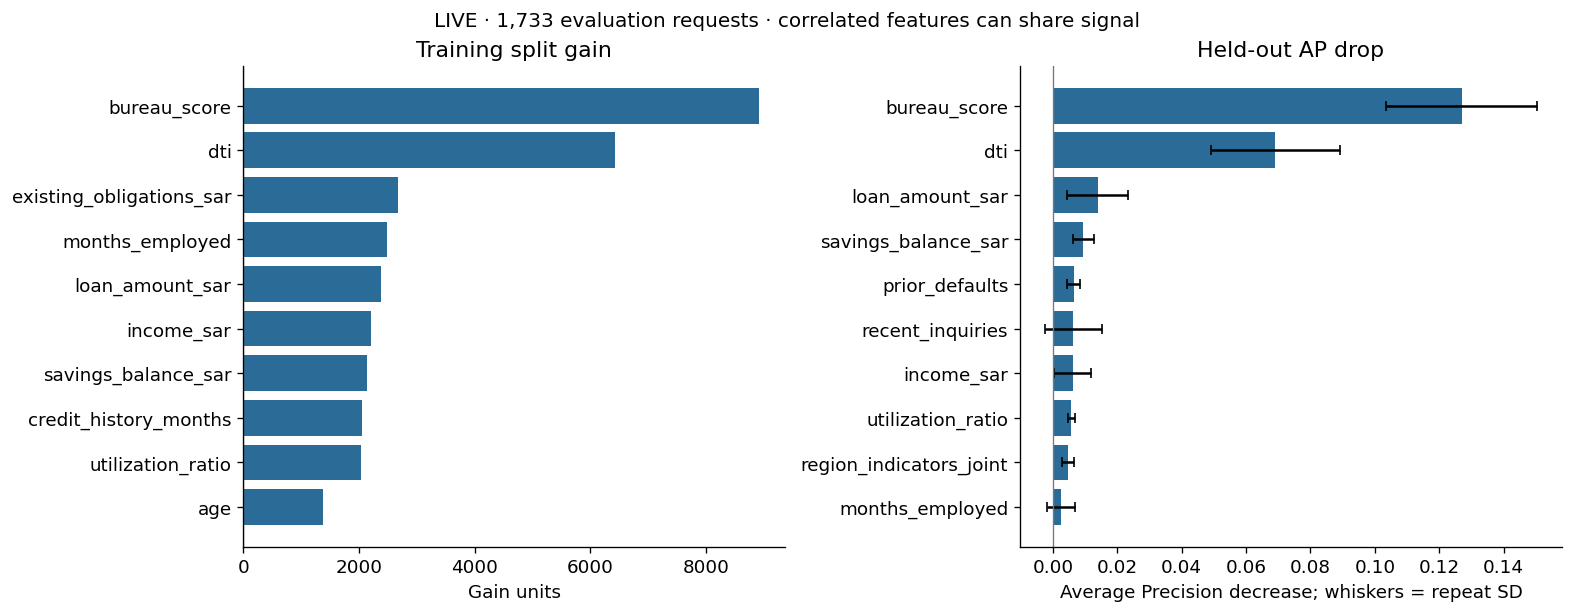

In [19]:
permutation = permutation_report(model, parts["evaluation"], contract, config)
display(permutation[["feature_group", "mean_ap_drop", "repeat_sd", "training_gain"]].head(10).round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for ax, value, title in [(axes[0], "training_gain", "Training split gain"), (axes[1], "mean_ap_drop", "Held-out AP drop")]:
    top = permutation.nlargest(10, value).sort_values(value)
    ax.barh(top.feature_group, top[value], color="#2b6b98",
            xerr=top.repeat_sd if value == "mean_ap_drop" else None, capsize=3)
    ax.axvline(0, color="#777", lw=.8); ax.set_title(title)
    ax.set_xlabel("Gain units" if value == "training_gain" else "Average Precision decrease; whiskers = repeat SD")
fig.suptitle(f"LIVE · {len(evaluation):,} evaluation requests · correlated features can share signal", fontsize=12)
fig.savefig(ARTIFACTS / "permutation_importance.png", bbox_inches="tight"); plt.show()

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>4. Read the global SHAP explanation and its unit</h2>
<p>A fixed random evaluation sample is explained with TreeSHAP for the raw weighted model. The background is the training tree-path distribution; displayed feature values are the model inputs after fit-only imputation.</p>
<p><strong>raw margin = base value + Σ SHAP</strong>, followed by <strong>raw probability = sigmoid(raw margin)</strong>. SHAP values here are in <strong>log-odds</strong>, not probability points. Do not transform each contribution separately and add the transformed values. <code>sigmoid(base_value)</code> is not necessarily the mean predicted probability.</p>
<p>Read the beeswarm in four steps: mean absolute magnitude for rank, sign for score direction, colour for feature value and spread for heterogeneous effects. This explains model behaviour; it does not establish causality or fairness.</p>
<p>If the labelled educational example appears, it is for discussion only and cannot be submitted as the learner's own run.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>4. اقرأ تفسير SHAP العام ووحدته</h2>
<p>تُفسّر عينة عشوائية ثابتة من التقييم باستخدام TreeSHAP للنموذج الخام الموزون. تمثل الخلفية توزيع مسارات أشجار التدريب، وقيم الخصائص المعروضة هي مدخلات النموذج بعد التعويض المتعلم من fit فقط.</p>
<p><strong>raw margin = base value + مجموع SHAP</strong> ثم <strong>raw probability = sigmoid(raw margin)</strong>. قيم SHAP هنا بوحدة <strong>log-odds</strong> وليست نقاط احتمال. لا تحوّل كل مساهمة منفردة ثم تجمع القيم المحولة. كما أن <code>sigmoid(base_value)</code> ليس بالضرورة متوسط الاحتمالات المتوقعة.</p>
<p>اقرأ beeswarm بأربع خطوات: متوسط القيمة المطلقة للترتيب، والإشارة لاتجاه الدرجة، واللون لقيمة الخاصية، والانتشار لاختلاف الأثر. هذا تفسير لسلوك النموذج ولا يثبت السببية أو العدالة.</p>
<p>إذا ظهر المثال التعليمي الموسوم فهو للمناقشة فقط ولا يصلح للتسليم كتجربة المتدرب.</p>
</td>
</tr>
</table>

,feature,mean_absolute_shap_log_odds
4,bureau_score,0.9042
5,dti,0.5437
2,loan_amount_sar,0.3490
10,savings_balance_sar,0.2169
9,existing_obligations_sar,0.2022
8,prior_defaults,0.1830
6,months_employed,0.1584
1,income_sar,0.1549
7,recent_inquiries,0.1492
13,utilization_ratio,0.1287


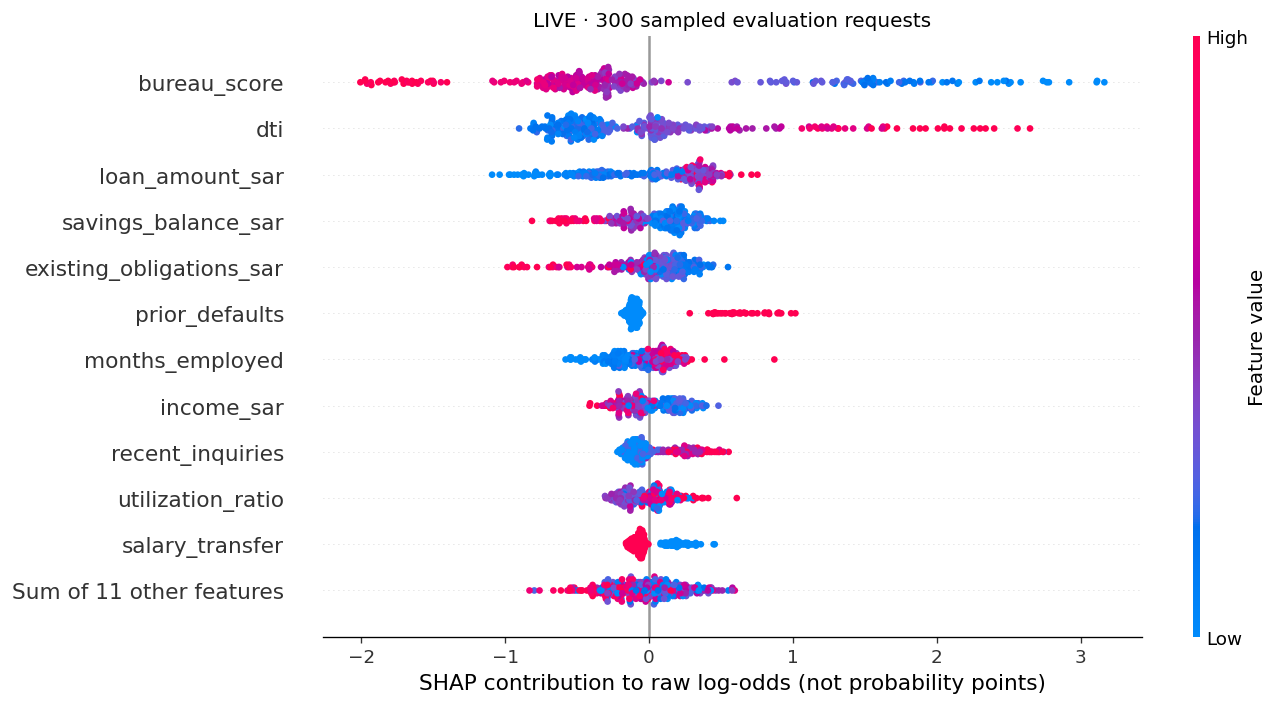

Maximum additivity error: 5.6968318951078345e-15


In [20]:
try:
    if USE_SHAP_EXAMPLE:
        raise ShapBudgetExpired("Educational example requested.")
    shap_arrays, shap_metadata = explain_sample(model, parts["evaluation"], contract, config)
except ShapBudgetExpired:
    shap_arrays, shap_metadata = load_shap_example(ROOT / "data/day4_shap_example.npz",
        ROOT / "data/day4_shap_example.json", model, parts["evaluation"], contract, ASSESSMENT_MODE)

import shap
EXPLANATION_SOURCE = shap_metadata["source"]
if EXPLANATION_SOURCE != "LIVE":
    print("EDUCATIONAL_EXAMPLE — مثال موسوم للمناقشة، غير صالح للتسليم كتجربتك. أعد SHAP لاحقًا.")
explanation = shap.Explanation(values=shap_arrays["values"], base_values=shap_arrays["base_values"],
    data=shap_arrays["data"], feature_names=list(shap_arrays["feature_names"]))
shap_global = pd.DataFrame({"feature": shap_arrays["feature_names"],
    "mean_absolute_shap_log_odds": np.abs(shap_arrays["values"]).mean(axis=0)}).sort_values("mean_absolute_shap_log_odds", ascending=False)
display(shap_global.head(10).round(4))
plt.figure()
shap.plots.beeswarm(explanation, max_display=12, show=False, plot_size=(11, 6.5))
plt.xlabel("SHAP contribution to raw log-odds (not probability points)")
plt.title(f"{EXPLANATION_SOURCE} · {len(shap_arrays['application_ids'])} sampled evaluation requests", fontsize=12)
plt.savefig(ARTIFACTS / "shap_beeswarm.png", bbox_inches="tight"); plt.show()
print("Maximum additivity error:", shap_metadata["max_additivity_error"])

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>5. Explain one high-score synthetic request</h2>
<p>The lab selects the highest raw score inside the SHAP sample without using the observed outcome. The waterfall displays the largest contributions and groups the remainder; the complete contribution vector is preserved in the evidence file.</p>
<p>At most three reason statements are derived from actual positive contributions. Check whether the displayed input was imputed before interpreting it. A positive contribution does not mean the feature is always high, and changing the feature does not guarantee a changed outcome.</p>
<p>The <code>bureau_score ±1</code> perturbation is a narrow local stability check. It is not a guarantee for every request, feature or future period.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>5. فسّر طلبًا اصطناعيًا مرتفع الدرجة</h2>
<p>يختار اللاب أعلى درجة خام داخل عينة SHAP دون استخدام النتيجة المرصودة. تعرض waterfall أكبر الإسهامات وتجمع البقية، مع حفظ متجه الإسهامات الكامل في ملف الأدلة.</p>
<p>تُشتق ثلاث عبارات سبب كحد أقصى من الإسهامات الموجبة الفعلية. تحقّق أولًا هل القيمة المعروضة عُوّضت قبل تفسيرها. لا تعني المساهمة الموجبة أن الخاصية مرتفعة دائمًا، ولا يضمن تغيير الخاصية تغير النتيجة.</p>
<p>اختبار <code>bureau_score ±1</code> فحص محلي ضيق للاستقرار، وليس ضمانًا لكل طلب أو خاصية أو فترة مستقبلية.</p>
</td>
</tr>
</table>

TR-009585 | raw score=0.9031 | calibrated probability=0.4795


,feature,value_used,was_imputed,contribution_log_odds,reason_ar
0,bureau_score,497.0000,False,2.269325,استخدم النموذج درجة ائتمانية اصطناعية عند الطل...
1,dti,1.2806,False,1.198145,استخدم النموذج نسبة الالتزام مع القسط المقترح ...
2,loan_amount_sar,93437.2900,False,0.200725,استخدم النموذج مبلغ التمويل المطلوب بالقيمة 93...


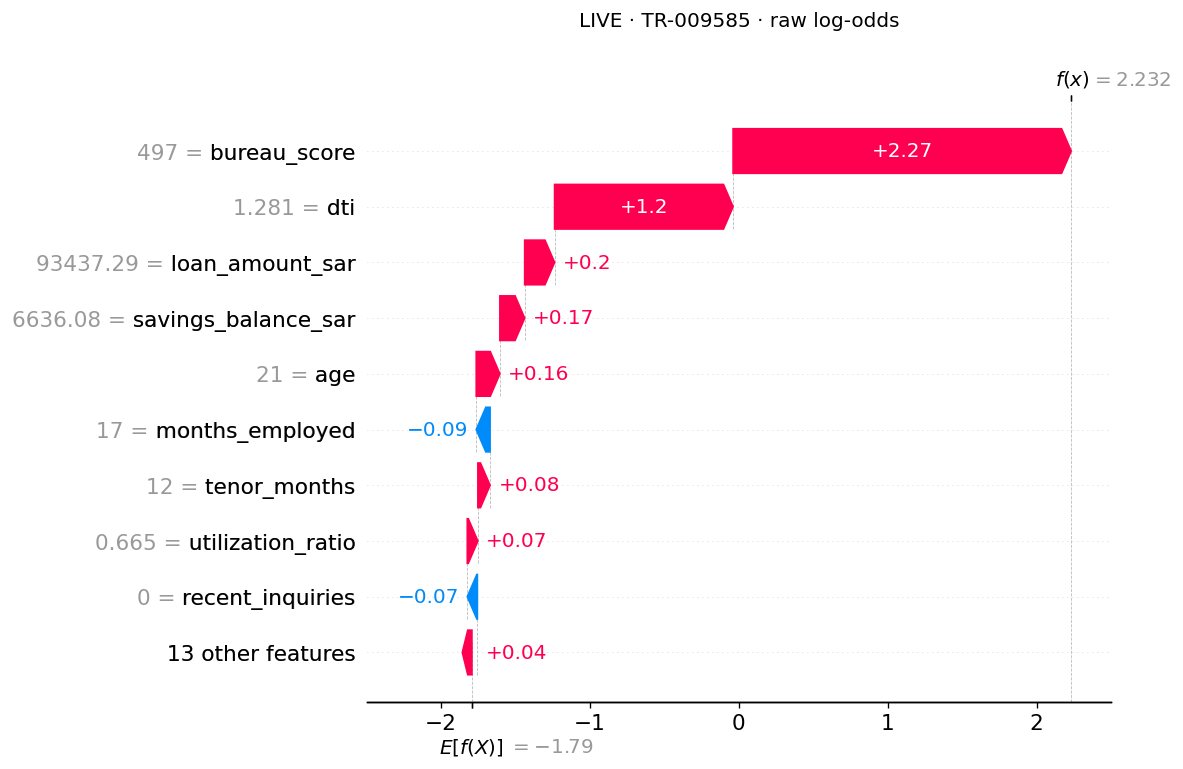

,perturbation,bureau_score_used,raw_probability,calibrated_probability,top_positive_features,shared_top_reasons,reference_reasons,source
0,bureau_score +0,497.0,0.903079,0.479518,bureau_score|dti|loan_amount_sar,3,3,LIVE
1,bureau_score -1,496.0,0.903079,0.479518,bureau_score|dti|loan_amount_sar,3,3,LIVE
2,bureau_score +1,498.0,0.903079,0.479518,bureau_score|dti|loan_amount_sar,3,3,LIVE


In [21]:
local_index = int(np.argmax(shap_arrays["raw_margin"]))
local_id = str(shap_arrays["application_ids"][local_index])
case = parts["evaluation"].set_index("application_id", drop=False).loc[[local_id]]
descriptions = {f["name"]: f["description_ar"] for f in contract["features"]}
reasons = reason_codes(shap_arrays["values"][local_index], shap_arrays["feature_names"],
    shap_arrays["data"][local_index], descriptions)
reasons["application_id"] = local_id
reasons["was_imputed"] = [bool(case.iloc[0][feature] != case.iloc[0][feature]) for feature in reasons.feature]
reasons["source"] = EXPLANATION_SOURCE
raw_local = float(expit(shap_arrays["raw_margin"][local_index]))
cal_local = float(map_probability(raw_local, mapping))
print(f"{local_id} | raw score={raw_local:.4f} | calibrated probability={cal_local:.4f}")
display(reasons[["feature", "value_used", "was_imputed", "contribution_log_odds", "reason_ar"]])
plt.figure()
shap.plots.waterfall(explanation[local_index], max_display=10, show=False)
plt.title(f"{EXPLANATION_SOURCE} · {local_id} · raw log-odds", fontsize=12, pad=45)
plt.savefig(ARTIFACTS / "shap_waterfall.png", bbox_inches="tight"); plt.show()
if EXPLANATION_SOURCE == "LIVE":
    local_checks = local_stability(model, case, contract, mapping)
    local_checks["source"] = "LIVE"
    display(local_checks)
else:
    local_checks = pd.DataFrame(columns=["perturbation", "bureau_score_used", "raw_probability", "calibrated_probability",
        "top_positive_features", "shared_top_reasons", "reference_reasons", "source"])
    print("Local perturbation check skipped in example mode; do not claim it ran.")

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>6. Test calibration on a separate period</h2>
<p>Sigmoid is learned on calibration rows only, without new class weights. The fitted model and calibrator are then frozen and measured on evaluation.</p>
<p>Compare ROC-AUC and Average Precision for ranking, and Brier score, log-loss and ECE for probability quality. A lower Brier score alone does not prove perfect calibration.</p>
<p>ECE uses ten equal-width bins: Σ(bin count ÷ all rows × |mean probability − observed rate|). Empty bins remain visible and every bin count is reported. ECE depends on bin boundaries and sample size; sparse bins are weak evidence.</p>
<p>A single monotone sigmoid mapping preserves the ordering of this model, but calibration is not guaranteed to improve. Isotonic calibration is optional and requires caution with the small number of calibration positives.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>6. اختبر المعايرة على فترة منفصلة</h2>
<p>يتعلم sigmoid من صفوف calibration فقط دون أوزان فئات جديدة. ثم يُثبّت النموذج والمعاير وتُقاس النتائج على evaluation.</p>
<p>قارن ROC-AUC وAverage Precision للترتيب، وBrier وlog-loss وECE لجودة الاحتمال. لا يثبت انخفاض Brier وحده المعايرة المثالية.</p>
<p>يستخدم ECE عشر حاويات متساوية العرض: مجموع (عدد الحاوية ÷ جميع الصفوف × |متوسط الاحتمال − التكرار المرصود|). تبقى الحاويات الفارغة ظاهرة ويُعرض عدد كل حاوية. يتأثر ECE بحدود الحاويات وحجم العينة؛ الحاويات القليلة دليل ضعيف.</p>
<p>يحافظ تحويل sigmoid المتزايد الواحد على ترتيب هذا النموذج، لكن التحسن غير مضمون. المعايرة isotonic توسع اختياري يحتاج حذرًا مع قلة الموجبات في عينة المعايرة.</p>
</td>
</tr>
</table>

,rows,positives,roc_auc,average_precision,brier,ece,log_loss
raw,1733,139,0.770804,0.258677,0.113027,0.146871,0.357993
sigmoid,1733,139,0.770804,0.258677,0.067112,0.022486,0.246749


Measured change (after - before): Brier -0.04592, ECE -0.12438


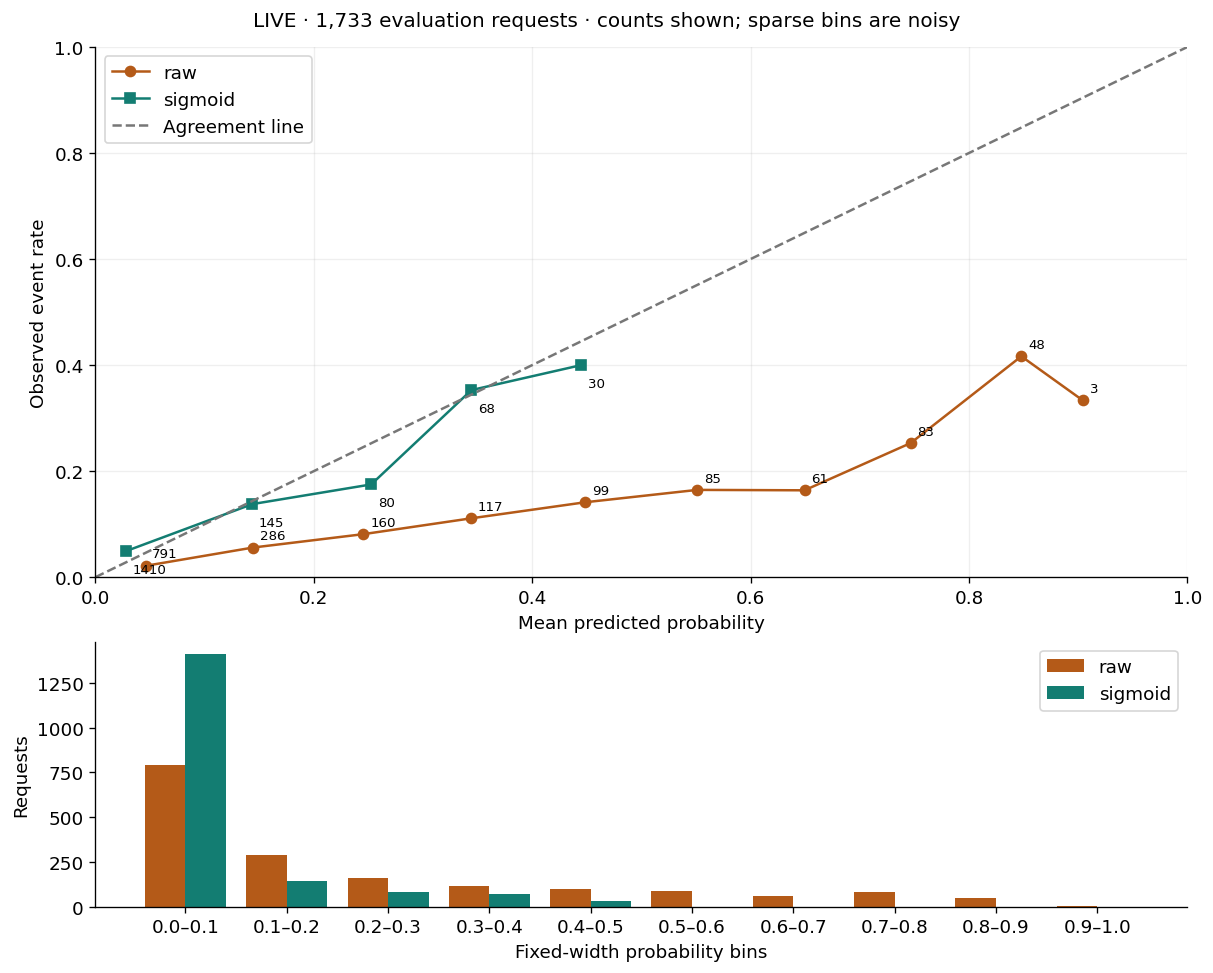

In [22]:
calibration_metrics, bin_tables = {}, []
for label, column in [("raw", "raw_probability"), ("sigmoid", "calibrated_probability")]:
    calibration_metrics[label] = probability_metrics(evaluation[TARGET], evaluation[column])
    table = reliability_table(evaluation[TARGET], evaluation[column]); table["variant"] = label
    bin_tables.append(table)
reliability = pd.concat(bin_tables, ignore_index=True)
display(pd.DataFrame(calibration_metrics).T[["rows", "positives", "roc_auc", "average_precision", "brier", "ece", "log_loss"]].round(5))
brier_delta = calibration_metrics["sigmoid"]["brier"] - calibration_metrics["raw"]["brier"]
ece_delta = calibration_metrics["sigmoid"]["ece"] - calibration_metrics["raw"]["ece"]
print(f"Measured change (after - before): Brier {brier_delta:+.5f}, ECE {ece_delta:+.5f}")
fig, axes = plt.subplots(2, 1, figsize=(10, 8), layout="constrained", gridspec_kw={"height_ratios": [2, 1]})
for label, color, marker in [("raw", "#b45a18", "o"), ("sigmoid", "#137d72", "s")]:
    bins = reliability[reliability.variant == label]; nonempty = bins[bins['count'] > 0]
    axes[0].plot(nonempty.mean_probability, nonempty.observed_rate, marker=marker, color=color, label=label)
    for row in nonempty.itertuples():
        axes[0].annotate(str(row.count), (row.mean_probability, row.observed_rate), xytext=(4, 5 if label == "raw" else -13), textcoords="offset points", fontsize=8)
    positions = bins['bin'] + (-.2 if label == "raw" else .2)
    axes[1].bar(positions, bins['count'], width=.4, color=color, label=label)
axes[0].plot([0, 1], [0, 1], linestyle="--", color="#777", label="Agreement line")
axes[0].set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean predicted probability", ylabel="Observed event rate")
axes[0].legend(); axes[0].grid(alpha=.2)
axes[1].set(xticks=np.arange(10), xticklabels=[f"{i/10:.1f}–{(i+1)/10:.1f}" for i in range(10)], ylabel="Requests", xlabel="Fixed-width probability bins")
axes[1].legend()
fig.suptitle(f"LIVE · {len(evaluation):,} evaluation requests · counts shown; sparse bins are noisy", fontsize=12)
fig.savefig(ARTIFACTS / "reliability_curve.png", bbox_inches="tight"); plt.show()

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>7. Quantify what the stability interval does and does not cover</h2>
<p>The paired bootstrap samples <strong>customers</strong>, keeping each customer's requests together, and compares raw versus calibrated results on the same replicates. It reports 95% percentile intervals for AP and Brier change.</p>
<p>The model and calibrator remain fixed. The interval therefore excludes uncertainty from model training, calibration fitting and future temporal drift. It is not a confidence interval for one applicant's probability.</p>
<p>Quarter-level evaluation metrics describe temporal variation. They are not three independent folds or a confidence interval. Any change designed after viewing evaluation needs new evidence.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>7. حدّد ما تغطيه فترة الاستقرار وما لا تغطيه</h2>
<p>يسحب bootstrap المزدوج <strong>العملاء</strong> مع إبقاء طلبات العميل معًا، ويقارن النتائج الخام والمعايرة على السحبات نفسها. يعرض فترات مئينية 95% لـAP وتغير Brier.</p>
<p>يبقى النموذج والمعاير ثابتين؛ لذلك لا تشمل الفترة عدم يقين تدريب النموذج أو تعلم المعايرة أو الانجراف الزمني المستقبلي. كما أنها ليست فترة ثقة لاحتمال طلب واحد.</p>
<p>تصف مقاييس أرباع التقييم التغير الزمني، وليست طيات مستقلة أو فترة ثقة. أي تعديل يُصمم بعد رؤية التقييم يحتاج إلى دليل جديد.</p>
</td>
</tr>
</table>

,period,variant,rows,positives,average_precision,brier,ece
0,2024Q3,raw,836,78,0.27457,0.11528,0.13397
1,2024Q3,sigmoid,836,78,0.27457,0.07760,0.03229
2,2024Q4,raw,897,61,0.27050,0.11093,0.15890
3,2024Q4,sigmoid,897,61,0.27050,0.05734,0.02434


Paired customer-cluster 95% percentile intervals:


,lower,upper
raw_ap,0.197442,0.337854
calibrated_ap,0.197442,0.337854
brier_change,-0.054177,-0.037409


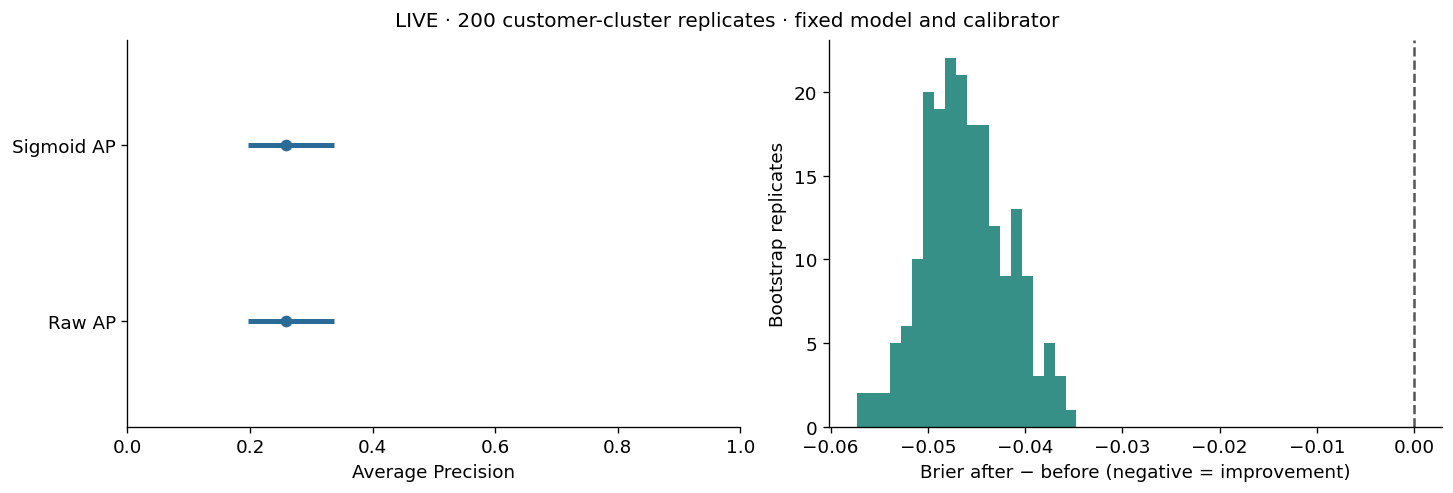

In [23]:
bootstrap, stability_summary = cluster_bootstrap(evaluation, config)
period_rows = []
for period, group in evaluation.groupby(pd.to_datetime(evaluation.application_date).dt.to_period("Q").astype(str)):
    for variant, column in [("raw", "raw_probability"), ("sigmoid", "calibrated_probability")]:
        period_rows.append({"period": period, "variant": variant, **probability_metrics(group[TARGET], group[column])})
period_metrics = pd.DataFrame(period_rows)
display(period_metrics[["period", "variant", "rows", "positives", "average_precision", "brier", "ece"]].round(5))
stability_summary["period_ap_sample_sd"] = {v: float(g.average_precision.std(ddof=1)) for v, g in period_metrics.groupby("variant")}
print("Paired customer-cluster 95% percentile intervals:")
display(pd.DataFrame({key: stability_summary[key] for key in ("raw_ap", "calibrated_ap", "brier_change")}).T)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for i, key in enumerate(("raw_ap", "calibrated_ap")):
    interval = stability_summary[key]
    point = calibration_metrics["raw" if i == 0 else "sigmoid"]["average_precision"]
    if interval is not None:
        axes[0].hlines(i, interval["lower"], interval["upper"], color="#2b6b98", lw=3)
    axes[0].plot(point, i, "o", color="#2b6b98")
axes[0].set(yticks=[0, 1], yticklabels=["Raw AP", "Sigmoid AP"], xlabel="Average Precision", xlim=(0, 1), ylim=(-.6, 1.6))
axes[1].hist(bootstrap.brier_change, bins=20, color="#137d72", alpha=.85)
axes[1].axvline(0, color="#555", linestyle="--"); axes[1].set(xlabel="Brier after − before (negative = improvement)", ylabel="Bootstrap replicates")
fig.suptitle(f"LIVE · {stability_summary['valid']} customer-cluster replicates · fixed model and calibrator", fontsize=12)
fig.savefig(ARTIFACTS / "stability_summary.png", bbox_inches="tight"); plt.show()

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>8. Test whether the review zone fits capacity</h2>
<p>The raw threshold was selected on the policy role only under the 10×FN+FP loss and a 12% capacity ceiling. It is transported through the monotone sigmoid mapping; it is not reselected on evaluation and is not copied from a different Day 3 model.</p>
<p>The ±0.02 probability zone is a diagnostic band for near-threshold cases, not individual uncertainty. When combining it with risk flags, count the union once. Capacity can fail in a later period even before adding the zone.</p>
<p><code>CAPACITY_REVIEW_REQUIRED</code> is a valid finding. Do not raise the ceiling, hide rows or retune the threshold after seeing evaluation. A revised policy must be developed and evaluated with new evidence.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>8. اختبر ملاءمة منطقة المراجعة للسعة</h2>
<p>اختيرت العتبة الخام على دور policy فقط ضمن خسارة 10×FN+FP وسقف سعة 12%. تُنقل عبر تحويل sigmoid المتزايد، ولا يُعاد اختيارها على evaluation ولا تُنسخ من نموذج مختلف في اليوم الثالث.</p>
<p>منطقة الاحتمال ±0.02 نطاق تشخيصي للحالات القريبة من العتبة وليست عدم يقين فرديًا. عند جمعها مع إشارات المخاطر احسب اتحاد المجموعتين مرة واحدة. قد تفشل السعة في فترة لاحقة حتى قبل إضافة المنطقة.</p>
<p>ظهور <code>CAPACITY_REVIEW_REQUIRED</code> نتيجة صحيحة. لا ترفع السقف ولا تُخفِ صفوفًا ولا تعِد ضبط العتبة بعد رؤية التقييم. يجب تطوير السياسة المعدلة وتقييمها بدليل جديد.</p>
</td>
</tr>
</table>

,threshold,flagged,fn,fp,loss_units,capacity,feasible,calibrated_threshold,selection_role
0,0.588195,68,34,47,387.0,70,True,0.17331,policy


,period,rows,capacity,risk_flags,near_threshold,candidate_review,risk_within_capacity,candidate_within_capacity,loss_units
0,2024Q3,836,100,97,23,109,True,False,536.0
1,2024Q4,897,107,109,21,122,False,False,444.0


CAPACITY_REVIEW_REQUIRED | Do not retune on evaluation.


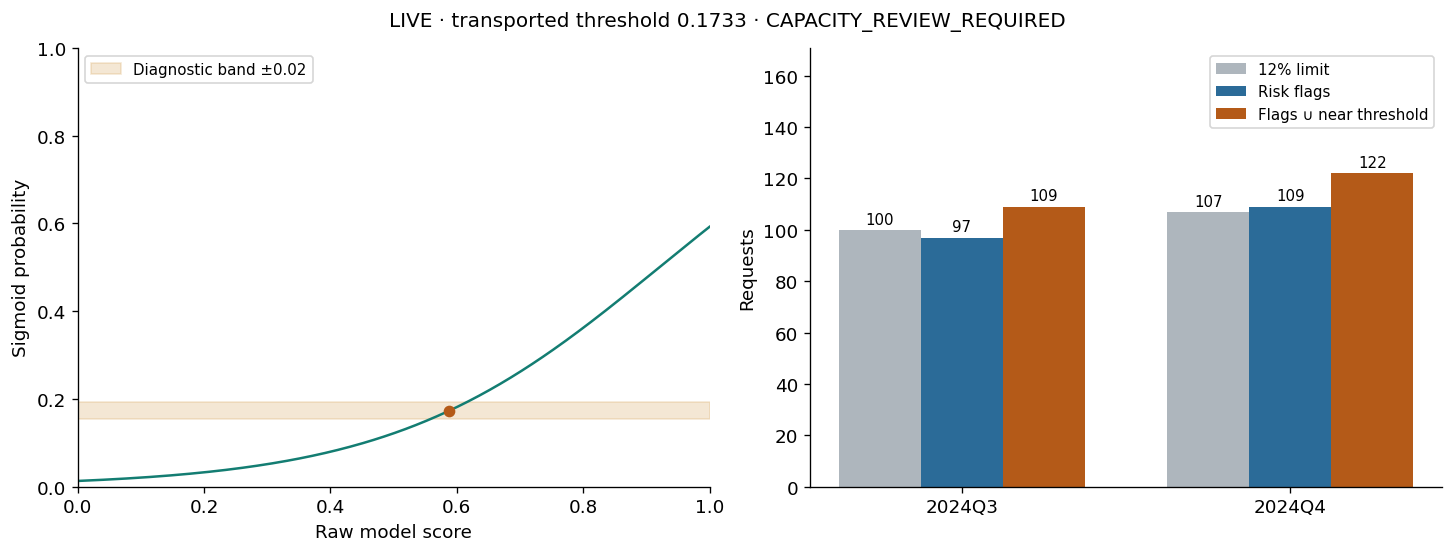

In [24]:
review_flags, capacity_audit, review_band = review_audit(evaluation, chosen_policy["threshold"],
    calibrated_threshold, config.review_half_width)
policy_status = "CAPACITY_REVIEW_REQUIRED" if not capacity_audit.candidate_within_capacity.all() else "WITHIN_OBSERVED_CAPACITY"
display(pd.DataFrame([{**chosen_policy, "calibrated_threshold": calibrated_threshold, "selection_role": "policy"}]))
display(capacity_audit)
print(policy_status, "| Do not retune on evaluation.")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
grid = np.linspace(0, 1, 300)
axes[0].plot(grid, map_probability(grid, mapping), color="#137d72")
axes[0].axhspan(review_band['lower'], review_band['upper'], color="#d7a354", alpha=.25, label="Diagnostic band ±0.02")
axes[0].plot(chosen_policy['threshold'], calibrated_threshold, 'o', color="#b45a18")
axes[0].set(xlim=(0, 1), ylim=(0, 1), xlabel="Raw model score", ylabel="Sigmoid probability")
axes[0].legend(loc="upper left", fontsize=9)
x = np.arange(len(capacity_audit))
for offset, column, label, color in [(-.25, 'capacity', '12% limit', '#aeb6bd'), (0, 'risk_flags', 'Risk flags', '#2b6b98'), (.25, 'candidate_review', 'Flags ∪ near threshold', '#b45a18')]:
    bars = axes[1].bar(x+offset, capacity_audit[column], width=.25, label=label, color=color)
    axes[1].bar_label(bars, padding=2, fontsize=9)
axes[1].set(xticks=x, xticklabels=capacity_audit.period, ylabel="Requests", ylim=(0, capacity_audit.candidate_review.max()*1.4))
axes[1].legend(fontsize=9)
fig.suptitle(f"LIVE · transported threshold {calibrated_threshold:.4f} · {policy_status}", fontsize=12)
fig.savefig(ARTIFACTS / "review_zone.png", bbox_inches="tight"); plt.show()

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>9. Write the interpretation supported by your evidence</h2>
<p>Complete all six fields in <code>responses</code> and cite your measured values and denominators:</p>
<ol><li>global versus local explanation;</li><li>SHAP output unit and background;</li><li>limits of reason statements and correlated features;</li><li>calibration evidence on the separate period;</li><li>what the stability interval includes and excludes;</li><li>the review zone's effect on period capacity.</li></ol>

</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>9. اكتب تفسيرًا تدعمه أدلتك</h2>
<p>أكمل الحقول الستة داخل <code>responses</code> واستشهد بالقيم المقاسة ومقاماتها:</p>
<ol><li>الفرق بين التفسير العام والمحلي؛</li><li>وحدة SHAP وخلفيته؛</li><li>حدود عبارات السبب والخصائص المترابطة؛</li><li>دليل المعايرة على الفترة المنفصلة؛</li><li>ما تشمله فترة الاستقرار وما تستبعده؛</li><li>أثر منطقة المراجعة في سعة كل فترة.</li></ol>
<p>يحوّل اكتمال النصوص بوابة المتدرب إلى جاهز للمراجعة، لكنه لا يتحقق من صحة الإجابات ولا يمنح درجة آلية.</p>
</td>
</tr>
</table>

In [25]:
responses = {
    "global_local": "Across the 1,733 evaluation requests, bureau_score was the most important feature: shuffling it lowered Average Precision by 0.127 across three runs. In the 300-request SHAP sample, it also had the highest average SHAP value (0.904 log-odds), followed by dti (0.544). For TR-009585, the biggest positive contributions were bureau_score (+2.27), dti (+1.20), and loan_amount_sar (+0.20). The global results describe the model overall; the local results explain just this one request.",
    "output_units": "SHAP values are in log-odds (raw margin), not probability points: raw margin = base value + sum of SHAP values. Calibration then adjusts that probability: for TR-009585, 0.9031 raw became 0.4795 calibrated.The background is the training tree-path distribution, and sigmoid(base_value) is not necessarily the mean predicted probability. The additivity error was very small (5.7e-15).",
    "reason_limits": "The three reason statements show which features pushed the model’s score up for this request. They do not explain why someone would default, and changing a feature does not guarantee a different result. Related features can share information, so their individual importance may look smaller. Changing bureau_score by one point did not change this request’s top three reasons, but that is only a small check on one request.",
    "calibration_evidence": "On the evaluation set (1,733 requests, 139 defaults), calibration improved the Brier score from 0.1130 to 0.0671, ECE from 0.1469 to 0.0225, and log loss from 0.358 to 0.247. ROC-AUC stayed at 0.7708 and Average Precision stayed at 0.2587 because calibration kept the ranking the same. ECE also went down in Q3 (0.134 to 0.032 across 836 requests) and Q4 (0.159 to 0.024 across 897 requests). ECE depends on how probability ranges are grouped, so results from groups with few requests should be treated carefully.",
    "stability": "The paired customer-cluster bootstrap gives a 95% percentile interval for AP of 0.197 to 0.338 and for Brier change of -0.054 to -0.037, so the improvement is consistently negative. The interval holds the model and calibrator fixed, so it excludes training uncertainty, calibration-fitting uncertainty and future drift. It is not a confidence interval for any one applicant's probability, and the two quarters are not independent folds.",
    "review_capacity": "The threshold was selected on the policy set using the 10×FN+FP loss and a 12% capacity limit. It flagged 68 of 589 requests, within the limit of 70. The raw threshold was 0.588 and the calibrated threshold was 0.173. On evaluation, the combined review group exceeded capacity in both quarters: 109 of 836 requests in Q3 (limit 100) and 122 of 897 in Q4 (limit 107). Risk flags alone were already over capacity in Q4 (109). The result is CAPACITY_REVIEW_REQUIRED, so I did not retune the threshold on evaluation data.",
}
checkpoint = reflection_check(responses, EXPLANATION_SOURCE)
print(checkpoint["status"], "| Fields to complete:", checkpoint["missing"])

READY_FOR_REVIEW | Fields to complete: []


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>10. Export the report and evidence bundle</h2>
<p>Re-run the export cell after completing <code>responses</code>. Download <code>artifacts/day4_artifacts.zip</code> and keep its <code>artifacts/</code> and <code>reports/</code> structure. Save the executed notebook as <code>notebooks/04_explain_calibrate.ipynb</code>.</p>
<p>The bundle contains 12 CSV tables, six analysis JSON files plus the environment record, a compressed NPZ of complete SHAP values, the LightGBM model text, six PNG figures and <code>reports/INTERPRETABILITY_REPORT.md</code>.</p>
<p>Read probability CSV files with <code>float_precision="round_trip"</code> when exact round trips matter. A technically successful run can still require learner work or capacity review. Educational-example mode is not submittable and is blocked in assessment mode.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>10. صدّر التقرير وحزمة الأدلة</h2>
<p>أعد تشغيل خلية التصدير بعد إكمال <code>responses</code>. نزّل <code>artifacts/day4_artifacts.zip</code> واحتفظ بهيكل <code>artifacts/</code> و<code>reports/</code>. احفظ الدفتر المنفذ باسم <code>notebooks/04_explain_calibrate.ipynb</code>.</p>
<p>تضم الحزمة 12 جدول CSV وستة ملفات JSON تحليلية إضافة إلى سجل البيئة، وملف NPZ مضغوط لقيم SHAP الكاملة، ونص نموذج LightGBM، وستة رسوم PNG، وملف <code>reports/INTERPRETABILITY_REPORT.md</code>.</p>
<p>استخدم <code>float_precision="round_trip"</code> عند إعادة قراءة ملفات الاحتمالات إذا كانت الاستعادة الدقيقة مهمة. قد ينجح التشغيل تقنيًا مع بقاء عمل على المتدرب أو مراجعة للسعة. وضع المثال التعليمي غير صالح للتسليم ويُحظر في وضع التقييم.</p>
</td>
</tr>
</table>

In [26]:
def json_safe(value):
    if isinstance(value, dict): return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, np.ndarray)): return [json_safe(v) for v in value]
    if isinstance(value, (np.integer,)): return int(value)
    if isinstance(value, (np.bool_,)): return bool(value)
    if isinstance(value, (float, np.floating)): return float(value) if np.isfinite(value) else None
    return value

technical_status = "TECHNICAL_READY" if EXPLANATION_SOURCE == "LIVE" else "EXAMPLE_ONLY_NOT_SUBMITTABLE"
calibration_payload = {"source": "LIVE", "evaluation_role": "evaluation", "metrics": calibration_metrics,
    "mapping": mapping, "policy_selection": chosen_policy, "calibrated_threshold": calibrated_threshold,
    "review_band": review_band, "capacity_status": policy_status, "brier_change": brier_delta, "ece_change": ece_delta,
    "prior_course_exposure": True, "not_a_final_untouched_test": True}
run = {"technical_status": technical_status, "learner_status": checkpoint["status"],
    "explanation_source": EXPLANATION_SOURCE, "model_calibration_source": "LIVE", "config": asdict(config),
    "assessment_mode": ASSESSMENT_MODE, "lab_revision": LAB_REVISION, "support_sha256": SUPPORT_HASHES,
    "previous_support": PREVIOUS_SUPPORT, "data_revision": COURSE_REVISION, "python": platform.python_version(),
    "elapsed_seconds": round(time.perf_counter()-RUN_STARTED, 2), "capacity_status": policy_status,
    "challenge_used_for_modeling": False, "no_automatic_grade": True}
csv_outputs = {"day4_roles.csv": assignments, "day4_predictions.csv": predictions,
    "permutation_importance.csv": permutation, "day4_shap_global.csv": shap_global.assign(source=EXPLANATION_SOURCE),
    "day4_reason_codes.csv": reasons, "day4_local_stability.csv": local_checks,
    "day4_reliability_bins.csv": reliability, "day4_period_metrics.csv": period_metrics,
    "day4_bootstrap.csv": bootstrap, "day4_policy_sweep.csv": policy_sweep,
    "day4_review_flags.csv": review_flags, "day4_capacity.csv": capacity_audit}
for filename, table in csv_outputs.items(): table.to_csv(ARTIFACTS / filename, index=False)
np.savez_compressed(ARTIFACTS / "shap_values_sample.npz", **shap_arrays)
model.named_steps["model"].booster_.save_model(str(ARTIFACTS / "day4_model.txt"))
json_outputs = {"calibration_metrics.json": calibration_payload, "day4_shap_metadata.json": shap_metadata,
    "day4_stability_summary.json": stability_summary, "day4_provenance.json": provenance,
    "day4_reflection.json": {"responses": responses, "checkpoint": checkpoint}, "day4_run.json": run}
for filename, payload in json_outputs.items():
    (ARTIFACTS / filename).write_text(json.dumps(json_safe(payload), ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
answer = lambda key: responses[key].strip() or "[اكتب تفسيرك من نتائجك هنا]"
status_text = "مثال تعليمي غير صالح للتسليم كتجربة شخصية" if EXPLANATION_SOURCE != "LIVE" else ("مسودة — أكمل تفسيرك" if checkpoint['missing'] else "جاهز للمراجعة؛ لا يعني اعتمادًا أو درجة")
reason_text = "\n".join(f"- {r.reason_ar} (SHAP={r.contribution_log_odds:+.4f} log-odds؛ قيمة معوضة: {r.was_imputed})" for r in reasons.itertuples())
capacity_text = "\n".join(f"- {r.period}: السقف {r.capacity}، الإشارات {r.risk_flags}، اتحاد المراجعة {r.candidate_review}." for r in capacity_audit.itertuples())
report = f"""# تقريرك: التفسير والمعايرة — Tamweel Lite

**الحالة:** {status_text}

**مصدر التفسير:** {EXPLANATION_SOURCE}. **النموذج والمعايرة:** LIVE. **السعة:** {policy_status}.

## النموذج والأدوار
LightGBM موزون، {config.trees} شجرة. الهدف حدث تعثر اصطناعي خلال90 يومًا بعد الطلب. الأدوار منفصلة زمنيًا وبالعملاء: تدريب {len(parts['fit'])}، معايرة {len(parts['calibration'])} ({int(parts['calibration'][TARGET].sum())} موجب)، سياسة {len(parts['policy'])}، تقييم {len(evaluation)}. الفجوات والتداخلات مستبعدة. سبق استخدام بيانات التقييم في الدورة، فهي ليست اختبارًا نهائيًا لم يمسّ.

## التفسير العام والمحلي
Permutation يقيس انخفاضAP على التقييم؛ إشارات المنطقة تُبدّل معًا. SHAP يفسر النموذج الخام بوحدةlog-odds وخلفية مسارات أشجار التدريب. base+sum(SHAP)=raw margin، ثمsigmoid للمجموع فقط. القيم ليست نقاط احتمال ولا تفسيرًا مباشرًا للنموذج المعاير.

{answer('global_local')}

{answer('output_units')}

الطلب الاصطناعي {local_id}: الدرجة الخام {raw_local:.5f} والاحتمال المعاير {cal_local:.5f}. اختير أعلى درجة داخل عينةSHAP دون استخدام النتيجة الفعلية.
{reason_text}

{answer('reason_limits')}

## دليل المعايرة
على {len(evaluation)} صفًا و{int(evaluation[TARGET].sum())} موجب: Brier {calibration_metrics['raw']['brier']:.6f} → {calibration_metrics['sigmoid']['brier']:.6f}؛ ECE {calibration_metrics['raw']['ece']:.6f} → {calibration_metrics['sigmoid']['ece']:.6f}. عشر حاويات متساوية العرض مع أعدادها فيday4_reliability_bins.csv. AP {calibration_metrics['raw']['average_precision']:.6f} → {calibration_metrics['sigmoid']['average_precision']:.6f}؛ ROC-AUC {calibration_metrics['raw']['roc_auc']:.6f} → {calibration_metrics['sigmoid']['roc_auc']:.6f}. هذه نتائج هذه العينة وليست ضمانًا لتحسن مستقبلي.

{answer('calibration_evidence')}

## الاستقرار
{stability_summary['valid']} تكرارbootstrap صالح بسحب العملاء؛ فترات مئينية95% مع تثبيت النموذج والمعاير. لا تشمل تعلم النموذج أو المعايرة أو الانجراف المستقبلي، ولا تصف احتمال فرد. انحرافAP بين ربعي التقييم وصفي فقط. اختبارbureau_score±1 {'نُفذ؛ راجع day4_local_stability.csv' if EXPLANATION_SOURCE == 'LIVE' else 'لم ينفذ في وضع المثال'}.

{answer('stability')}

## العتبة ومنطقة المراجعة
العتبة الخام {chosen_policy['threshold']!r} اختيرت علىpolicy بخسارة10×FN+FP وسقف12% ثم نُقلت إلى {calibrated_threshold!r}. لم تعدل باستخدام التقييم. المنطقة[{review_band['lower']:.5f}, {review_band['upper']:.5f}] تشخيصية بعرض±0.02 وليست فترة ثقة. الاتحاد يحسب الطلب مرة واحدة.
{capacity_text}

{answer('review_capacity')}

عند تجاوز السعة، وثّق الحاجة إلى تصميم سياسة جديدة على بيانات تطوير وتقييمها بدليل جديد. لا ترفع السقف ولا تقص الحالات بعد رؤية النتيجة. التفسير ليس سببية أو شهادة عدالة، والخسارة وحدات تعليمية لا رسوم أو خصم درجات. لا يستخدم هذا التمرين لتمويل حقيقي.
"""
(REPORTS / "INTERPRETABILITY_REPORT.md").write_text(report, encoding="utf-8")
figures = ["permutation_importance.png", "shap_beeswarm.png", "shap_waterfall.png", "reliability_curve.png", "stability_summary.png", "review_zone.png"]
artifact_files = list(csv_outputs) + list(json_outputs) + figures + ["environment.json", "shap_values_sample.npz", "day4_model.txt"]
with zipfile.ZipFile(ARTIFACTS / "day4_artifacts.zip", "w", zipfile.ZIP_DEFLATED) as bundle:
    for filename in artifact_files: bundle.write(ARTIFACTS / filename, "artifacts/" + filename)
    bundle.write(REPORTS / "INTERPRETABILITY_REPORT.md", "reports/INTERPRETABILITY_REPORT.md")
print(f"{technical_status} | {checkpoint['status']} | {EXPLANATION_SOURCE} | CPU")
print(f"Saved {len(artifact_files)+1} files in day4_artifacts.zip | {policy_status}")

TECHNICAL_READY | READY_FOR_REVIEW | LIVE | CPU
Saved 28 files in day4_artifacts.zip | CAPACITY_REVIEW_REQUIRED


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Before moving to Day 5</h2>
<p>Open all six figures and verify units, denominators, labels and explanation source. Be able to explain why one monotone mapping can preserve rank, why SHAP contributions do not establish causality and why near-threshold review needs a separate capacity calculation.</p>
<p>If an educational SHAP example was used, rerun live SHAP on CPU before submission; never present the example as your own experiment.</p>
<p><a href="https://github.com/almiyead-rgb/sda-dsc-211-student-template/blob/main/DAY4_GUIDE.md">Day 4 guide</a> · <a href="https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html">TreeExplainer output units</a> · <a href="https://scikit-learn.org/1.6/modules/generated/sklearn.calibration.CalibratedClassifierCV.html">Frozen-model calibration</a></p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>قبل الانتقال إلى اليوم الخامس</h2>
<p>افتح الرسوم الستة وتحقق من الوحدات والمقامات والعناوين ومصدر التفسير. يجب أن تستطيع شرح سبب محافظة تحويل متزايد واحد على الترتيب، ولماذا لا تثبت مساهمات SHAP السببية، ولماذا تحتاج مراجعة الحالات القريبة إلى حساب مستقل للسعة.</p>
<p>إذا استُخدم مثال SHAP التعليمي فأعد تشغيل SHAP المباشر على CPU قبل التسليم، ولا تعرض المثال بوصفه تجربتك.</p>
<p><a href="https://github.com/almiyead-rgb/sda-dsc-211-student-template/blob/main/DAY4_GUIDE.md">دليل اليوم الرابع</a> · <a href="https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html">وحدات TreeExplainer</a> · <a href="https://scikit-learn.org/1.6/modules/generated/sklearn.calibration.CalibratedClassifierCV.html">معايرة نموذج مجمد</a></p>
</td>
</tr>
</table>

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Daily question · Interpretation and calibration</h2>
<p><strong>Which feature was most important in your explanation, and why does that not prove causality?</strong><br><br>Write a short answer under <code>Day 4</code> in the <code>Daily answers | الإجابات اليومية</code> section of your repository README. Then download this executed notebook and the required generated files and upload them on the same day.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>سؤال اليوم · التفسير والمعايرة</h2>
<p><strong>ما أهم خاصية في تفسيرك، ولماذا لا يثبت ذلك السببية؟</strong><br><br>اكتب إجابة مختصرة تحت <code>Day 4 | اليوم 4</code> في قسم <code>Daily answers | الإجابات اليومية</code> داخل README في مستودعك، ثم نزّل هذا الدفتر بعد التنفيذ وملفات النتائج المطلوبة وارفعها في اليوم نفسه.</p>
</td>
</tr>
</table>

---
# Gate 5: Final model and delivery

_Executed notebook `notebooks/05_final_model.ipynb`._

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Day 5 · Choose what is worth shipping and deliver your project</h2>
<p><strong>SDA-DSC-211 · Tamweel Lite · 60-minute lab · Free CPU</strong></p>
<p>Complete the same project. Compare three single models with equal averaging, weighted averaging and stacking, then decide whether complexity earns its place. Export a reproducible final model, <code>submission.csv</code>, a model card and a documented project bundle.</p>
<p><strong>Deliverables:</strong> nested-forward OOF evidence, ensemble decision, frozen policy, calibrated final model, challenge predictions, model card, project README and verified bundle.</p>
<p><strong>Boundary:</strong> <code>KEEP SINGLE</code> is a valid result when supported by evidence. The data are synthetic and cannot support real financing decisions. Technical completion is not a grade or a submission receipt.</p>
<table><tr><th>Minutes</th><th>Your task</th></tr><tr><td>0–10</td><td>Inspect data roles and OOF diversity</td></tr><tr><td>10–25</td><td>Compare averaging and nested stacking</td></tr><tr><td>25–35</td><td>Apply the worth-it gate and freeze the threshold</td></tr><tr><td>35–45</td><td>Freeze calibration and verify challenge predictions</td></tr><tr><td>45–55</td><td>Write the model card and merge earlier evidence</td></tr><tr><td>55–60</td><td>Download the bundle and save the executed notebook</td></tr></table>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>اليوم الخامس · اختر ما يستحق وسلّم مشروعك</h2>
<p><strong>SDA-DSC-211 · Tamweel Lite · لاب 60 دقيقة · CPU مجاني</strong></p>
<p>أكمل المشروع نفسه. قارن ثلاثة نماذج مفردة بمتوسط بسيط ومتوسط موزون وStacking، ثم قرر هل يستحق التعقيد مكانه. صدّر نموذجًا نهائيًا قابلًا لإعادة التشغيل وملف <code>submission.csv</code> وبطاقة نموذج وحزمة مشروع موثقة.</p>
<p><strong>التسليم:</strong> أدلة OOF أمامية متداخلة، وقرار التجميع، وسياسة مجمدة، ونموذج نهائي معاير، وتنبؤات التحدي، وبطاقة النموذج، وREADME المشروع، وحزمة متحقق منها.</p>
<p><strong>الحدود:</strong> نتيجة <code>KEEP SINGLE</code> صحيحة عندما تدعمها الأدلة. البيانات اصطناعية ولا تصلح لقرارات تمويل فعلية. الإكمال التقني ليس درجة أو إيصال تسليم.</p>
<table><tr><th>الدقائق</th><th>مهمتك</th></tr><tr><td>0–10</td><td>افحص أدوار البيانات وتنوع OOF</td></tr><tr><td>10–25</td><td>قارن المتوسط والتجميع المتداخل</td></tr><tr><td>25–35</td><td>طبّق بوابة الجدوى وثبّت العتبة</td></tr><tr><td>35–45</td><td>ثبّت المعايرة وتحقق من تنبؤات التحدي</td></tr><tr><td>45–55</td><td>اكتب بطاقة النموذج وادمج الأدلة السابقة</td></tr><tr><td>55–60</td><td>نزّل الحزمة واحفظ الدفتر المنفذ</td></tr></table>
</td>
</tr>
</table>

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Official daily requirement</h2>
<p>Run all cells, compare the generated files with EXPECTED_RESULTS.md, then answer only the single question at the end of this notebook in your repository README. Legacy reflection variables inside code cells are compatibility fields; leave them unchanged.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>المطلوب اليومي المعتمد</h2>
<p>شغّل جميع الخلايا، وقارن الملفات الناتجة بصفحة EXPECTED_RESULTS.md، ثم أجب فقط عن السؤال الواحد في نهاية هذا الدفتر داخل README في مستودعك. حقول الانعكاس القديمة داخل خلايا الكود مخصصة للتوافق؛ اتركها دون تعديل.</p>
</td>
</tr>
</table>

In [12]:
import importlib.metadata as metadata
import os
import signal
import subprocess
import sys

EXPECTED_VERSIONS = {
    "numpy": "2.1.3",
    "pandas": "2.2.3",
    "scipy": "1.16.3",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "xgboost": "3.4.1",
    "lightgbm": "4.6.0",
    "shap": "0.52.0",
    "numba": "0.61.2",
    "optuna": "4.5.0",
}

different_versions = []

for package_name, expected_version in EXPECTED_VERSIONS.items():
    try:
        current_version = metadata.version(package_name)
    except metadata.PackageNotFoundError:
        current_version = None

    if current_version != expected_version:
        different_versions.append(
            f"{package_name}: {current_version or 'غير مثبت'} → {expected_version}"
        )

if different_versions:
    print("سيتم تجهيز بيئة الدورة بالإصدارات المعتمدة:")
    for item in different_versions:
        print("-", item)

    requirements_url = (
        "https://raw.githubusercontent.com/"
        "almiyead-rgb/sda-dsc-211-student-template/"
        "fe0c0204e6076a7ac2139b7336485a097343fb8a/"
        "requirements-colab.txt"
    )

    constraints_url = (
        "https://raw.githubusercontent.com/"
        "almiyead-rgb/sda-dsc-211-student-template/"
        "fe0c0204e6076a7ac2139b7336485a097343fb8a/"
        "constraints.txt"
    )

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "--quiet",
        "--disable-pip-version-check",
        "-r",
        requirements_url,
        "-c",
        constraints_url,
    ])

    print(
        "\nتم تثبيت بيئة الدورة بنجاح.\n"
        "ستتم إعادة تشغيل الجلسة الآن بصورة تلقائية.\n"
        "بعد عودة الاتصال اختَر Runtime → Run all مرة أخرى."
    )

    os.kill(os.getpid(), signal.SIGKILL)

else:
    print("بيئة الدورة جاهزة، ويمكن متابعة تشغيل Notebook.")


بيئة الدورة جاهزة، ويمكن متابعة تشغيل Notebook.


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>1. Prepare a controlled environment</h2>
<p>Open a fresh free-CPU session and choose <strong>Runtime → Run all</strong>. Setup verifies package versions, source hashes and required assets. If a restart is requested, restart and run from the beginning.</p>
<ul><li>No GPU, Drive mount, payment or terminal command is required.</li><li>Use the primary live path. The labelled OOF example is discussion-only and cannot export a final model or submission.</li><li>Do not bypass a checksum failure or substitute another learner's evidence.</li></ul>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>1. جهّز بيئة تشغيل محكومة</h2>
<p>افتح جلسة CPU مجانية جديدة ثم نفّذ <strong>Runtime → Run all</strong>. يتحقق الإعداد من إصدارات الحزم وبصمات المصادر والأصول المطلوبة. إذا طلب إعادة التشغيل، أعد الجلسة وشغّل من البداية.</p>
<ul><li>لا تحتاج إلى GPU أو ربط Drive أو دفع أو أوامر طرفية.</li><li>استخدم المسار الحي الأساسي. مثال OOF الموسوم للمناقشة فقط ولا يصدّر نموذجًا نهائيًا أو ملف تسليم.</li><li>لا تتجاوز فشل البصمة ولا تستبدل أدلتك بأدلة متدرب آخر.</li></ul>
</td>
</tr>
</table>

In [13]:
from pathlib import Path
import hashlib, importlib.util, os, runpy, sys, time, urllib.request, urllib.error

RUN_STARTED = time.perf_counter()
COURSE_REVISION = "fe0c0204e6076a7ac2139b7336485a097343fb8a"
MANIFEST_SHA256 = "86d15e813caf833b7d86512808176388d4123dc3c01c6525ee849a76e8322c59"
SETUP_SHA256 = "79608f8f9559d9e6eb09d51ee541ee12d7e9262ac57d1ca3a948c8ecb14f0f35"
IN_COLAB = importlib.util.find_spec("google") is not None and importlib.util.find_spec("google.colab") is not None
ROOT = Path("/content/tamweel") if IN_COLAB else Path(os.environ.get("TAMWEEL_PROJECT_DIR", ".")).resolve()
setup_path = ROOT / "scripts/setup_colab.py"
setup_path.parent.mkdir(parents=True, exist_ok=True)
if not setup_path.exists() or hashlib.sha256(setup_path.read_bytes()).hexdigest() != SETUP_SHA256:
    setup_url = f"https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template/{COURSE_REVISION}/scripts/setup_colab.py"
    for attempt in range(3):
        try:
            with urllib.request.urlopen(setup_url, timeout=45) as response:
                setup_bytes = response.read(200000)
            if hashlib.sha256(setup_bytes).hexdigest() != SETUP_SHA256:
                raise ValueError("Setup checksum mismatch. Reopen the released notebook.")
            setup_path.write_bytes(setup_bytes)
            break
        except (urllib.error.URLError, TimeoutError):
            if attempt == 2:
                raise RuntimeError("Download unavailable. Retry setup or upload the unchanged project files; see READINESS_GUIDE.")
            time.sleep(attempt + 1)
environment = runpy.run_path(str(setup_path))["prepare"](ROOT, COURSE_REVISION, MANIFEST_SHA256)
FAST_MODE, FULL_MODE, SEED, N_JOBS = True, False, 211, 2

from setup_colab import fetch_verified
PREVIOUS_SUPPORT = {
 "scripts/day2_validation.py": ("1e1da4acbee8941bef07245b259fb6c27ced4ad7", "d2fd0353330c3629bdaed6c570528792955fce232540a85d33532a9432522f43"),
 "scripts/day3_decision.py": ("c2dc52e129878d0d487db1874891c658de7c4d0d", "40f176633c91fc530db222978bc44495a401b888b1ce448728948f7ae0ca9e12"),
 "scripts/day4_trust.py": ("4f6892d5c02923b5f8e3c78f4fcead73b043570f", "7e0f54bdbed94b28d09cddd02ce0ba0471d5046f05c7b70589e3e4be9902f20c")}
for relative, (revision, digest) in PREVIOUS_SUPPORT.items():
    fetch_verified(f"https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template/{revision}/{relative}", ROOT / relative, digest)
LAB_REVISION = "f486fc50dd9ac8403016facc58cf6a62beb4abf4"
SUPPORT_HASHES = {'scripts/day5_final.py': '71553cffc66f972e77d470a347cae40e4ca2802026535b48cb40168a59362b10', 'scripts/day5_delivery.py': 'eba5b5820550b44ccca2cf7f5d56a826c015de552e5db8d7e4c27a6e956ecd21', 'scripts/inference.py': 'abf1af0bca47bcd08e66f8218276773d39083e6f42f42caeea5d8b2db70c0a6a', 'scripts/replay_final.py': 'adcb2e40aff819439068cd7a2aca9fcb6f8632b0c551a9d04f7bd63efc8506fb', 'scripts/rebuild_final.py': 'ac18b78160dbc33b720f3e1038667110760832c095e23c1ea7f909d4c5760dfd', 'data/tamweel_oof_matrix.csv': 'f8c9429c7eed015d53978fba93b4b32ed3266fa15b63471b03881ab5c09804b5', 'data/day5_oof_example.json': '9edcb173ab5aa504af3ef79c4f3371cd285fa4b171be1bcc6dd9da1d7fb0394d', 'presentation/FINAL_PRESENTATION_TEMPLATE.md': '8d3df570727b18db097c9c78ed518ac09bd8766dbdba2817ae8883e43ed5de39', 'presentation/FINAL_PRESENTATION_GUIDE.md': '1d24149ef2e56df0a6c44e000157135904b8ba3d252445e4367a6de547c87b19'}
for relative, digest in SUPPORT_HASHES.items():
    fetch_verified(f"https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template/{LAB_REVISION}/{relative}", ROOT / relative, digest)
print("Day 5 setup verified | إعداد اليوم الخامس جاهز")

Package                 Version
numpy                   2.1.3
pandas                  2.2.3
scipy                   1.16.3
scikit-learn            1.6.1
matplotlib              3.10.0
xgboost                 3.4.1
lightgbm                4.6.0
shap                    0.52.0
numba                   0.61.2
optuna                  4.5.0
Python 3.13.18 | CPU | seed=211 | n_jobs=2 | FAST_MODE=True
Verified course files. Next: run the data and compatibility checks.
Day 5 setup verified | إعداد اليوم الخامس جاهز


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>2. Reserve calibration and respect label availability</h2>
<p>The synthetic target is a default event within 90 days after application. July–September 2024 is calibration-only, and its customers are removed from the full fit-and-selection pool. The pool includes only applications whose outcomes matured before 1 July 2024.</p>
<p>Comparison folds are 2023Q1, 2023Q3 and 2024Q1. In every outer fold, training is earlier than validation by enough time for the 90-day outcome to mature, and validation customers are excluded from training. A second forward split inside outer training learns averaging weights and the logistic stacker.</p>
<p>The meta-model never learns from in-sample base predictions and is never evaluated on rows used to fit it. This OOF evidence supports development and selection; earlier course work has already used the training data, so it is not a final untouched test. Challenge labels are unavailable.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>2. احجز المعايرة واحترم وقت إتاحة النتائج</h2>
<p>الهدف الاصطناعي هو وقوع حدث تعثر خلال 90 يومًا بعد الطلب. تُحجز يوليو–سبتمبر 2024 للمعايرة فقط، ويُستبعد عملاؤها من كامل حوض التدريب والاختيار. يضم الحوض الطلبات التي نضجت نتائجها قبل 1 يوليو 2024 فقط.</p>
<p>طيات المقارنة هي 2023Q1 و2023Q3 و2024Q1. في كل طية خارجية يكون التدريب أقدم من التحقق بما يكفي لنضج الهدف خلال 90 يومًا، ويُستبعد عملاء التحقق من التدريب. ويُستخدم تقسيم أمامي ثانٍ داخل التدريب الخارجي لتعلم الأوزان ونموذج Logistic الأعلى.</p>
<p>لا يتعلم النموذج الأعلى من تنبؤات داخل التدريب ولا يُقاس على الصفوف التي تعلم منها. تدعم أدلة OOF التطوير والاختيار؛ وقد استُخدمت بيانات التدريب سابقًا في الدورة، لذلك ليست اختبارًا نهائيًا لم يُمسّ. لا تتوفر تسميات التحدي.</p>
</td>
</tr>
</table>

In [14]:
import json, platform, time, zipfile
from dataclasses import asdict
from hashlib import sha256
import numpy as np
import pandas as pd
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, FileLink
from data_checks import validate_frame
from day5_final import (BASE, ENSEMBLES, TARGET, FinalConfig, EnsembleBudgetExpired, split_final_roles,
    nested_comparison, load_example, worth_it, selected_oof, fit_final, export_model,
    predict_final, transport_threshold, apply_batch_policy, write_json)
from day3_decision import CostPolicy, threshold_sweep, select_threshold, region_audit, period_audit
from day4_trust import probability_metrics, reliability_table, map_probability
from day5_delivery import (RESPONSES, reflection_check, import_daily_evidence, evidence_status,
    validate_submission, replay_submission, create_bundle, verify_bundle)

STARTED = time.perf_counter()
contract = json.loads((ROOT / "data/data_contract.json").read_text(encoding="utf-8"))
train = pd.read_csv(ROOT / "data/tamweel_train.csv")
challenge = pd.read_csv(ROOT / "data/tamweel_challenge.csv")
validate_frame(train, contract, "train"); validate_frame(challenge, contract, "challenge")
assert not set(train.customer_id) & set(challenge.customer_id)
FAST_MODE, FULL_MODE = True, False
assert FAST_MODE != FULL_MODE
config = FinalConfig() if FAST_MODE else FinalConfig(trees=160, seconds=240)
USE_OOF_EXAMPLE = False  # For discussion only; cannot export a submission.
ASSESSMENT_MODE = os.environ.get("ASSESSMENT_MODE", "0") == "1"
pool, calibration, roles = split_final_roles(train)
ARTIFACTS, REPORTS, SUBMISSION = ROOT / "artifacts", ROOT / "reports", ROOT / "submission"
for folder in (ARTIFACTS, REPORTS, SUBMISSION): folder.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi":120,"font.size":11,"axes.spines.top":False,"axes.spines.right":False})
display(pd.DataFrame([{"role":name,"rows":len(frame),"customers":frame.customer_id.nunique(),
    "positives":int(frame[TARGET].sum()),"first_date":frame.application_date.min(),"last_date":frame.application_date.max()}
    for name,frame in [("fit + selection",pool),("calibration only",calibration)]]))
print("Excluded rows:", int(roles.role.str.startswith("excluded").sum()))

,role,rows,customers,positives,first_date,last_date
0,fit + selection,6576,3931,537,2022-01-01,2024-04-01
1,calibration only,836,788,78,2024-07-01,2024-09-30


Excluded rows: 2588


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>3. Build nested forward OOF without leakage</h2>
<p>Compare unweighted LightGBM, XGBoost and Logistic Regression. Handle error cost later through the decision threshold. Imputation and scaling are learned inside training only.</p>
<p>Weighted averaging searches a small non-negative weight grid summing to one on <strong>inner OOF only</strong>. The logistic stacker learns from the same three inner-OOF columns. Base learners are then refit on the outer training data and all candidates are measured on the outer validation period.</p>
<p>Weights and coefficients may differ by fold; the object being compared is the learning procedure. If the CPU budget expires, a labelled educational matrix may appear. That mode exports no final model or submission, and assessment mode blocks it.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>3. ابنِ OOF أماميًا متداخلًا دون تسرب</h2>
<p>قارن LightGBM وXGBoost وLogistic Regression دون أوزان فئات، ثم عالج تكلفة الخطأ لاحقًا عبر عتبة القرار. يتعلم التعويض والتقييس داخل التدريب فقط.</p>
<p>يفحص المتوسط الموزون شبكة صغيرة من أوزان غير سالبة مجموعها واحد على <strong>OOF الداخلي فقط</strong>. ويتعلم نموذج Logistic الأعلى من الأعمدة الثلاثة الداخلية نفسها. ثم تُعاد ملاءمة النماذج الأساسية على التدريب الخارجي وتُقاس جميع الخيارات على فترة التحقق الخارجية.</p>
<p>قد تختلف الأوزان والمعاملات بين الطيات؛ ما نقارنه هو إجراء التعلم. إذا انتهت ميزانية CPU فقد يظهر مثال تعليمي موسوم. لا يصدّر هذا الوضع نموذجًا نهائيًا أو ملف تسليم، ويمنعه وضع التقييم.</p>
</td>
</tr>
</table>

In [15]:
try:
    if USE_OOF_EXAMPLE:
        raise EnsembleBudgetExpired("Educational OOF example requested.")
    oof, fold_scores, oof_provenance = nested_comparison(pool, contract, config)
except EnsembleBudgetExpired:
    oof, fold_scores, oof_provenance = load_example(ROOT / "data/tamweel_oof_matrix.csv",
        ROOT / "data/day5_oof_example.json", pool, config, assessment_mode=ASSESSMENT_MODE)
SOURCE = oof.source.iloc[0]
if SOURCE != "LIVE": print("EDUCATIONAL_EXAMPLE — للمناقشة فقط، دون نموذج نهائي أو تسليم.")
display(oof[["application_id","fold",*BASE,*ENSEMBLES]].head().round(4))
print(f"{SOURCE}: {len(oof):,} OOF rows across three forward periods; warm-up rows have no outer OOF.")

,application_id,fold,LightGBM,XGBoost,Logistic,Equal,Weighted,Stack
0,TR-001160,1,0.0321,0.0444,0.0467,0.0410,0.0461,0.0684
1,TR-003137,1,0.1149,0.1798,0.1547,0.1498,0.1610,0.1085
2,TR-004529,1,0.0457,0.0854,0.0887,0.0733,0.0879,0.0796
3,TR-004666,1,0.0123,0.0150,0.0062,0.0112,0.0084,0.0593
4,TR-008372,1,0.0373,0.0538,0.0336,0.0416,0.0387,0.0674


LIVE: 2,155 OOF rows across three forward periods; warm-up rows have no outer OOF.


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>4. Inspect prediction and residual diversity</h2>
<p>The first heatmap shows correlation among base-model OOF probabilities. The second shows correlation among residuals <code>p − y</code> on the same requests.</p>
<p>Residuals share the target and may remain highly correlated. Correlation is descriptive and does not establish causality. Low correlation alone does not prove ensemble gain and does not justify adding a weak model without measured improvement.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>4. افحص تنوع الاحتمالات والبواقي</h2>
<p>تعرض الخريطة الأولى ترابط احتمالات OOF للنماذج الأساسية، وتعرض الثانية ترابط البواقي <code>p − y</code> على الطلبات نفسها.</p>
<p>تشترك البواقي في الهدف وقد يبقى ترابطها مرتفعًا. الارتباط وصفي ولا يثبت السببية. كما أن الارتباط المنخفض وحده لا يثبت تحسن التجميع ولا يبرر إضافة نموذج ضعيف دون قياس.</p>
</td>
</tr>
</table>

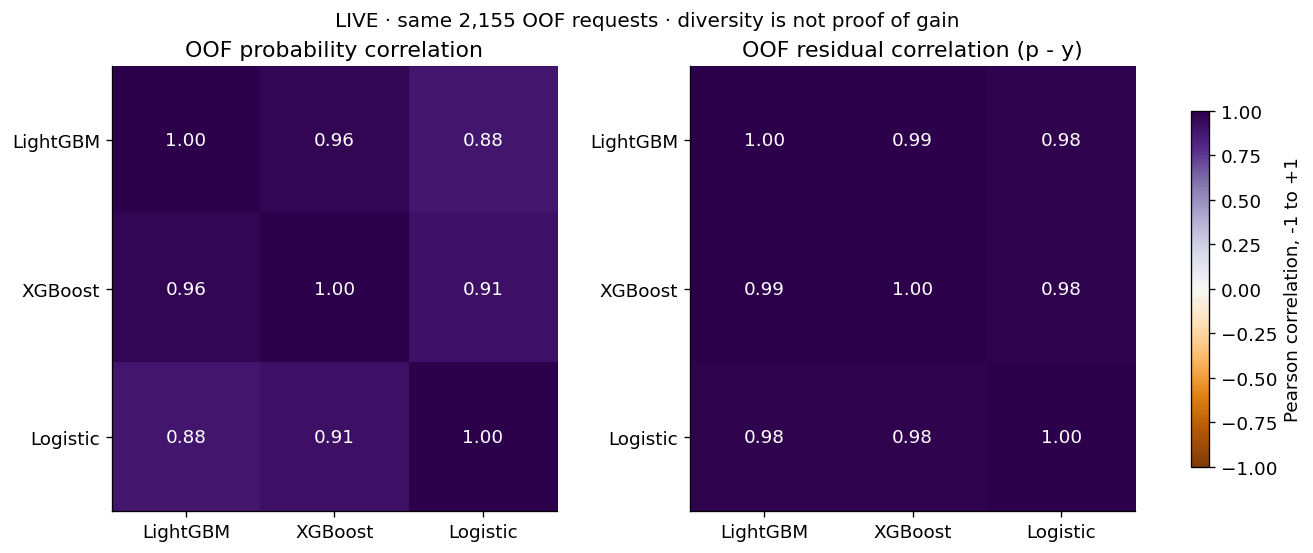

In [16]:
correlation = oof[list(BASE)].corr()
residual_correlation = oof[list(BASE)].sub(oof[TARGET], axis=0).corr()
fig, axes = plt.subplots(1,2,figsize=(11,4.5),layout="constrained")
for ax, table, title in [(axes[0],correlation,"OOF probability correlation"),(axes[1],residual_correlation,"OOF residual correlation (p - y)")]:
    im = ax.imshow(table, vmin=-1, vmax=1, cmap="PuOr")
    ax.set_xticks(range(3),BASE); ax.set_yticks(range(3),BASE); ax.set_title(title)
    for i in range(3):
        for j in range(3):
            value=table.iloc[i,j]
            ax.text(j,i,f"{value:.2f}",ha="center",va="center",color="white" if abs(value)>.6 else "#222")
fig.colorbar(im,ax=axes,shrink=.8,label="Pearson correlation, -1 to +1")
fig.suptitle(f"{SOURCE} · same {len(oof):,} OOF requests · diversity is not proof of gain",fontsize=12)
fig.savefig(ARTIFACTS / "day5_diversity.png",bbox_inches="tight"); plt.show()

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>5. Apply the worth-it gate</h2>
<p>Select the best single model by mean <strong>Average Precision</strong> across the three forward folds. Accept an ensemble only when its AP gain exceeds that single model's fold standard deviation and Brier worsens by no more than 0.005 and ECE by no more than 0.01.</p>
<p>These thresholds are fixed educational rules, not grades, success rates or a significance test. The standard deviation describes only three periods, whose training histories overlap. It is not a confidence interval.</p>
<p>If several ensembles pass, prefer the simplest: equal average, then weighted average, then stack. Do not force an ensemble to win. Report Average Precision; do not replace it with trapezoidal PR area.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>5. طبّق بوابة: هل يستحق التجميع؟</h2>
<p>اختر أفضل نموذج مفرد وفق متوسط <strong>Average Precision</strong> عبر الطيات الأمامية الثلاث. اقبل التجميع فقط إذا تجاوز تحسن AP انحراف ذلك النموذج بين الطيات، ولم يسوء Brier بأكثر من 0.005 ولا ECE بأكثر من 0.01.</p>
<p>هذه حدود تعليمية ثابتة وليست درجات أو نسب نجاح أو اختبار دلالة. يصف الانحراف ثلاث فترات فقط تتشارك تاريخًا تدريبيًا؛ وليس فترة ثقة.</p>
<p>إذا اجتاز أكثر من تجميع فاختر الأبسط: المتوسط البسيط ثم الموزون ثم Stack. لا تجبر التجميع على الفوز. أبلغ Average Precision ولا تستبدله بمساحة PR شبه المنحرفة.</p>
</td>
</tr>
</table>

,candidate,mean_ap,fold_sd,mean_brier,mean_ece,lift_vs_single,passes_gate
0,LightGBM,0.34549,0.04348,0.06608,0.02311,-0.04617,False
1,XGBoost,0.35263,0.02904,0.06566,0.02276,-0.03903,False
2,Logistic,0.39166,0.02981,0.06327,0.01882,0.00000,False
3,Equal,0.37170,0.03258,0.06435,0.02038,-0.01996,False
4,Weighted,0.38942,0.02906,0.06332,0.01772,-0.00224,False
5,Stack,0.38314,0.02949,0.06603,0.03106,-0.00852,False


KEEP SINGLE → Logistic


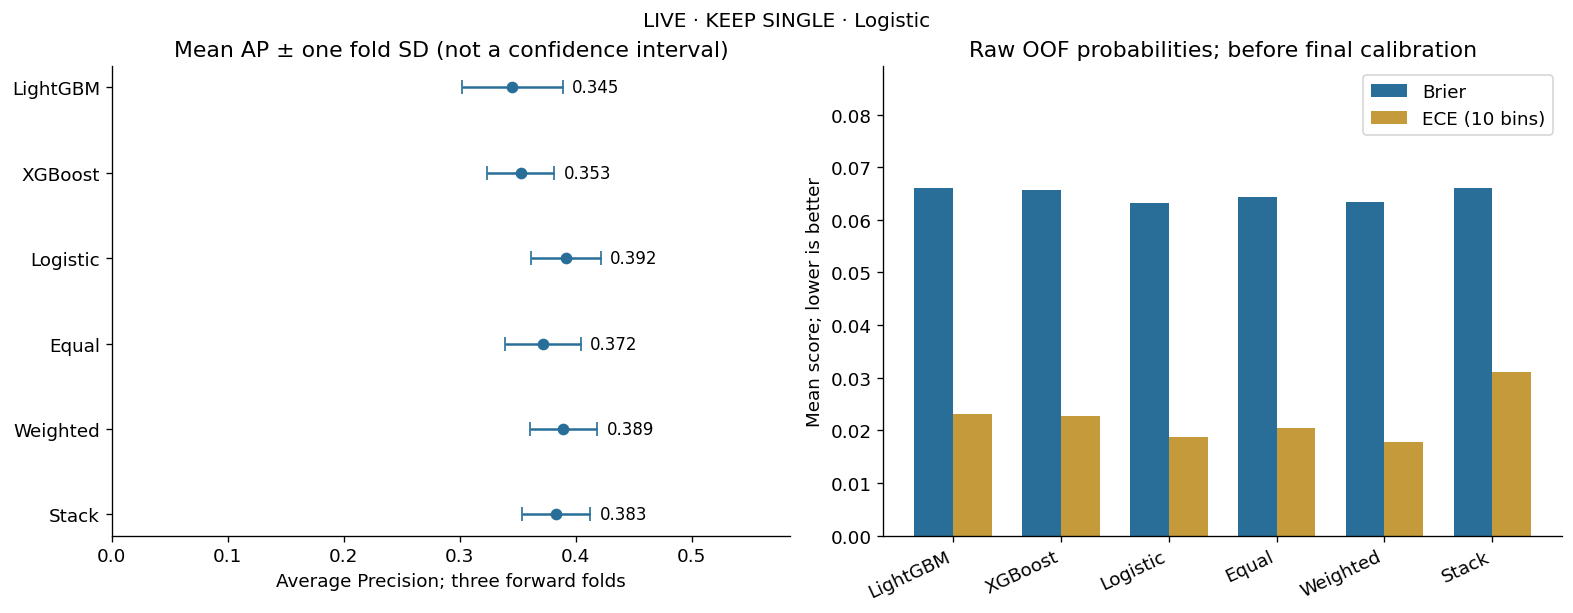

In [17]:
comparison, gate = worth_it(fold_scores, config)
display(comparison.round(5)); print(gate["decision"], "→", gate["chosen"])
fig, axes = plt.subplots(1,2,figsize=(13,5),layout="constrained")
order=list(BASE+ENSEMBLES)
for i,name in enumerate(order):
    row=comparison.set_index("candidate").loc[name]
    axes[0].errorbar(row.mean_ap,i,xerr=row.fold_sd,fmt="o",color="#286e98",capsize=4)
    axes[0].text(row.mean_ap+row.fold_sd+.008,i,f"{row.mean_ap:.3f}",va="center",fontsize=10)
axes[0].set_yticks(range(6),order); axes[0].invert_yaxis(); axes[0].set_xlim(0,min(1,comparison.mean_ap.max()+comparison.fold_sd.max()+.15))
axes[0].set_title("Mean AP ± one fold SD (not a confidence interval)"); axes[0].set_xlabel("Average Precision; three forward folds")
x=np.arange(6)
axes[1].bar(x-.18,comparison.mean_brier,.36,label="Brier",color="#286e98")
axes[1].bar(x+.18,comparison.mean_ece,.36,label="ECE (10 bins)",color="#c49a3a")
axes[1].set_xticks(x,order,rotation=25,ha="right"); axes[1].set_ylabel("Mean score; lower is better")
axes[1].set_title("Raw OOF probabilities; before final calibration"); axes[1].legend()
axes[1].set_ylim(0, max(comparison.mean_brier.max(),comparison.mean_ece.max())*1.35)
fig.suptitle(f"{SOURCE} · {gate['decision']} · {gate['chosen']}",fontsize=12)
fig.savefig(ARTIFACTS / "day5_ensemble_comparison.png",bbox_inches="tight"); plt.show()

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>6. Freeze the OOF decision policy</h2>
<p>Search every distinct selected-model OOF score for the minimum educational loss <strong>10 × FN + FP</strong>, subject to a 12% capacity ceiling in every fold and overall. Equal scores remain one block.</p>
<p>Loss units are fictional teaching units, not Saudi riyals, fees or grade deductions. Regional FPR tables are descriptive OOF diagnostics with denominators and positive counts; they are not a fairness certificate. Challenge FPR cannot be computed without labels.</p>
<p>The sensitivity table changes FN cost only while holding the model, threshold and decisions fixed.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>6. جمّد سياسة القرار على OOF</h2>
<p>افحص كل درجة OOF مميزة للنموذج المختار بحثًا عن أقل خسارة تعليمية <strong>10 × FN + FP</strong> ضمن سقف سعة 12% في كل طية وفي المجموع. تبقى الدرجات المتساوية كتلة واحدة.</p>
<p>وحدات الخسارة تعليمية افتراضية وليست ريالات سعودية أو رسومًا أو خصمًا من الدرجة. جداول FPR الإقليمية تدقيقات وصفية على OOF مع المقامات وعدد الموجبات؛ وليست شهادة عدالة. لا يمكن حساب FPR للتحدي دون تسميات.</p>
<p>يغيّر جدول الحساسية تكلفة FN فقط مع تثبيت النموذج والعتبة والقرارات.</p>
</td>
</tr>
</table>

,threshold,tp,fp,fn,tn,flagged,flag_fraction,recall,precision,false_positive_rate,accuracy,loss_units,loss_units_per_10000,capacity_feasible,max_period_flag_fraction,rows,source
0,0.16892,84,161,95,1815,245,0.11369,0.46927,0.34286,0.08148,0.88121,1111.0,5155.45244,True,0.11749,2155,LIVE


,region,rows,negatives,positives,flagged,false_positives,true_positives,false_positive_rate,recall,low_negative_support,source
0,central,537,489,48,63,39,24,0.0798,0.5000,False,LIVE
1,western,533,486,47,71,50,21,0.1029,0.4468,False,LIVE
2,eastern,542,507,35,48,32,16,0.0631,0.4571,False,LIVE
3,other,543,494,49,63,40,23,0.0810,0.4694,False,LIVE


,false_negative_cost,false_positive_cost,fixed_threshold,loss_units
0,8,1,0.168922,921
1,10,1,0.168922,1111
2,12,1,0.168922,1301


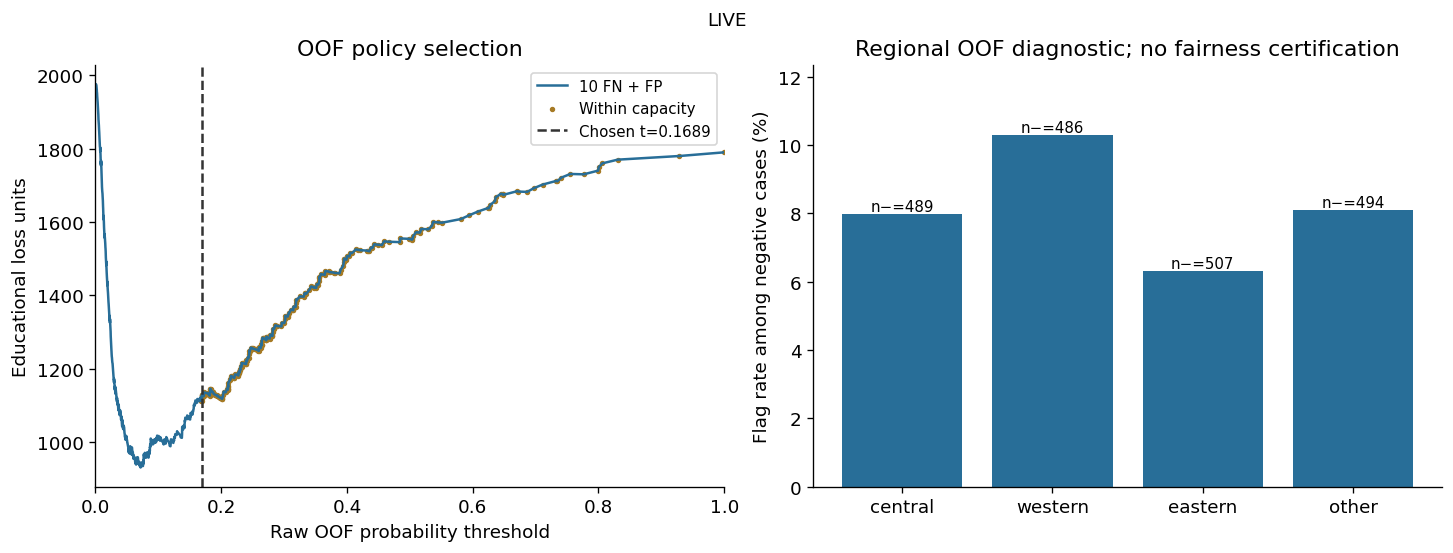

In [18]:
policy = CostPolicy()
selected = selected_oof(oof, gate["chosen"])
sweep = threshold_sweep(selected, policy)
threshold_choice = select_threshold(sweep)
raw_threshold = float(threshold_choice["threshold"])
regional, regional_summary = region_audit(selected, raw_threshold)
period_capacity = period_audit(selected, raw_threshold, policy)
sensitivity = pd.DataFrame([{"false_negative_cost":c,"false_positive_cost":1,
    "fixed_threshold":raw_threshold,"loss_units":c*int(threshold_choice["fn"])+int(threshold_choice["fp"])} for c in (8,10,12)])
display(pd.DataFrame([threshold_choice]).round(5)); display(regional.round(4)); display(sensitivity)
fig, axes = plt.subplots(1,2,figsize=(12,4.5),layout="constrained")
axes[0].plot(sweep.threshold,sweep.loss_units,color="#286e98",label="10 FN + FP")
feasible=sweep[sweep.capacity_feasible]
axes[0].scatter(feasible.threshold,feasible.loss_units,s=5,color="#a67a24",label="Within capacity")
axes[0].axvline(raw_threshold,color="#333",ls="--",label=f"Chosen t={raw_threshold:.4f}")
axes[0].set(xlim=(0,1),xlabel="Raw OOF probability threshold",ylabel="Educational loss units",title="OOF policy selection"); axes[0].legend(fontsize=9)
axes[1].bar(regional.region,regional.false_positive_rate*100,color="#286e98")
axes[1].set(ylabel="Flag rate among negative cases (%)",title="Regional OOF diagnostic; no fairness certification")
for i,r in regional.iterrows(): axes[1].text(i,r.false_positive_rate*100,f"n−={r.negatives}",ha="center",va="bottom",fontsize=9)
axes[1].margins(y=.2)
fig.suptitle(SOURCE,fontsize=11); fig.savefig(ARTIFACTS / "day5_policy_regions.png",bbox_inches="tight"); plt.show()

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>7. Refit the chosen procedure and freeze calibration</h2>
<p>Refit the chosen learning procedure on the eligible pool and learn one sigmoid mapping on the reserved calibration period only. Do not retrain the estimator afterward; an old calibrator and threshold would no longer match it.</p>
<p>Transport the raw OOF threshold to the calibrated scale when the mapping is monotone. The reliability figure is a <strong>calibration-fit diagnostic on the same rows used to learn the calibrator</strong>, not an independent evaluation.</p>
<p>Transporting a threshold from OOF models to a refitted model can change flag volume, so a full-batch capacity policy must be declared before looking at challenge outcomes. Day 4 SHAP explanations belong to the Day 4 model and must not be attributed automatically to a different final model or ensemble.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>7. أعد ملاءمة الإجراء المختار وثبّت المعايرة</h2>
<p>أعد ملاءمة إجراء التعلم المختار على الحوض المؤهل، وتعلم تحويل sigmoid واحدًا من فترة المعايرة المحجوزة فقط. لا تعِد تدريب النموذج بعدها؛ وإلا لم يعد المعاير والعتبة القديمان مطابقين له.</p>
<p>انقل عتبة OOF الخام إلى المقياس المعاير عندما يكون التحويل متزايدًا. رسم الموثوقية <strong>تشخيص ملاءمة على الصفوف نفسها التي تعلم منها المعاير</strong> وليس تقييمًا مستقلًا.</p>
<p>قد يغير نقل العتبة من نماذج OOF إلى نموذج معاد التدريب حجم الإشارات، لذلك يجب إعلان سياسة سعة للدفعة الكاملة قبل رؤية نتائج التحدي. تفسيرات SHAP في اليوم الرابع تخص نموذج اليوم الرابع ولا تُنسب تلقائيًا إلى نموذج نهائي أو تجميع مختلف.</p>
</td>
</tr>
</table>

,rows,positives,prevalence,roc_auc,average_precision,brier,log_loss,ece,bins,binning
raw_fit_diagnostic,836,78,0.093301,0.789037,0.287803,0.076473,0.266489,0.021121,10,"fixed width, [lower, upper); final bin includes 1"
sigmoid_fit_diagnostic,836,78,0.093301,0.789037,0.287803,0.078058,0.277296,0.034871,10,"fixed width, [lower, upper); final bin includes 1"


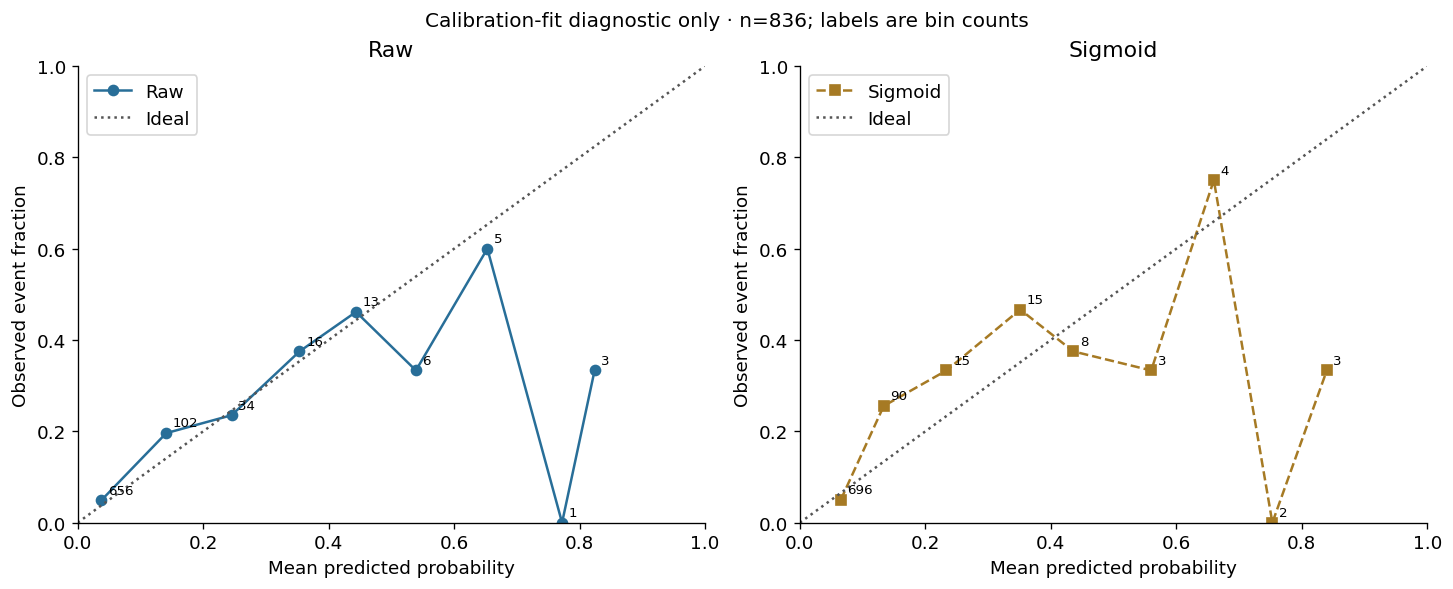

Final model and sigmoid frozen; transported threshold: 0.12225843144286948


In [19]:
if SOURCE == "LIVE":
    final_model, mapping, calibration_predictions, final_provenance = fit_final(pool, calibration, contract, gate["chosen"], config)
    calibrated_threshold = transport_threshold(raw_threshold, mapping)
    final_model_manifest = export_model(final_model, mapping, contract, ARTIFACTS / "final_model")
    calibration_diagnostics = {name:probability_metrics(calibration_predictions[TARGET],calibration_predictions[column])
        for name,column in [("raw_fit_diagnostic","raw_probability"),("sigmoid_fit_diagnostic","probability")]}
    bins = pd.concat([reliability_table(calibration_predictions[TARGET],calibration_predictions[column]).assign(series=name)
        for name,column in [("Raw","raw_probability"),("Sigmoid","probability")]],ignore_index=True)
    display(pd.DataFrame(calibration_diagnostics).T.round(5))
    fig,axes=plt.subplots(1,2,figsize=(12,4.8),layout="constrained")
    for ax,name,style,color in [(axes[0],"Raw","o-","#286e98"),(axes[1],"Sigmoid","s--","#a67a24")]:
        table=bins[(bins.series==name)&(bins['count']>0)]
        ax.plot(table.mean_probability,table.observed_rate,style,label=name,color=color)
        for row in table.itertuples(): ax.annotate(str(row.count),(row.mean_probability,row.observed_rate),xytext=(4,4),textcoords="offset points",fontsize=8)
        ax.plot([0,1],[0,1],":",color="#555",label="Ideal")
        ax.set(xlim=(0,1),ylim=(0,1),xlabel="Mean predicted probability",ylabel="Observed event fraction",title=name)
        ax.legend()
    fig.suptitle(f"Calibration-fit diagnostic only · n={len(calibration)}; labels are bin counts",fontsize=12)
    fig.savefig(ARTIFACTS / "day5_calibration_fit.png",bbox_inches="tight"); plt.show()
    print("Final model and sigmoid frozen; transported threshold:", calibrated_threshold)
else:
    print("EXAMPLE_ONLY_NOT_SUBMITTABLE — final fitting, inference and submission are skipped.")

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>8. Score every challenge request and apply capacity once</h2>
<p><code>inference.predict</code> returns application ID and calibrated probability while preserving request order. Probabilities may be computed in chunks, but concatenate all chunks before applying the full-batch policy once.</p>
<p>Candidates exceed the transported threshold. If they exceed 12% of the 2,500-request batch, keep the highest probabilities up to the 300-request ceiling. Never split an equal-score block with the identifier; if the whole boundary block does not fit, exclude it and leave capacity unused.</p>
<p><code>decision=1</code> is a simulated review flag. <code>decision=0</code> is not a safety guarantee or financing approval. Challenge AP, loss and FPR are not computed because labels are unavailable. Models are exported in JSON/native formats rather than untrusted pickle files.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>8. صدّر كل طلب وطبّق السعة مرة واحدة</h2>
<p>تعيد <code>inference.predict</code> معرف الطلب والاحتمال المعاير مع الحفاظ على ترتيب الطلبات. يمكن حساب الاحتمالات على أجزاء، لكن اجمع الأجزاء كلها قبل تطبيق سياسة الدفعة الكاملة مرة واحدة.</p>
<p>المرشحون هم من يتجاوزون العتبة المنقولة. إذا تجاوزوا 12% من دفعة تضم 2,500 طلب، احتفظ بالأعلى احتمالًا حتى سقف 300 طلب. لا تقسّم كتلة درجات متساوية باستخدام المعرّف؛ إذا لم تتسع كتلة الحد كاملة فاستبعدها واترك جزءًا من السعة دون استخدام.</p>
<p><code>decision=1</code> إشارة مراجعة محاكاة، و<code>decision=0</code> ليس ضمان سلامة أو قبول تمويل. لا تُحسب AP أو الخسارة أو FPR للتحدي لغياب التسميات. تُصدّر النماذج بصيغ JSON/native بدل ملفات pickle غير الموثوقة.</p>
</td>
</tr>
</table>

,application_id,probability,decision
0,CH-000278,0.114104,0
1,CH-001412,0.120922,0
2,CH-001444,0.055587,0
3,CH-002174,0.053426,0
4,CH-002260,0.077174,0


,rows,capacity,threshold_eligible,flagged,removed_by_cap,boundary_score,within_capacity,tie_policy,batch_policy
0,2500,300,330,300,30,0.129908,True,retain entire equal-score blocks; drop boundar...,"threshold first, then probability-descending f..."


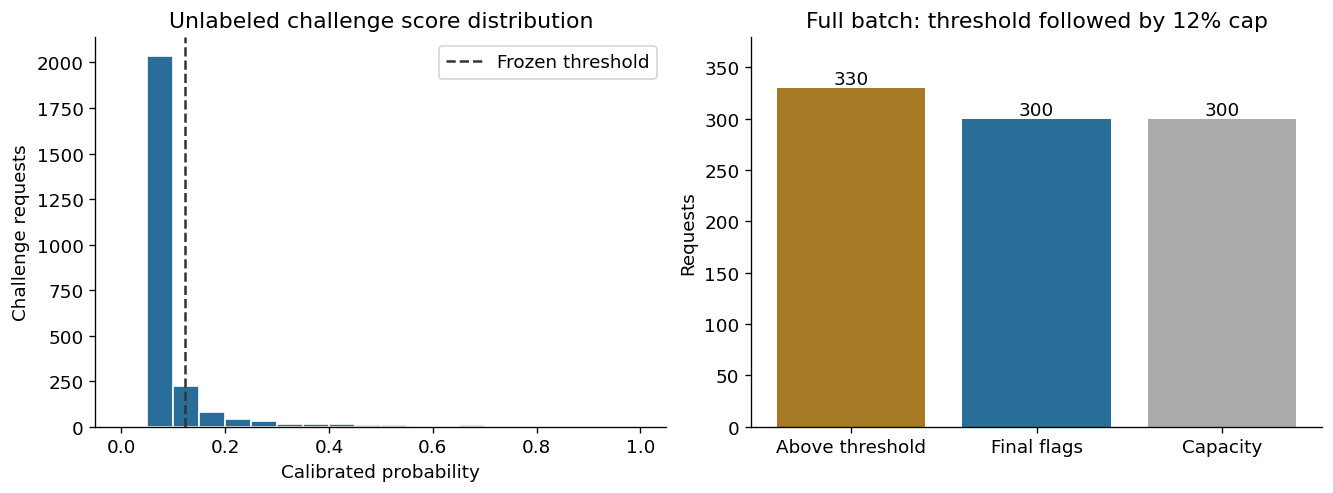

In [20]:
if SOURCE == "LIVE":
    from inference import predict
    predictions = predict(challenge, ARTIFACTS / "final_model")
    submission, batch_audit = apply_batch_policy(predictions, calibrated_threshold, policy)
    validate_submission(submission, challenge, calibrated_threshold, policy)
    expected = map_probability(final_model.predict_proba(challenge[[f['name'] for f in contract['features']]])[:,1], mapping)
    assert np.allclose(predictions.probability, expected, rtol=0, atol=1e-12)
    display(submission.head()); display(pd.DataFrame([batch_audit]))
    fig,axes=plt.subplots(1,2,figsize=(11,4),layout="constrained")
    axes[0].hist(predictions.probability,bins=np.linspace(0,1,21),color="#286e98",edgecolor="white")
    axes[0].axvline(calibrated_threshold,color="#333",ls="--",label="Frozen threshold")
    axes[0].set(xlabel="Calibrated probability",ylabel="Challenge requests",title="Unlabeled challenge score distribution");axes[0].legend()
    axes[1].bar(["Above threshold","Final flags","Capacity"],[batch_audit['threshold_eligible'],batch_audit['flagged'],batch_audit['capacity']],color=["#a67a24","#286e98","#aaa"])
    axes[1].set(ylabel="Requests",title="Full batch: threshold followed by 12% cap")
    for i,n in enumerate([batch_audit['threshold_eligible'],batch_audit['flagged'],batch_audit['capacity']]): axes[1].text(i,n,str(n),ha="center",va="bottom")
    axes[1].margins(y=.15);fig.savefig(ARTIFACTS / "day5_challenge_capacity.png",bbox_inches="tight");plt.show()
else:
    print("No challenge predictions are produced from the educational example.")

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>9. Write your decision and assemble your evidence</h2>
<p>Complete every response field using your measured values. Tables alone are not an interpretation, and response completeness permits review but does not award a grade.</p>
<p>If the final model differs from Day 4, state that Day 4 explanations belong to that earlier model and identify what must be rechecked for the final version.</p>
<p>You may upload your actual <code>day1_artifacts.zip</code> through <code>day4_artifacts.zip</code> to the displayed Colab working folder. The exporter imports them under <code>evidence/day1/</code> through <code>evidence/day4/</code> without overwriting model code. Do not use a peer's bundle or the educational example as your personal run evidence.</p>
<p>Add executed notebooks and a final GitHub repository when available. Do not publish your full name, grade or private data in a public repository.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>9. اكتب قرارك واجمع أدلتك</h2>
<p>أكمل جميع حقول الإجابات باستخدام القيم التي قستها. الجداول وحدها ليست تفسيرًا، واكتمال الإجابات يسمح بالمراجعة لكنه لا يمنح درجة.</p>
<p>إذا اختلف النموذج النهائي عن اليوم الرابع، فاذكر أن تفسيرات اليوم الرابع تخص النموذج السابق وحدد ما يلزم إعادة فحصه للنسخة النهائية.</p>
<p>يمكنك رفع حزمك الفعلية <code>day1_artifacts.zip</code> إلى <code>day4_artifacts.zip</code> في مجلد عمل Colab المعروض. يستوردها المصدّر تحت <code>evidence/day1/</code> حتى <code>evidence/day4/</code> دون الكتابة فوق شيفرة النموذج. لا تستخدم حزمة زميل أو المثال التعليمي كدليل تشغيل شخصي.</p>
<p>أضف الدفاتر المنفذة وعرض PDF من خمس شرائح عند توفرها. لا تنشر اسمك الكامل أو درجتك أو بيانات خاصة في مستودع عام.</p>
</td>
</tr>
</table>

In [21]:
responses = {
    "ensemble_reason": (
        "I kept the single Logistic Regression model. It had the highest mean AP across the three forward folds: 0.392 "
        "(fold SD 0.030), compared with 0.389 for the weighted average, 0.383 for stacking, and 0.372 for equal averaging. "
        "The ensembles' AP lifts over Logistic were zero or negative, and none passed the worth-it gate. The differences "
        "are also much smaller than the fold SD, so I can't claim an ensemble is better. Logistic's Brier score was 0.0633 "
        "and ECE was 0.0188. Stacking had a worse ECE of 0.0311; the weighted average's ECE was slightly lower at 0.0177, "
        "but it still had no AP gain. The ensembles require more models and, for stacking, a meta-model, so the extra "
        "complexity wasn't justified."
    ),

    "validation_limits": (
        "I excluded the leaky days_past_due_60 field. The nested forward OOF comparison used 2,155 predictions from three "
        "later-period folds. Training rows were old enough for their 90-day labels to mature, validation customers were "
        "kept out of training, and ensemble weights and the stacker were learned from inner OOF predictions only. There "
        "were no outer OOF predictions for the warm-up rows, so 2,155 of the 6,576 fit-and-selection rows were evaluated. "
        "There were only three folds, and their training histories overlap. The fold SD of about 0.03 is similar to the "
        "differences between the top models; it is descriptive, not a confidence interval. The threshold and loss were "
        "also selected on these OOF predictions, so they are development results, not an independent final test. The data "
        "are synthetic, and the course had used the training data earlier."
    ),

    "calibration_limits": (
        "The sigmoid mapping was fitted using 836 reserved calibration rows, including 78 positives from July–September "
        "2024. The reported scores are on those same rows, so they are fit diagnostics, not an independent test. AP "
        "stayed at 0.2878 and ROC-AUC at 0.7890, as expected for a monotonic mapping. The other scores got worse: Brier "
        "changed from 0.0765 to 0.0781, ECE from 0.0211 to 0.0349, and log loss from 0.2665 to 0.2773. So these results "
        "don't show that calibration improved. I would need separate labeled data to evaluate calibration independently. "
        "Challenge labels are unavailable."
    ),

    "capacity_fairness": (
        "The OOF-selected raw threshold was 0.1689. It flagged 245 of 2,155 requests (11.4%); the highest period-level "
        "flag fraction was 11.7%, within the 12% limit. The threshold's OOF loss was 1,111 fictional teaching units. "
        "The regional OOF false-positive rates were Central 7.98% (489 negatives), Western 10.29% (486), Eastern 6.31% "
        "(507), and Other 8.10% (494). That is a 3.98 percentage-point gap, with recall ranging from 44.7% in Western "
        "to 50.0% in Central. For the full challenge batch, the transported threshold was 0.1223: 330 of 2,500 requests "
        "were above it, so the 300-request cap removed 30 flags. The boundary score was 0.1299, and equal-score blocks "
        "were not split. The regional results are descriptive only: there are no confidence intervals and they are not "
        "a fairness certification. Challenge labels are unavailable, so I can't calculate challenge false-positive rates "
        "or check the regional mix of actual errors."
    ),

    "explanation_scope": (
        "No. Day 4's SHAP, permutation importance, reason codes, and review zone explain the class-weighted LightGBM model "
        "(80 trees), not the final Day 5 Logistic Regression model. In Day 4, “weighted” referred to class weights; in Day 5, "
        "the weighted average is an ensemble. I can't carry Day 4's explanations over as claims about the final model. "
        "I would recheck global importance and local reason codes using the final model, then check explanations around "
        "the new calibrated threshold of 0.1223."
    ),

    "intended_use": (
        "This is for a fictional training exercise using synthetic Tamweel Lite data. A 1 means a simulated request for "
        "human review; a 0 is not a safety guarantee or financing approval. I would not use it to score real people or "
        "make real loan approval, rejection, pricing, or eligibility decisions. The data are synthetic, the loss units "
        "are educational, and the model has not been certified as fair."
    ),

    "monitoring_plan": (
        "I would monitor changes in key inputs such as bureau_score and dti, missing values, and the score distribution. "
        "As 90-day labels mature, I would check AP by period, Brier, ECE, and observed default rates by probability bin. "
        "I would also track how many requests exceed the 0.1223 threshold, how many the 300-request cap removes, and "
        "regional flag and false-positive rates with their denominators. The Western–Eastern false-positive gap in this "
        "run was 3.98 percentage points, so I would watch whether it persists. I would set review or retraining triggers "
        "in advance and investigate them using labeled data, rather than judging performance from the unlabeled challenge set."
    ),

    "executive_summary_ar": (
        "اخترت Logistic Regression كنموذج نهائي مفرد. حقق أعلى متوسط AP في نتائج OOF الأمامية المتداخلة: 0.392 عبر ثلاث "
        "طيات، مقابل 0.389 للمتوسط الموزون و0.383 للـStacking و0.372 للمتوسط المتساوي. لم يجتز أي تجميع بوابة الجدوى، "
        "لذلك لم يبرر التعقيد الإضافي استخدامه. في دفعة التحدي، تجاوزت 330 من أصل 2,500 طلب العتبة المنقولة 0.1223؛ "
        "وبعد تطبيق سقف 12% مرة واحدة، بقيت 300 إشارة مراجعة محاكاة وأُزيلت 30. ظهر فرق وصفي قدره 3.98 نقاط مئوية "
        "بين أعلى وأدنى معدل إنذار خاطئ إقليمي، ويحتاج إلى متابعة. البيانات اصطناعية، والنتائج للتدريب فقط وليست "
        "لقرارات تمويل حقيقية."
    ),

    "executive_summary_en": (
        "I chose the single Logistic Regression model because it had the highest mean AP in the nested forward OOF results "
        "(0.392 across three folds). No ensemble passed the worth-it gate, so the extra complexity wasn't justified. "
        "On the 2,500-request challenge batch, 330 requests exceeded the transported threshold of 0.1223; applying the "
        "12% capacity limit once left 300 simulated review flags and removed 30. The regional OOF false-positive gap was "
        "3.98 percentage points and needs monitoring. The data are synthetic, so this is for training only, not real "
        "financing decisions."
    ),
}

checkpoint = reflection_check(responses, SOURCE)
print(checkpoint["status"], "| Missing:", checkpoint["missing"])
print("Upload your previous daily ZIPs here if available:", ROOT)

READY_FOR_REVIEW | Missing: []
Upload your previous daily ZIPs here if available: /content/tamweel


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>10. Export and verify the project bundle</h2>
<p>The bundle stores permitted data, code, configuration, final model, predictions, reports and file hashes. <code>replay_final.py</code> reproduces predictions from the saved model; <code>rebuild_final.py</code> retrains, reselects and recalibrates from data.</p>
<p>Save the executed notebook as <code>notebooks/05_final_model.ipynb</code>. Download and extract the project ZIP, then upload the actual files while preserving directories; the ZIP alone is not the repository submission. Complete <code>PROJECT_README.md</code> and move its content into the project README.</p>
<p><code>BUNDLE_BYTES_VERIFIED</code> proves only that bundled files match their hashes. It is not project acceptance, a grade or a submission receipt. After the final commit, record your repository SHA and tag outside the manifest through the private submission channel to avoid a circular reference.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>10. صدّر حزمة المشروع وتحقق منها</h2>
<p>تحفظ الحزمة البيانات المسموح بها والشيفرة والإعدادات والنموذج النهائي والتنبؤات والتقارير وبصمات الملفات. يعيد <code>replay_final.py</code> التنبؤ من النموذج المحفوظ، ويعيد <code>rebuild_final.py</code> التدريب والاختيار والمعايرة من البيانات.</p>
<p>احفظ الدفتر المنفذ باسم <code>notebooks/05_final_model.ipynb</code>. نزّل ZIP المشروع وفكّه ثم ارفع الملفات الفعلية مع الحفاظ على المجلدات؛ ZIP وحده ليس تسليم المستودع. أكمل <code>PROJECT_README.md</code> وانقل محتواه إلى README المشروع.</p>
<p><code>BUNDLE_BYTES_VERIFIED</code> يثبت مطابقة الملفات للبصمات فقط. ليس قبولًا للمشروع أو درجة أو إيصال تسليم. بعد آخر commit سجّل SHA وtag لمستودعك خارج manifest عبر قناة التسليم الخاصة لتجنب المرجع الدائري.</p>
</td>
</tr>
</table>

In [22]:
def clean_json(value):
    if isinstance(value,dict): return {str(k):clean_json(v) for k,v in value.items()}
    if isinstance(value,(list,tuple)): return [clean_json(v) for v in value]
    if isinstance(value,np.generic): return clean_json(value.item())
    if isinstance(value,float) and not np.isfinite(value): return None
    return value

tables = {"day5_roles.csv":roles,"day5_oof_predictions.csv":oof,"day5_fold_scores.csv":fold_scores,
    "ensemble_comparison.csv":comparison,"day5_threshold_sweep.csv":sweep,"day5_region_audit.csv":regional,
    "day5_period_capacity.csv":period_capacity,"day5_cost_sensitivity.csv":sensitivity}
for name,table in tables.items(): table.to_csv(ARTIFACTS / name,index=False)
correlation.to_csv(ARTIFACTS / "day5_probability_correlation.csv")
residual_correlation.to_csv(ARTIFACTS / "day5_residual_correlation.csv")
run = {"technical_status":"TECHNICAL_READY" if SOURCE=="LIVE" else "EXAMPLE_ONLY_NOT_SUBMITTABLE",
    "source":SOURCE,"chosen":gate['chosen'],"decision":gate['decision'],"config":asdict(config),
    "learner_status":checkpoint['status'],"lab_revision":LAB_REVISION,"support_hashes":SUPPORT_HASHES,
    "previous_support":PREVIOUS_SUPPORT,"data_revision":COURSE_REVISION,"python":platform.python_version(),
    "elapsed_seconds":round(time.perf_counter()-STARTED,2),"challenge_labels_used":False,"automatic_grade":None}
for name,obj in {"day5_run.json":run,"day5_reflection.json":{"responses":responses,"checkpoint":checkpoint},
    "day5_oof_provenance.json":oof_provenance,"day5_ensemble_gate.json":gate}.items(): write_json(ARTIFACTS / name,clean_json(obj))
if SOURCE != "LIVE":
    example_zip=ROOT / "day5_example_analysis.zip"
    with zipfile.ZipFile(example_zip,"w",zipfile.ZIP_DEFLATED) as z:
        for name in [*tables,"day5_run.json","day5_ensemble_gate.json","day5_diversity.png","day5_ensemble_comparison.png","day5_policy_regions.png"]:
            z.write(ARTIFACTS/name,name)
    print("EXAMPLE_ONLY_NOT_SUBMITTABLE — comparison only; no model, submission or project bundle exported.")
    display(FileLink(str(example_zip)))
else:
    submission.to_csv(SUBMISSION / "submission.csv",index=False)
    calibration_predictions.to_csv(ARTIFACTS / "day5_calibration_predictions.csv",index=False)
    bins.to_csv(ARTIFACTS / "day5_calibration_fit_bins.csv",index=False)
    final_policy={"raw_oof_threshold":raw_threshold,"calibrated_threshold":calibrated_threshold,
        "cost_policy":asdict(policy),"mapping":mapping,"batch_audit":batch_audit}
    final_metrics={"gate":gate,"oof_threshold_selection":threshold_choice,"regional_oof":regional_summary,
        "calibration_fit_diagnostics":calibration_diagnostics,"challenge_metrics":None,
        "challenge_metrics_reason":"Labels unavailable; no AP/loss/FPR claimed.","challenge_batch":batch_audit}
    write_json(ARTIFACTS / "final_policy.json",clean_json(final_policy))
    write_json(ARTIFACTS / "final_metrics.json",clean_json(final_metrics))
    write_json(ARTIFACTS / "day5_final_provenance.json",clean_json(final_provenance))
    reproduced=replay_submission(ROOT)
    assert np.allclose(reproduced.probability,submission.probability,rtol=0,atol=1e-12)
    assert np.array_equal(reproduced.decision,submission.decision)
    answer=lambda key: responses[key].strip() or "[اكتب تفسيرك من نتائجك هنا]"
    card = f"""# بطاقة النموذج | Model Card
## الحالة
{checkpoint['status']} — جودة التفسير تحتاج مراجعة بشرية، وليست درجة آلية.
## الغرض والاستخدام | Purpose and use
{answer('intended_use')}
بيانات Tamweel Lite اصطناعية؛ الهدف حدث خلال 90 يومًا بعد الطلب. 22 خاصية متاحة وقت الطلب؛ لا معرفات أو تواريخ أو هدف في المدخلات. الاستخدام التعليمي فقط؛ لا قرارات تمويل فعلية.
## البيانات والتحقق | Data and validation
حوض التدريب والاختيار: {len(pool)} طلبًا. المعايرة: {len(calibration)} طلبًا و{int(calibration[TARGET].sum())} موجبًا. حجز عملاء المعايرة، 90 يومًا لنضج التسميات، وOOF أمامي متداخل مع فصل العملاء في المستويين. طيات المقارنة: 2023Q1 و2023Q3 و2024Q1. نستبعد النتائج التي لم تنضج قبل الأدوار التالية؛ آخر بيانات التدريب لا تستخدم تلقائيًا.
{answer('validation_limits')}
## النموذج والقرار | Model selection
{gate['decision']} / {gate['chosen']}. انحراف AP المرجعي: {gate['fold_sd_reference']:.6f}. ارجع إلى artifacts/ensemble_comparison.csv وday5_fold_scores.csv للأرقام الكاملة.
{answer('ensemble_reason')}
## المعايرة | Calibration
Sigmoid على عينة محجوزة من التدريب والاختيار؛ الرسم والمقاييس تشخيص على عينة تعلم المعاير، وليسا اختبارًا مستقلاً. لا ادعاء بتحسن على تحدٍّ مجهول التسميات.
{answer('calibration_limits')}
## السياسة والسعة والمناطق | Policy and regions
خسارة 10 FN + FP، عتبة OOF الخام {raw_threshold:.17g} والمنقولة {calibrated_threshold:.17g}. سعة الدفعة {batch_audit['capacity']}؛ المرشحون {batch_audit['threshold_eligible']}؛ الإشارات النهائية {batch_audit['flagged']}. كتلة الدرجات المتساوية لا تقسم. 1=إشارة مراجعة تعليمية، 0=عدم رفع الإشارة.
{answer('capacity_fairness')}
## التفسير وحدوده | Explanation scope
تفسير اليوم الرابع يخص نموذج اليوم الرابع؛ لا يُنسب تلقائيًا إلى هذه النسخة. تغيير النموذج أو خصائصه أو معايرته يستلزم مراجعة التفسير.
{answer('explanation_scope')}
## المتابعة والقيود | Monitoring and limitations
{answer('monitoring_plan')}
OOF يستخدم للاختيار، وثلاث فترات ليست اختبار دلالة. العتبة قد تتغير سعتها عند نقلها إلى نموذج معاد التدريب. لا تسميات للتحدي، ولا مقاييس أداء أو شهادة عدالة له. البيانات لا تمثل أشخاصًا أو مناطق حقيقية.
## إعادة الإنتاج | Reproducibility
seed={config.seed}; trees={config.trees}; CPU مجاني. الإصدارات في artifacts/environment.json. المصادر/bصماتها في artifacts/day5_run.json. النموذج artifacts/final_model؛ inference.predict يعيد ID واحتمالًا؛ السياسة تطبق بعد جمع الدفعة. replay_final يعيد التنبؤ المحفوظ؛ rebuild_final يعيد التدريب. لا تدرب النموذج بعد تثبيت المعاير.
## ملكيتك للتسليم | Submission ownership
أكمل أدلة الأيام السابقة والعرض، واحفظ الدفتر المنفذ، ثم سجل SHA وtag مستودعك في قناة التسليم الخاصة. دعم الدورة {LAB_REVISION} ليس SHA تسليمك.
"""
    (REPORTS / "MODEL_CARD.md").write_text(card.replace("bصماتها","بصماتها"),encoding="utf-8")
    (REPORTS / "ENSEMBLE_DECISION.md").write_text(f"# قرار التجميع\n\n{gate['decision']} — {gate['chosen']}\n\n{answer('ensemble_reason')}\n\n{answer('validation_limits')}\n\nالدليل: artifacts/ensemble_comparison.csv وday5_ensemble_gate.json. SD وصفي، وليس اختبار دلالة.\n",encoding="utf-8")
    (ROOT / "PROJECT_README.md").write_text(f"# Tamweel Lite | مشروعك النهائي\n\n## الملخص التنفيذي\n{answer('executive_summary_ar')}\n\n## Executive summary\n{answer('executive_summary_en')}\n\nDecision: {gate['decision']} / {gate['chosen']}. Full-batch flags: {batch_audit['flagged']}/{len(challenge)}.\n\nاقرأ reports/MODEL_CARD.md والسياسة في artifacts/final_policy.json. الحزمة للتدريب؛ ليست نتيجة تقييم نهائية أو إثبات تسليم. ادمج أدلة أيامك السابقة واحفظ الدفتر المنفذ والعرض.\n",encoding="utf-8")
    for day in range(1,5):
        archive=ROOT / f"day{day}_artifacts.zip"
        if archive.exists(): import_daily_evidence(archive,ROOT / "evidence" / f"day{day}")
    completeness=evidence_status(ROOT)
    full_ready=checkpoint['status']=="READY_FOR_REVIEW" and all(r['status'] in ("READY_FOR_REVIEW","PRESENT_REQUIRES_REVIEW") for r in completeness)
    full_status="READY_FOR_HUMAN_REVIEW" if full_ready else "PROJECT_WORK_REQUIRED"
    write_json(ARTIFACTS / "day5_project_check.json",{"status":full_status,"items":completeness,"automatic_grade":None,"receipt":False})
    display(pd.DataFrame(completeness)[['item','status']])
    bundle_files=["PROJECT_README.md","reports/MODEL_CARD.md","reports/ENSEMBLE_DECISION.md","submission/submission.csv",
        "requirements-colab.txt","constraints.txt","data/data_contract.json","data/data_manifest.json","data/tamweel_train.csv","data/tamweel_challenge.csv",
        "presentation/FINAL_PRESENTATION_TEMPLATE.md","presentation/FINAL_PRESENTATION_GUIDE.md",*PREVIOUS_SUPPORT.keys(),*[p for p in SUPPORT_HASHES if p.startswith('scripts/')]]
    artifact_names=[*tables,"day5_probability_correlation.csv","day5_residual_correlation.csv","day5_run.json","day5_reflection.json",
        "day5_oof_provenance.json","day5_ensemble_gate.json","final_policy.json","final_metrics.json","day5_final_provenance.json",
        "day5_calibration_predictions.csv","day5_calibration_fit_bins.csv","day5_project_check.json","environment.json",
        "day5_diversity.png","day5_ensemble_comparison.png","day5_policy_regions.png","day5_calibration_fit.png","day5_challenge_capacity.png"]
    bundle_files += ["artifacts/"+name for name in artifact_names]
    bundle_files += ["artifacts/final_model/"+name for name in [*final_model_manifest,"model_manifest.json"]]
    for folder in [ROOT/'evidence',ROOT/'notebooks']:
        if folder.exists(): bundle_files += [p.relative_to(ROOT).as_posix() for p in folder.rglob('*') if p.is_file() and p.suffix in ('.csv','.json','.png','.md','.npz','.txt','.ipynb')]
    if (ROOT/'presentation/final_presentation.pdf').is_file(): bundle_files.append('presentation/final_presentation.pdf')
    manifest,bundle_path=create_bundle(ROOT,bundle_files,{"source":SOURCE,"lab_revision":LAB_REVISION,"day5_learner_status":checkpoint['status'],
        "project_status":full_status,"challenge_sha256":sha256((ROOT/'data/tamweel_challenge.csv').read_bytes()).hexdigest()})
    print("REPLAY_MATCH |",verify_bundle(bundle_path),"|",full_status)
    display(FileLink(str(bundle_path)))
    print("احفظ الدفتر المنفذ وأكمل إجاباتك وأدلة الأيام السابقة والعرض؛ ثم ارفع الملفات إلى مشروعك نفسه.")

,item,status
0,day1_learner_evidence,MISSING
1,day2_learner_evidence,MISSING
2,day3_learner_evidence,MISSING
3,day4_learner_evidence,MISSING
4,notebooks/01_baseline_boosting.ipynb,MISSING
5,notebooks/02_validation_tuning.ipynb,MISSING
6,notebooks/03_cost_sensitive_decision.ipynb,MISSING
7,notebooks/04_explain_calibrate.ipynb,MISSING
8,notebooks/05_final_model.ipynb,MISSING
9,presentation/final_presentation.pdf,MISSING


REPLAY_MATCH | {'status': 'BUNDLE_BYTES_VERIFIED', 'files': 48, 'sha256': 'cb6af44b41491bac74a0a8be84ef2fbc7dc48bfd811311e95ab03a1c9942fa5b'} | PROJECT_WORK_REQUIRED


/content/tamweel/submission/project_bundle.zip

احفظ الدفتر المنفذ وأكمل إجاباتك وأدلة الأيام السابقة والعرض؛ ثم ارفع الملفات إلى مشروعك نفسه.


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Final checkpoint before submission review</h2>
<ul><li>Can you defend <strong>KEEP SINGLE / SHIP ENSEMBLE</strong> with your numbers without comparing training metrics to validation metrics?</li><li>Were ensemble weights and the meta-model learned from inner OOF only, with customer separation and label maturity?</li><li>Did you describe calibration metrics as fit diagnostics rather than independent challenge performance?</li><li>Does every challenge ID appear exactly once, and was capacity applied once to the full batch?</li><li>Are the model card, responses, earlier evidence and presentation complete?</li></ul>
<p>The assessment is 90 technical/administrative points plus 10 presentation points. Passing begins at 70 and distinction at 95 before rounding. This notebook awards no automatic grade and issues no receipt.</p>
<p>Run the free Notebook 99 final check after the files are complete. A successful check remains a technical preflight, not a grade or proof of receipt.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>بوابة الفحص قبل مراجعة التسليم</h2>
<ul><li>هل تستطيع تبرير <strong>KEEP SINGLE / SHIP ENSEMBLE</strong> بأرقامك دون مقارنة مقاييس التدريب بمقاييس التحقق؟</li><li>هل تعلمت أوزان التجميع والنموذج الأعلى من OOF الداخلي فقط مع فصل العملاء ونضج التسميات؟</li><li>هل وصفت مقاييس المعايرة بأنها تشخيصات ملاءمة لا أداء مستقلًا للتحدي؟</li><li>هل ظهر كل معرف تحدٍّ مرة واحدة، وهل طُبقت السعة مرة واحدة على الدفعة الكاملة؟</li><li>هل اكتملت بطاقة النموذج والإجابات والأدلة السابقة والعرض؟</li></ul>
<p>التقييم 90 نقطة تقنية وإدارية و10 نقاط للعرض. يبدأ النجاح من 70 والتميز من 95 قبل التقريب. لا يمنح هذا الدفتر درجة آلية ولا يصدر إيصالًا.</p>
<p>شغّل دفتر 99 المجاني للفحص النهائي بعد اكتمال الملفات. نجاحه يظل فحصًا تقنيًا تمهيديًا لا درجة أو إثبات استلام.</p>
</td>
</tr>
</table>

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Daily question · Final model</h2>
<p><strong>Why did you choose the single model or the ensemble for the final project?</strong><br><br>Write a short answer under <code>Day 5</code> in the <code>Daily answers | الإجابات اليومية</code> section of your repository README. Then download this executed notebook and the required generated files and upload them on the same day.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>سؤال اليوم · النموذج النهائي</h2>
<p><strong>لماذا اخترت النموذج الفردي أو التجميع في المشروع النهائي؟</strong><br><br>اكتب إجابة مختصرة تحت <code>Day 5 | اليوم 5</code> في قسم <code>Daily answers | الإجابات اليومية</code> داخل README في مستودعك، ثم نزّل هذا الدفتر بعد التنفيذ وملفات النتائج المطلوبة وارفعها في اليوم نفسه.</p>
</td>
</tr>
</table>